In [49]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt


In [50]:
df0109 = pd.read_excel('../data/raw/01-09-LF.xlsx')
df0507 = pd.read_excel('../data/raw/05-07-LF.xlsx')
df0709 = pd.read_excel('../data/raw/07-09-LF.xlsx')
df1803 = pd.read_excel('../data/raw/18-03-LF.xlsx')
df2108 = pd.read_excel('../data/raw/21-08-LF.xlsx')
df2106 = pd.read_excel('../data/raw/21-06-LF.xlsx')
df2309 = pd.read_excel('../data/raw/23-09-LF.xlsx', engine='calamine')
df2401 = pd.read_excel('../data/raw/24-01-LF.xlsx')
df2906 = pd.read_excel('../data/raw/29-06-LF.xlsx')
df3006 = pd.read_excel('../data/raw/30-06-LF.xlsx')
df0712 = pd.read_excel('../data/raw/7-12.xlsx')
df1112 = pd.read_excel('../data/raw/11-12.xlsx', engine='calamine')
df1103 = pd.read_excel('../data/raw/11-03-LF.xlsx')
df1503 = pd.read_excel('../data/raw/15-03-LF.xlsx')
df2503 = pd.read_excel('../data/raw/25-03-LF.xlsx')
df0404 = pd.read_excel('../data/raw/04-04-LF.xlsx')
df1310 = pd.read_excel('../data/raw/13-10-LF.xlsx')
df2701 = pd.read_excel('../data/raw/27-01-23-LF.xlsx')
df1407 = pd.read_excel('../data/raw/14-07-LF.xlsx')
df1811 = pd.read_excel('../data/raw/18-11-LF.xlsx')
df0612 = pd.read_excel('../data/raw/06-12-LF.xlsx')
df0707 = pd.read_excel('../data/raw/07-07-LF.xlsx')

## Functions / methods

In [51]:
def sensor_reading_interval(df):
    out = df.copy()
    out["reading_interval_s"] = out['Time'].diff().dt.total_seconds().fillna(0)
    elapsed_runtime = out['Time'] - out['Time'].iloc[0]
    out["elapsed_runtime_s"] = elapsed_runtime.dt.total_seconds()
    out["elapsed_runtime_m"] = out["elapsed_runtime_s"] / 60
    return out

In [52]:
def basic_checklist(df):
    print("Missing values:")
    if(df.isna().any().any() == False):
        print("No missing values found.")
    else:
        print(df.isna().sum())

    if df['Time'].is_monotonic_increasing == False:
        print("\nWARNING: Time column is not monotonic increasing.")
    else:
        print("\nTime column is monotonic increasing.")

In [53]:
x="elapsed_runtime_m",
def plot_all_timeseries(df, x="elapsed_runtime_m", exclude=("Time", "elapsed_runtime_s", "elapsed_runtime_m"), max_cols=None):
    numeric_cols = df.select_dtypes(include=np.number).columns
    y_cols = [c for c in numeric_cols if c not in exclude]
    if max_cols:
        y_cols = y_cols[:max_cols]

    for col in y_cols:
        ax = df.plot(x=x, y=col, legend=False, figsize=(10, 4))
        ax.set_title(col)
        ax.set_xlabel(x)
        ax.set_ylabel(col)
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()


In [54]:
def plot_flow_rate(df, x="elapsed_runtime_m", flow_col="Flow rate (Mean)"):
    ax = df.plot(
        x=x,
        y=flow_col,
        legend=False,
        figsize=(10, 4)
    )

    ax.set_title("Valid Flow Rate")
    ax.set_xlabel("Elapsed runtime (min)")
    ax.set_ylabel("Flow rate (kg/h)")
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

In [55]:
def rebuild_split_time(df):
    date = pd.to_datetime(df["Time"], format="%d.%m.%Y", errors="coerce")

    df["Time"] = (
        date
        + pd.to_timedelta(df["Unnamed: 1"].astype(int), unit="h")
        + pd.to_timedelta(df["Unnamed: 2"].astype(int), unit="m")
        + pd.to_timedelta(df["Unnamed: 3"].astype(int), unit="s")
    )
    df.drop(columns = ['Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3'], inplace=True)
    return df

Fokuser på trykktp flowrate, temp seneere, ta bort std dev

flowrate < 200 feil med måler, eler over 2000 kg/h

In [56]:
def snip_df_at_timecode(df, start, end):
    if end == 0:
        snip_df = df.loc[start:].copy()
    else:
        snip_df = df.loc[start:end].copy()
    snip_df.reset_index(drop=True, inplace=True)
    return snip_df

In [57]:
def find_index_at_timestamp(df, timestamp):
    search = pd.to_numeric(df["Time"].dt.strftime("%H%M%S"))
    idx = df.index[search == timestamp]
    return idx[0]

## 21.08


### Init

In [294]:
df = df2108.copy()

In [295]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4382 entries, 0 to 4381
Data columns (total 17 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   Time                                 4382 non-null   datetime64[ns]
 1   Pressure before pump (Arith. Mean)   4382 non-null   float64       
 2   Pressure after pump (Arith. Mean)    4382 non-null   float64       
 3   Differential pressure (Arith. Mean)  4382 non-null   float64       
 4   Flow rate (Arith. Mean)              4382 non-null   float64       
 5   Tank temperature (Arith. Mean)       4382 non-null   float64       
 6   Temperature TS inlet (Arith. Mean)   4382 non-null   float64       
 7   Temperature TS outlet (Arith. Mean)  4382 non-null   float64       
 8   Bypass temperature (Arith. Mean)     4382 non-null   float64       
 9   Temperature TS outlet (Std Dev)      4382 non-null   float64       
 10  Temperature 

In [296]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


In [297]:
df = sensor_reading_interval(df)

In [298]:
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
0.50     1301
1.00     1278
2.00      725
2.50      647
3.00      349
1.50       75
0.49        3
3.50        2
0.00        1
93.68       1
Name: count, dtype: int64

In [299]:
col = "reading_interval_s" 

i = df[col].idxmax()
df.loc[i-5:i+5]


,Time,Pressure before pump (Arith. Mean),Pressure after pump (Arith. Mean),Differential pressure (Arith. Mean),Flow rate (Arith. Mean),Tank temperature (Arith. Mean),Temperature TS inlet (Arith. Mean),Temperature TS outlet (Arith. Mean),Bypass temperature (Arith. Mean),Temperature TS outlet (Std Dev),Temperature TS inlet (Std Dev),Bypass temperature (Std Dev),Tank temperature (Std Dev),Differential pressure (Std Dev),Pressure before pump (Std Dev),Pressure after pump (Std Dev),Flow rate (Std Dev),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
2667,2021-08-21 11:42:36.823,0.185850,0.002409,0.025984,397.470710,21.686156,-1.095595,0.027441,0.409872,2.322271,2.211655,0.191547,0.229127,0.016588,0.020907,0.004952,9.209297,2.000,2096.373,34.939550
2668,2021-08-21 11:42:38.821,0.185807,0.002419,0.026119,397.695192,21.684636,-1.092910,0.052173,0.408178,2.724629,2.696929,0.197570,0.229077,0.016270,0.020154,0.004929,9.731442,1.998,2098.371,34.972850
2669,2021-08-21 11:42:40.823,0.185448,0.002473,0.025963,397.701201,21.691542,-1.095653,0.028002,0.411300,2.069200,2.150633,0.185369,0.232243,0.016486,0.021524,0.004907,9.225385,2.002,2100.373,35.006217
2670,2021-08-21 11:42:42.821,0.185705,0.002432,0.026211,397.008501,21.690416,-1.094289,0.049217,0.408376,2.501284,2.761451,0.196643,0.238608,0.016389,0.019888,0.005130,8.899444,1.998,2102.371,35.039517
2671,2021-08-21 11:42:44.823,0.185773,0.002502,0.026138,397.503377,21.687477,-1.090801,0.032722,0.410973,2.713595,2.630913,0.184549,0.225166,0.016577,0.020840,0.004888,10.393069,2.002,2104.373,35.072883
2672,2021-08-21 11:44:18.506,0.188535,0.002341,0.025659,398.139502,21.671910,-1.196057,0.076363,0.449674,1.891814,2.039325,0.180657,0.213006,0.016454,0.022158,0.004782,8.622110,93.683,2198.056,36.634267
2673,2021-08-21 11:44:20.505,0.188361,0.002359,0.025925,398.100604,21.677386,-1.217037,0.088261,0.451415,2.398938,2.679773,0.181898,0.221460,0.016755,0.019763,0.004874,8.671259,1.999,2200.055,36.667583
2674,2021-08-21 11:44:22.505,0.187943,0.002417,0.025345,397.279760,21.676575,-1.201780,0.095107,0.451486,2.640907,2.445056,0.179865,0.220521,0.016803,0.021545,0.004986,10.164781,2.000,2202.055,36.700917
2675,2021-08-21 11:44:24.505,0.187998,0.002420,0.026048,397.715880,21.677166,-1.192592,0.064720,0.450895,2.283567,2.517806,0.189357,0.230053,0.016445,0.020434,0.005037,8.644176,2.000,2204.055,36.734250
2676,2021-08-21 11:44:26.505,0.188743,0.002470,0.025924,397.605082,21.672769,-1.190886,0.085721,0.450567,2.405344,2.401775,0.190284,0.235141,0.016952,0.020990,0.004788,9.625010,2.000,2206.055,36.767583


In [62]:
mapping = {
        'Pressure before pump (Arith. Mean)': 'TS outlet pressure (Mean)',
        'Pressure after pump (Arith. Mean)': 'Pump outlet pressure (Mean)',
        'Differential pressure (Arith. Mean)': 'Differential pressure (Mean)',
        'Flow rate (Arith. Mean)': 'Flow rate (Mean)',
        'Tank temperature (Arith. Mean)': 'Tank temperature (Mean)',
        'Temperature TS inlet (Arith. Mean)': 'Temperature TS inlet (Mean)',
        'Temperature TS outlet (Arith. Mean)': 'Temperature TS outlet (Mean)',
        'Bypass temperature (Arith. Mean)': 'Bypass temperature (Mean)'
    }
df = df.rename(columns=mapping)

### plots

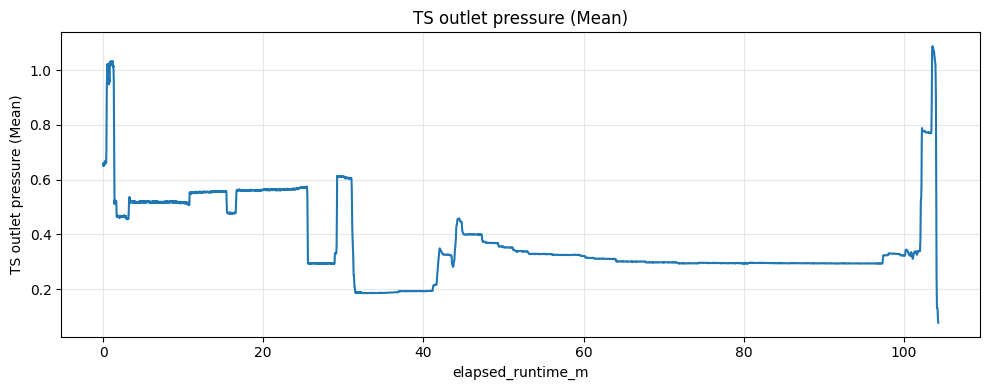

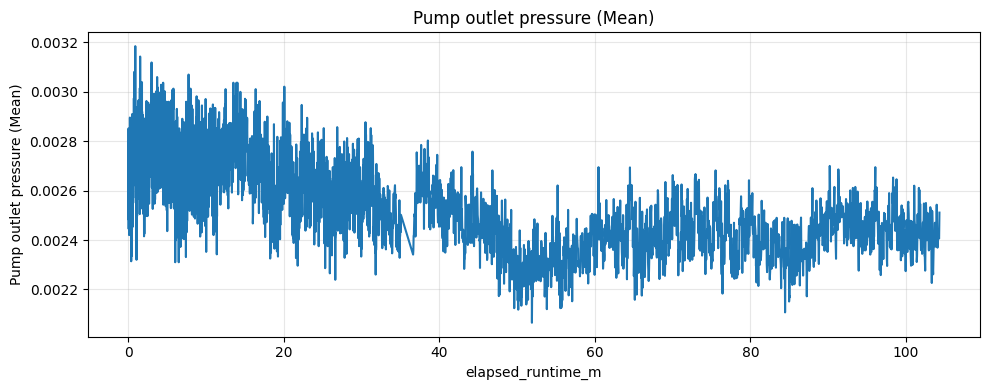

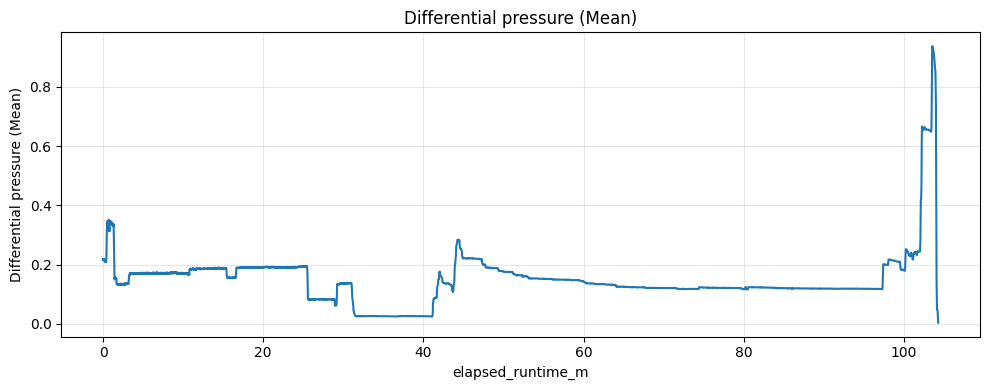

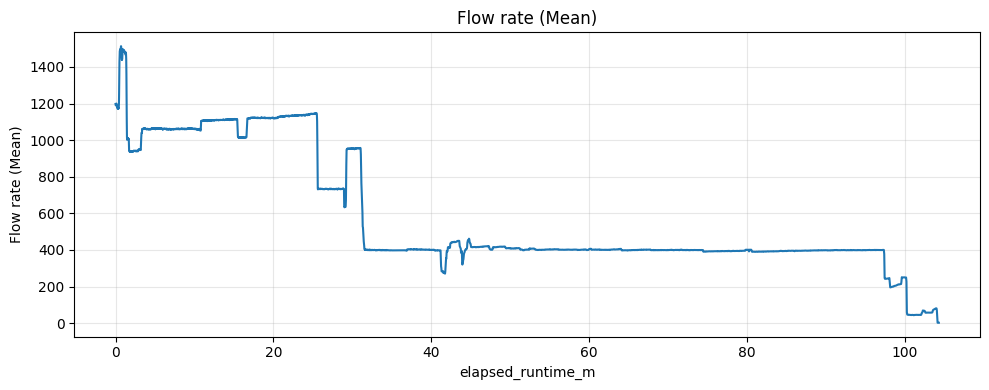

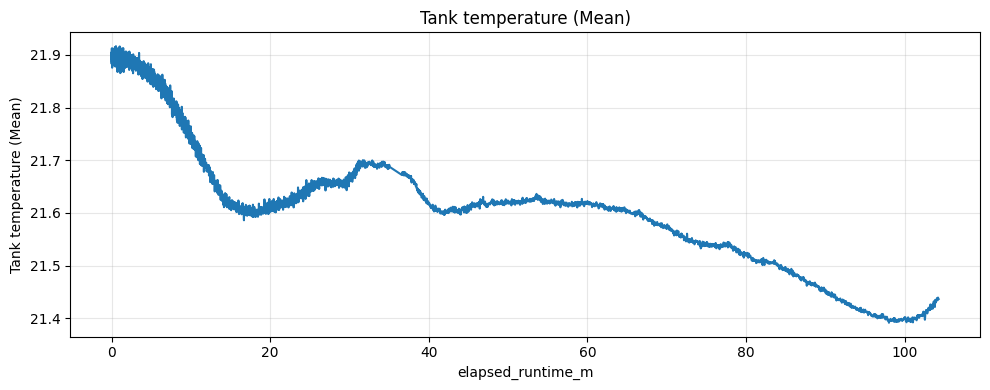

...

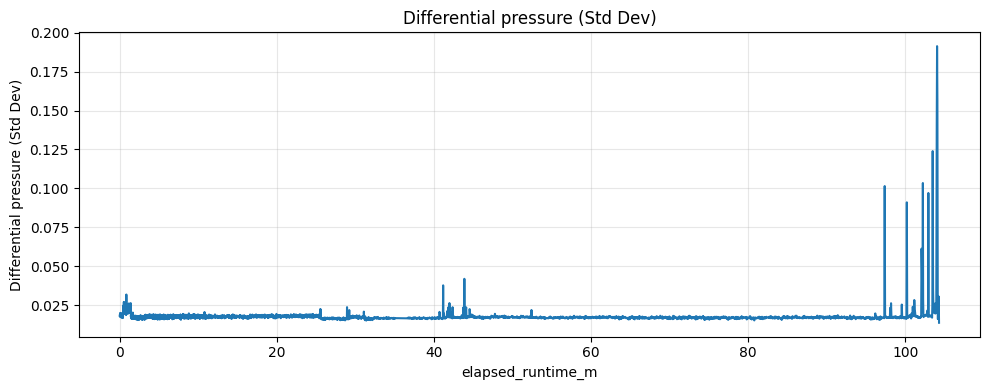

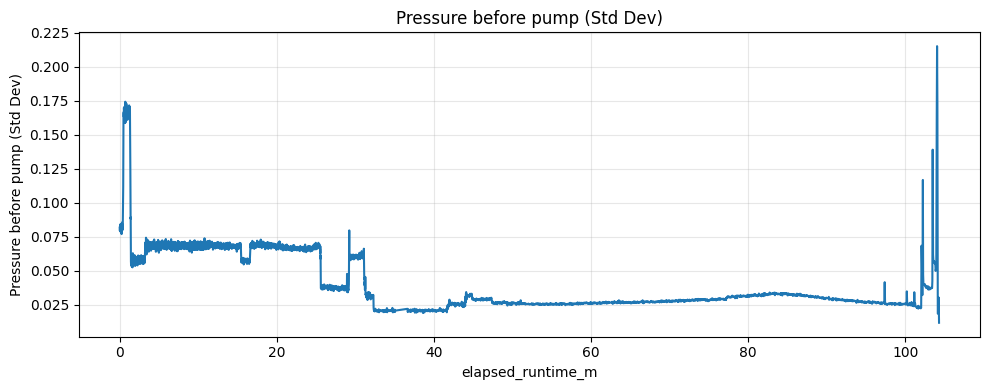

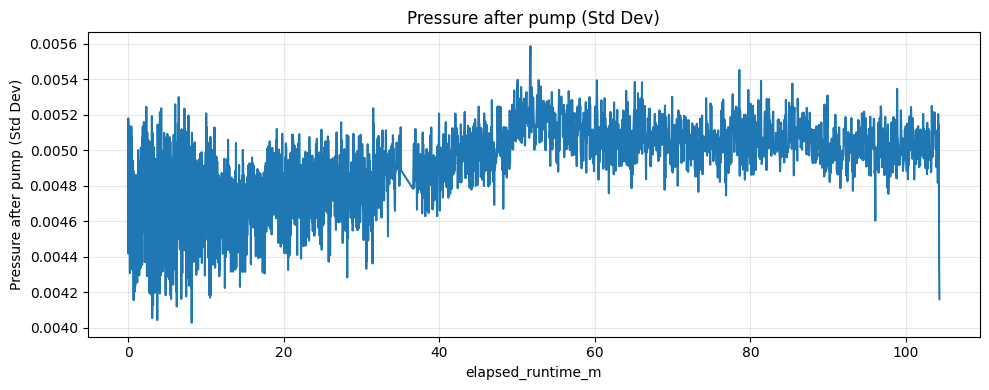

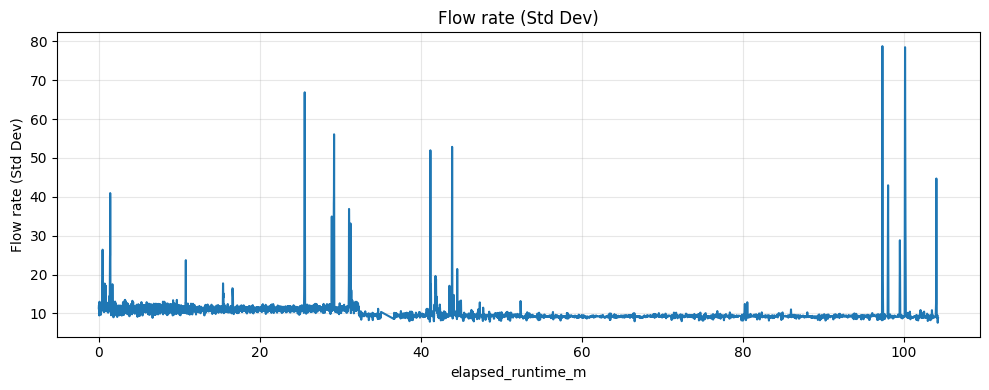

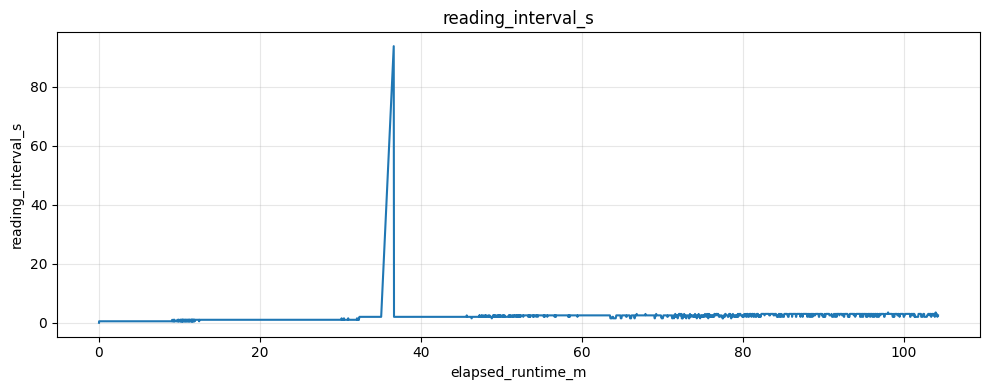

In [301]:
plot_all_timeseries(df)

### snipping

fjerner alle rader fra "oppstart" av rigg slik at vi sitter igjen med bare experimental run

In [302]:
i = 2542
df.loc[i-5:i+5]

,Time,TS outlet pressure (Mean),Pump outlet pressure (Mean),Differential pressure (Mean),Flow rate (Mean),Tank temperature (Mean),Temperature TS inlet (Mean),Temperature TS outlet (Mean),Bypass temperature (Mean),Temperature TS outlet (Std Dev),Temperature TS inlet (Std Dev),Bypass temperature (Std Dev),Tank temperature (Std Dev),Differential pressure (Std Dev),Pressure before pump (Std Dev),Pressure after pump (Std Dev),Flow rate (Std Dev),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
2537,2021-08-21 11:39:06.832,0.203883,0.002571,0.031016,445.883132,21.695803,-0.983046,-0.268506,0.308224,0.630702,0.678779,0.180337,0.206770,0.016158,0.031220,0.004757,11.694691,0.995,1886.382,31.439700
2538,2021-08-21 11:39:07.836,0.199282,0.002604,0.030158,439.632752,21.694169,-0.992809,-0.263113,0.306065,0.651267,0.726492,0.185927,0.220048,0.015986,0.030028,0.004673,12.185536,1.004,1887.386,31.456433
2539,2021-08-21 11:39:08.837,0.196465,0.002764,0.029286,431.361918,21.694885,-0.994032,-0.258125,0.310583,0.671484,0.732782,0.183672,0.209702,0.016290,0.032445,0.004760,12.269576,1.001,1888.387,31.473117
2540,2021-08-21 11:39:09.837,0.190531,0.002706,0.027297,424.592645,21.691537,-0.992954,-0.251030,0.304000,0.643367,0.658421,0.185777,0.227582,0.016123,0.032958,0.004720,13.064122,1.000,1889.387,31.489783
2541,2021-08-21 11:39:10.837,0.187292,0.002464,0.026572,413.437408,21.689306,-0.994398,-0.245123,0.303738,0.637092,0.688221,0.176484,0.212957,0.016516,0.031268,0.005237,13.307426,1.000,1890.387,31.506450
2542,2021-08-21 11:39:11.837,0.186945,0.002396,0.026379,405.408090,21.690619,-0.980354,-0.240923,0.305313,0.722699,0.552848,0.179705,0.206528,0.015739,0.030297,0.004755,11.640975,1.000,1891.387,31.523117
2543,2021-08-21 11:39:12.832,0.185340,0.002423,0.026547,402.819636,21.692109,-0.982519,-0.244496,0.314821,0.715137,0.518877,0.182244,0.215179,0.015906,0.028640,0.004995,11.555066,0.995,1892.382,31.539700
2544,2021-08-21 11:39:13.836,0.186993,0.002452,0.026726,402.167871,21.694823,-0.985357,-0.238795,0.314171,0.598412,0.571169,0.183068,0.213730,0.015431,0.030561,0.004856,11.001620,1.004,1893.386,31.556433
2545,2021-08-21 11:39:14.832,0.185901,0.002403,0.026351,403.197394,21.695341,-0.983085,-0.235423,0.311673,0.672586,0.704681,0.177128,0.217162,0.015854,0.030263,0.004954,11.823803,0.996,1894.382,31.573033
2546,2021-08-21 11:39:15.836,0.184817,0.002447,0.025976,401.594956,21.689724,-0.989148,-0.219185,0.307764,0.618520,0.667482,0.182108,0.212095,0.015608,0.030907,0.005149,11.001620,1.004,1895.386,31.589767


In [303]:
df.drop(columns=[
        'Temperature TS outlet (Std Dev)', 'Temperature TS inlet (Std Dev)', 'Bypass temperature (Std Dev)',
        'Tank temperature (Std Dev)', 'Differential pressure (Std Dev)', 'Pressure before pump (Std Dev)',
        'Pressure after pump (Std Dev)', 'Flow rate (Std Dev)'], inplace=True)

In [304]:
dffirst = snip_df_at_timecode(df, 2542, 3055)
dfsnd = snip_df_at_timecode(df, 3322, 0)

In [305]:
dffirst.to_csv('../data/split/partial_plug/2108-1.csv', index=False)
dfsnd.to_csv('../data/split/plug/2108-2.csv', index=False)

### plot after snip

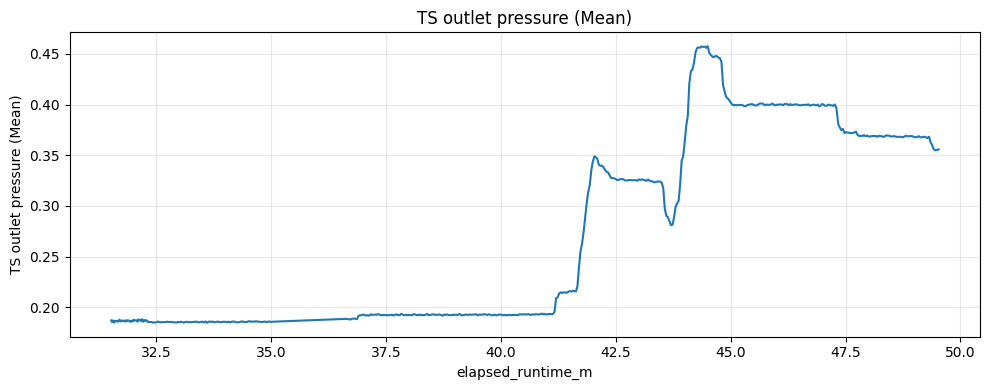

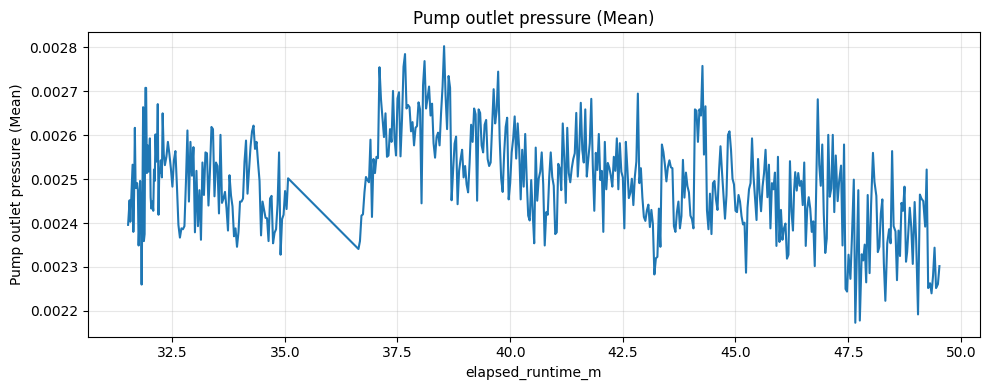

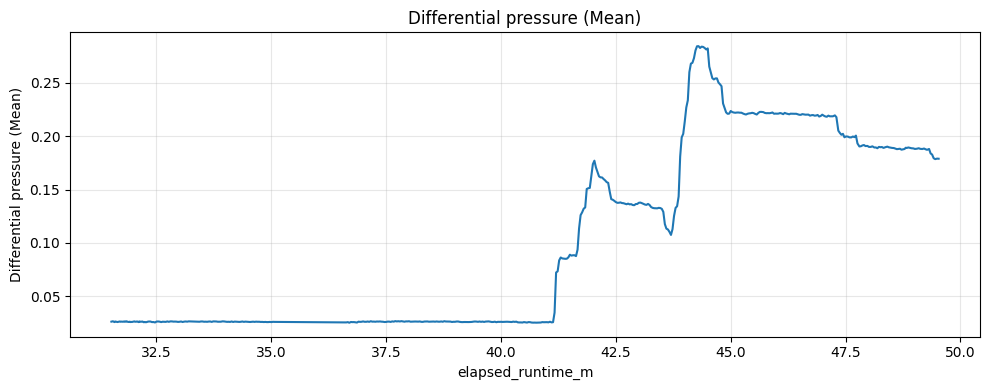

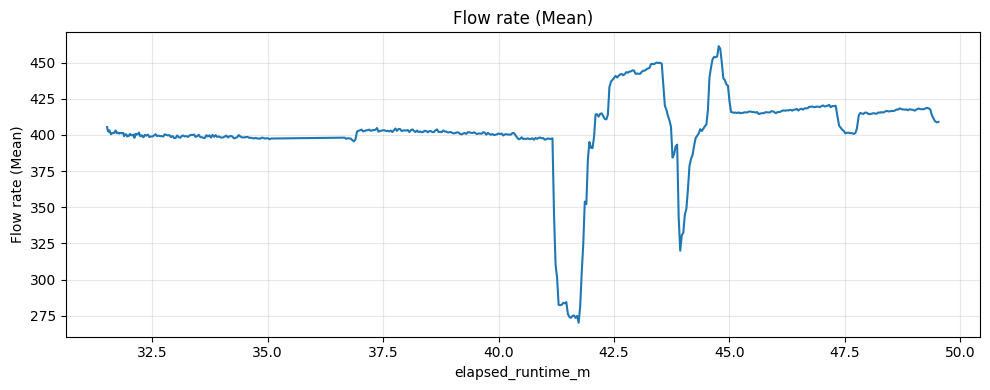

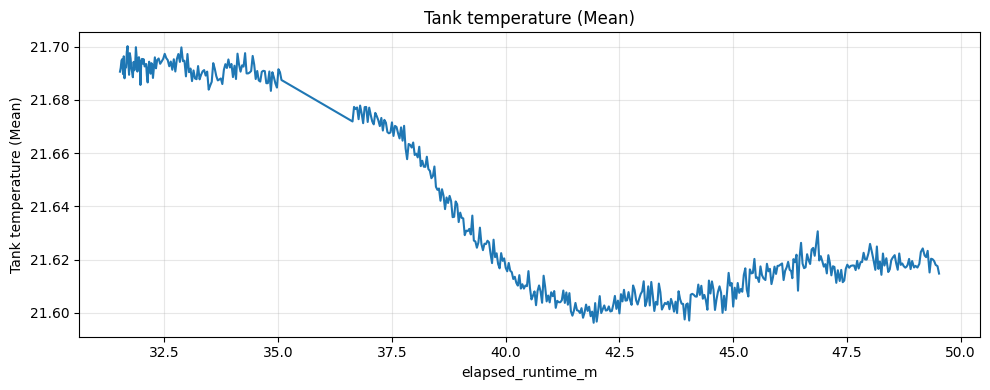

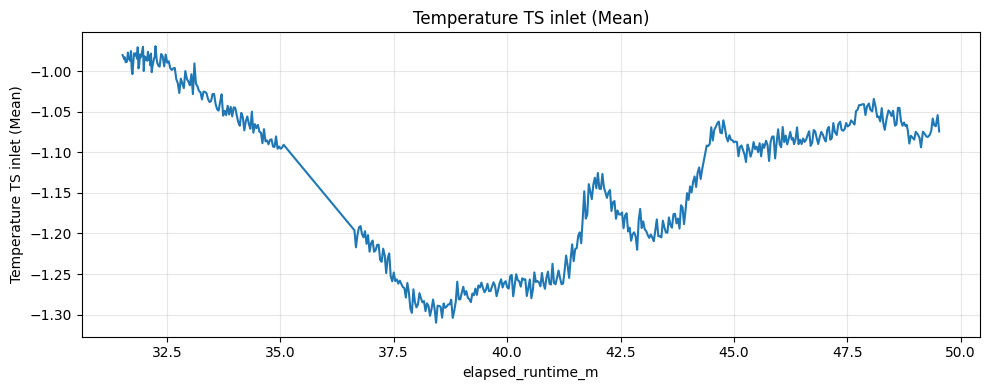

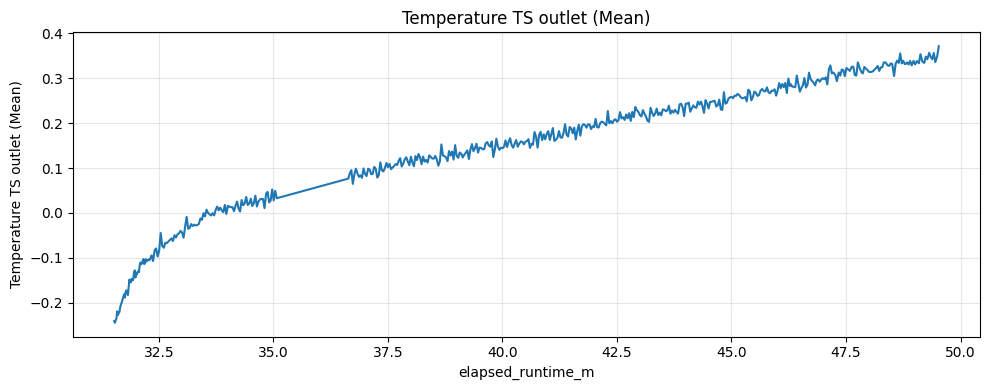

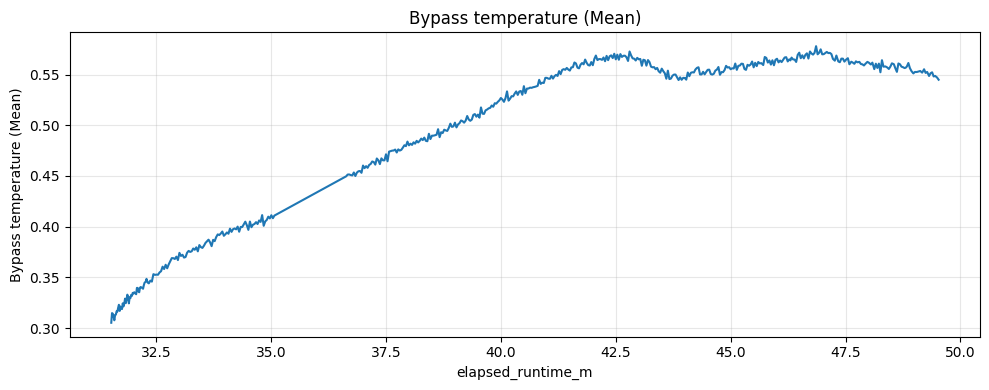

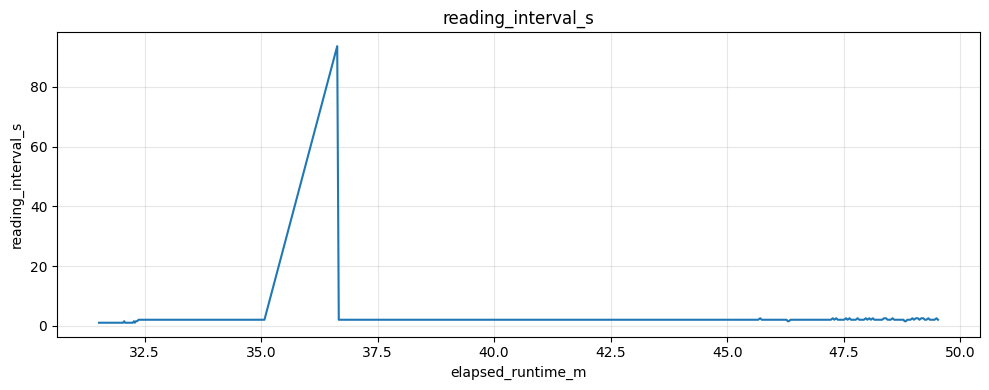

In [306]:
plot_all_timeseries(dffirst)

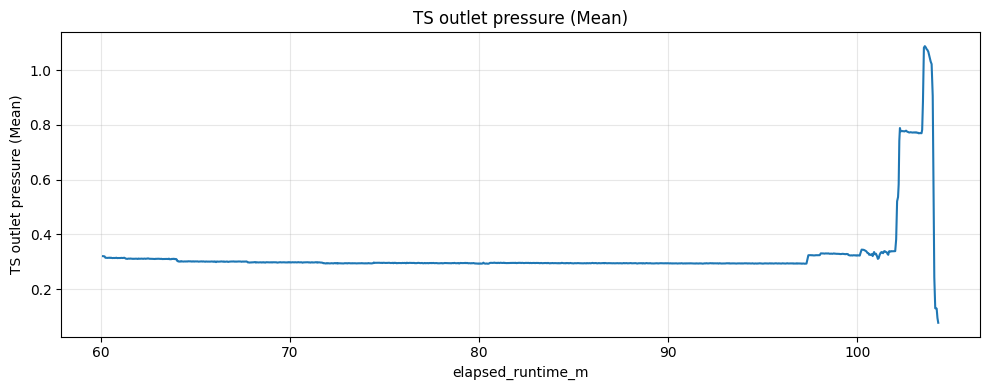

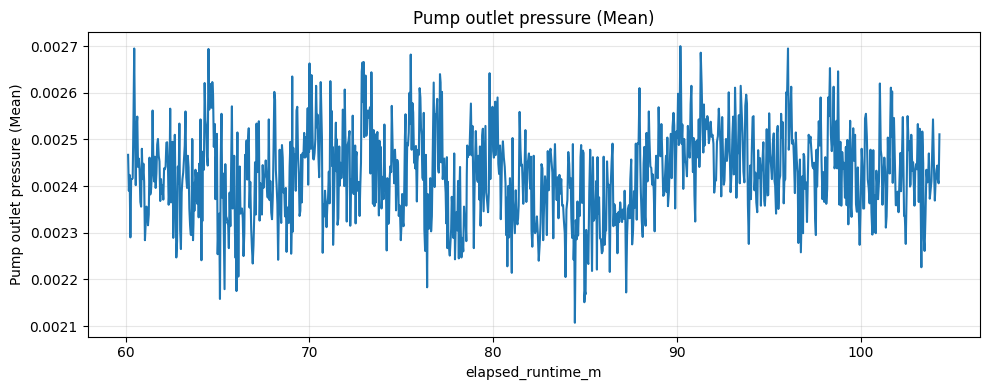

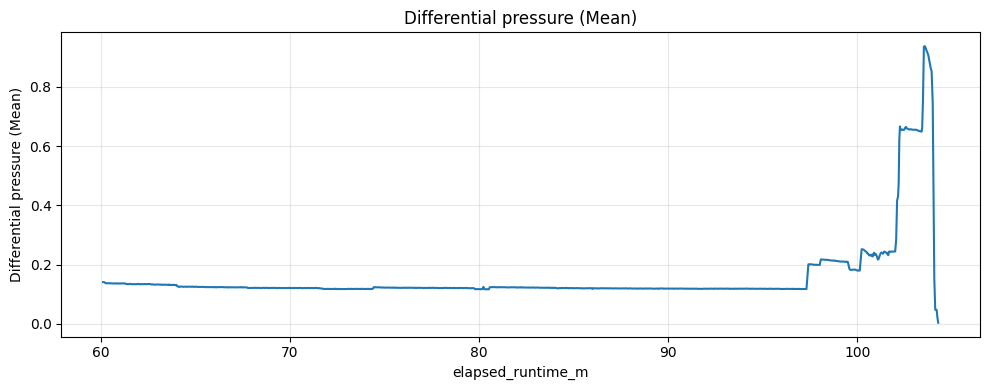

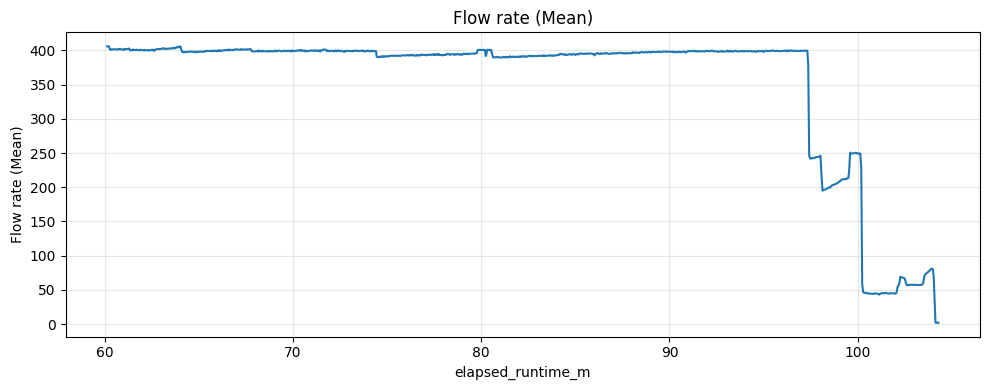

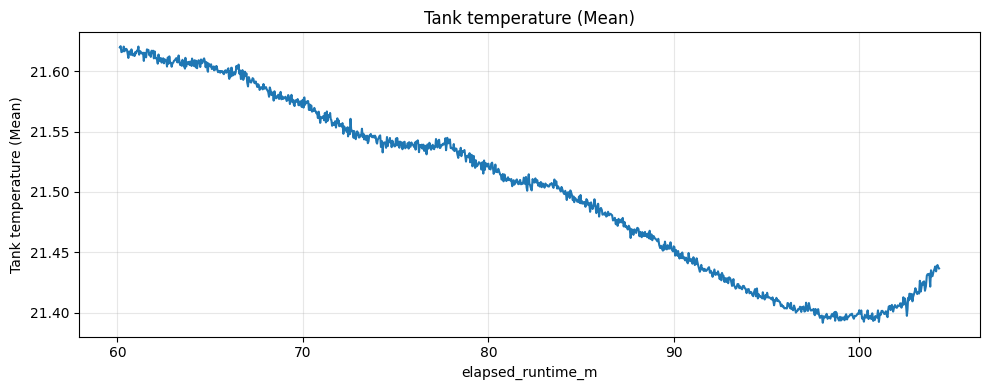

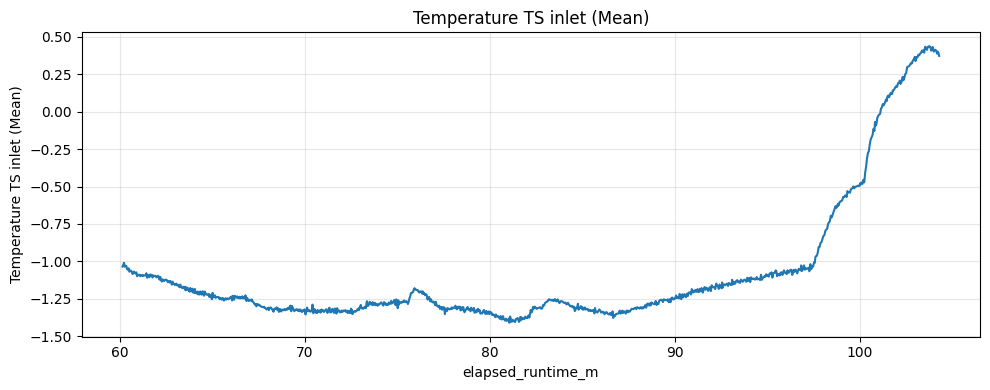

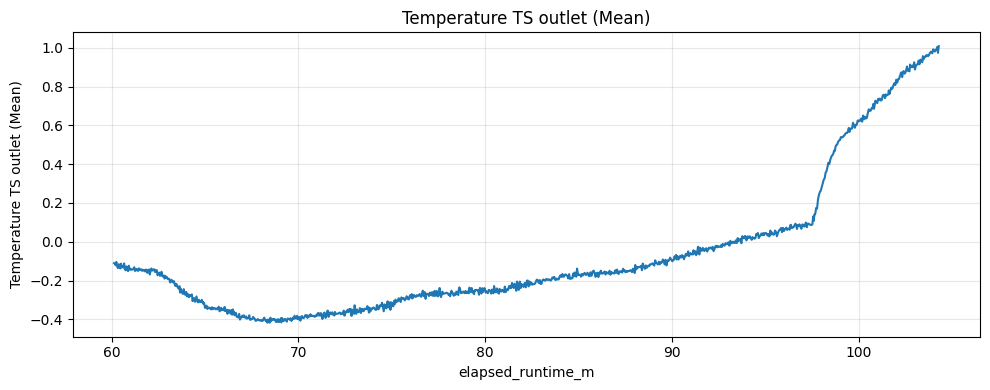

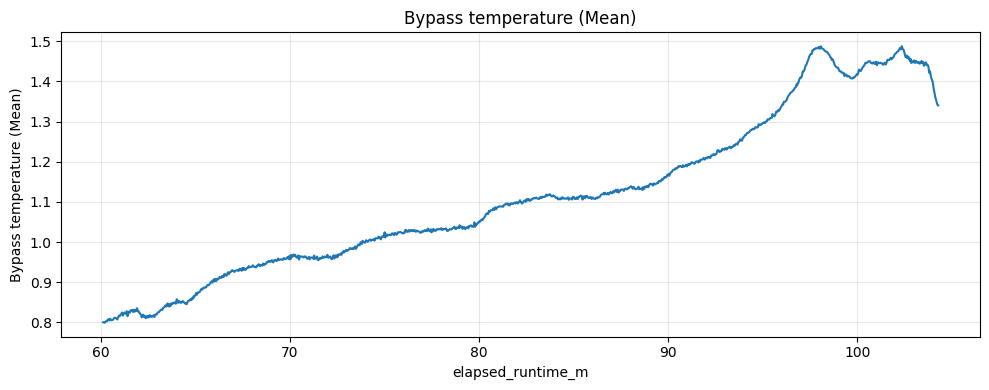

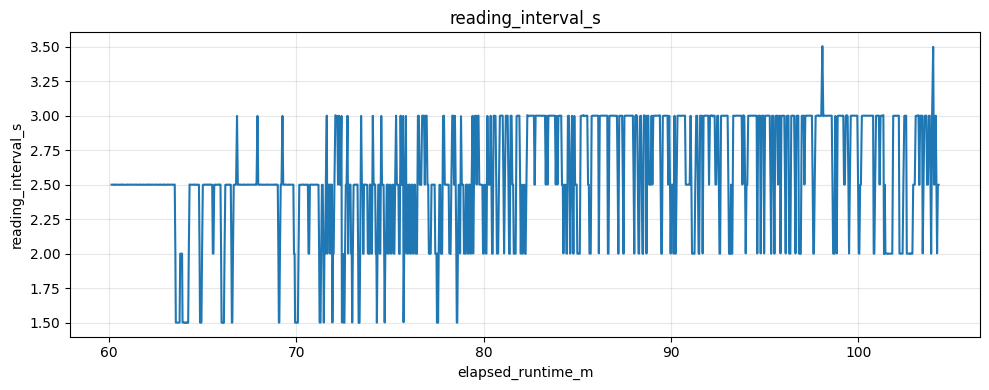

In [307]:
plot_all_timeseries(dfsnd)

## 01.09

### Init

In [308]:
df = df0109.copy()

In [309]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


In [310]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.00    1466
1.50    1268
0.50    1250
2.00    1201
2.50    1096
3.00     158
0.00       1
0.49       1
1.49       1
3.50       1
Name: count, dtype: int64

In [311]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6443 entries, 0 to 6442
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   Time                                 6443 non-null   datetime64[ns]
 1   Pressure before pump (Arith. Mean)   6443 non-null   float64       
 2   Pressure after pump (Arith. Mean)    6443 non-null   float64       
 3   Differential pressure (Arith. Mean)  6443 non-null   float64       
 4   Flow rate (Arith. Mean)              6443 non-null   float64       
 5   Tank temperature (Arith. Mean)       6443 non-null   float64       
 6   Temperature TS inlet (Arith. Mean)   6443 non-null   float64       
 7   Temperature TS outlet (Arith. Mean)  6443 non-null   float64       
 8   Bypass temperature (Arith. Mean)     6443 non-null   float64       
 9   Temperature TS outlet (Std Dev)      6443 non-null   float64       
 10  Temperature 

In [312]:
df = df.rename(columns=mapping)

### Plotting

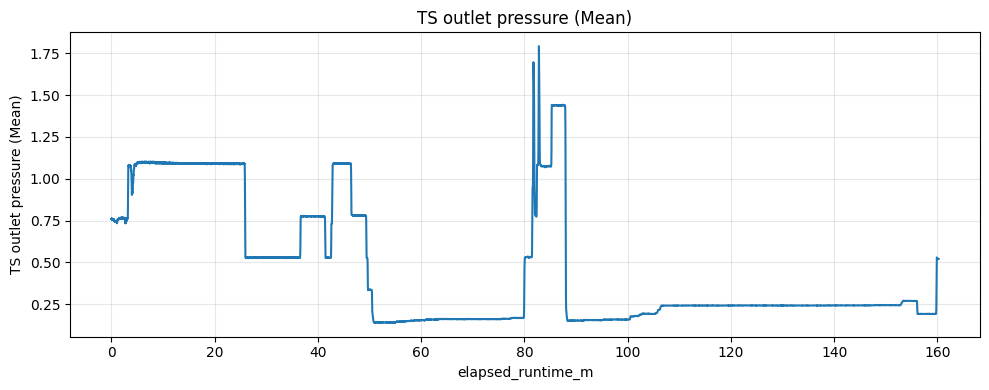

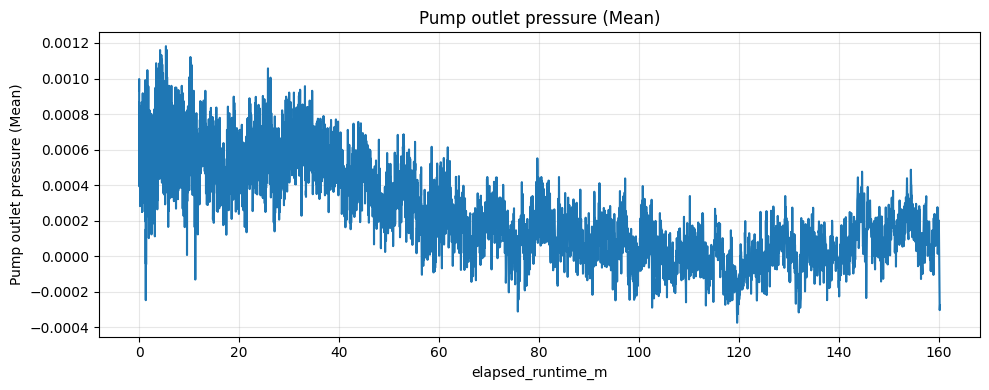

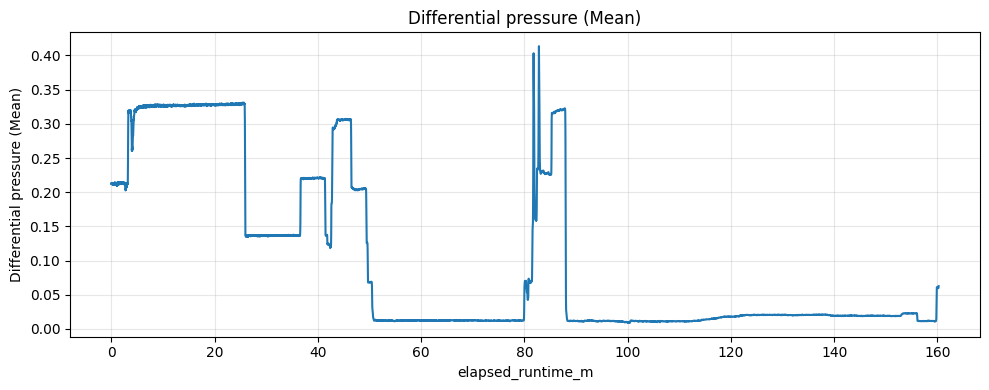

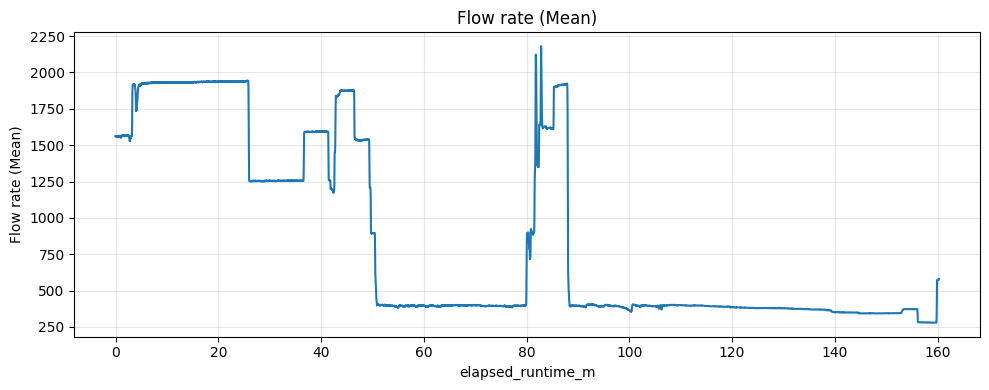

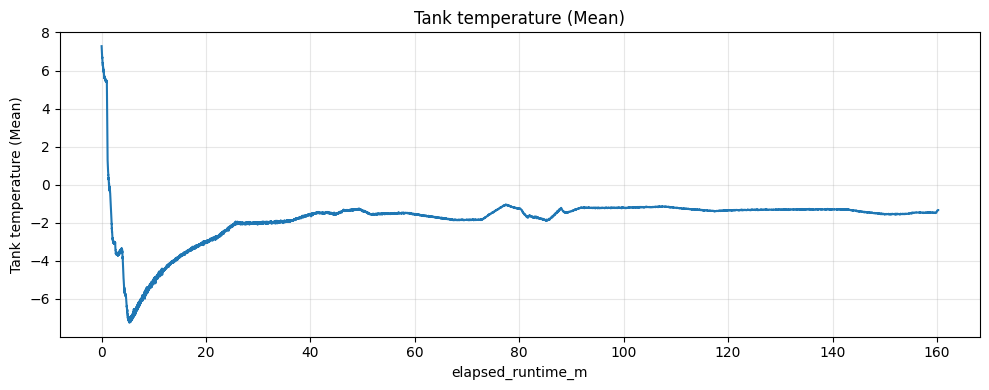

...

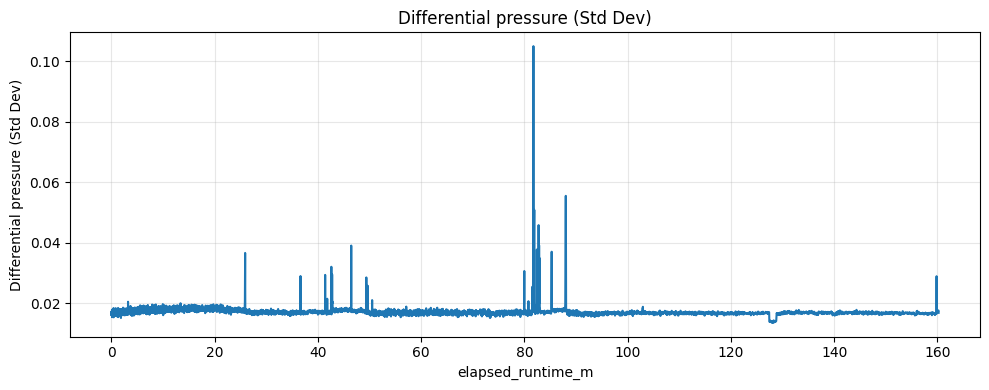

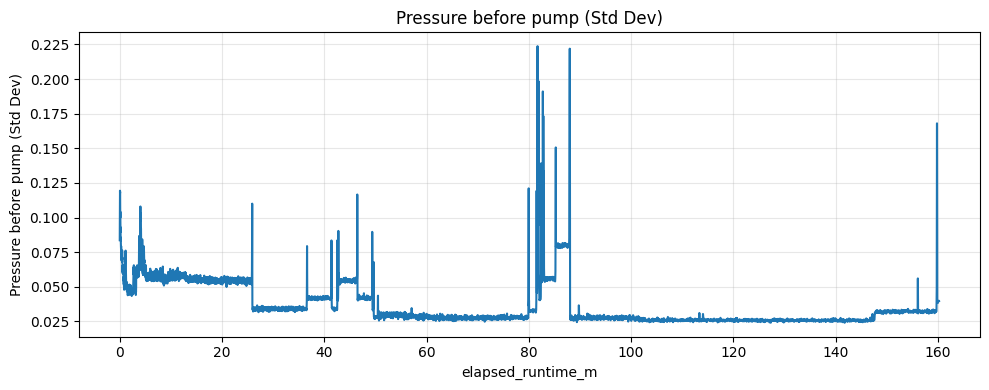

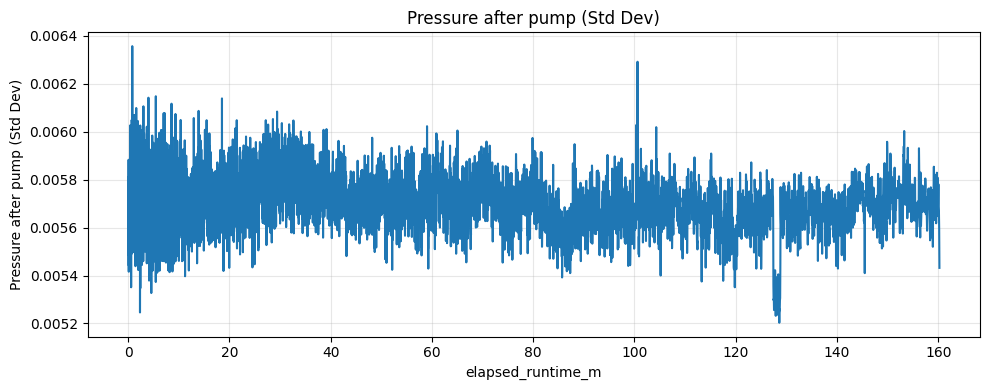

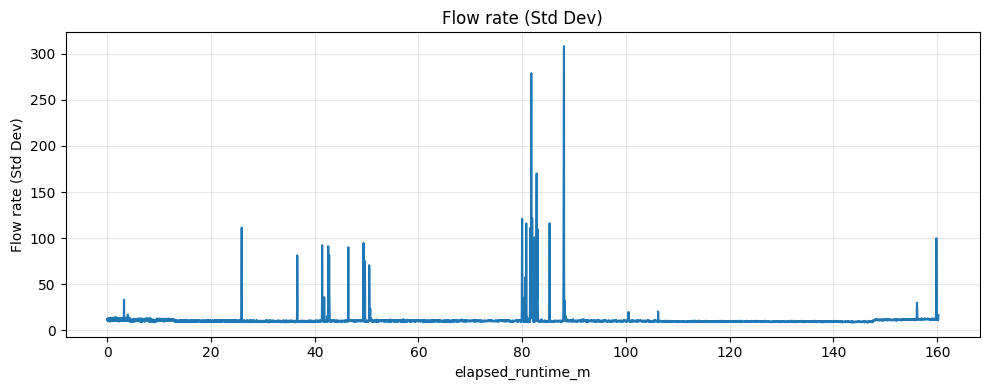

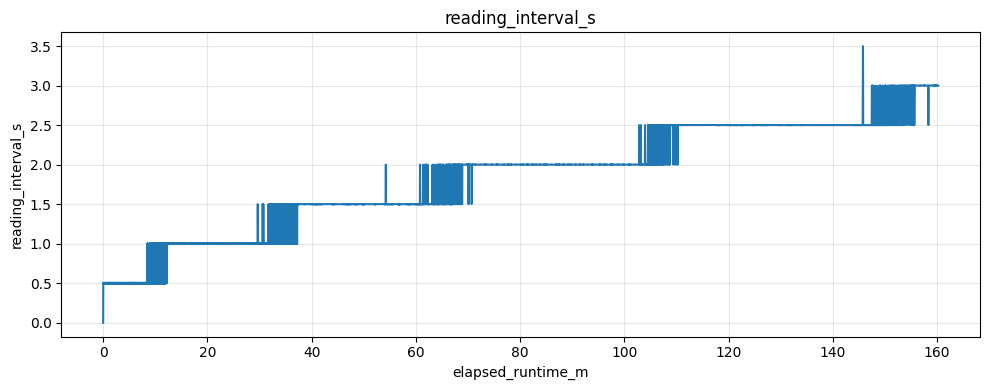

In [313]:
plot_all_timeseries(df)

samme her, target flow rate 400 kg/h
stabilisering ved samme datapunkt der 400 kg/h er nådd

restart av systemet mellom 80-90?
 
liten spike helt på slutten, "After the main test, the loop was purged, and a test was carried out, as a result of which a partial blockage of the hole was detected. However, the result cannot be taken into account due to the lower concentration of particles: as a result of the purge, it was not possible to get rid of the entire mass of the particle deposit."

### Snipping

description sier target flowrate 400 kg/h

men også at de purger loopen og har enda et run

In [314]:
df.drop(columns=[
        'Temperature TS outlet (Std Dev)', 'Temperature TS inlet (Std Dev)', 'Bypass temperature (Std Dev)',
        'Tank temperature (Std Dev)', 'Differential pressure (Std Dev)', 'Pressure before pump (Std Dev)',
        'Pressure after pump (Std Dev)', 'Flow rate (Std Dev)'], inplace=True)

In [315]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6443 entries, 0 to 6442
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Time                          6443 non-null   datetime64[ns]
 1   TS outlet pressure (Mean)     6443 non-null   float64       
 2   Pump outlet pressure (Mean)   6443 non-null   float64       
 3   Differential pressure (Mean)  6443 non-null   float64       
 4   Flow rate (Mean)              6443 non-null   float64       
 5   Tank temperature (Mean)       6443 non-null   float64       
 6   Temperature TS inlet (Mean)   6443 non-null   float64       
 7   Temperature TS outlet (Mean)  6443 non-null   float64       
 8   Bypass temperature (Mean)     6443 non-null   float64       
 9   reading_interval_s            6443 non-null   float64       
 10  elapsed_runtime_s             6443 non-null   float64       
 11  elapsed_runtime_m             

Finner først 1. run

In [316]:
i = 3358
df.loc[i-5:i+5]


,Time,TS outlet pressure (Mean),Pump outlet pressure (Mean),Differential pressure (Mean),Flow rate (Mean),Tank temperature (Mean),Temperature TS inlet (Mean),Temperature TS outlet (Mean),Bypass temperature (Mean),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
3353,2021-09-01 10:59:13.672,0.147956,0.000214,0.015424,447.188805,-1.465736,-1.165502,-0.759338,22.078733,1.501,3045.325,50.755417
3354,2021-09-01 10:59:15.171,0.146257,0.000143,0.014505,436.045688,-1.455662,-1.164029,-0.759560,22.078589,1.499,3046.824,50.780400
3355,2021-09-01 10:59:16.670,0.144128,0.000280,0.013966,426.461952,-1.486219,-1.156237,-0.752642,22.079815,1.499,3048.323,50.805383
3356,2021-09-01 10:59:18.171,0.141992,0.000057,0.013618,423.077633,-1.479902,-1.161042,-0.744472,22.075410,1.501,3049.824,50.830400
3357,2021-09-01 10:59:19.670,0.139203,0.000140,0.012648,411.971543,-1.487445,-1.158863,-0.742660,22.077013,1.499,3051.323,50.855383
3358,2021-09-01 10:59:21.171,0.138025,0.000270,0.012027,401.648971,-1.481301,-1.159118,-0.732404,22.072086,1.501,3052.824,50.880400
3359,2021-09-01 10:59:22.670,0.138058,0.000206,0.012667,397.179186,-1.475450,-1.139775,-0.723658,22.074648,1.499,3054.323,50.905383
3360,2021-09-01 10:59:24.169,0.139616,0.000178,0.013188,400.550950,-1.496726,-1.138374,-0.711486,22.079202,1.499,3055.822,50.930367
3361,2021-09-01 10:59:25.670,0.139463,0.000284,0.013233,403.609025,-1.502549,-1.136470,-0.701184,22.079958,1.501,3057.323,50.955383
3362,2021-09-01 10:59:27.169,0.139763,0.000413,0.013059,403.325107,-1.457588,-1.133120,-0.689945,22.076837,1.499,3058.822,50.980367


In [317]:
i = 4386
df.loc[i-5:i+5]

,Time,TS outlet pressure (Mean),Pump outlet pressure (Mean),Differential pressure (Mean),Flow rate (Mean),Tank temperature (Mean),Temperature TS inlet (Mean),Temperature TS outlet (Mean),Bypass temperature (Mean),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
4381,2021-09-01 11:28:13.069,0.166816,0.000260,0.012086,396.605262,-1.257576,-0.233910,0.192863,22.311022,1.999,4784.722,79.745367
4382,2021-09-01 11:28:15.069,0.167214,0.000075,0.012249,397.800747,-1.245476,-0.228726,0.190665,22.306005,2.000,4786.722,79.778700
4383,2021-09-01 11:28:17.069,0.166681,0.000159,0.012455,398.338235,-1.243966,-0.224001,0.197490,22.307974,2.000,4788.722,79.812033
4384,2021-09-01 11:28:19.069,0.167143,0.000209,0.012428,397.166605,-1.264048,-0.226232,0.197359,22.305873,2.000,4790.722,79.845367
4385,2021-09-01 11:28:21.069,0.167429,0.000304,0.012451,397.998769,-1.252957,-0.228070,0.199656,22.309812,2.000,4792.722,79.878700
4386,2021-09-01 11:28:23.069,0.179014,0.000443,0.014513,406.447705,-1.267723,-0.228660,0.204644,22.311059,2.000,4794.722,79.912033
4387,2021-09-01 11:28:25.069,0.234353,0.000288,0.024495,461.226705,-1.259060,-0.228332,0.198409,22.308236,2.000,4796.722,79.945367
4388,2021-09-01 11:28:27.069,0.369800,0.000393,0.051111,625.259601,-1.259519,-0.228267,0.201166,22.316047,2.000,4798.722,79.978700
4389,2021-09-01 11:28:29.067,0.466113,0.000196,0.061893,827.960387,-1.262659,-0.222611,0.206954,22.317162,1.998,4800.720,80.012000
4390,2021-09-01 11:28:31.067,0.504582,0.000377,0.066008,857.070224,-1.263982,-0.252943,0.200247,22.315850,2.000,4802.720,80.045333


In [318]:
dffirst = snip_df_at_timecode(df, 3358, 4386)

Finner 2. run

In [319]:
i = 4640
df.loc[i-5:i+5]

,Time,TS outlet pressure (Mean),Pump outlet pressure (Mean),Differential pressure (Mean),Flow rate (Mean),Tank temperature (Mean),Temperature TS inlet (Mean),Temperature TS outlet (Mean),Bypass temperature (Mean),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
4635,2021-09-01 11:36:41.040,0.172558,0.000194,0.016143,491.281432,-1.335647,-1.100635,-0.992651,22.469945,2.002,5292.693,88.211550
4636,2021-09-01 11:36:43.040,0.164056,0.000159,0.014559,453.539210,-1.345881,-1.095398,-0.998957,22.468587,2.000,5294.693,88.244883
4637,2021-09-01 11:36:45.040,0.160575,0.000375,0.013549,438.649846,-1.360450,-1.088310,-0.995807,22.465371,2.000,5296.693,88.278217
4638,2021-09-01 11:36:47.038,0.154928,0.000159,0.012453,424.952825,-1.369406,-1.095406,-0.995225,22.467686,1.998,5298.691,88.311517
4639,2021-09-01 11:36:49.038,0.148596,-0.000043,0.011798,409.472255,-1.375937,-1.090607,-0.987210,22.467208,2.000,5300.691,88.344850
4640,2021-09-01 11:36:51.040,0.149107,0.000176,0.011765,394.239279,-1.393011,-1.087654,-0.990356,22.471059,2.002,5302.693,88.378217
4641,2021-09-01 11:36:53.040,0.148856,0.000183,0.011904,397.843180,-1.389325,-1.075907,-0.981631,22.468718,2.000,5304.693,88.411550
4642,2021-09-01 11:36:55.038,0.148773,0.000209,0.011800,392.189863,-1.407572,-1.088442,-0.981297,22.467095,1.998,5306.691,88.444850
4643,2021-09-01 11:36:57.038,0.149478,0.000120,0.011757,393.658788,-1.407831,-1.079188,-0.976643,22.469899,2.000,5308.691,88.478183
4644,2021-09-01 11:36:59.038,0.149058,0.000012,0.011674,392.972783,-1.441693,-1.081485,-0.972902,22.471475,2.000,5310.691,88.511517


In [320]:
dfsnd = snip_df_at_timecode(df, 4640, 6434)

men fra description får vi vite at vi ikke kan ta dette run i betraktning så jeg lagrer det ikke enda

In [321]:
dffirst.to_csv('../data/split/no_plug/0109-1.csv', index=False)
#dfsnd.to_csv('../data/split/no_plug/0109-2.csv', index=False)

### Plot after snip

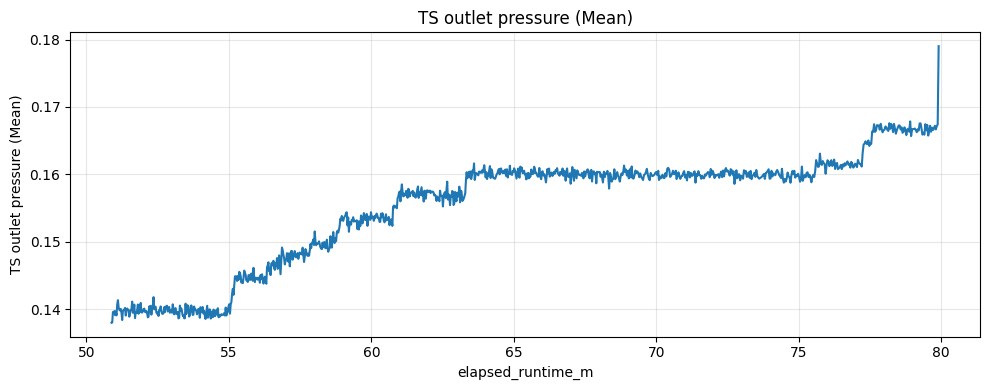

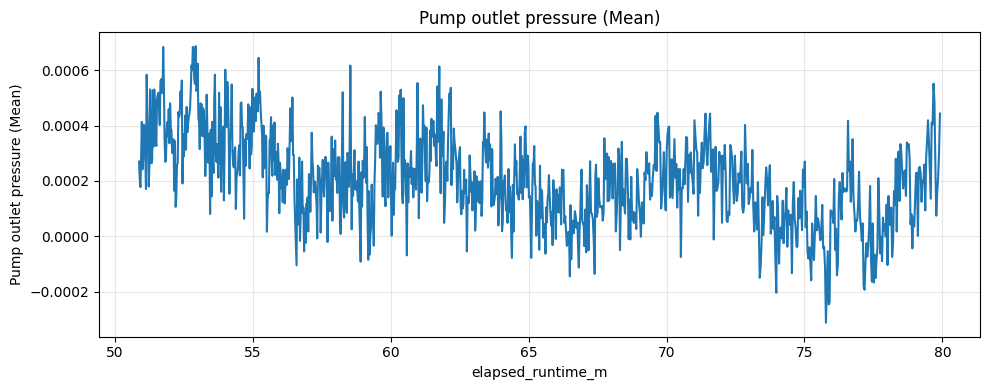

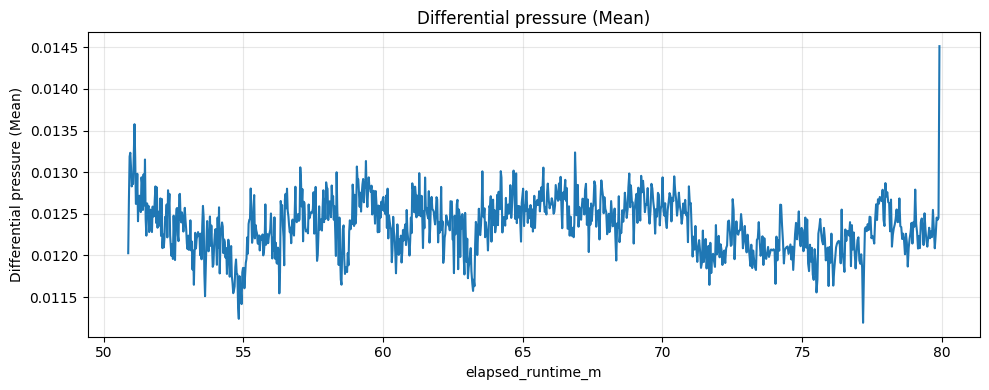

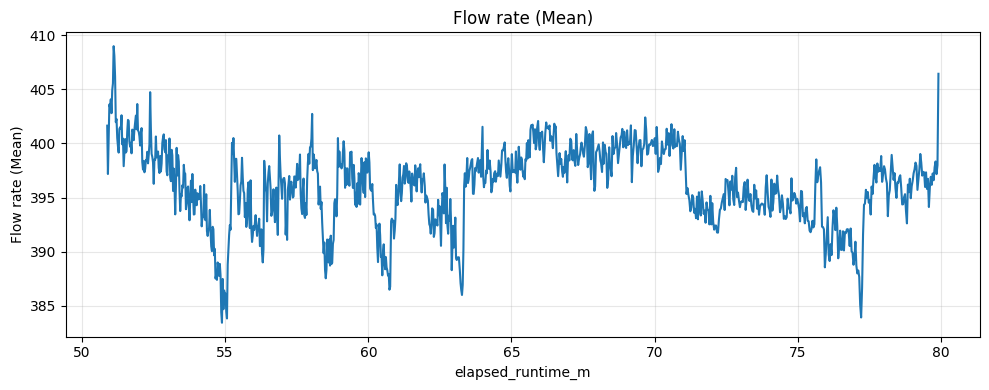

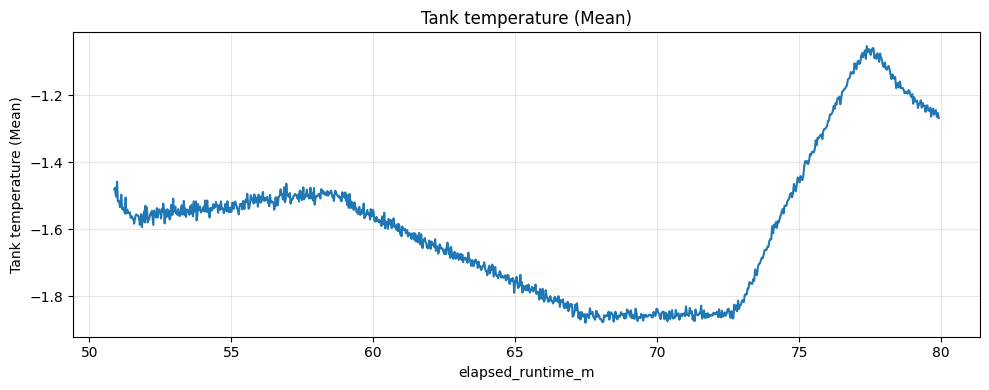

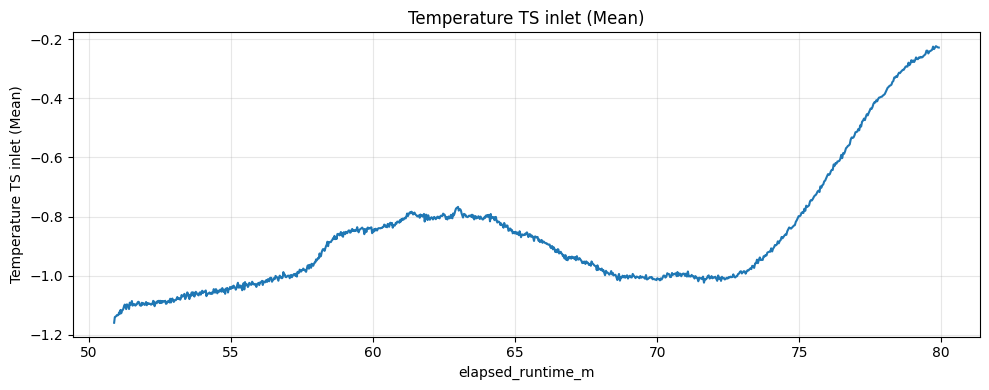

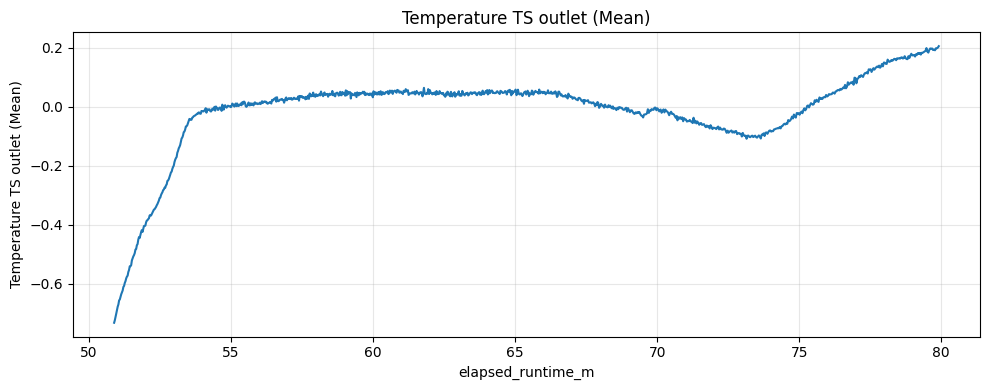

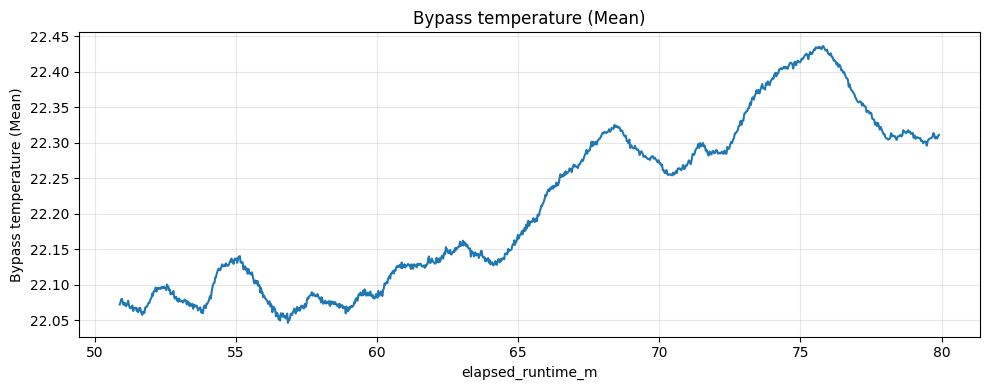

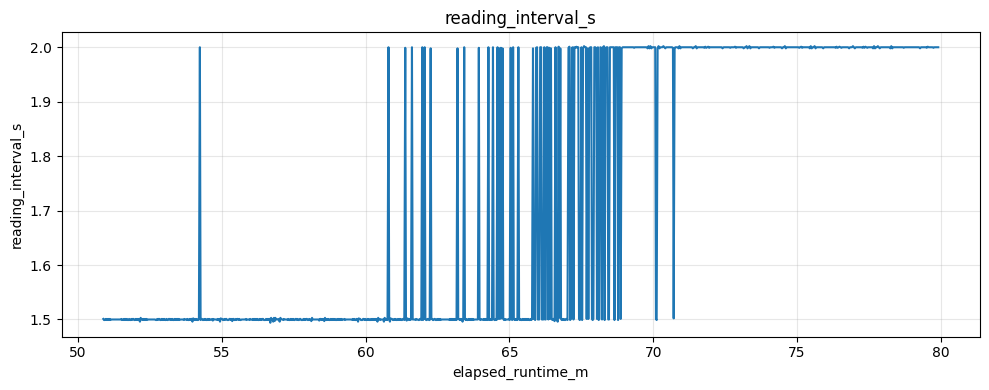

In [322]:
plot_all_timeseries(dffirst)

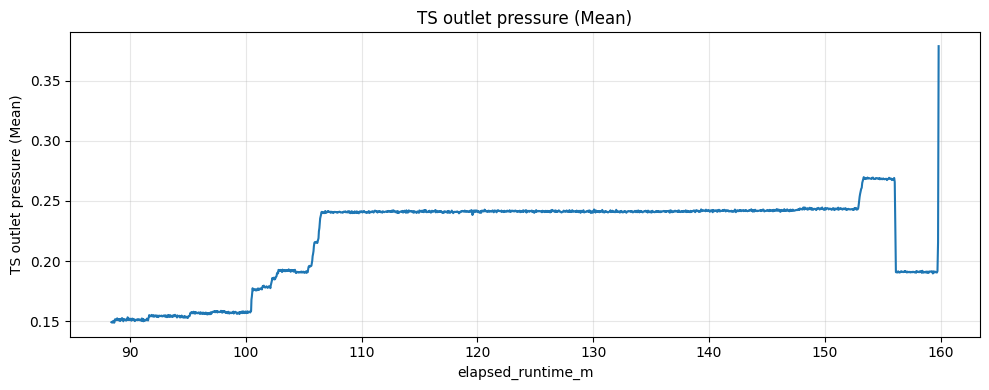

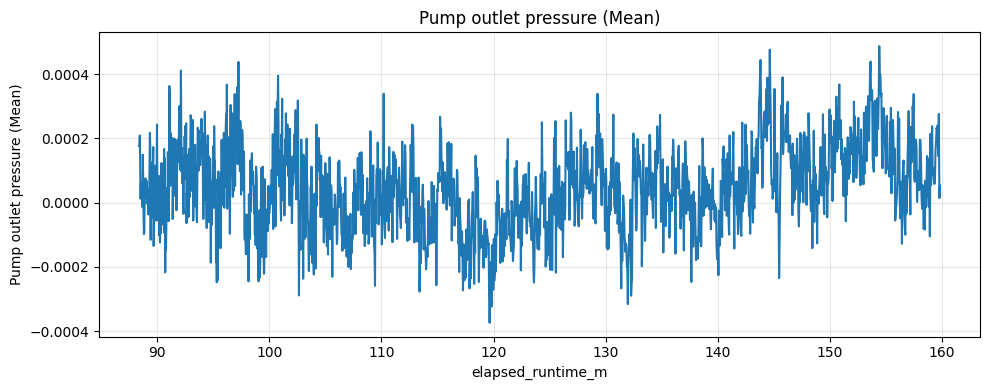

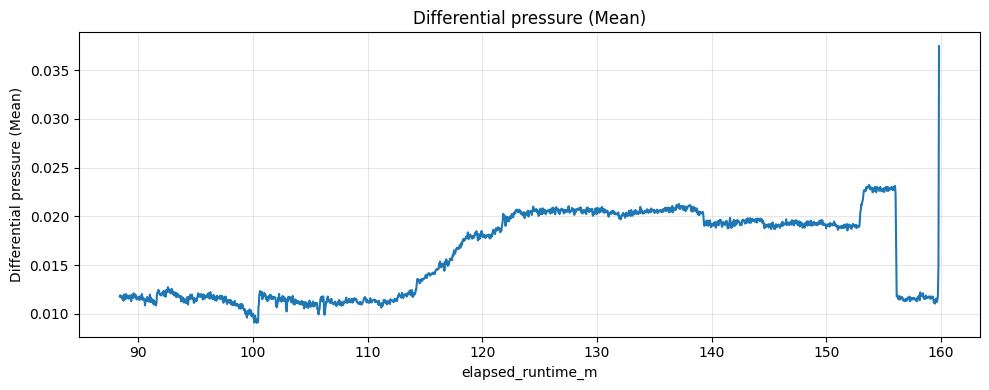

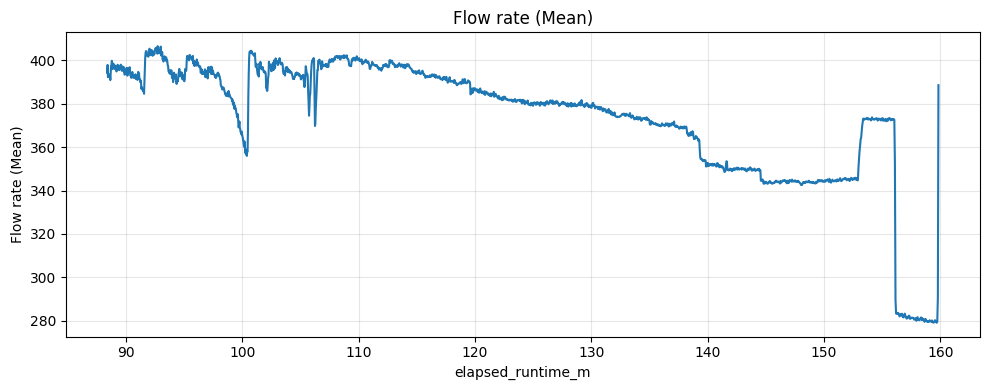

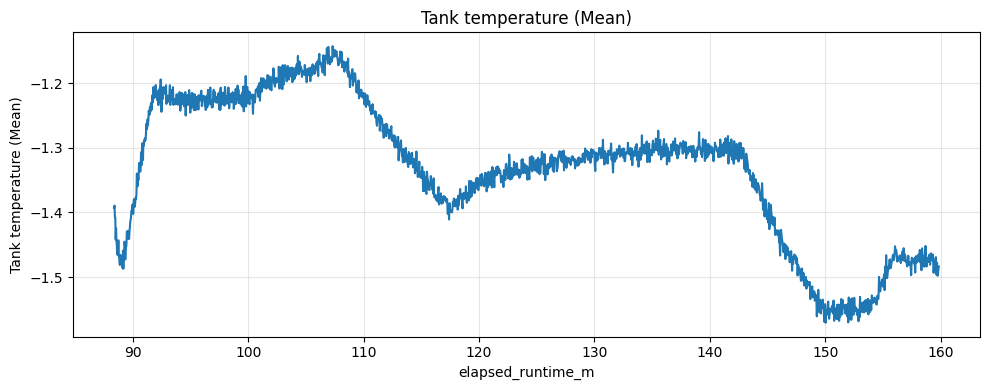

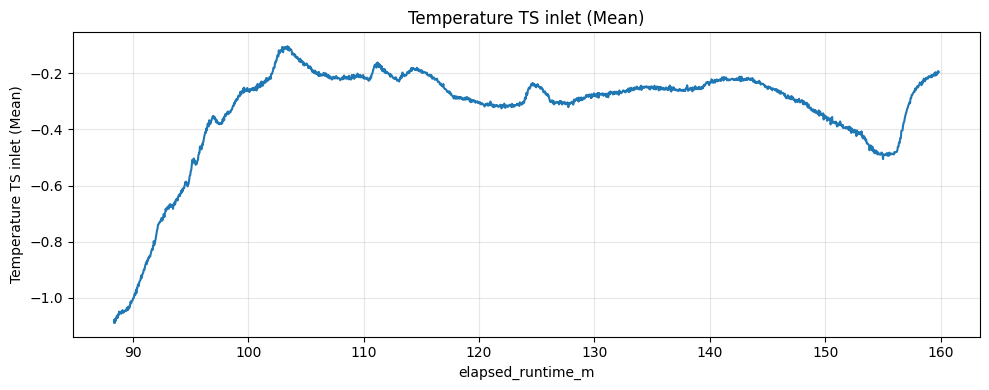

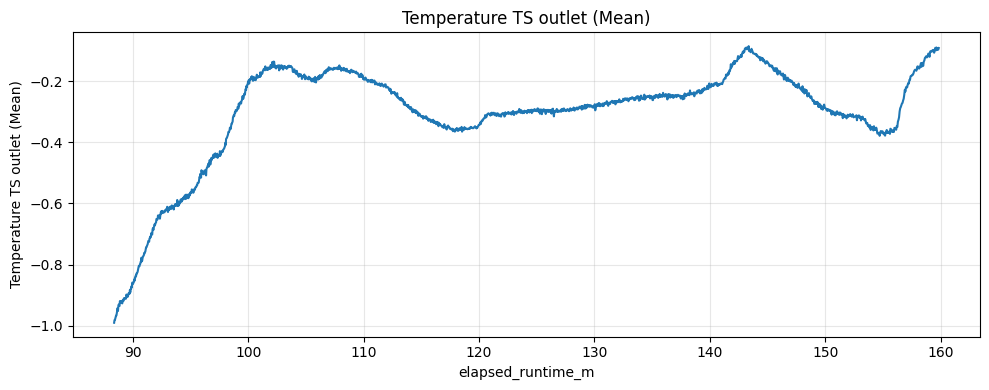

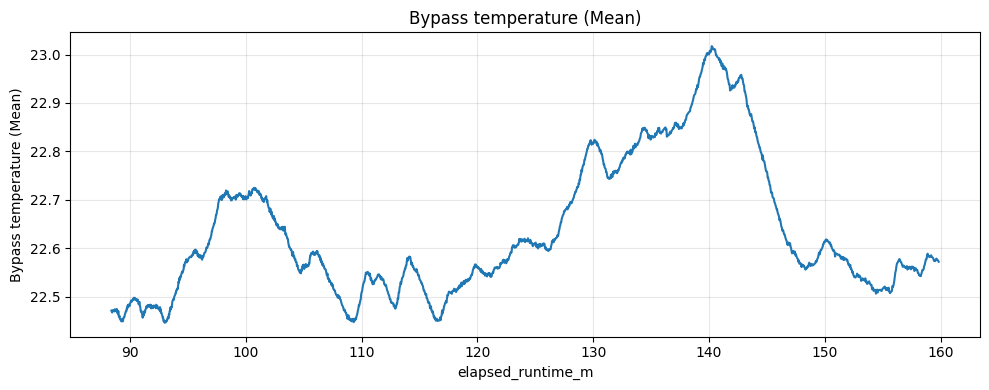

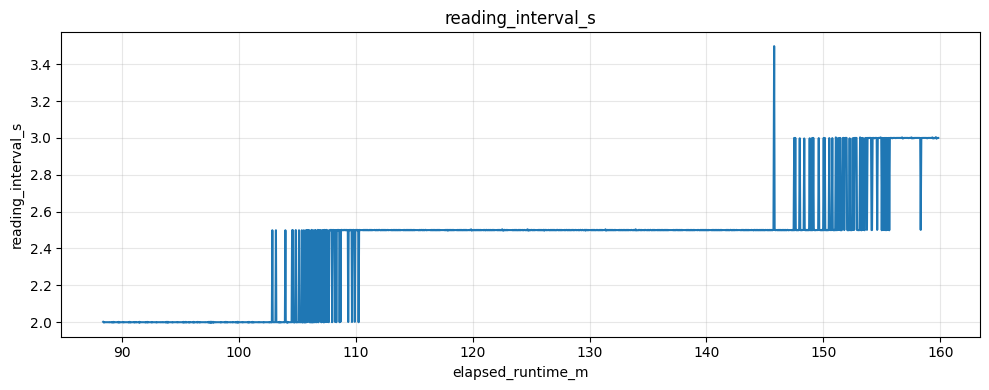

In [323]:
plot_all_timeseries(dfsnd)

## 23.09 ikke bruk

Differential pressure test, lar stå for nå

In [324]:
df = df2309

In [325]:
df.head()

,Time,Pressure before pump (Arith. Mean),Pressure after pump (Arith. Mean),Differential pressure (Arith. Mean),Flow rate (Arith. Mean),Tank temperature (Arith. Mean),Temperature TS inlet (Arith. Mean),Temperature TS outlet (Arith. Mean),Bypass temperature (Arith. Mean),Temperature TS outlet (Std Dev),Temperature TS inlet (Std Dev),Bypass temperature (Std Dev),Tank temperature (Std Dev),Differential pressure (Std Dev),Pressure before pump (Std Dev),Pressure after pump (Std Dev),Flow rate (Std Dev)
0,2021-09-23 11:44:15.469,-0.000953,0.000388,-0.002267,0.751986,22.254471,23.476945,22.523866,23.597269,0.204264,0.149411,0.118877,0.198649,0.013532,0.004897,0.005212,3.493279
1,2021-09-23 11:44:15.973,-0.000864,0.000299,-0.002195,0.701742,22.275812,23.469334,22.524412,23.596239,0.177941,0.149632,0.125484,0.187145,0.013116,0.005382,0.005186,3.441039
2,2021-09-23 11:44:16.474,-0.000679,0.000365,-0.002517,0.576880,22.277582,23.477137,22.522801,23.594067,0.177954,0.144385,0.118495,0.207919,0.012904,0.005223,0.005290,3.247005
3,2021-09-23 11:44:16.970,-0.000762,0.000494,-0.002137,0.809020,22.254735,23.465830,22.521484,23.593299,0.201474,0.144347,0.118798,0.196353,0.014150,0.005094,0.005319,2.960882
4,2021-09-23 11:44:17.469,-0.000832,0.000511,-0.002550,0.612487,22.248877,23.471958,22.525223,23.593919,0.214081,0.154330,0.122937,0.168015,0.014046,0.004871,0.005322,3.166494


In [326]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2035 entries, 0 to 2034
Data columns (total 17 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   Time                                 2035 non-null   datetime64[ns]
 1   Pressure before pump (Arith. Mean)   2035 non-null   float64       
 2   Pressure after pump (Arith. Mean)    2035 non-null   float64       
 3   Differential pressure (Arith. Mean)  2035 non-null   float64       
 4   Flow rate (Arith. Mean)              2035 non-null   float64       
 5   Tank temperature (Arith. Mean)       2035 non-null   float64       
 6   Temperature TS inlet (Arith. Mean)   2035 non-null   float64       
 7   Temperature TS outlet (Arith. Mean)  2035 non-null   float64       
 8   Bypass temperature (Arith. Mean)     2035 non-null   float64       
 9   Temperature TS outlet (Std Dev)      2035 non-null   float64       
 10  Temperature 

In [327]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


In [328]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    1058
0.5     886
1.5      90
0.0       1
Name: count, dtype: int64

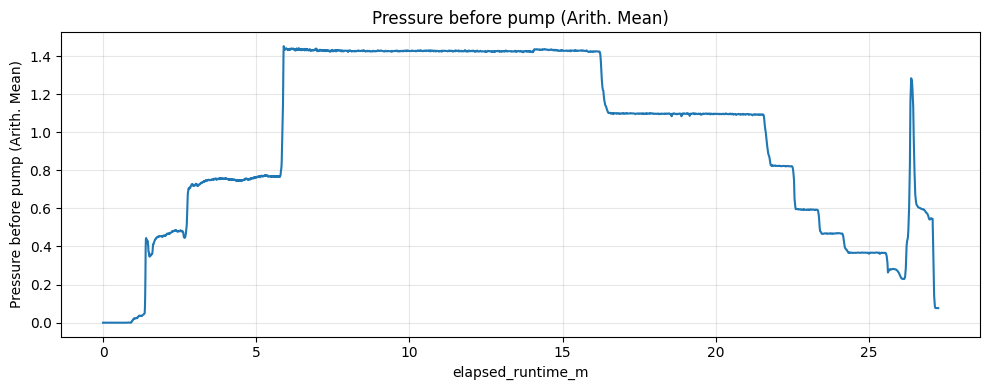

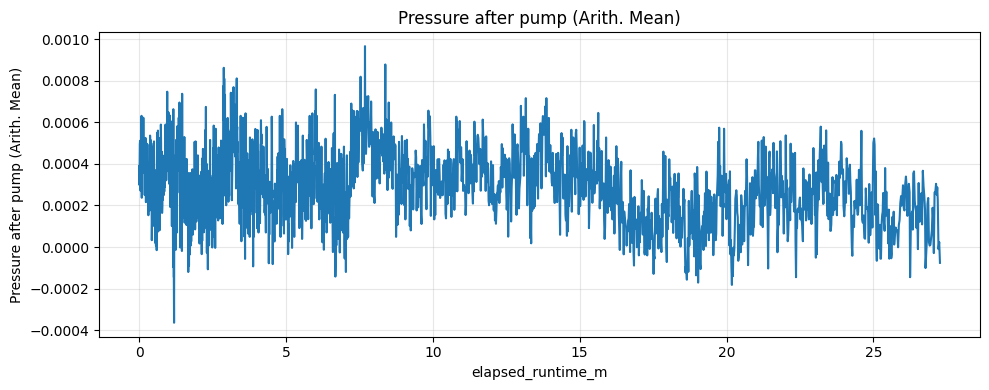

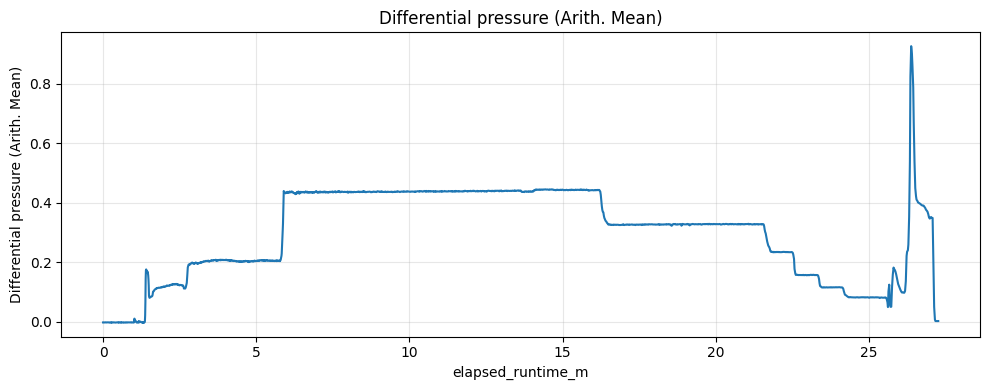

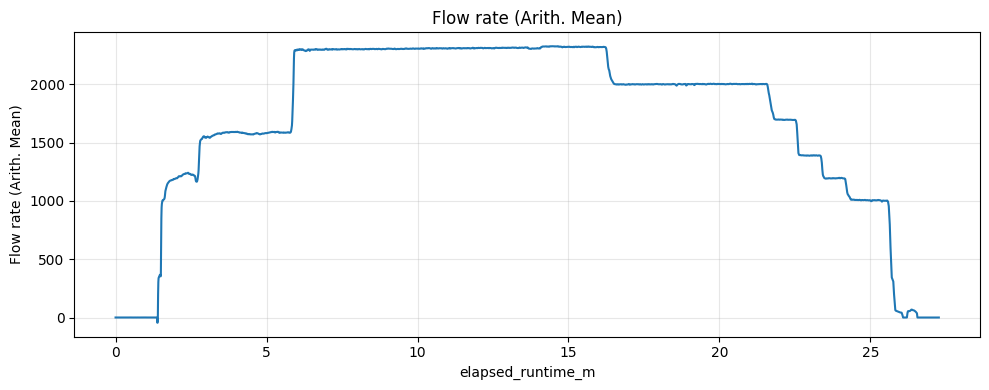

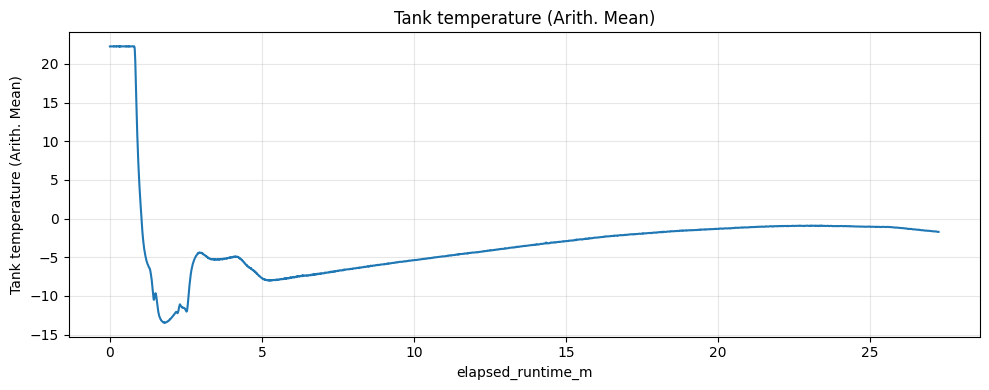

...

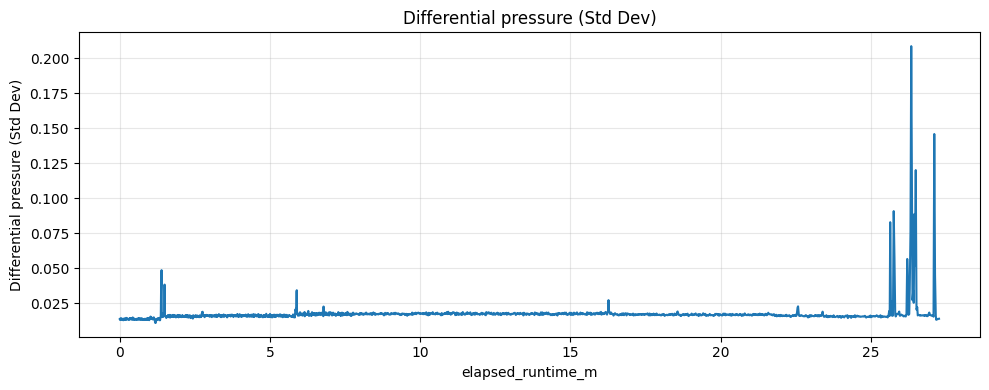

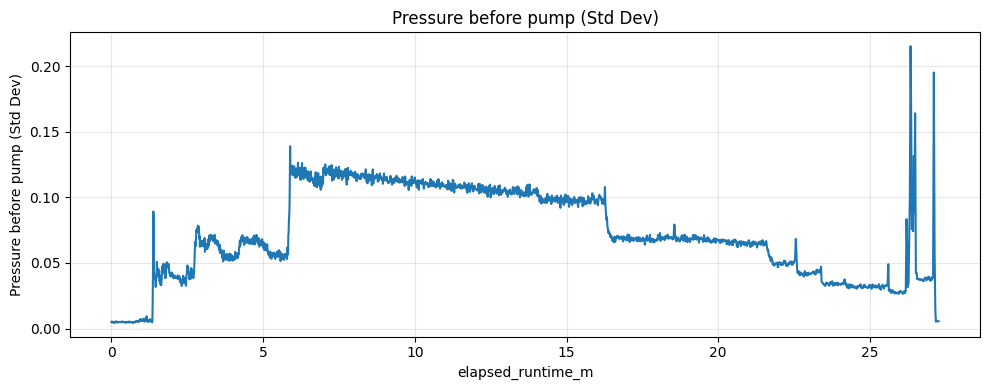

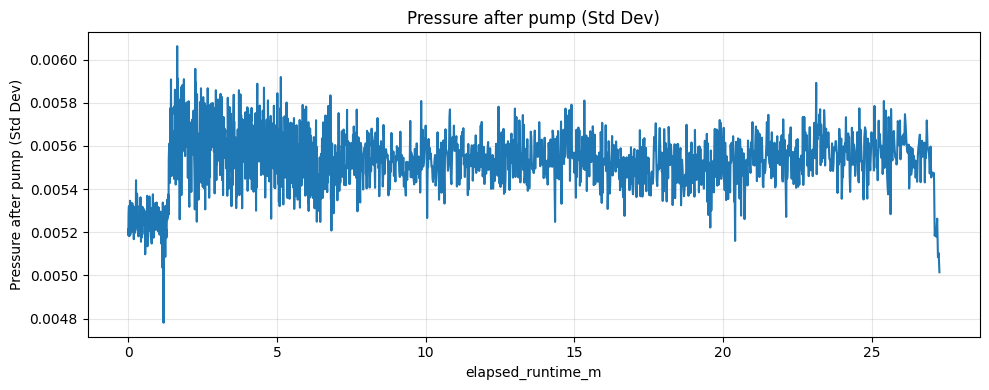

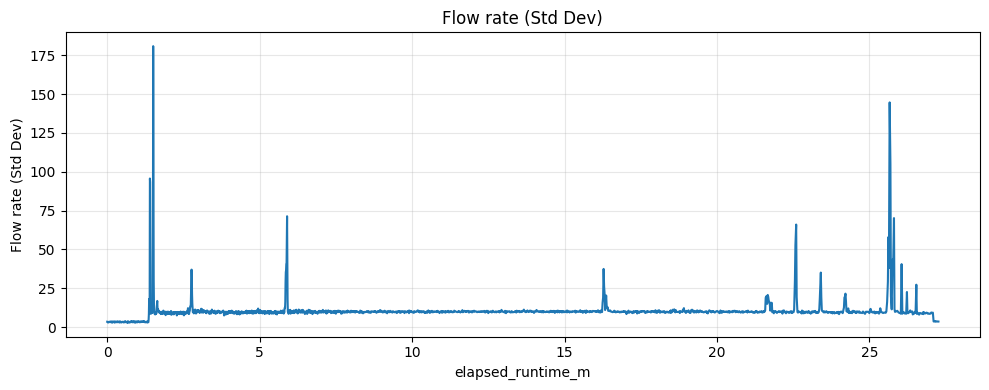

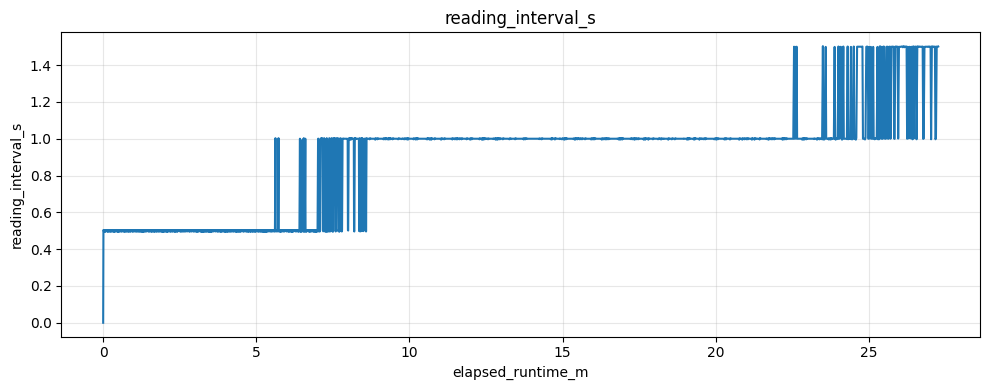

In [329]:
plot_all_timeseries(df)

samme som tidligere men med 6 min?
manuelt satt ned flow rate?

## 18.03

### Init

In [36]:
df = df1803.copy()

In [37]:
rename_map = {
    "Unnamed: 10": "dp TS in - TS out (Mean)",
    "Unnamed: 11": "dp pump out - TS in (Mean)",
    "Unnamed: 12": "dT tank - TS in (Mean)",
}

df = df.rename(columns=rename_map)


In [18]:
basic_checklist(df)

Missing values:
Time                                0
Unnamed: 1                          0
Temperature TS outlet (Mean)        0
Temperature TS inlet (Mean)         0
Bypass temperature (Mean)           0
Tank temperature (Mean)             0
TS outlet pressure (Mean)           0
TS inlet pressure (Mean)            0
Pump outlet pressure (Mean)         0
Flow rate (Mean)                    0
dp TS in - TS out (Mean)            0
dp pump out - TS in (Mean)          0
dT tank - TS in (Mean)          14598
dtype: int64

Time column is monotonic increasing.


In [38]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    23186
0.0        1
Name: count, dtype: int64

### Plotting

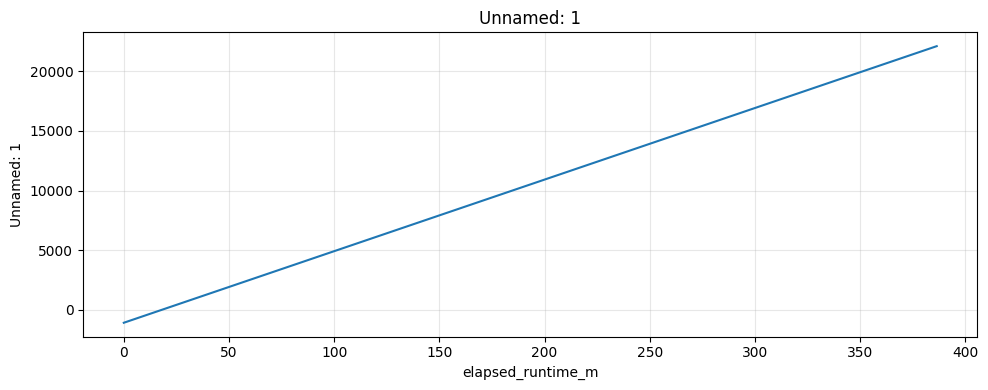

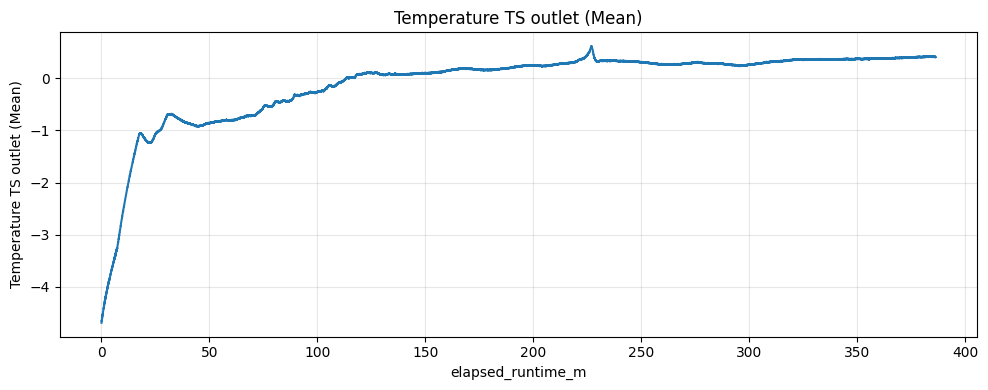

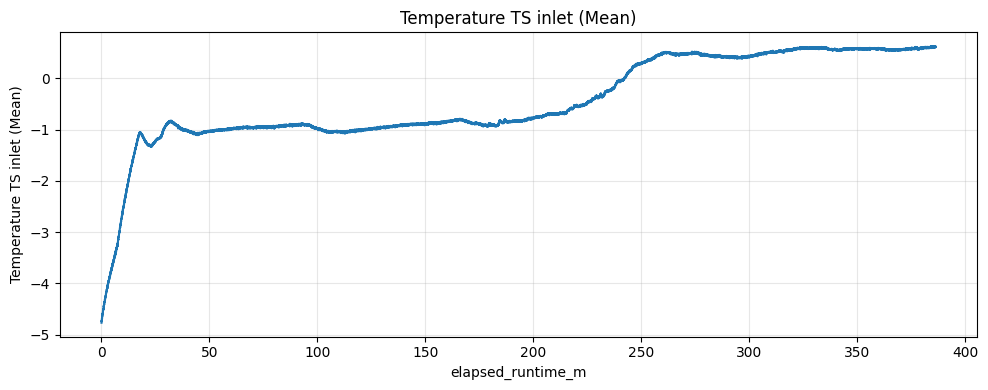

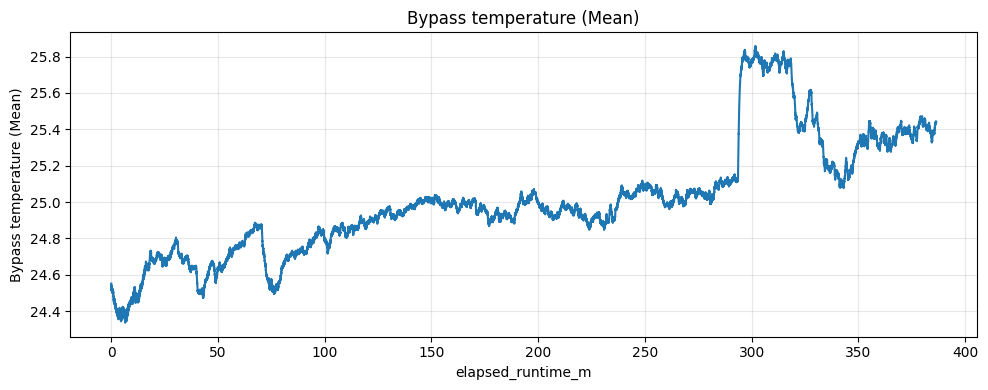

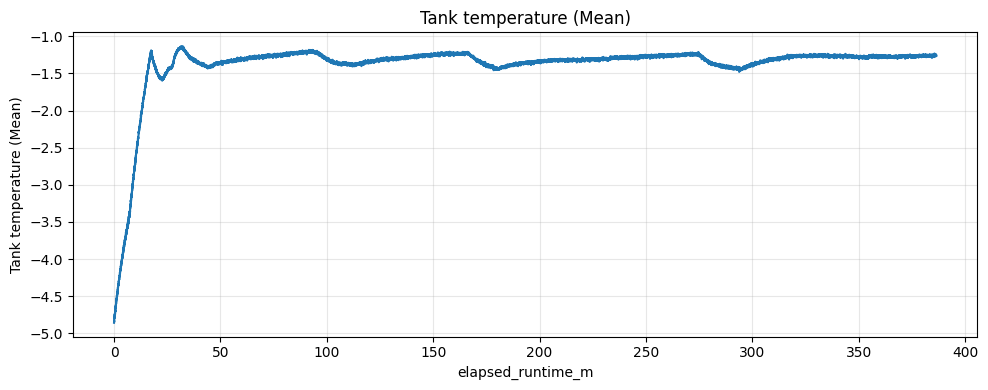

...

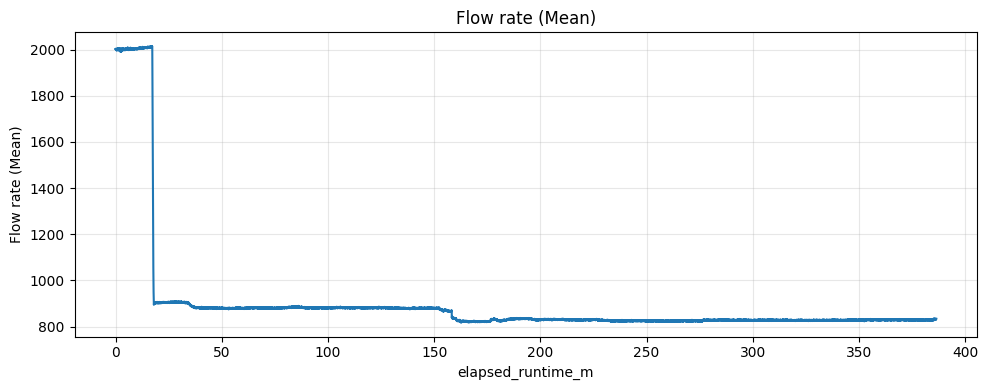

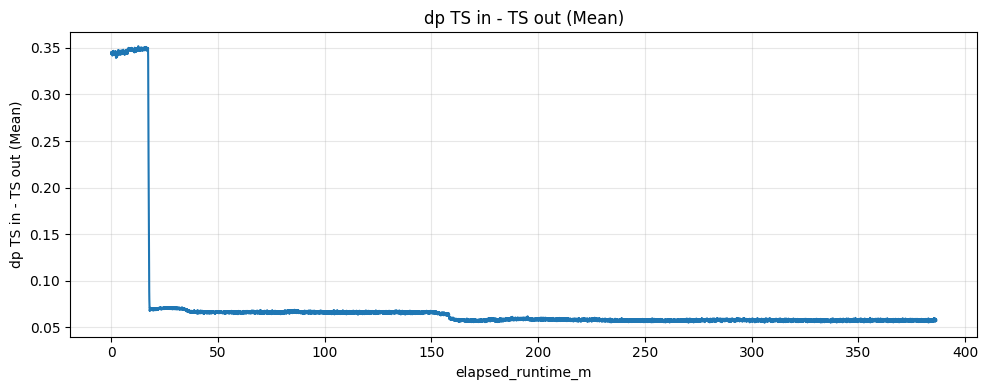

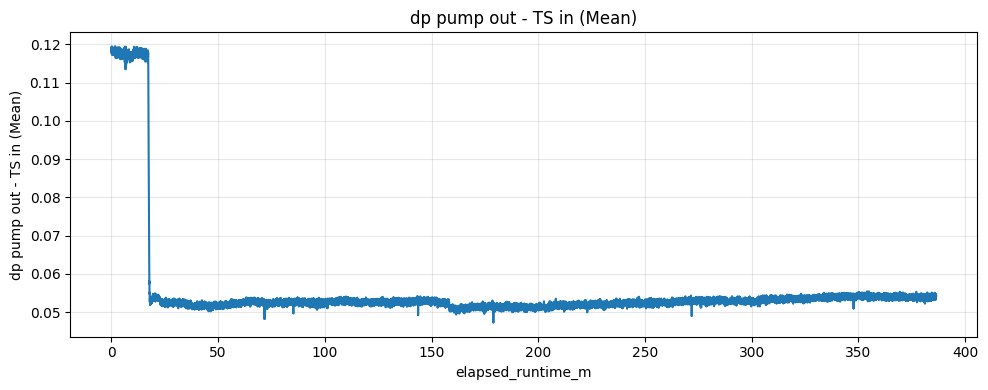

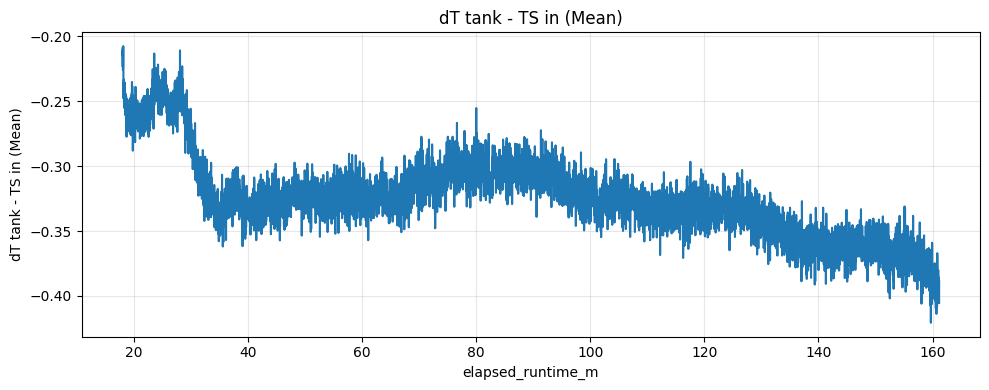

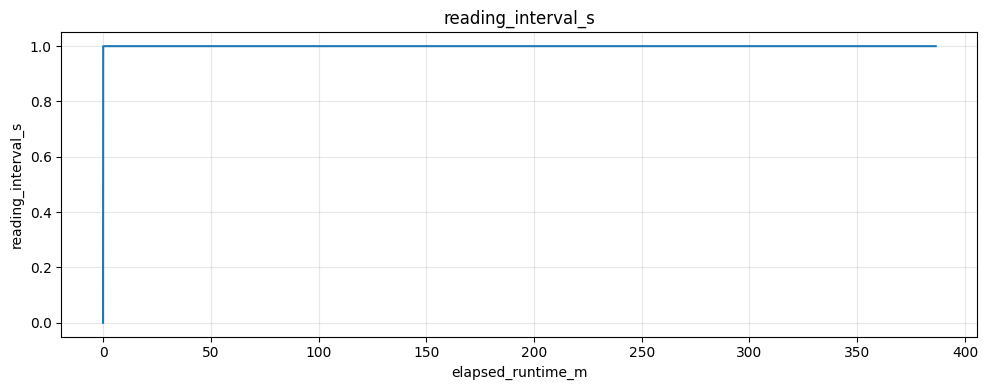

In [334]:
plot_all_timeseries(df)

### snipping

In [39]:
i = 1081
df.loc[i-5:i+5]

,Time,Unnamed: 1,Temperature TS outlet (Mean),Temperature TS inlet (Mean),Bypass temperature (Mean),Tank temperature (Mean),TS outlet pressure (Mean),TS inlet pressure (Mean),Pump outlet pressure (Mean),Flow rate (Mean),dp TS in - TS out (Mean),dp pump out - TS in (Mean),dT tank - TS in (Mean),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
1076,2018-03-17 11:23:21.279,-5,-1.054744,-1.073544,24.673454,-1.259323,0.198165,0.269700,0.323339,936.130488,0.071535,0.053639,NaN,1.0,1076.0,17.933333
1077,2018-03-17 11:23:22.279,-4,-1.055006,-1.074201,24.677130,-1.274022,0.195382,0.266928,0.320133,922.122792,0.071546,0.053205,NaN,1.0,1077.0,17.950000
1078,2018-03-17 11:23:23.279,-3,-1.057369,-1.055956,24.680543,-1.266279,0.195052,0.265253,0.318360,913.353249,0.070201,0.053107,NaN,1.0,1078.0,17.966667
1079,2018-03-17 11:23:24.279,-2,-1.058156,-1.057794,24.681330,-1.280716,0.192909,0.261998,0.314675,909.378665,0.069089,0.052677,NaN,1.0,1079.0,17.983333
1080,2018-03-17 11:23:25.279,-1,-1.060650,-1.071576,24.684218,-1.294104,0.191670,0.260528,0.314060,903.107970,0.068858,0.053532,NaN,1.0,1080.0,18.000000
1081,2018-03-17 11:23:26.279,0,-1.059863,-1.073807,24.685662,-1.283210,0.191796,0.259593,0.312645,898.147992,0.067797,0.053052,-0.209403,1.0,1081.0,18.016667
1082,2018-03-17 11:23:27.279,1,-1.060388,-1.072363,24.687238,-1.287279,0.192400,0.260895,0.314308,894.116831,0.068495,0.053413,-0.214916,1.0,1082.0,18.033333
1083,2018-03-17 11:23:28.279,2,-1.053168,-1.075119,24.693670,-1.289116,0.193062,0.261373,0.314951,895.191807,0.068311,0.053578,-0.213997,1.0,1083.0,18.050000
1084,2018-03-17 11:23:29.279,3,-1.058813,-1.082995,24.704172,-1.294104,0.193183,0.261567,0.315172,897.327615,0.068384,0.053605,-0.211109,1.0,1084.0,18.066667
1085,2018-03-17 11:23:30.279,4,-1.051462,-1.053725,24.699052,-1.277435,0.194122,0.262880,0.316127,898.831639,0.068758,0.053247,-0.223710,1.0,1085.0,18.083333


Unnamed 1 ser ut til å vise hvor start til run er. start = 0

In [40]:
df.drop(columns=['Unnamed: 1', 'dp TS in - TS out (Mean)', 'dp pump out - TS in (Mean)', 'dT tank - TS in (Mean)'], inplace=True)

In [41]:
df = snip_df_at_timecode(df, 1081, 0)

In [338]:
df.to_csv('../data/split/partial_plug/1803.csv', index=False)

### Plot after snip

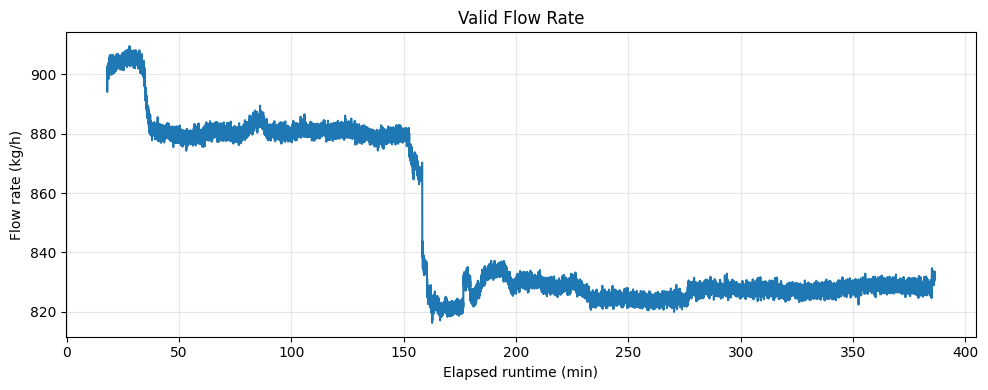

In [42]:
plot_flow_rate(df)

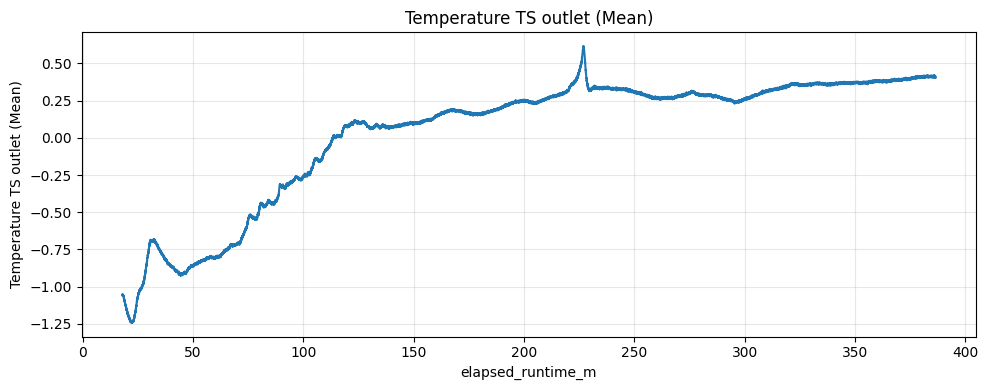

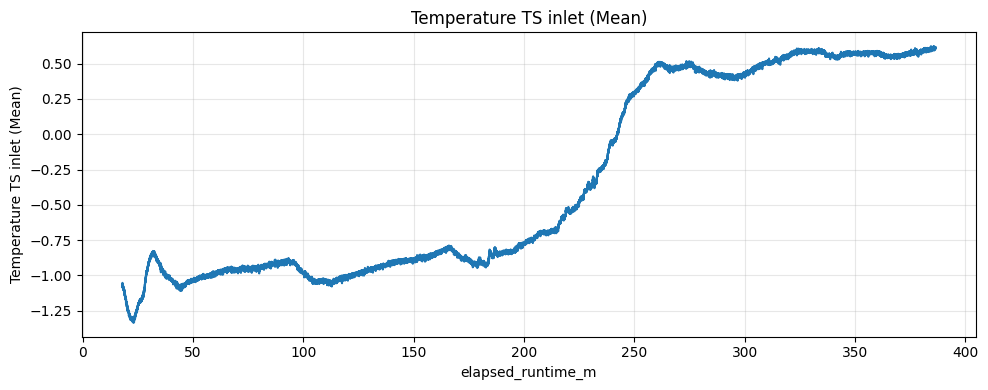

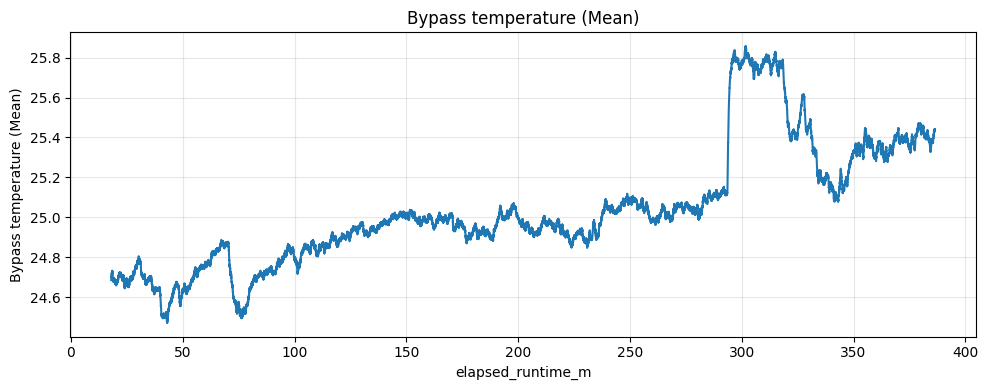

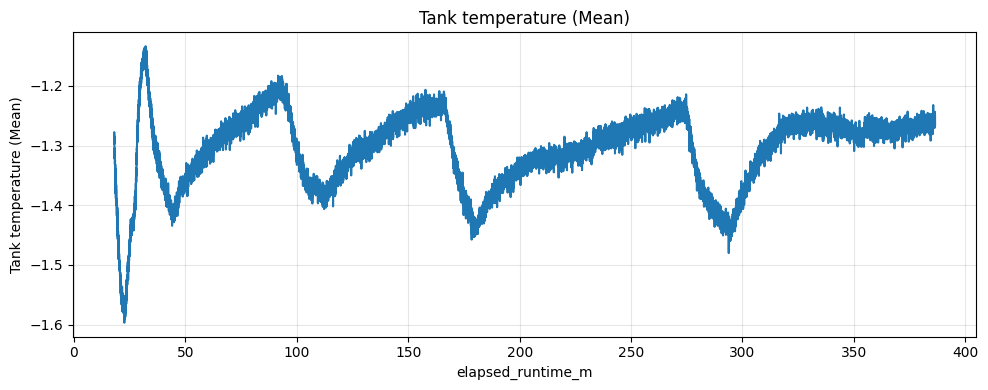

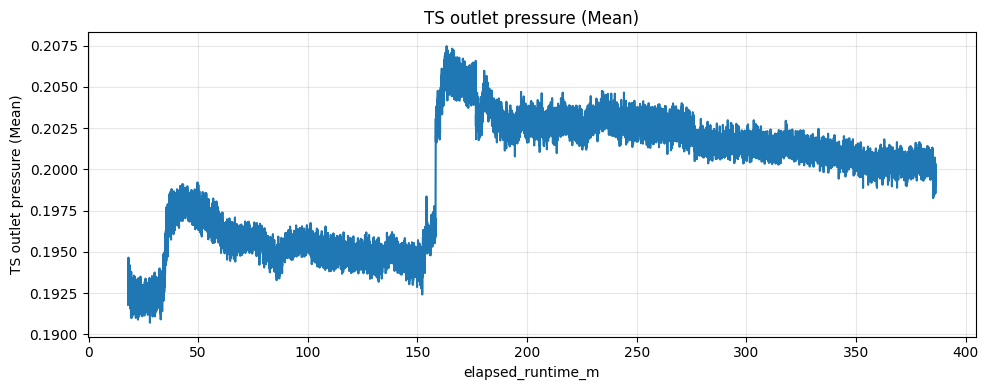

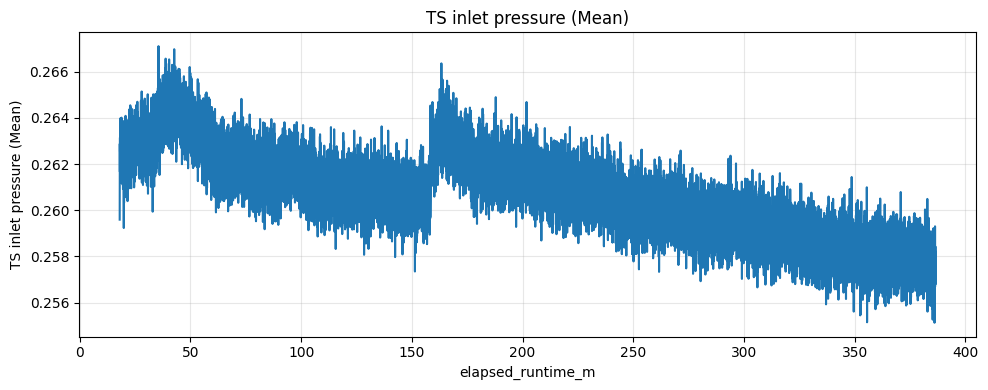

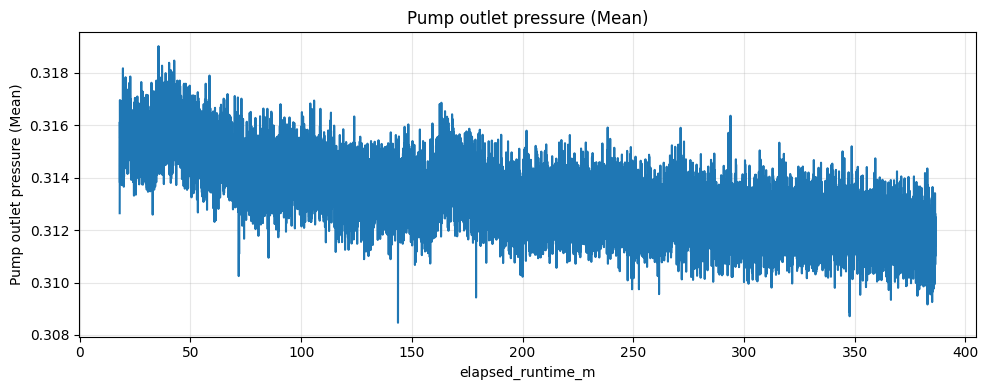

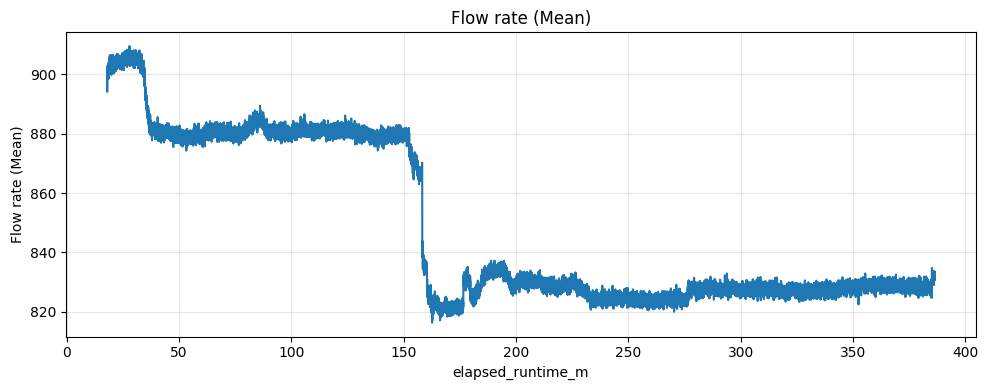

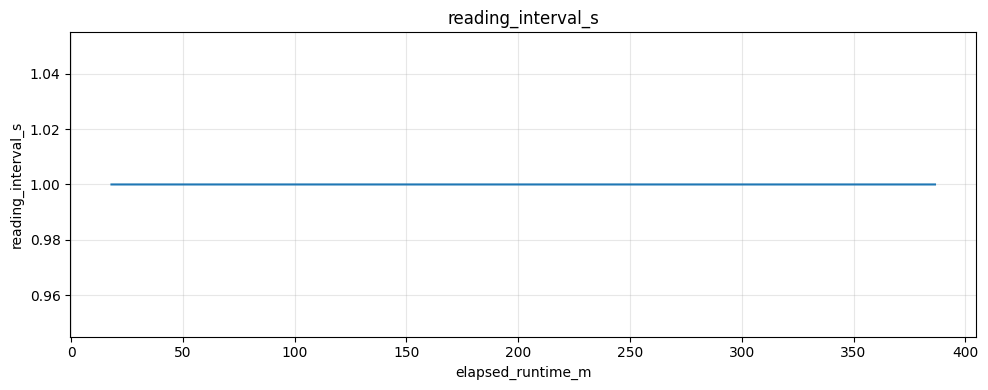

In [339]:
plot_all_timeseries(df)

## 24.01

### Init

In [4]:
df = df2401.copy()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3019 entries, 0 to 3018
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Time                          3019 non-null   datetime64[ns]
 1   Temperature TS outlet (Mean)  3019 non-null   float64       
 2   Temperature TS inlet (Mean)   3019 non-null   float64       
 3   Bypass temperature (Mean)     3019 non-null   float64       
 4   Tank temperature (Mean)       3019 non-null   float64       
 5   TS outlet pressure (Mean)     3019 non-null   float64       
 6   TS inlet pressure (Mean)      3019 non-null   float64       
 7   Pump outlet pressure (Mean)   3019 non-null   float64       
 8   Flow rate (Mean)              3019 non-null   float64       
 9   Unnamed: 9                    3019 non-null   float64       
 10  Unnamed: 10                   3019 non-null   float64       
dtypes: datetime64[ns](1), float64(

In [341]:
basic_checklist(df)


Missing values:
No missing values found.



In [342]:
t = df["Time"]

bad = t.diff() < pd.Timedelta(0)
bad_idx = df.index[bad]

bad_idx[:10], bad.sum()


(Index([2405], dtype='int64'), np.int64(1))

In [343]:
i = 2405
df.loc[i-5:i+5]


,Time,Temperature TS outlet (Mean),Temperature TS inlet (Mean),Bypass temperature (Mean),Tank temperature (Mean),TS outlet pressure (Mean),TS inlet pressure (Mean),Pump outlet pressure (Mean),Flow rate (Mean),Unnamed: 9,Unnamed: 10
2400,2023-01-24 15:31:06.330,21.955385,-0.165133,22.494579,-1.257354,0.078063,0.109363,0.172015,0.948259,0.031300,0.062652
2401,2023-01-24 15:31:07.330,21.958798,-0.165921,22.505606,-1.262604,0.078483,0.109778,0.173228,0.858677,0.031295,0.063450
2402,2023-01-24 15:31:08.330,21.956041,-0.152402,22.507050,-1.250004,0.078604,0.109090,0.172309,0.915255,0.030486,0.063219
2403,2023-01-24 15:31:09.330,21.954073,-0.151483,22.509544,-1.256698,0.078147,0.109163,0.172401,0.340048,0.031016,0.063238
2404,2023-01-24 15:31:10.330,21.955385,-0.164083,22.514401,-1.252891,0.078572,0.109961,0.172943,0.995407,0.031389,0.062982
2405,2023-01-24 15:31:07.330,21.958798,-0.165921,22.505606,-1.262604,0.078483,0.109778,0.173228,0.858677,0.031295,0.063450
2406,2023-01-24 15:31:08.330,21.956041,-0.152402,22.507050,-1.250004,0.078604,0.109090,0.172309,0.915255,0.030486,0.063219
2407,2023-01-24 15:31:09.330,21.954073,-0.151483,22.509544,-1.256698,0.078147,0.109163,0.172401,0.340048,0.031016,0.063238
2408,2023-01-24 15:31:10.330,21.955385,-0.164083,22.514401,-1.252891,0.078572,0.109961,0.172943,0.995407,0.031389,0.062982
2409,2023-01-24 15:31:11.330,21.951710,-0.147939,22.516108,-1.255385,0.079108,0.110822,0.174156,0.806814,0.031714,0.063334


In [344]:
(df.loc[2401] == df.loc[2405]).all()
(df.loc[2402] == df.loc[2406]).all()
(df.loc[2403] == df.loc[2407]).all()
(df.loc[2404] == df.loc[2408]).all()


np.True_

2401-2404 identisk med 2405-2408 også tiden som betyr duplikert data?

In [345]:
df = df.drop(index=range(2405, 2409))

In [346]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


In [347]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    3014
0.0       1
Name: count, dtype: int64

In [348]:
rename_map = {
    "Unnamed: 9": "dp TS in - TS out (Mean)",
    "Unnamed: 10": "dp pump out - TS in (Mean)",
}

df = df.rename(columns=rename_map)

### plotting

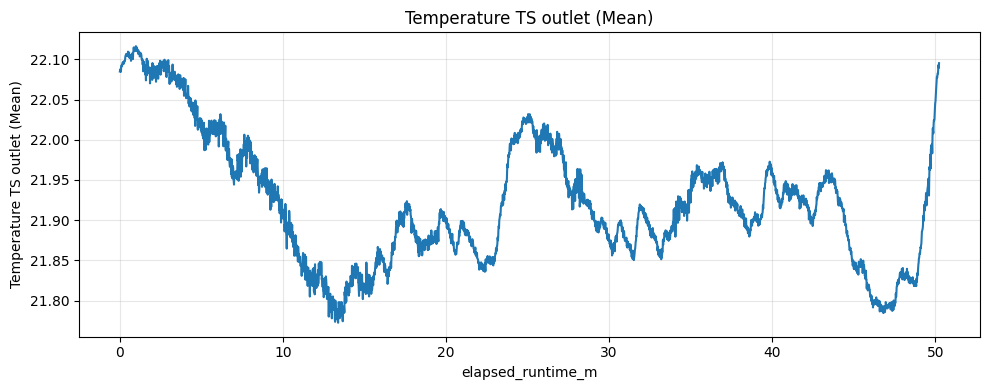

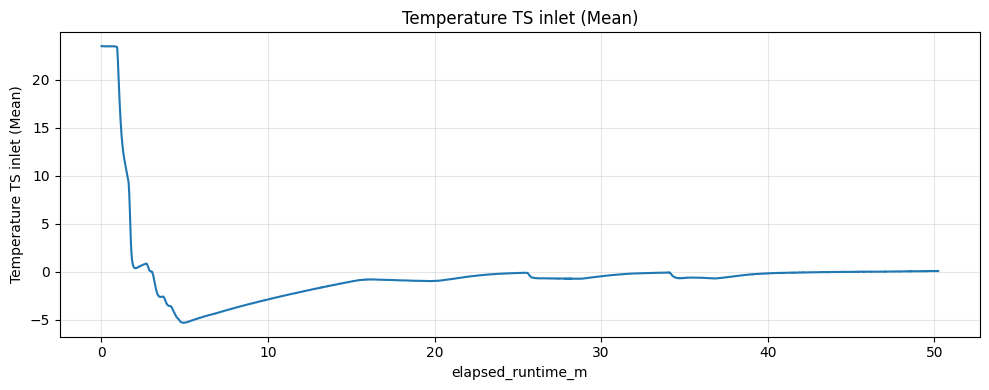

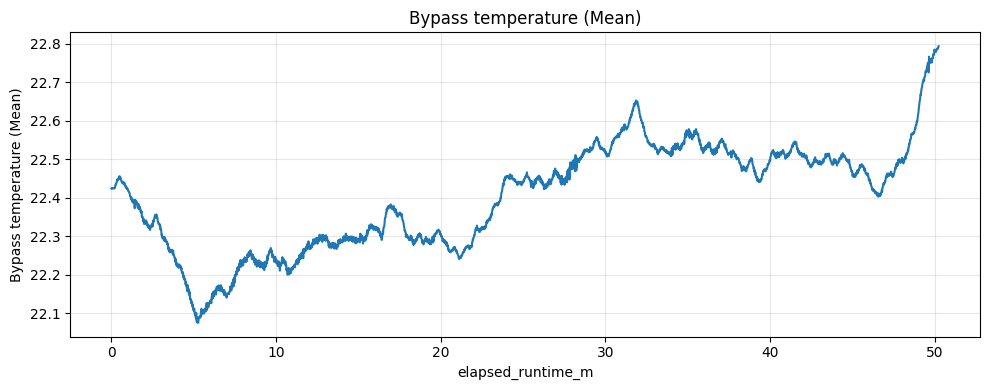

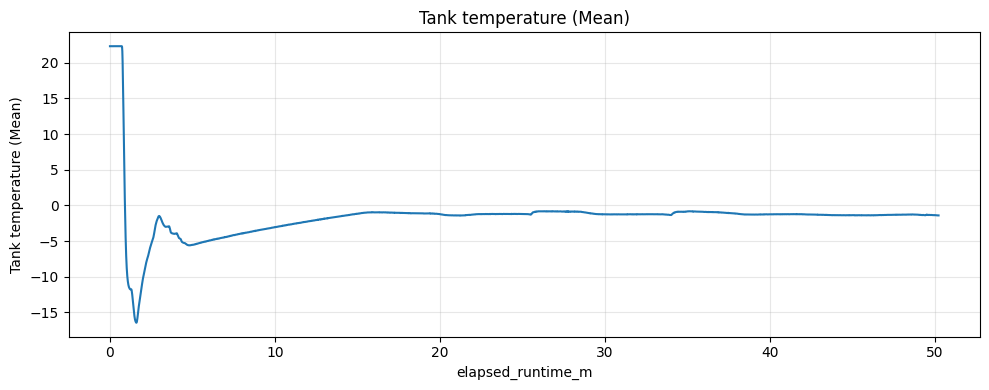

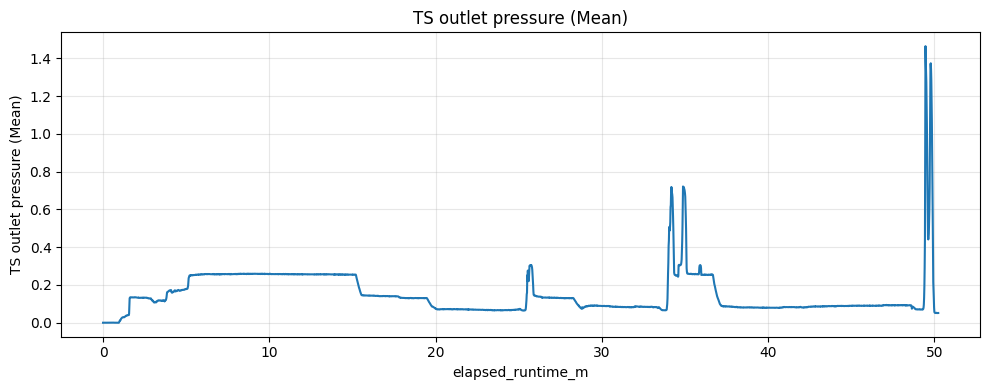

...

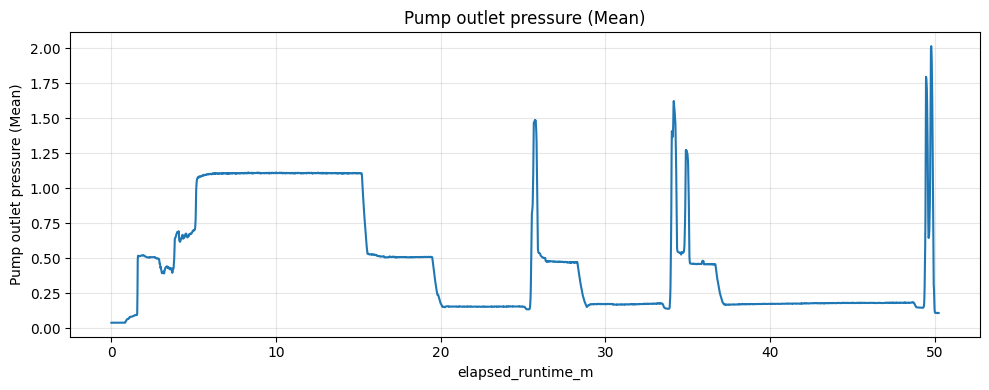

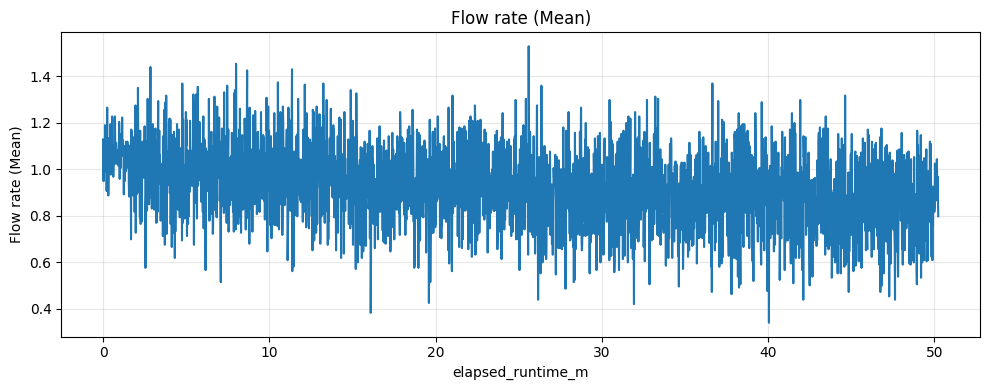

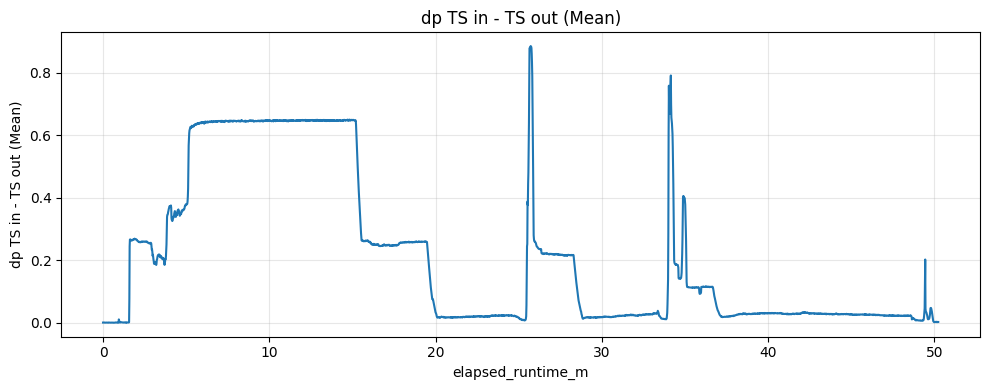

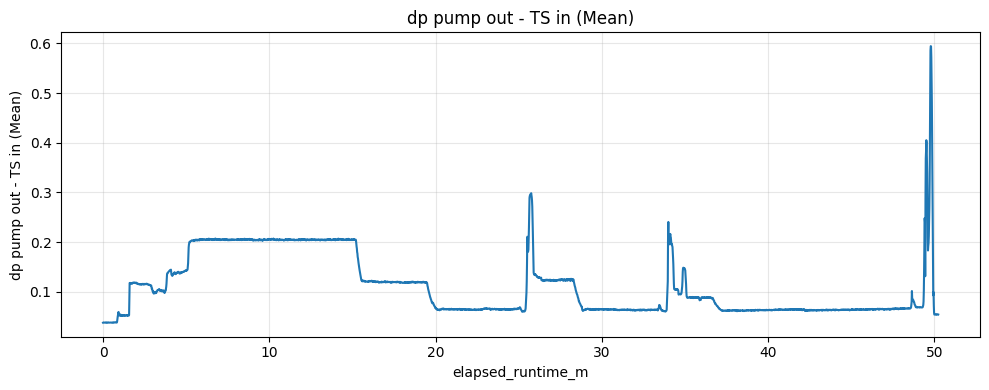

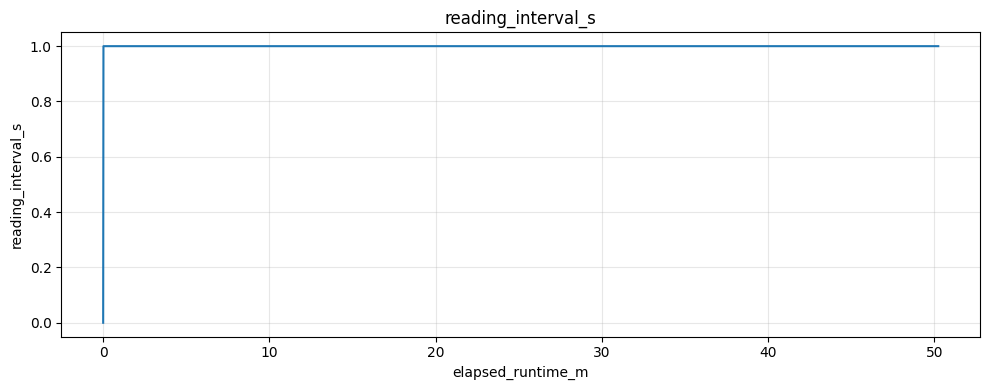

In [349]:
plot_all_timeseries(df)

### snipping

In [350]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3015 entries, 0 to 3018
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Time                          3015 non-null   datetime64[ns]
 1   Temperature TS outlet (Mean)  3015 non-null   float64       
 2   Temperature TS inlet (Mean)   3015 non-null   float64       
 3   Bypass temperature (Mean)     3015 non-null   float64       
 4   Tank temperature (Mean)       3015 non-null   float64       
 5   TS outlet pressure (Mean)     3015 non-null   float64       
 6   TS inlet pressure (Mean)      3015 non-null   float64       
 7   Pump outlet pressure (Mean)   3015 non-null   float64       
 8   Flow rate (Mean)              3015 non-null   float64       
 9   dp TS in - TS out (Mean)      3015 non-null   float64       
 10  dp pump out - TS in (Mean)    3015 non-null   float64       
 11  reading_interval_s            3015 

In [351]:
df.drop(columns=['dp TS in - TS out (Mean)', 'dp pump out - TS in (Mean)'], inplace=True)

fra description vet vi

15:11:12 – 15:16:10 – loop blockage

15:19:56 – 15:24:32 – washer blockage


In [352]:
start = find_index_at_timestamp(df, 151112)
end = find_index_at_timestamp(df, 151610)
dffirst = snip_df_at_timecode(df, start, end)

In [353]:
start = find_index_at_timestamp(df, 151956)
end = find_index_at_timestamp(df, 152432)
dfsnd = snip_df_at_timecode(df, start, end)

In [354]:
dffirst.to_csv('../data/split/plug/2401-1.csv', index=False)
dfsnd.to_csv('../data/split/plug/2401-2.csv', index=False)

### Plot after snip

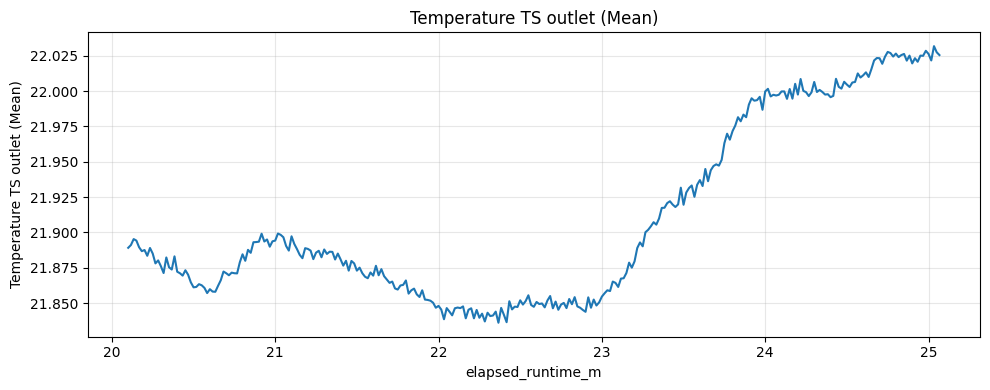

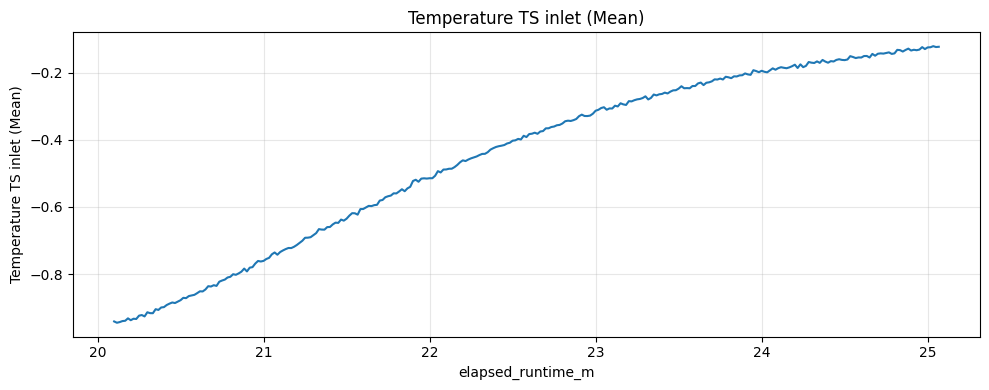

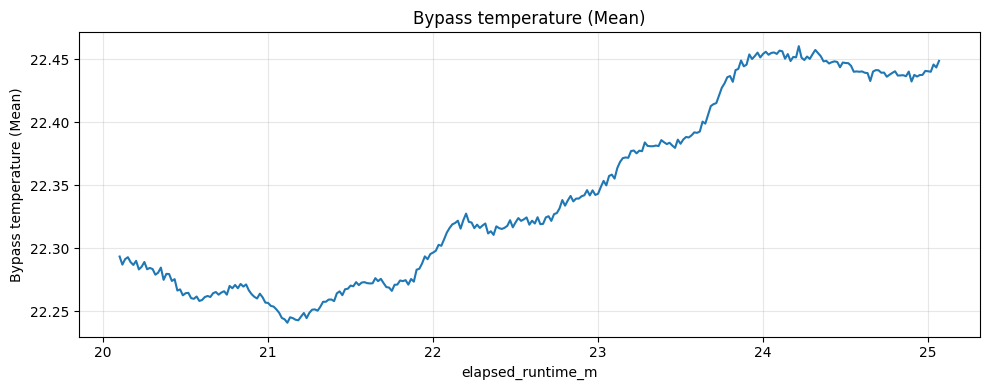

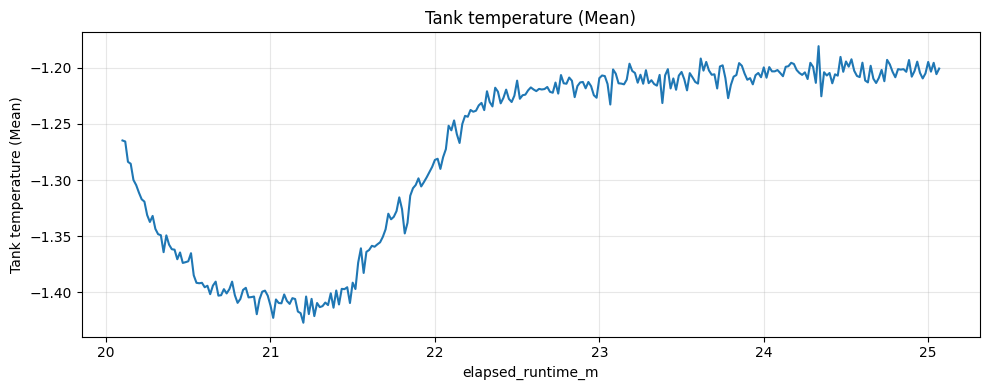

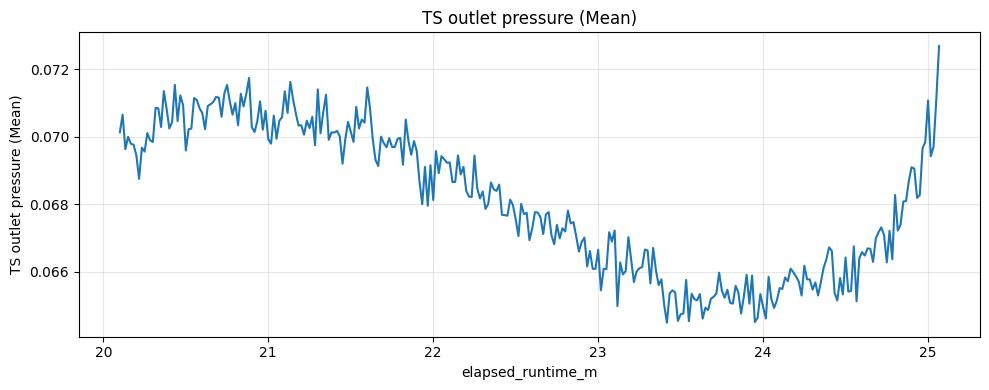

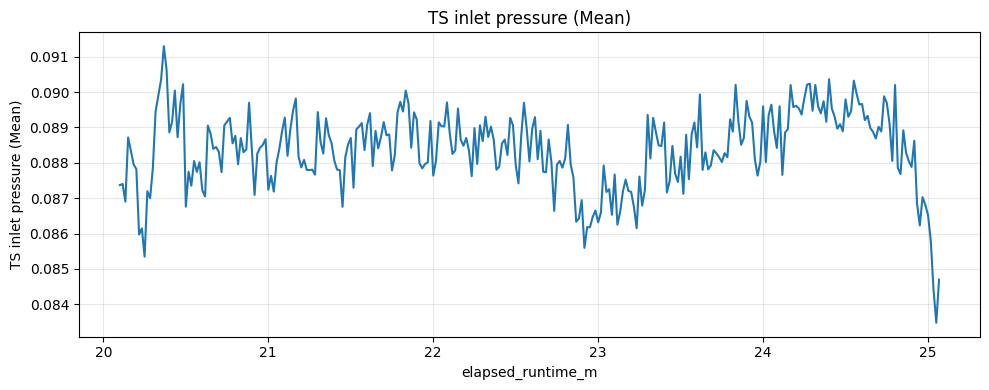

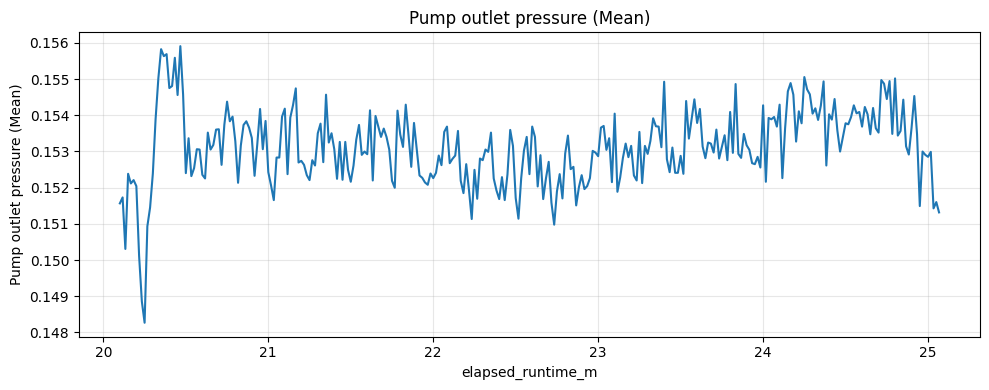

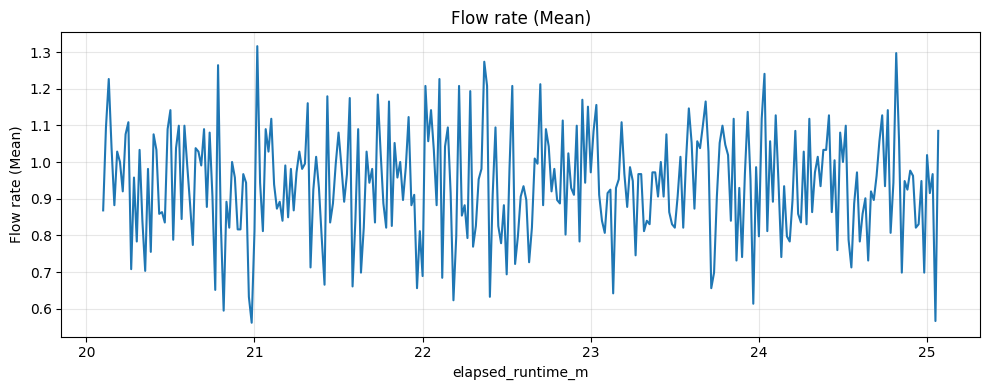

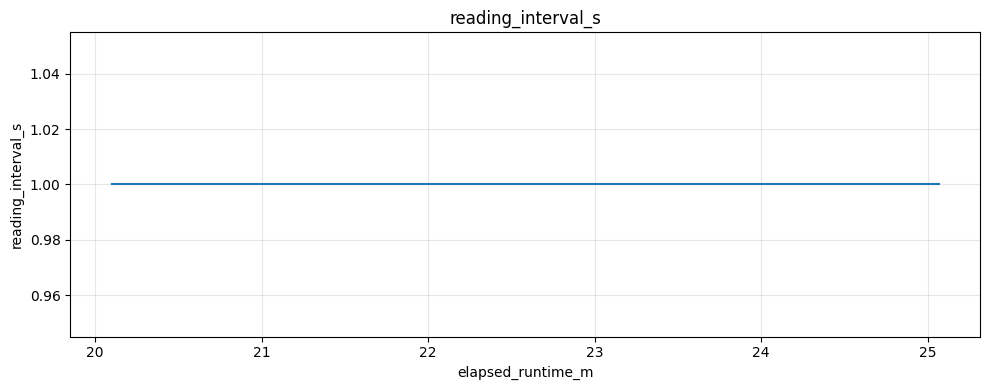

In [355]:
plot_all_timeseries(dffirst)

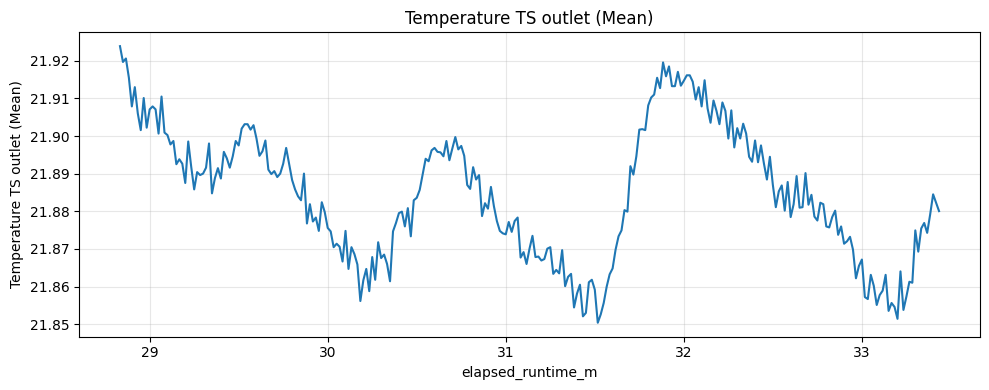

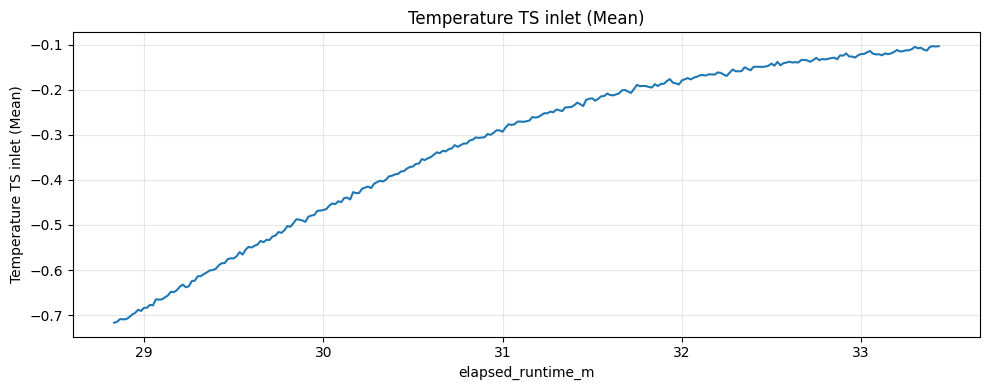

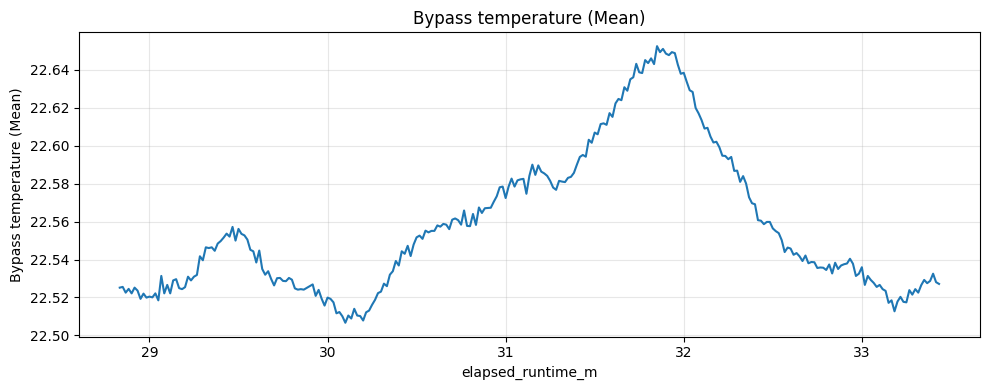

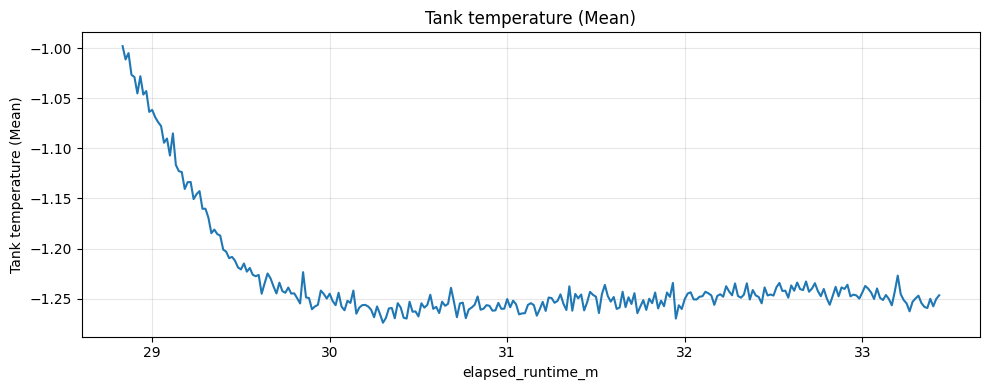

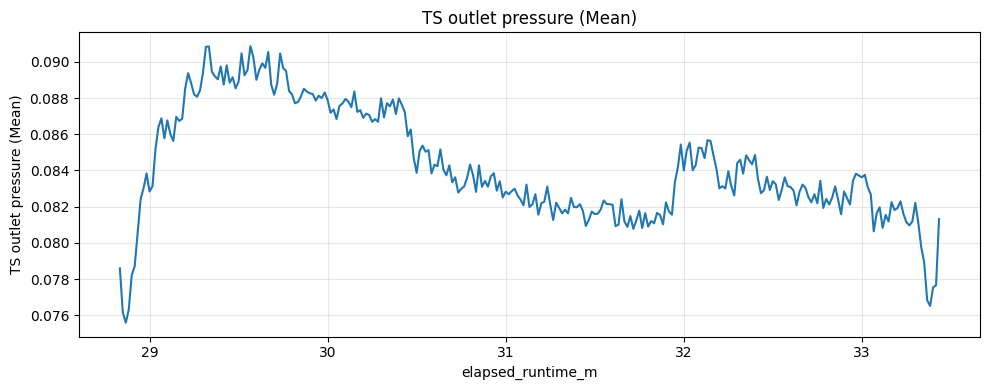

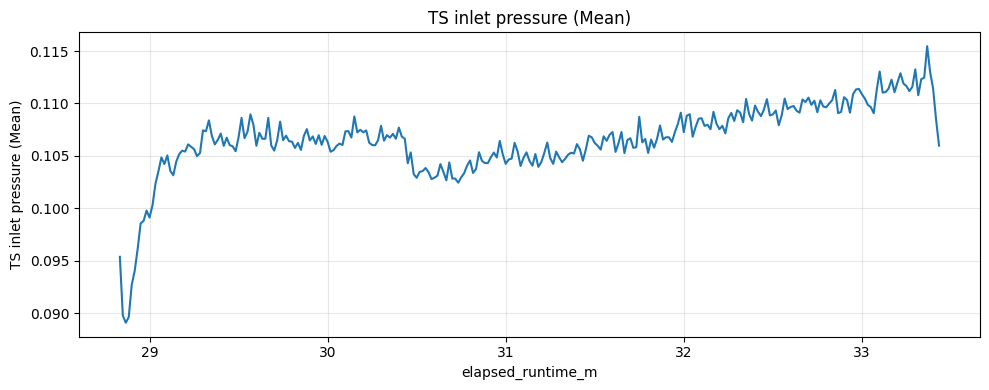

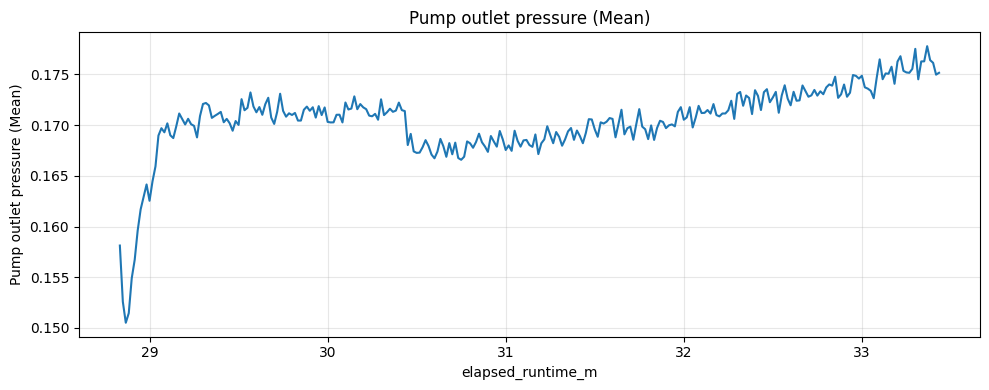

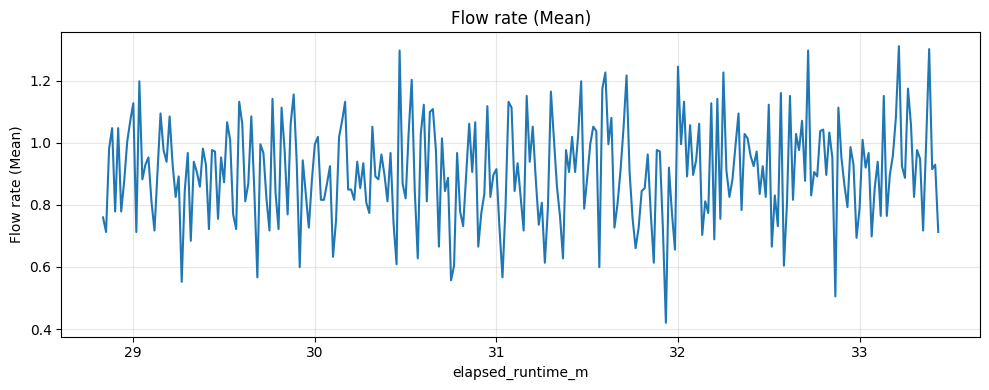

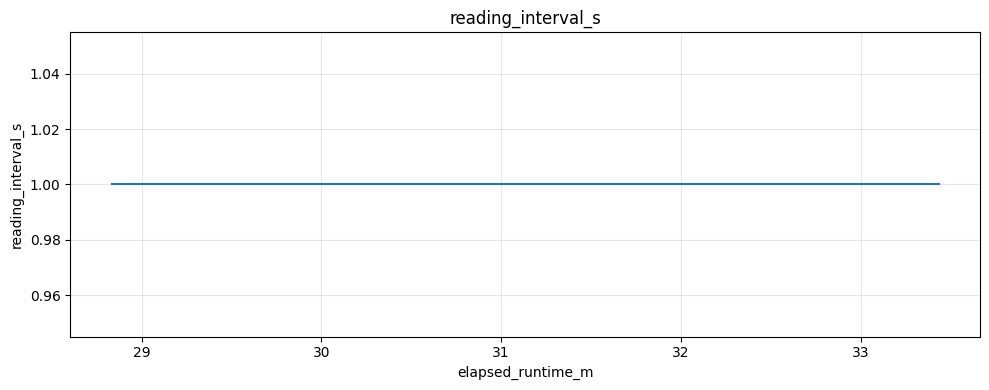

In [356]:
plot_all_timeseries(dfsnd)

## 07.09

### Init

In [357]:
df = df0709.copy()

In [358]:
basic_checklist(df)

Missing values:
Time                               0
Temperature TS outlet (Mean)       0
Temperature TS inlet (Mean)        0
Bypass temperature (Mean)          0
Tank temperature (Mean)            0
TS outlet pressure (Mean)          0
TS inlet pressure (Mean)           0
Pump outlet pressure (Mean)        0
Flow rate (Mean)                   0
Pressure diff                      0
Unnamed: 10                     3386
dtype: int64

Time column is monotonic increasing.


In [359]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    3454
0.0       1
Name: count, dtype: int64

### plotting

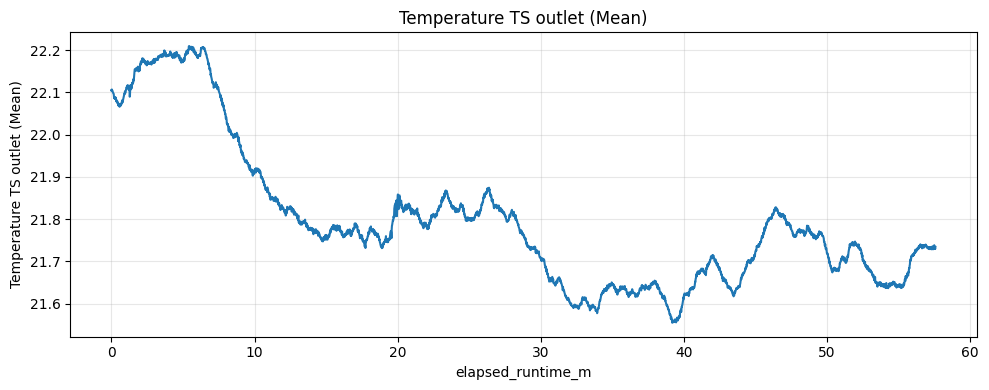

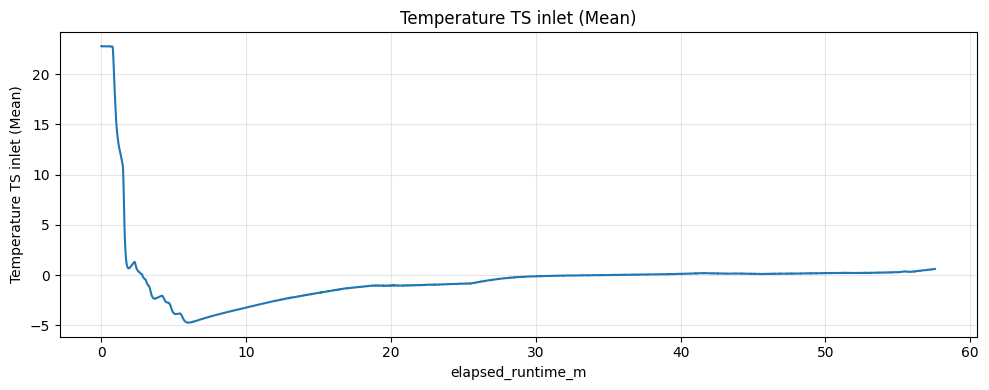

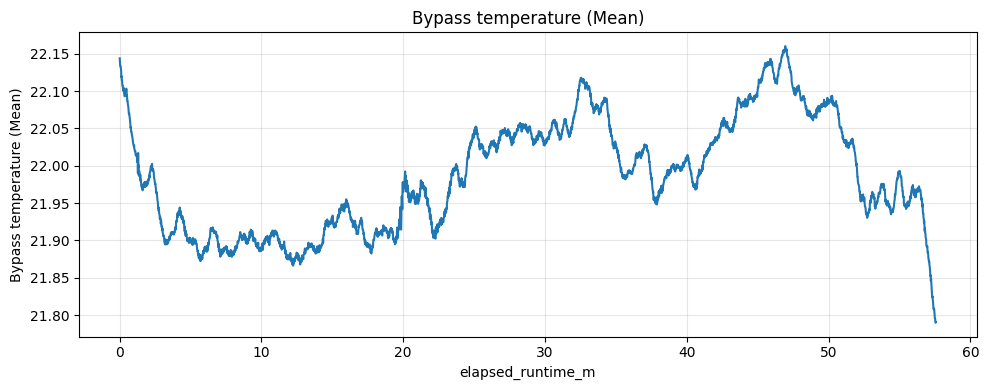

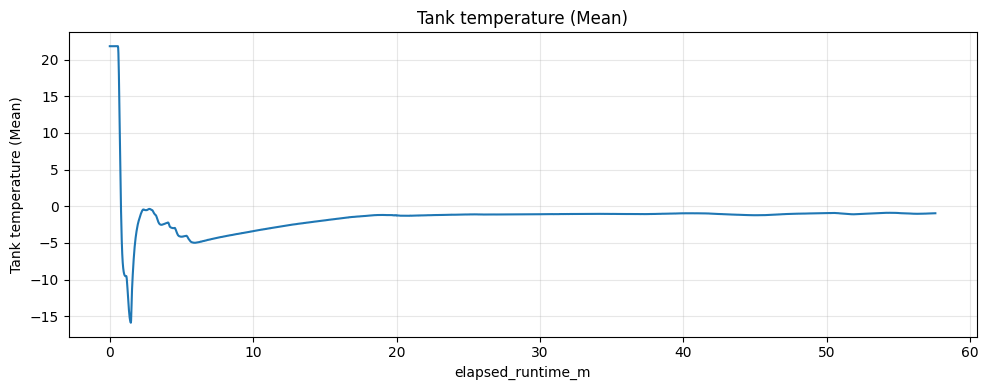

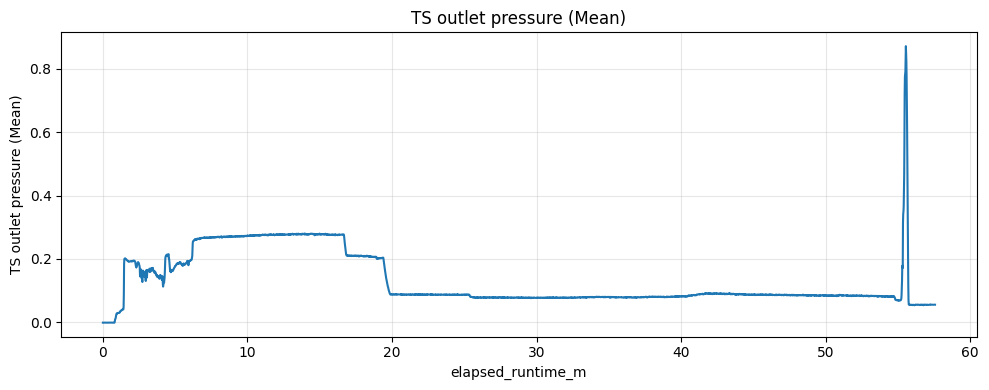

...

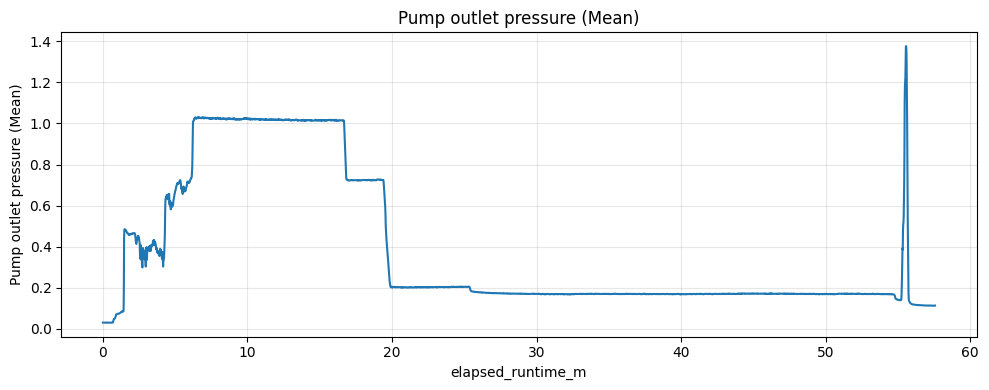

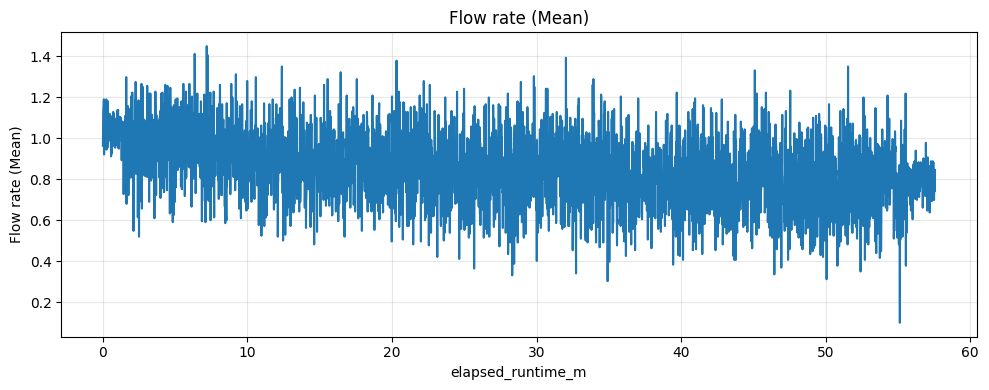

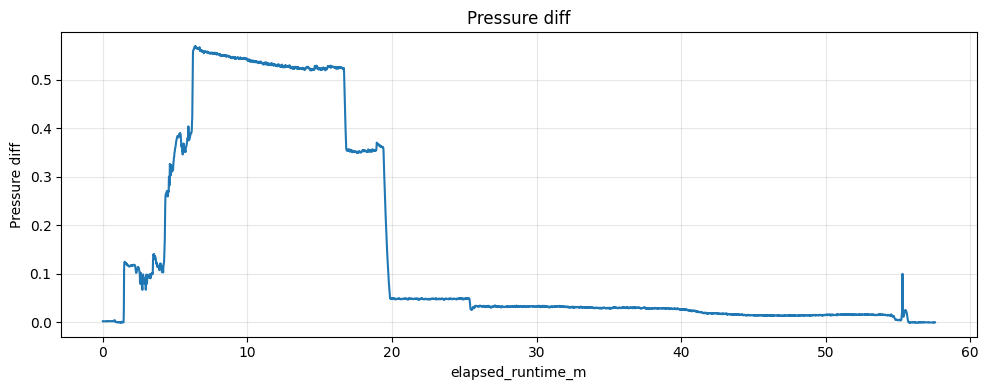

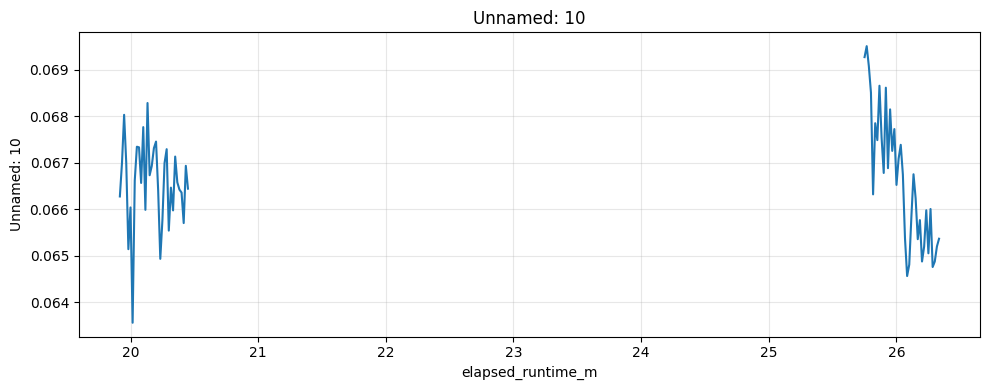

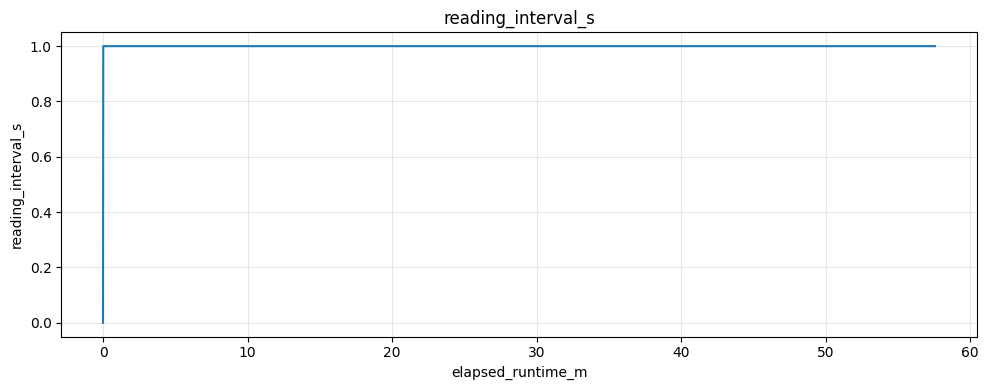

In [360]:
plot_all_timeseries(df)

### snipping

In [361]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3455 entries, 0 to 3454
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Time                          3455 non-null   datetime64[ns]
 1   Temperature TS outlet (Mean)  3455 non-null   float64       
 2   Temperature TS inlet (Mean)   3455 non-null   float64       
 3   Bypass temperature (Mean)     3455 non-null   float64       
 4   Tank temperature (Mean)       3455 non-null   float64       
 5   TS outlet pressure (Mean)     3455 non-null   float64       
 6   TS inlet pressure (Mean)      3455 non-null   float64       
 7   Pump outlet pressure (Mean)   3455 non-null   float64       
 8   Flow rate (Mean)              3455 non-null   float64       
 9   Pressure diff                 3455 non-null   float64       
 10  Unnamed: 10                   69 non-null     float64       
 11  reading_interval_s            

In [362]:
df.drop(columns=['Pressure diff', 'Unnamed: 10'], inplace=True)

fra description: 13:15:49 – 13:44:06 – blockage of the test section

In [363]:
start = find_index_at_timestamp(df, 131549)
end = find_index_at_timestamp(df, 134406)
df = snip_df_at_timecode(df, start, end)

In [364]:
df.to_csv('../data/split/plug/0709.csv', index=False)

### Plot after snip

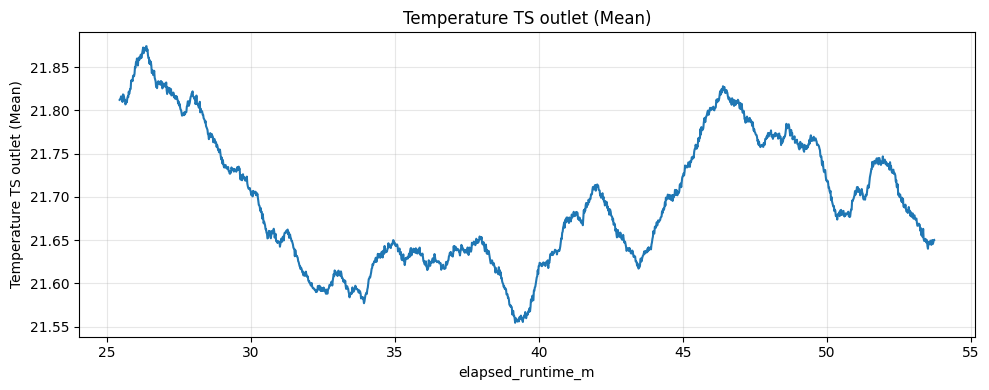

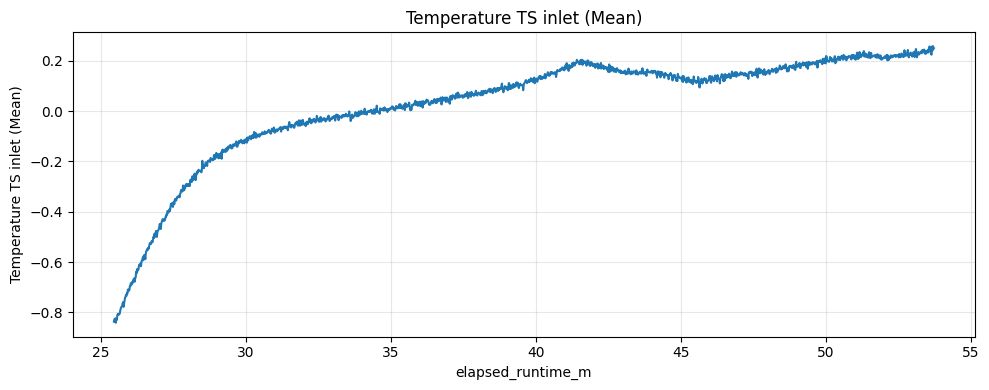

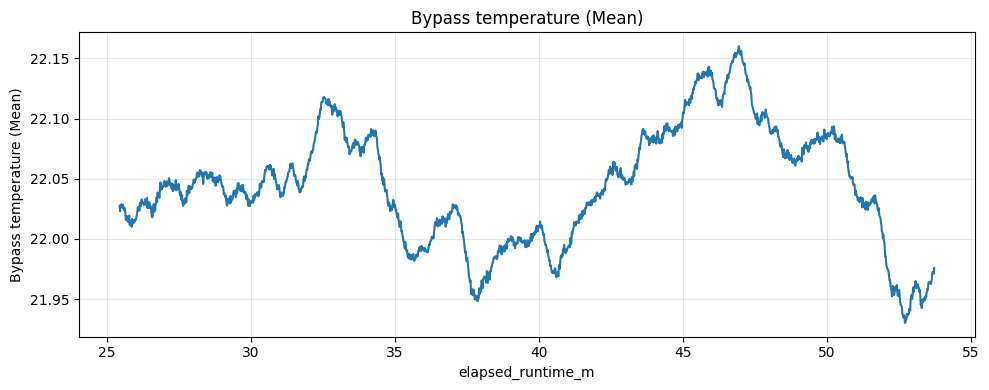

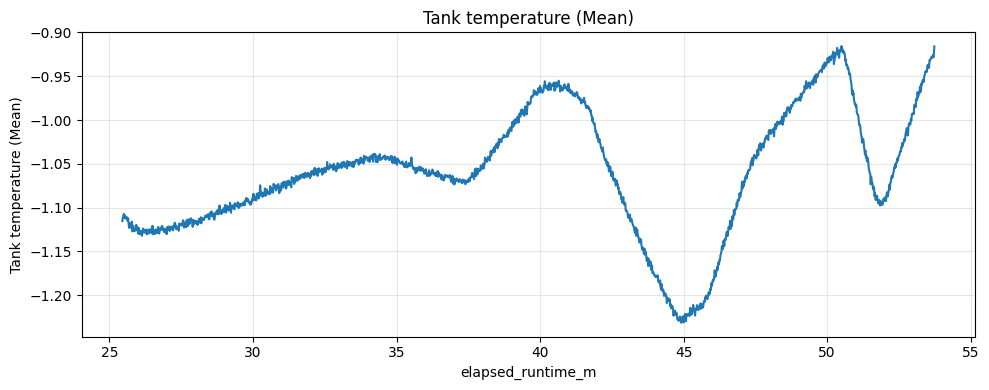

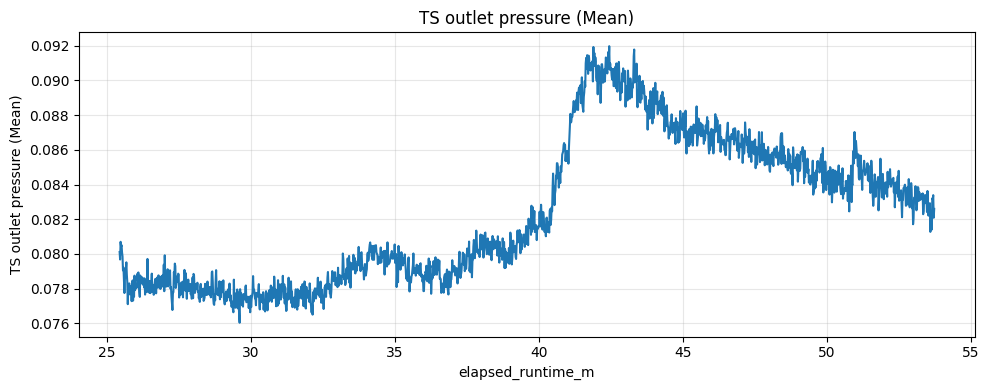

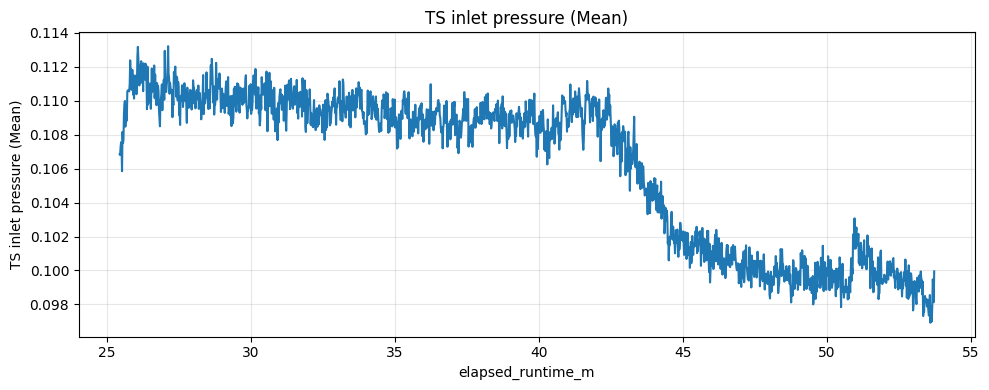

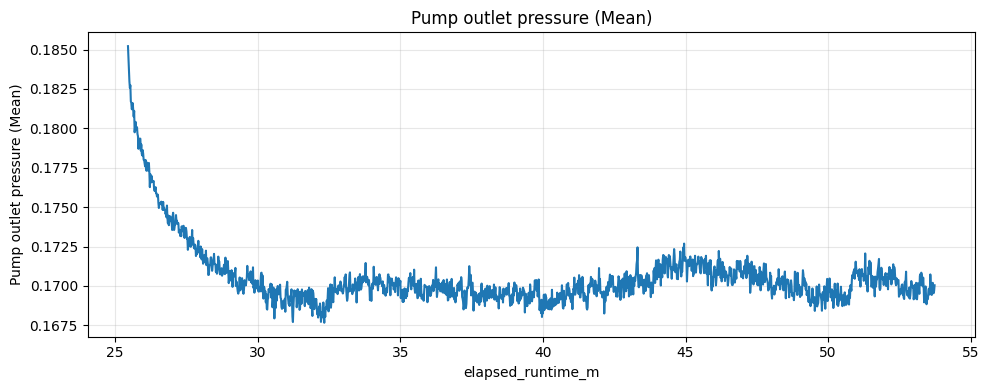

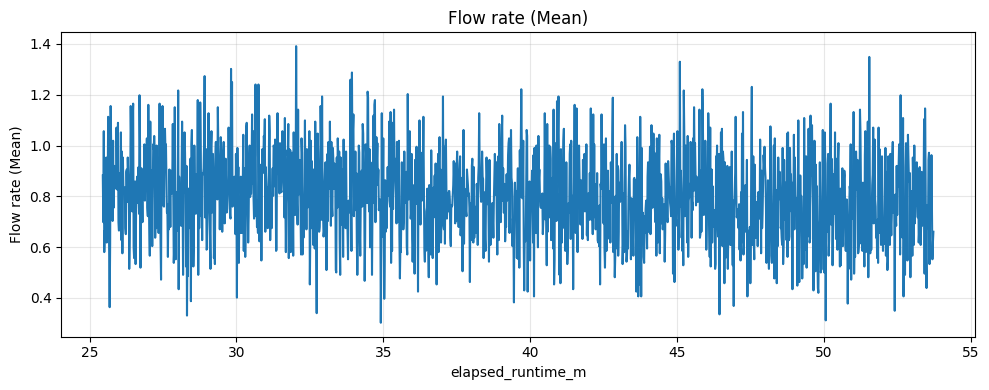

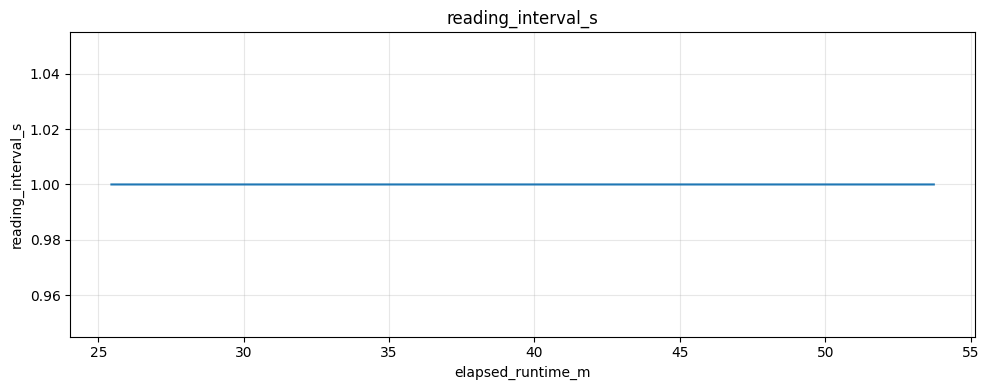

In [365]:
plot_all_timeseries(df)

## 21.06

### Init

In [366]:
df = df2106.copy()

In [367]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


In [368]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    4496
0.0       1
Name: count, dtype: int64

In [369]:
rename_map = {
    "Unnamed: 9": "dp TS in - TS out (Mean)",
    "Unnamed: 10": "dp pump out - TS in (Mean)",
}

df = df.rename(columns=rename_map)

### plotting

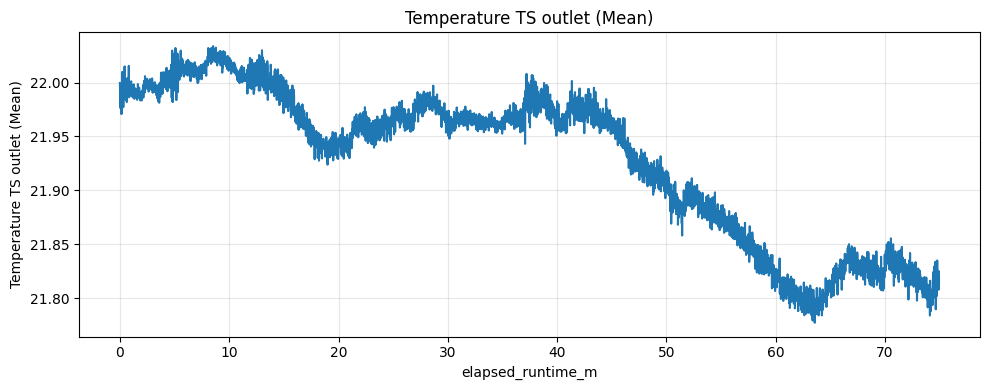

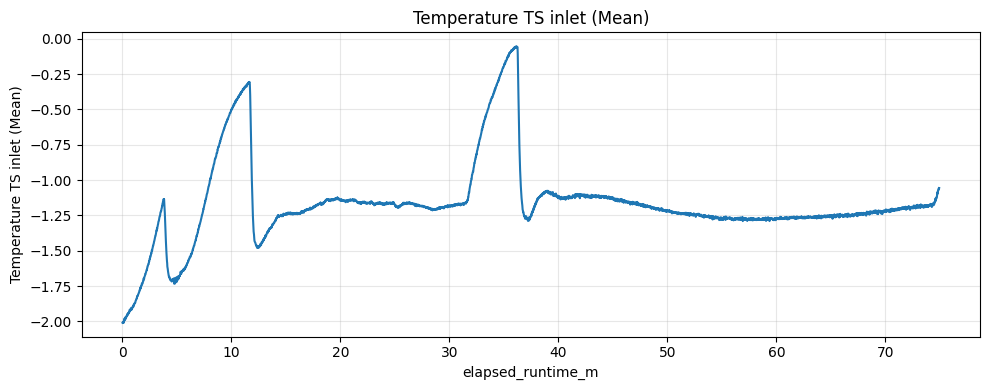

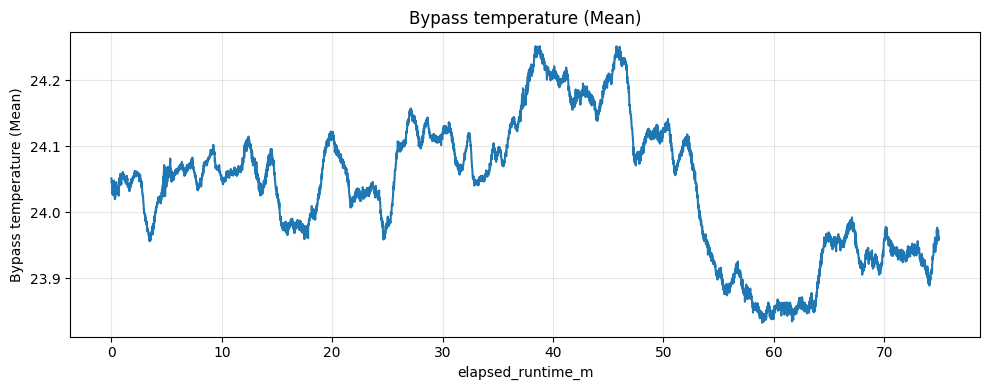

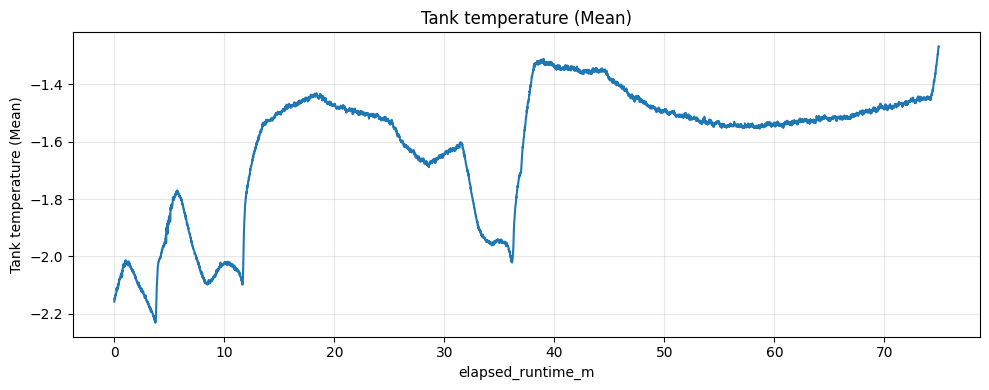

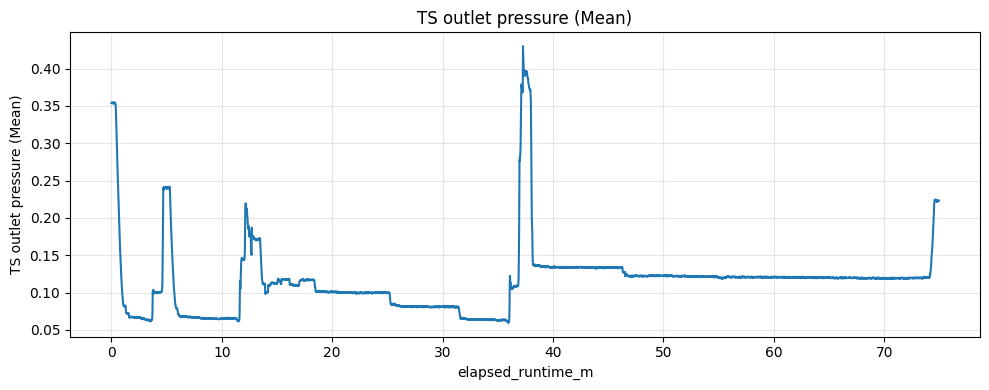

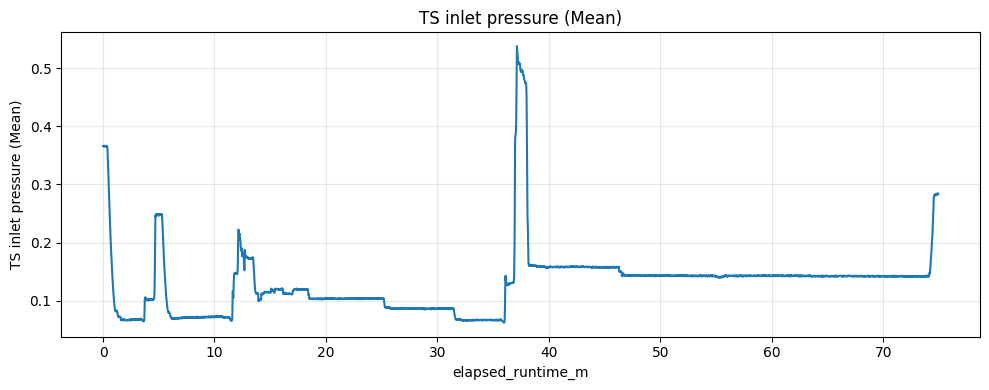

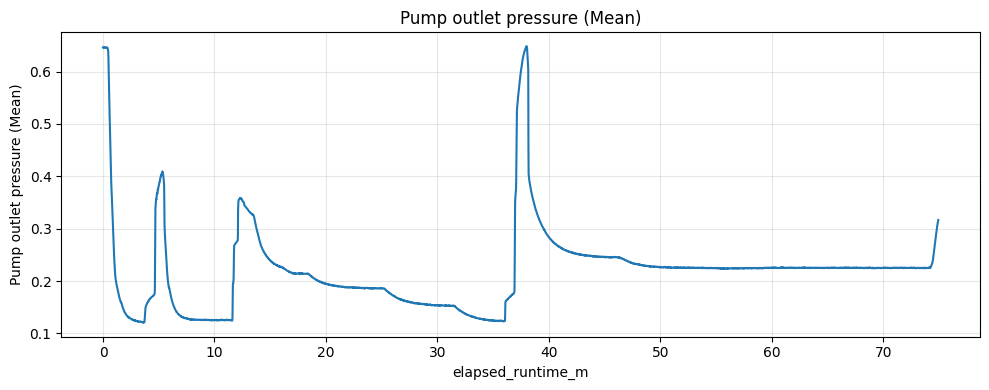

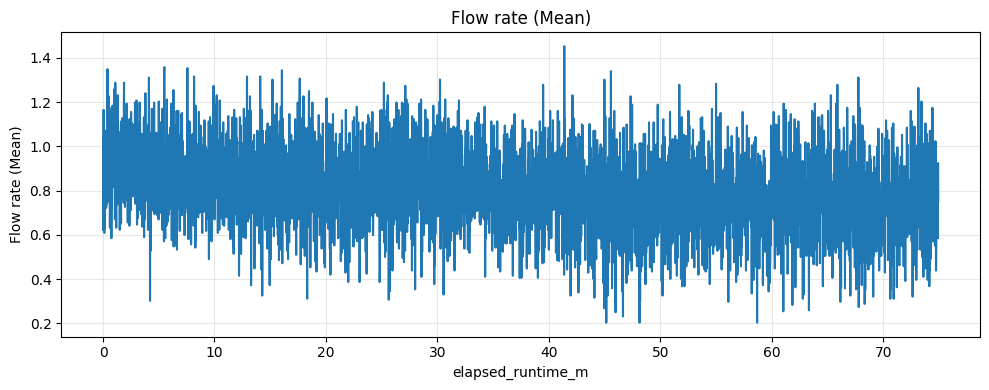

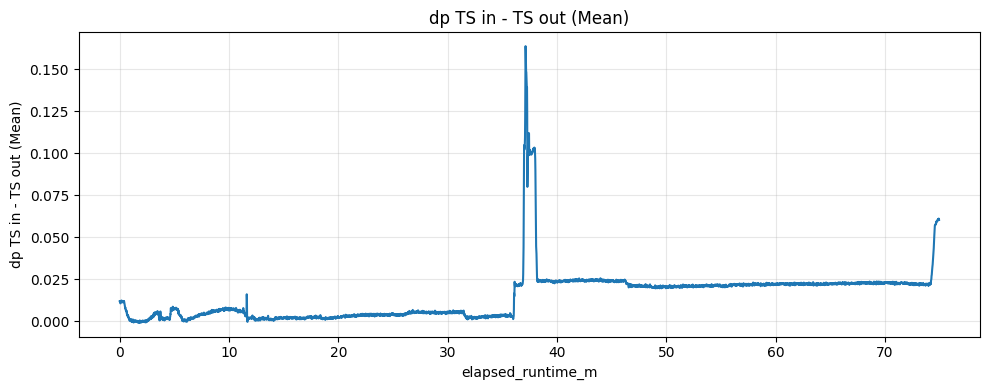

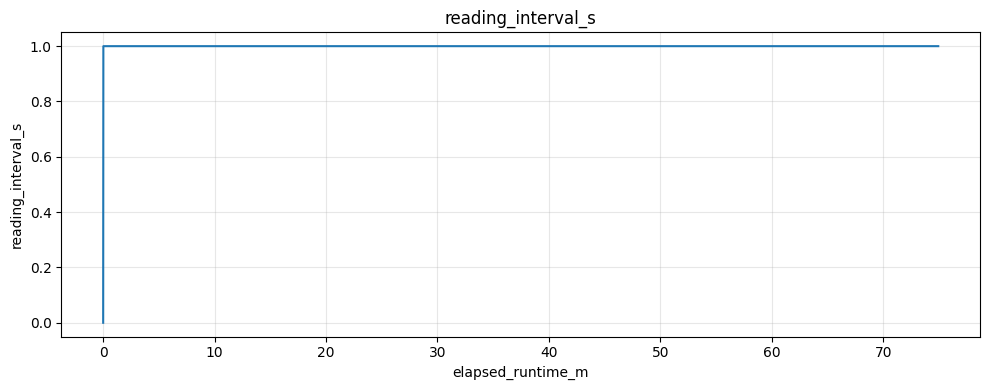

In [370]:
plot_all_timeseries(df)

3 test runs, blocking i de to første, ser farget rows i data som tilsvarer description på runs

### snipping

In [371]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4497 entries, 0 to 4496
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Time                          4497 non-null   datetime64[ns]
 1   Temperature TS outlet (Mean)  4497 non-null   float64       
 2   Temperature TS inlet (Mean)   4497 non-null   float64       
 3   Bypass temperature (Mean)     4497 non-null   float64       
 4   Tank temperature (Mean)       4497 non-null   float64       
 5   TS outlet pressure (Mean)     4497 non-null   float64       
 6   TS inlet pressure (Mean)      4497 non-null   float64       
 7   Pump outlet pressure (Mean)   4497 non-null   float64       
 8   Flow rate (Mean)              4497 non-null   float64       
 9   dp TS in - TS out (Mean)      4497 non-null   float64       
 10  dp pump out - TS in (Mean)    4497 non-null   object        
 11  reading_interval_s            

In [372]:
df.drop(columns=['dp TS in - TS out (Mean)', 'dp pump out - TS in (Mean)'], inplace=True)

fra description vet vi

Test result: Three runs were conducted: blockage of the loop in the first run, blockage of the test section in the second run, and no blockage in the third run.


13:57:15 – 13:59:21

14:01:48 – 14:06:57

14:27:16 – 14:31:41


In [373]:
start = find_index_at_timestamp(df, 135715)
end = find_index_at_timestamp(df, 135921)
dffirst = snip_df_at_timecode(df, start, end)

In [374]:
start = find_index_at_timestamp(df, 140148)
end = find_index_at_timestamp(df, 140657)
dfsnd = snip_df_at_timecode(df, start, end)

In [375]:
start = find_index_at_timestamp(df, 142716)
end = find_index_at_timestamp(df, 143141)
dfthrd = snip_df_at_timecode(df, start, end)

In [376]:
dffirst.to_csv('../data/split/plug/2106-1.csv', index=False)
dfsnd.to_csv('../data/split/plug/2106-2.csv', index=False)
dfthrd.to_csv('../data/split/no_plug/2106-3.csv', index=False)

### Plot after snip

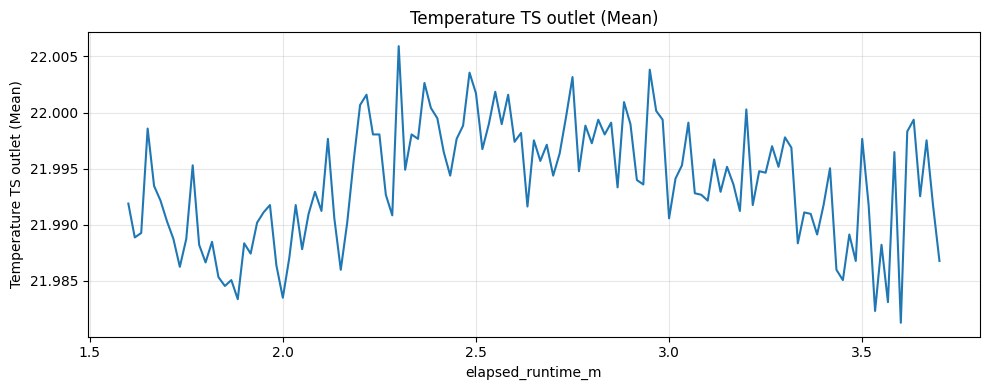

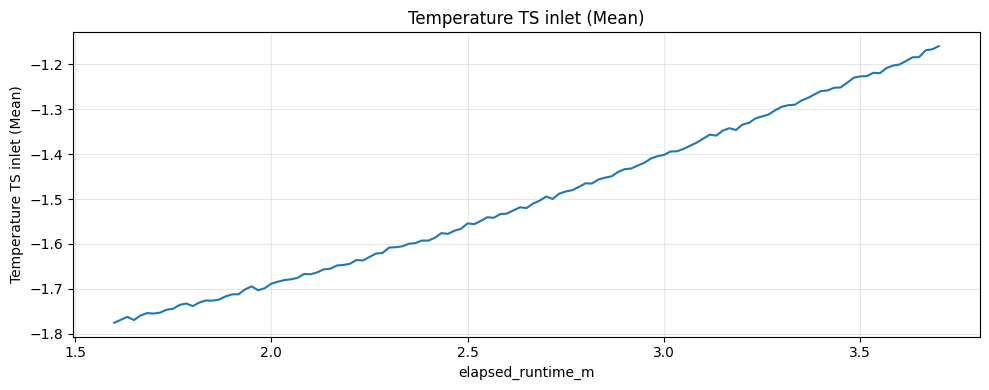

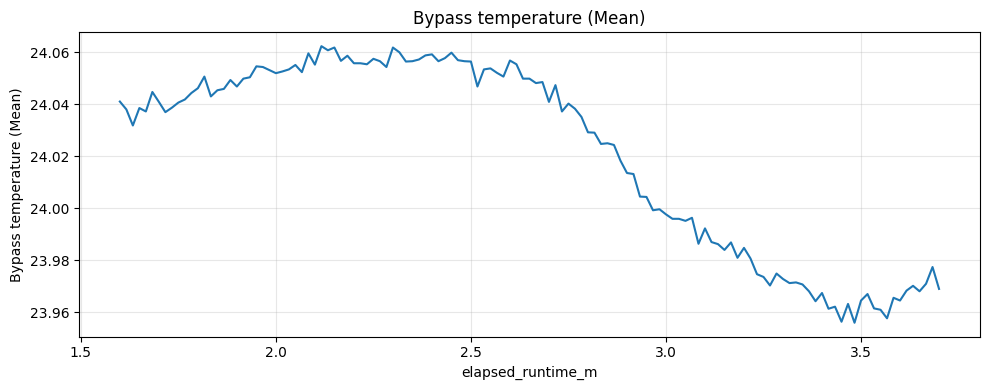

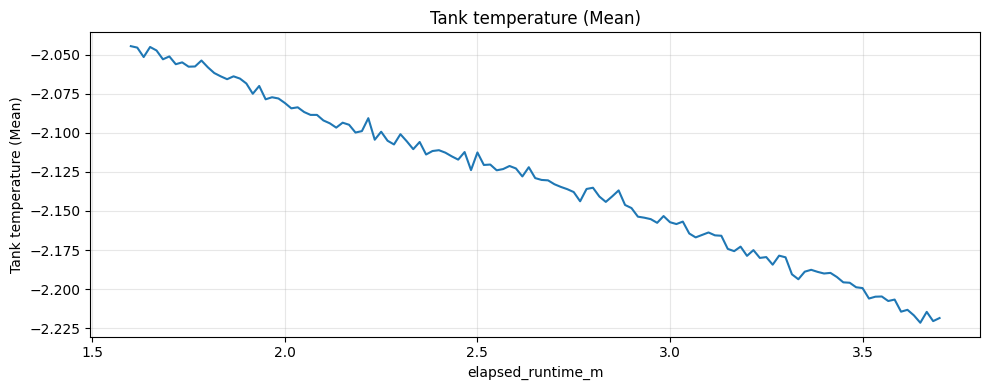

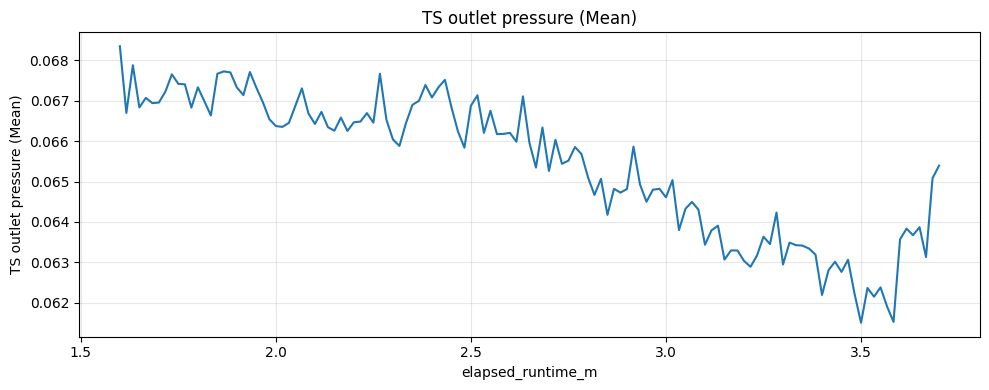

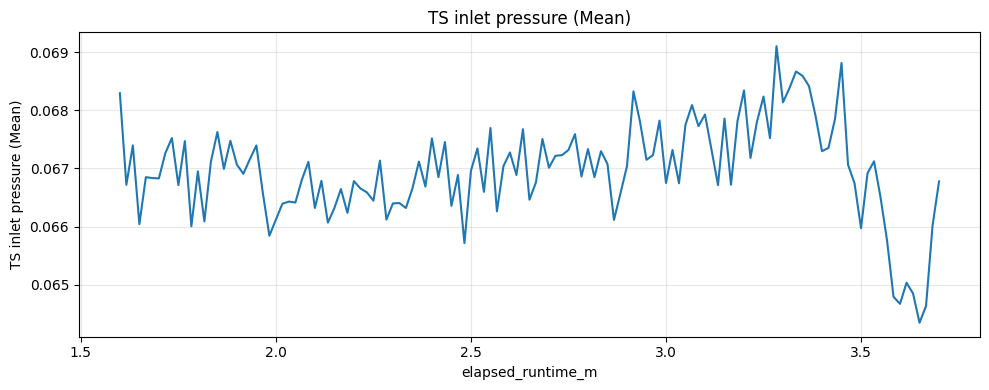

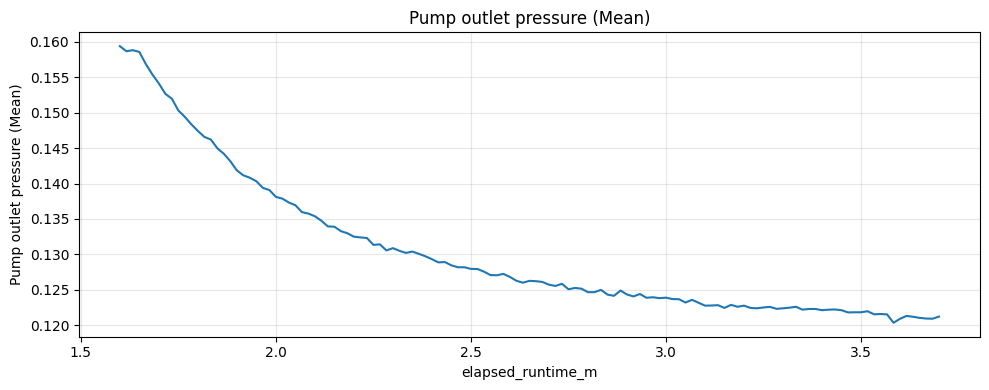

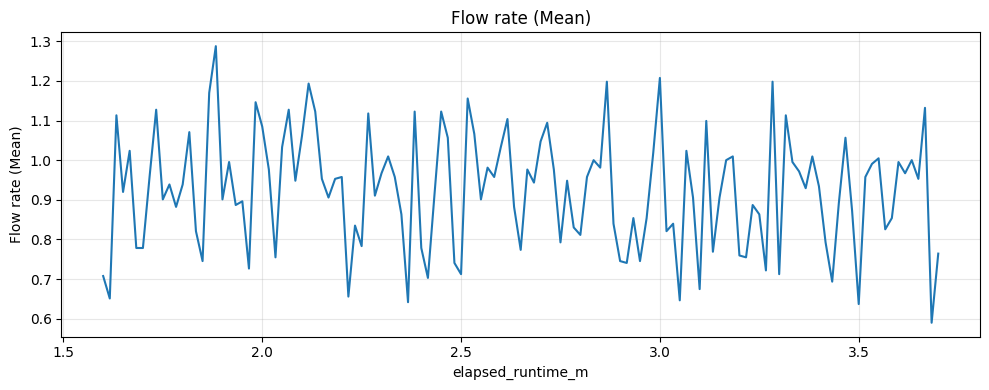

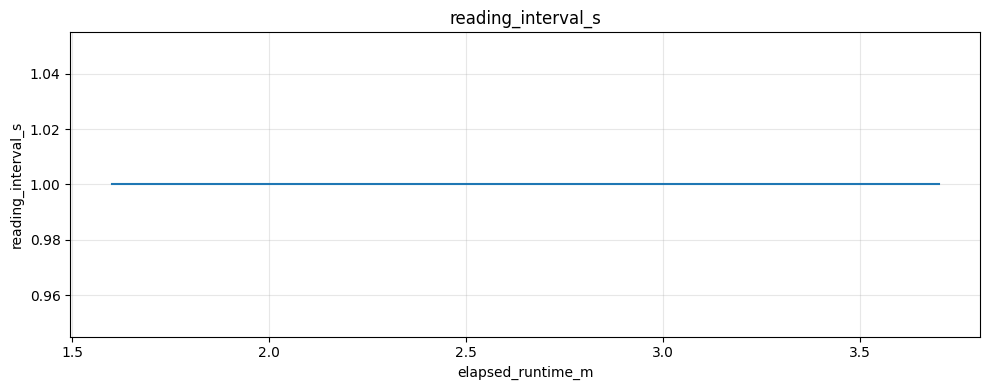

In [377]:
plot_all_timeseries(dffirst)

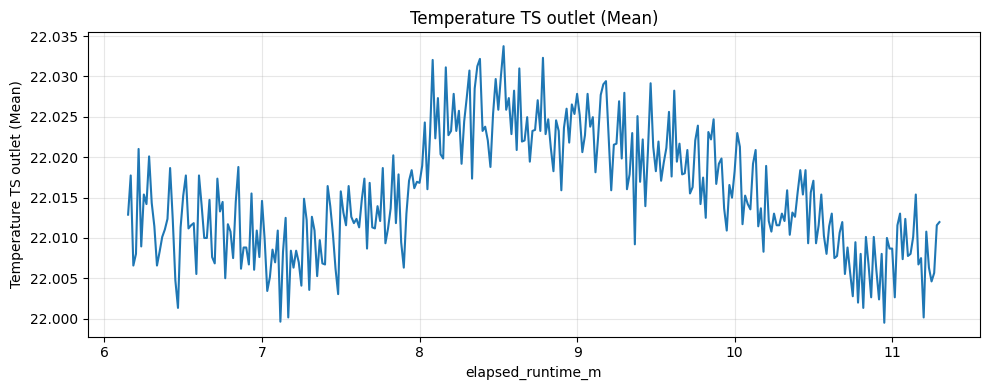

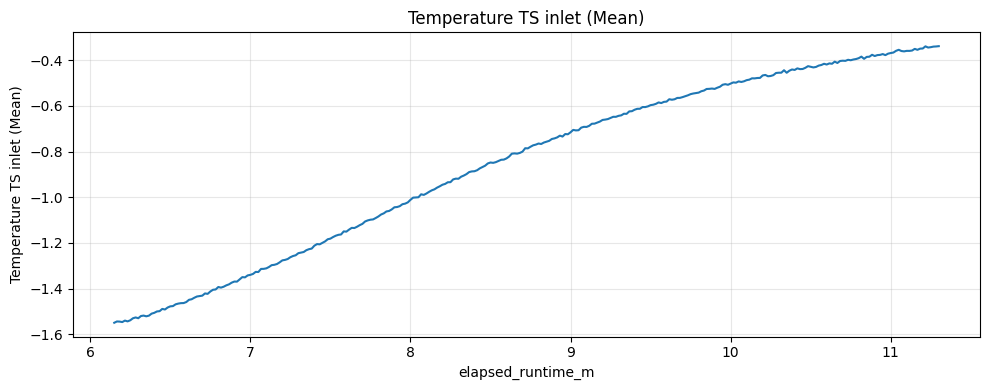

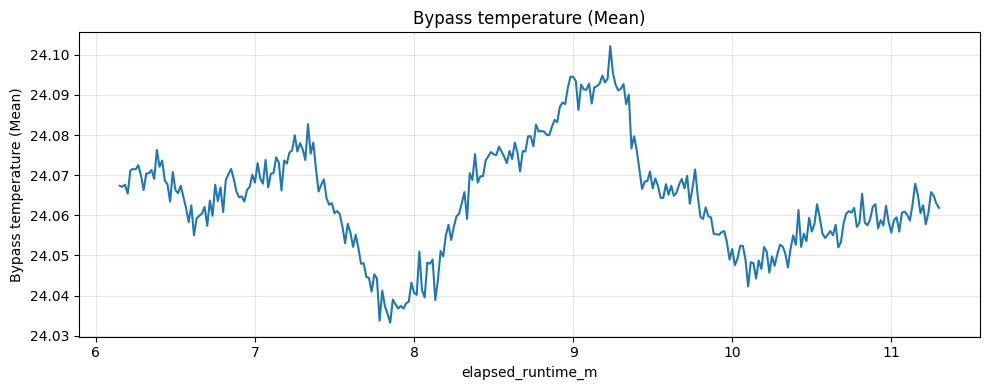

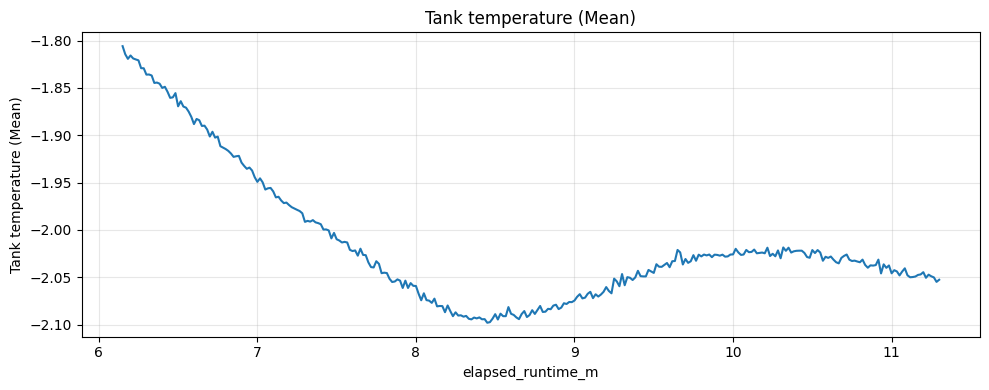

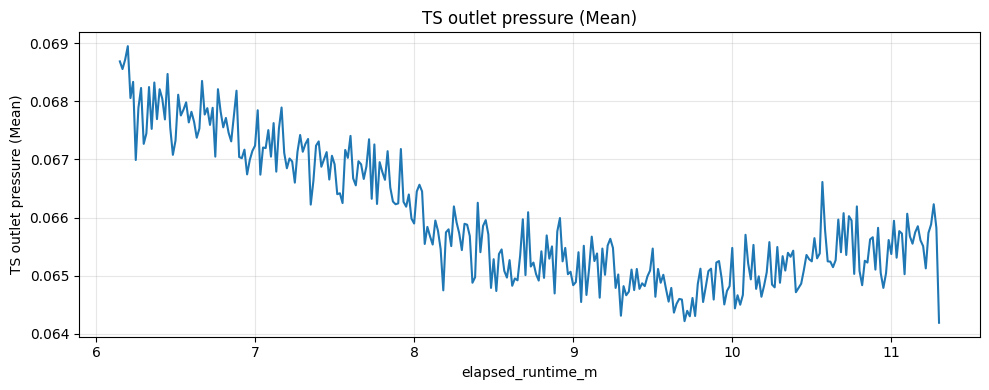

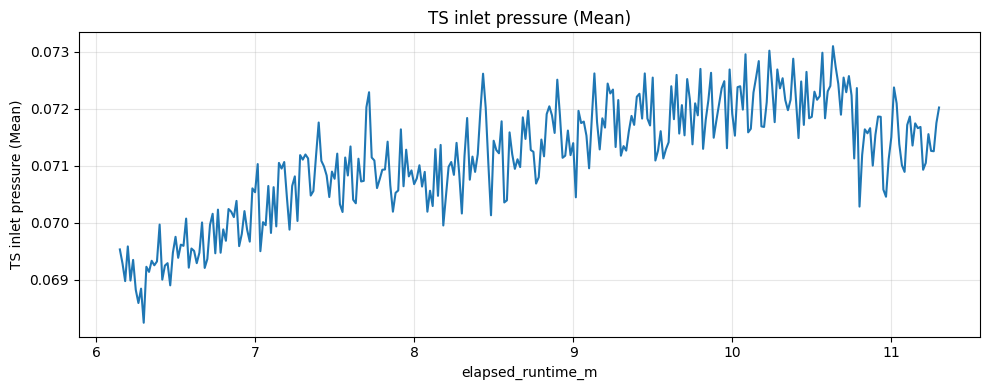

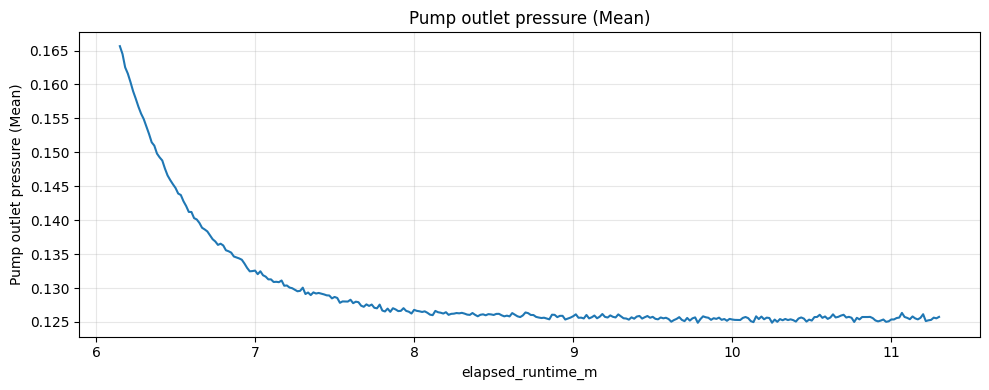

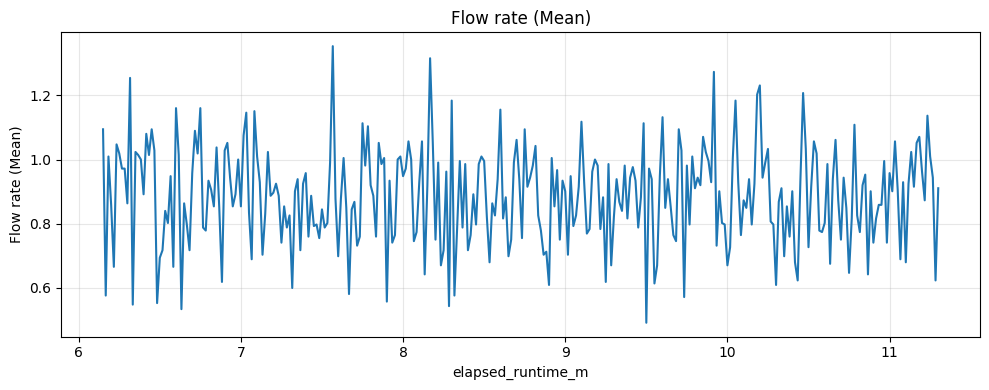

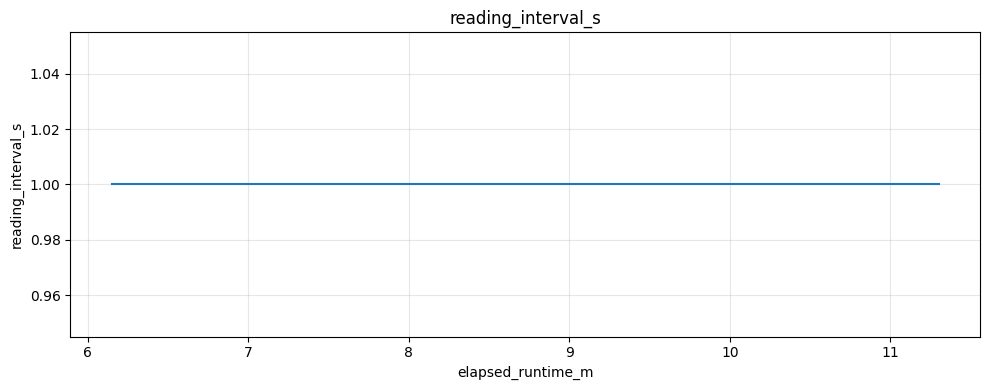

In [378]:
plot_all_timeseries(dfsnd)

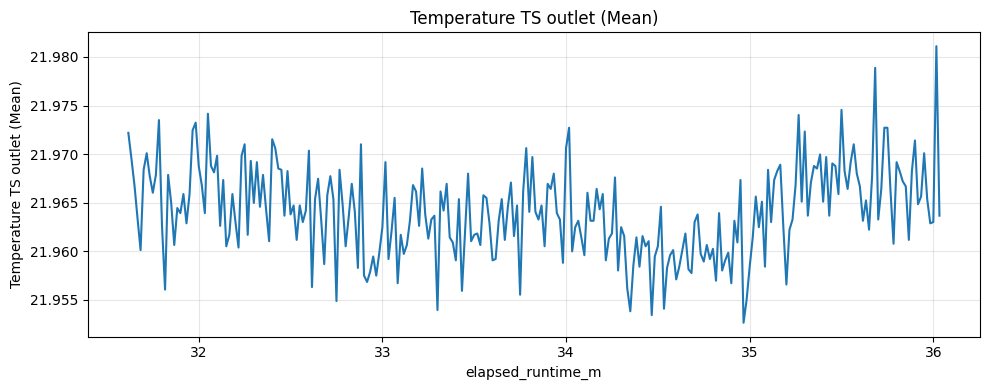

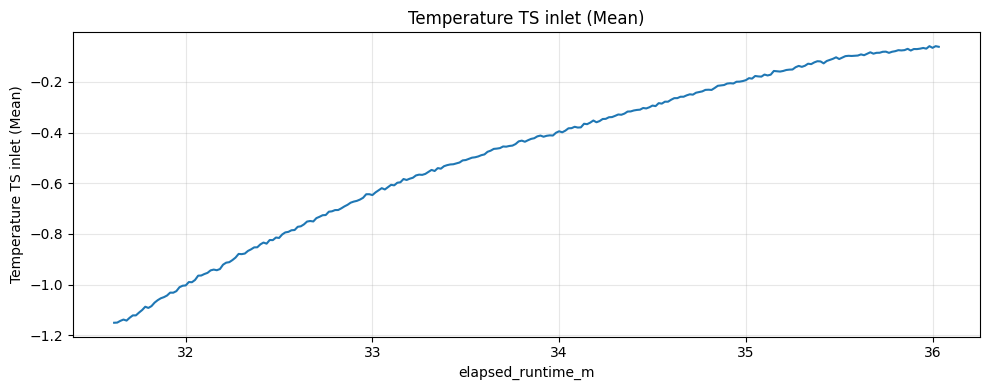

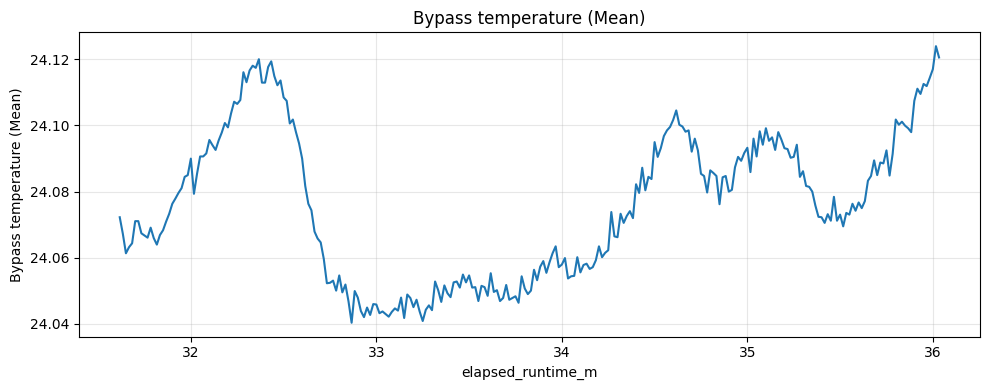

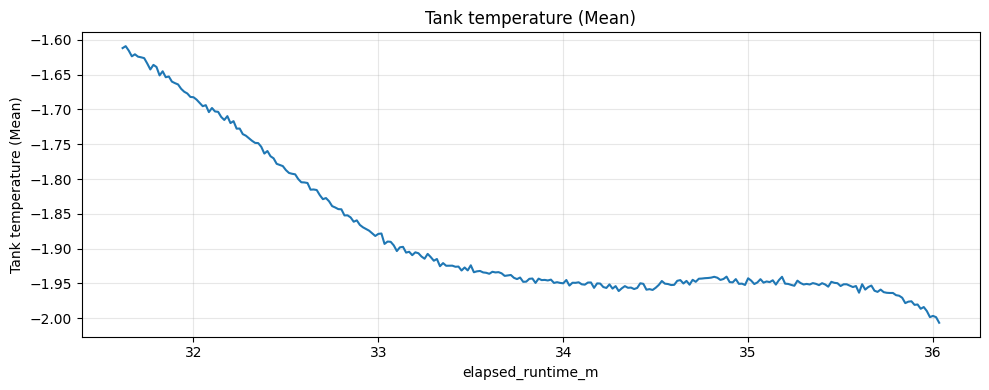

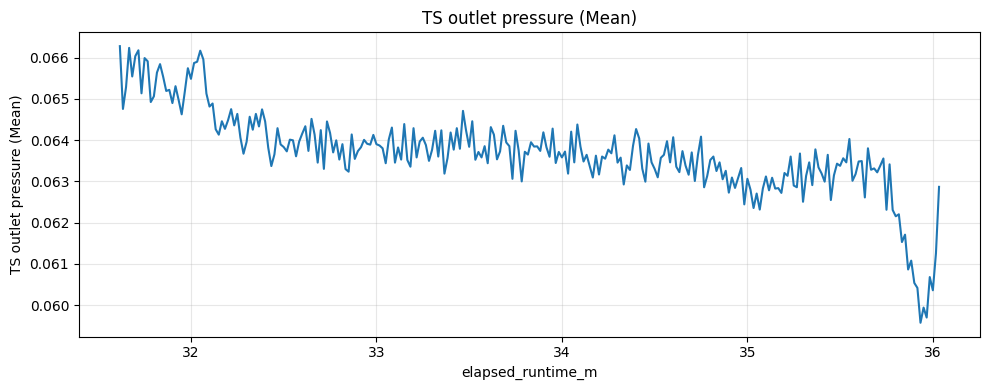

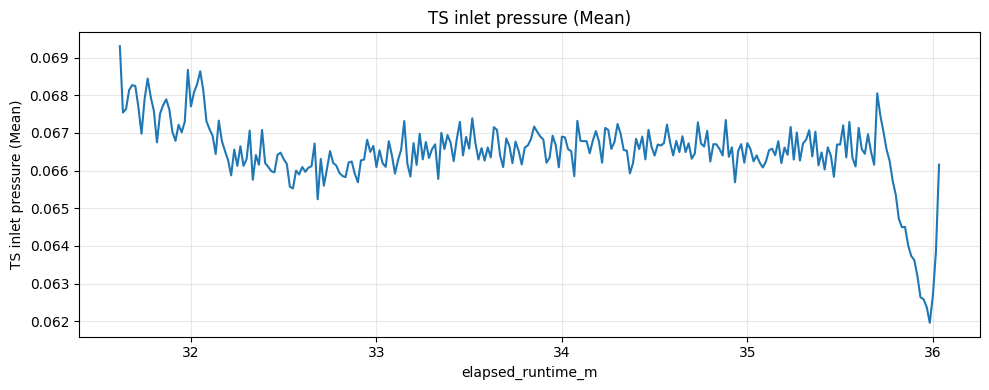

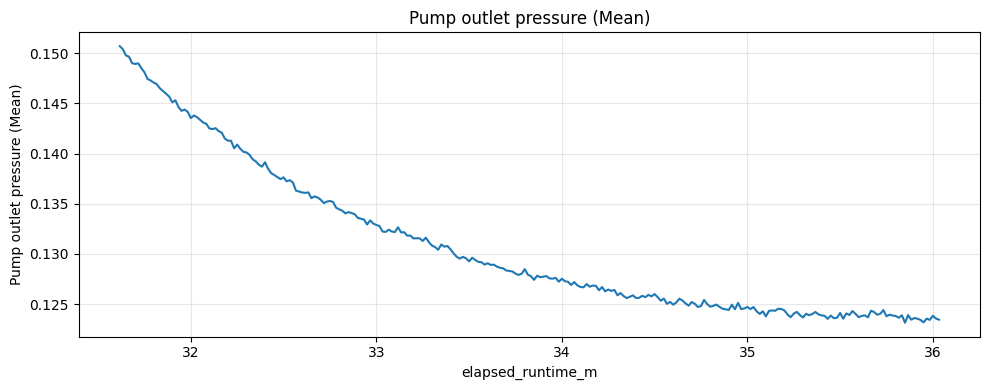

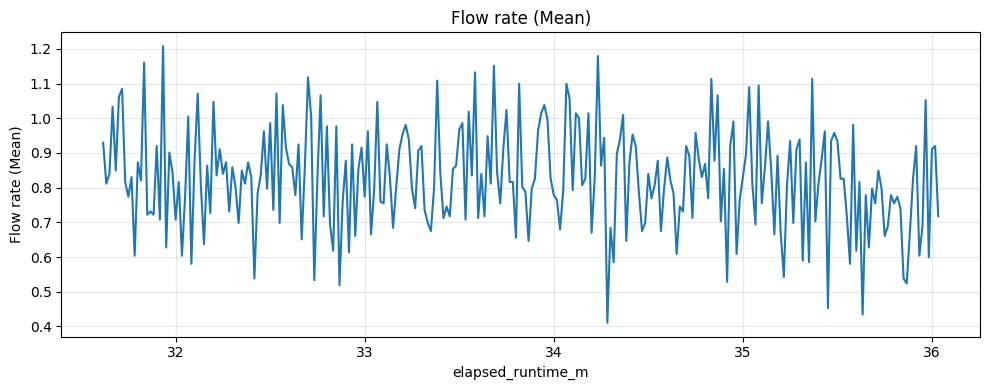

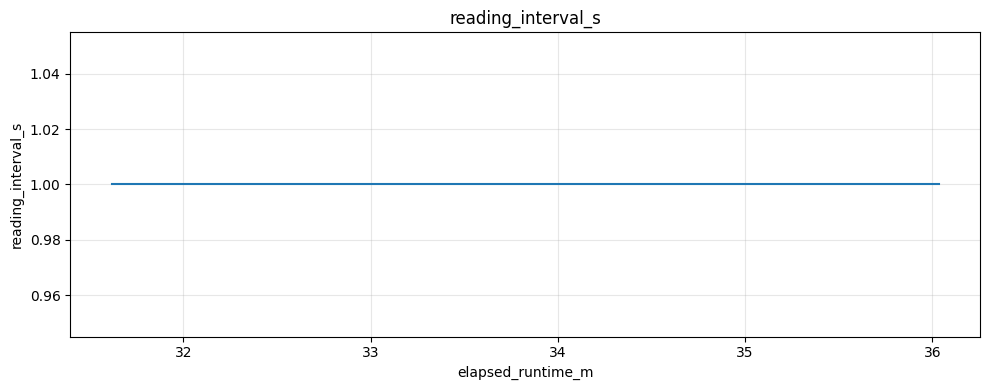

In [379]:
plot_all_timeseries(dfthrd)

## 29.06

### Init

In [43]:
df = df2906.copy()

In [25]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


In [44]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    7939
0.0       1
Name: count, dtype: int64

In [45]:
rename_map = {
    "Unnamed: 9": "dp TS in - TS out (Mean)",
    "Unnamed: 10": "dp pump out - TS in (Mean)",
}

df = df.rename(columns=rename_map)

### plotting

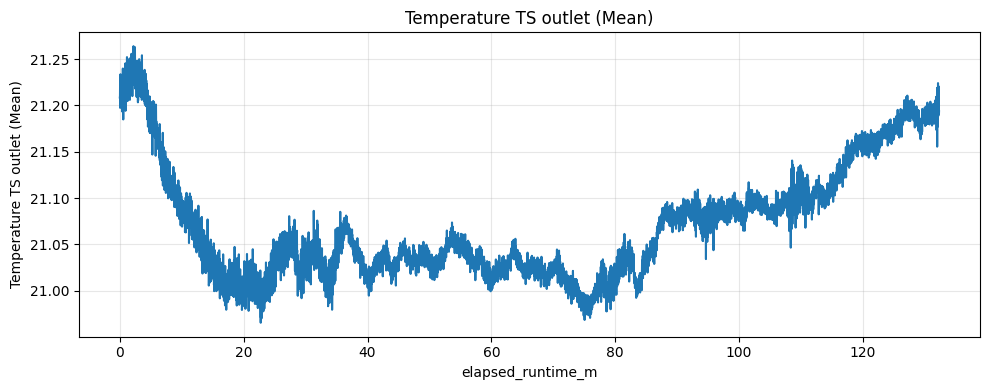

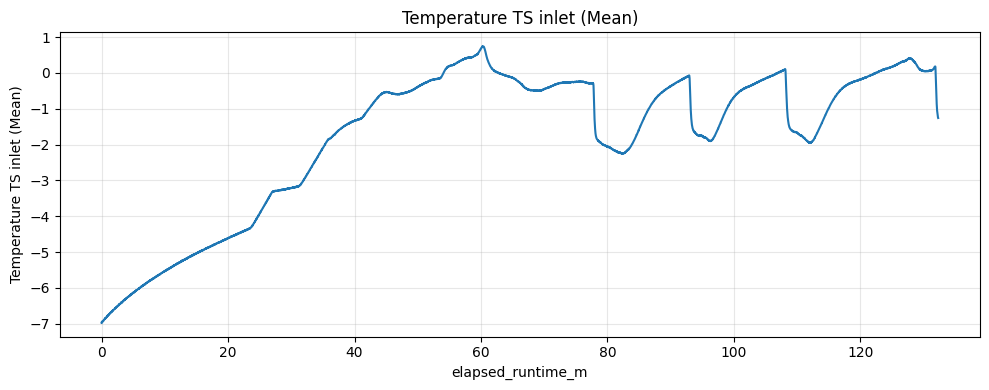

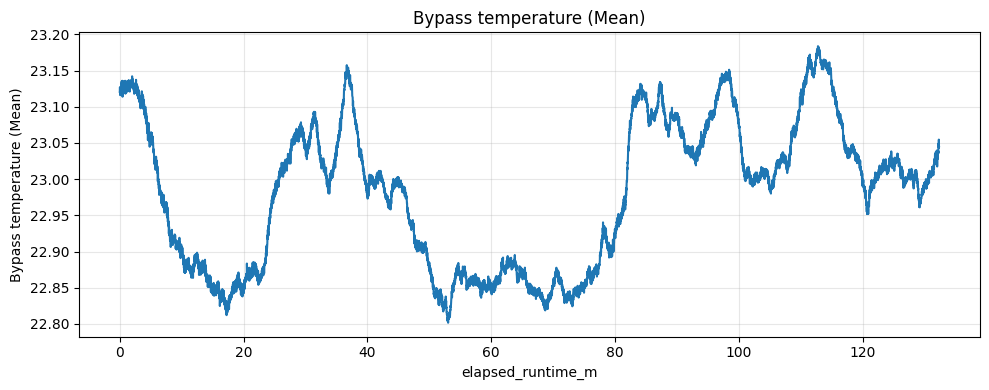

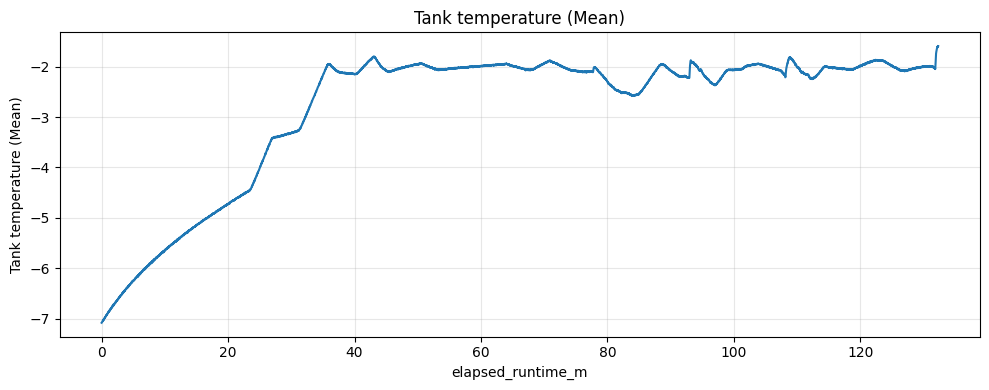

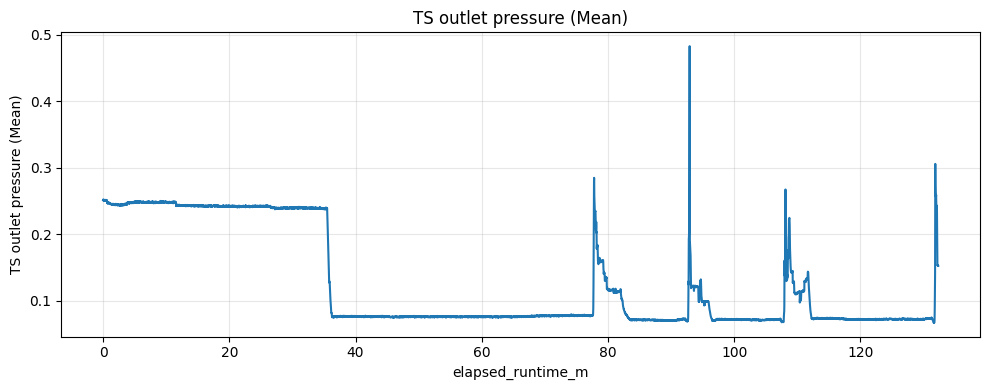

...

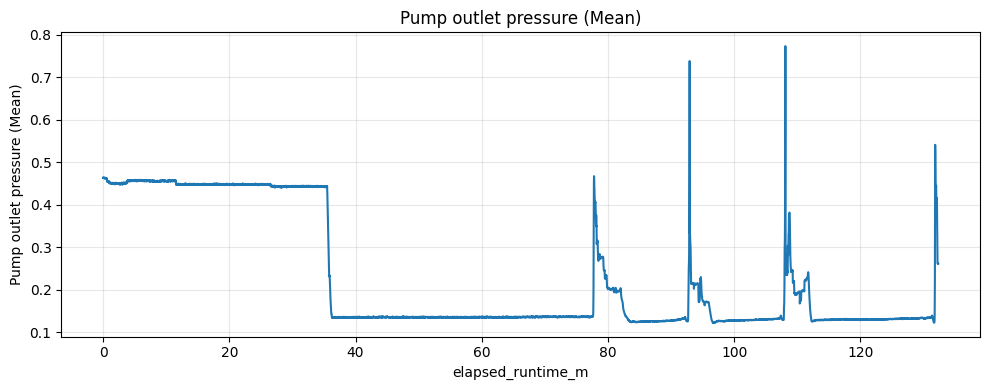

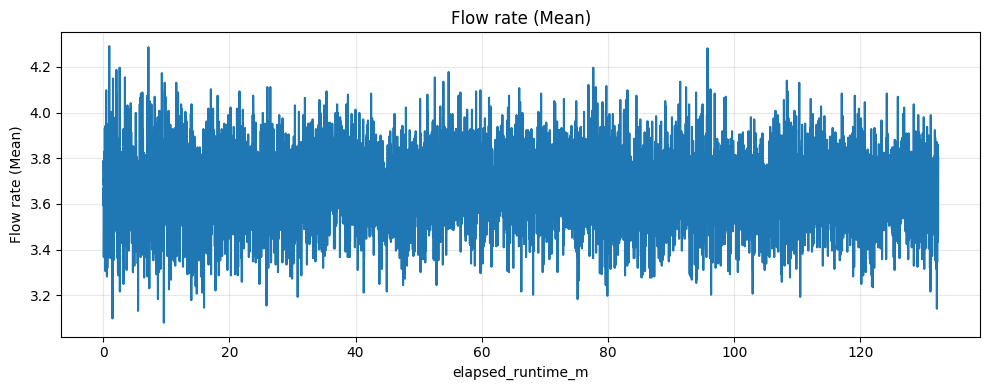

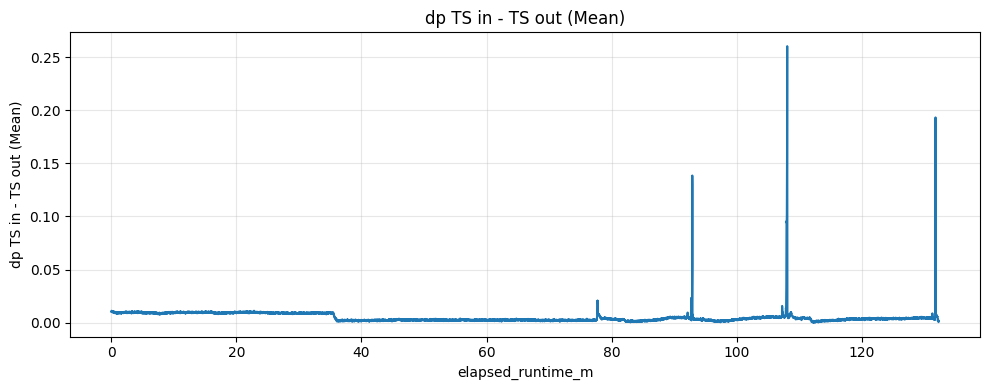

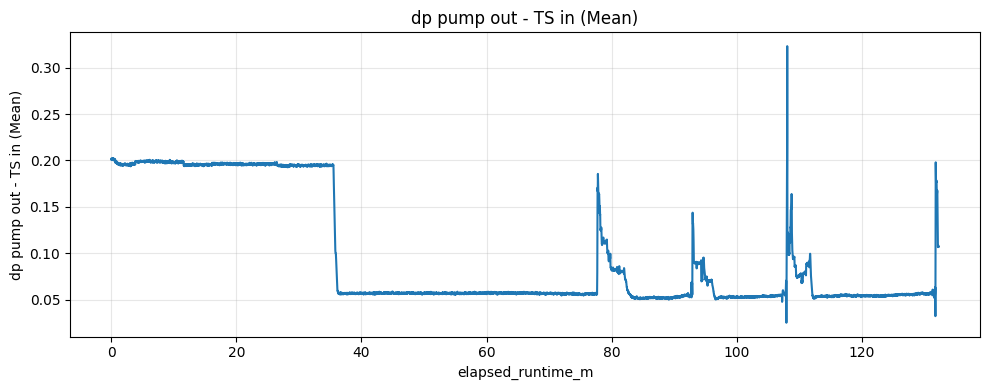

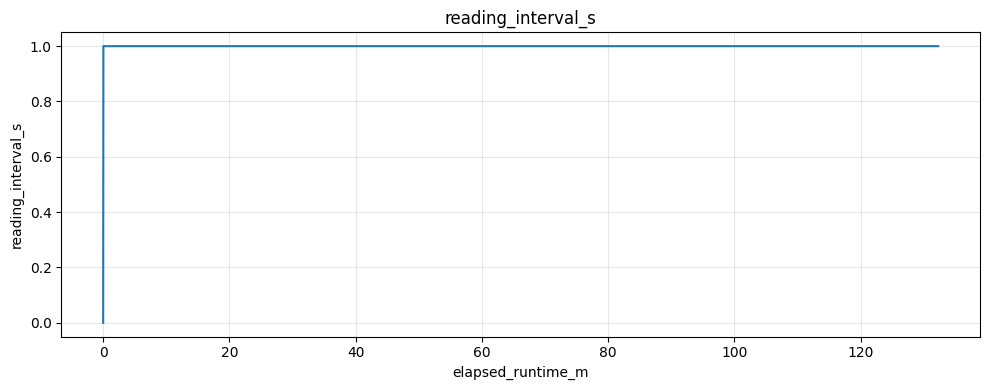

In [384]:
plot_all_timeseries(df)

Følge description sine timestamps? de starter isåfall rett etter spikes i pressure, stemmer dette, eller er spiken i pressure der blokkeringen oppstår?

4 runs derav 3 siste har blokking ifølge description

### snipping

In [46]:
df.drop(columns=['dp TS in - TS out (Mean)', 'dp pump out - TS in (Mean)'], inplace=True)

fra description: Four runs were conducted; blockage was achieved in the second, third, and fourth runs.

Run timecodes:

14:33:05 – 15:14:26

15:20:20 – 15:28:59

15:33:24 – 15:44:06

15:49:03 – 16:08:07


In [47]:
start = find_index_at_timestamp(df, 143305)
end = find_index_at_timestamp(df, 151426)
dffirst = snip_df_at_timecode(df, start, end)

In [30]:
start = find_index_at_timestamp(df, 152020)
end = find_index_at_timestamp(df, 152859)
dfsnd = snip_df_at_timecode(df, start, end)

In [31]:
start = find_index_at_timestamp(df, 153324)
end = find_index_at_timestamp(df, 154406)
dfthrd = snip_df_at_timecode(df, start, end)

In [32]:
start = find_index_at_timestamp(df, 154903)
end = find_index_at_timestamp(df, 160807)
dffrth = snip_df_at_timecode(df, start, end)

In [390]:
dffirst.to_csv('../data/split/no_plug/2906-1.csv', index=False)
dfsnd.to_csv('../data/split/plug/2906-2.csv', index=False)
dfthrd.to_csv('../data/split/plug/2906-3.csv', index=False)
dffrth.to_csv('../data/split/plug/2906-4.csv', index=False)

### Plot after snip

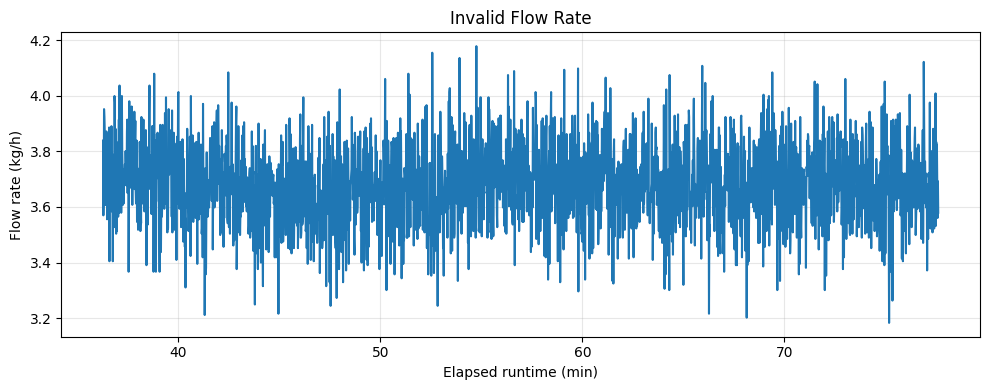

In [48]:
plot_iflow_rate(dffirst)

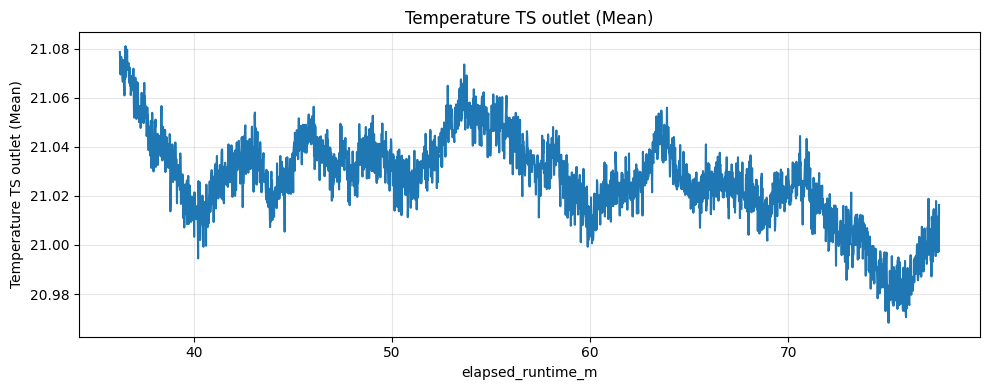

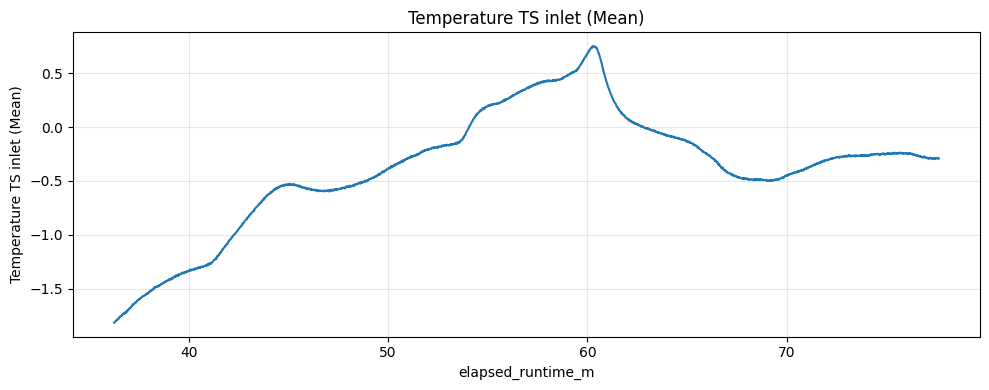

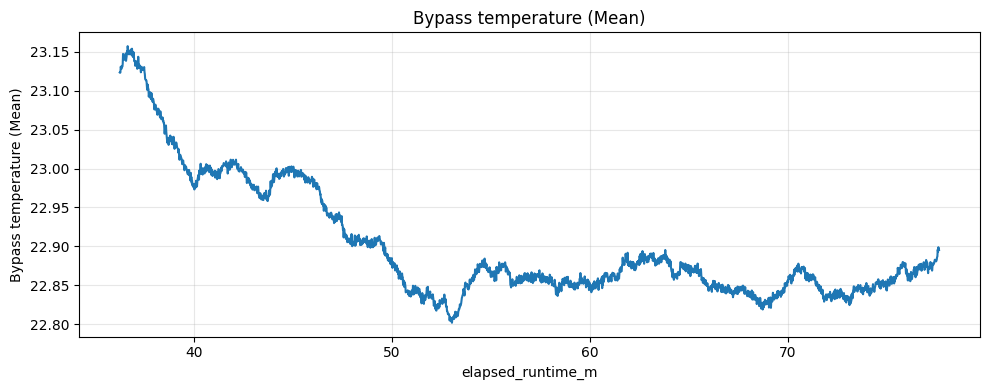

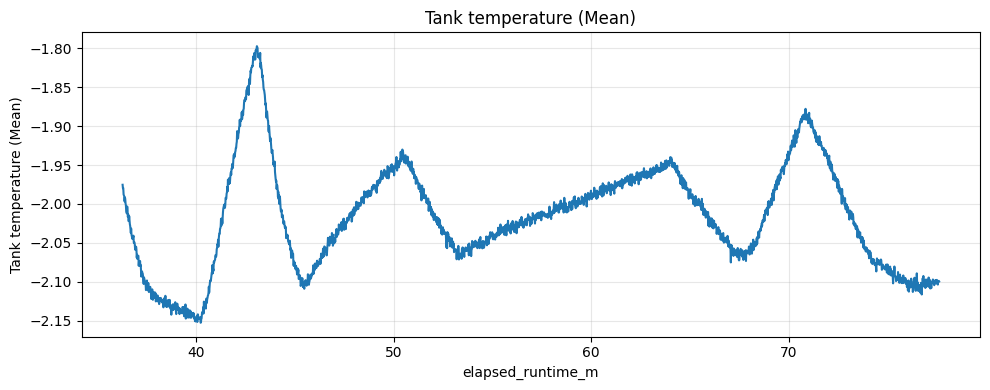

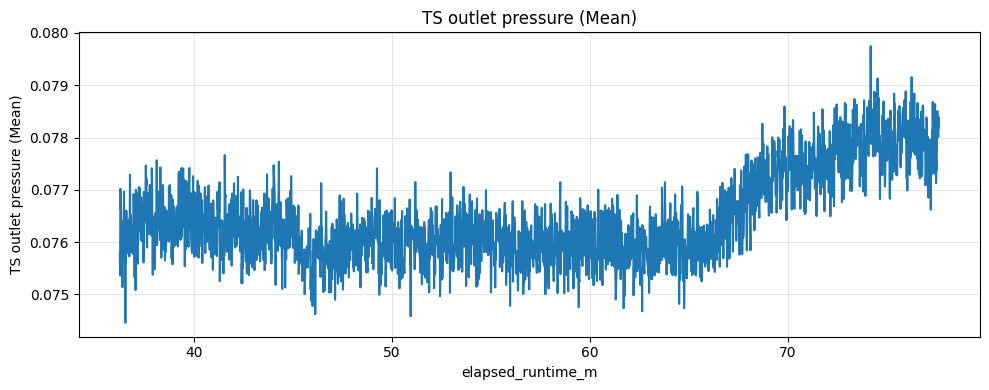

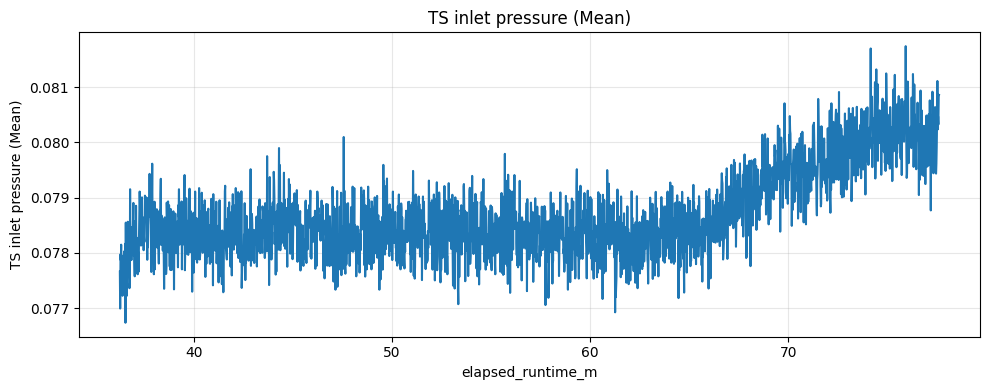

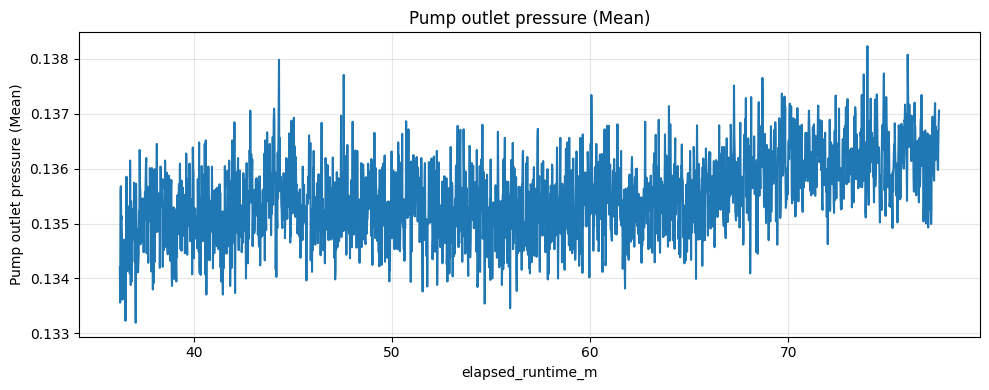

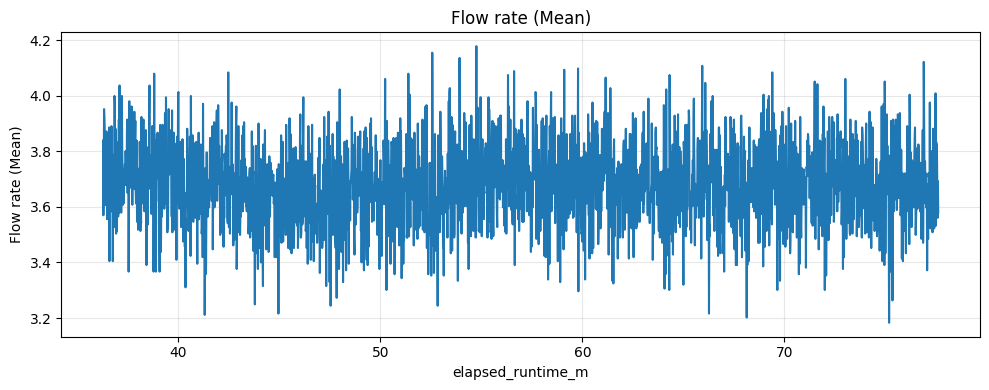

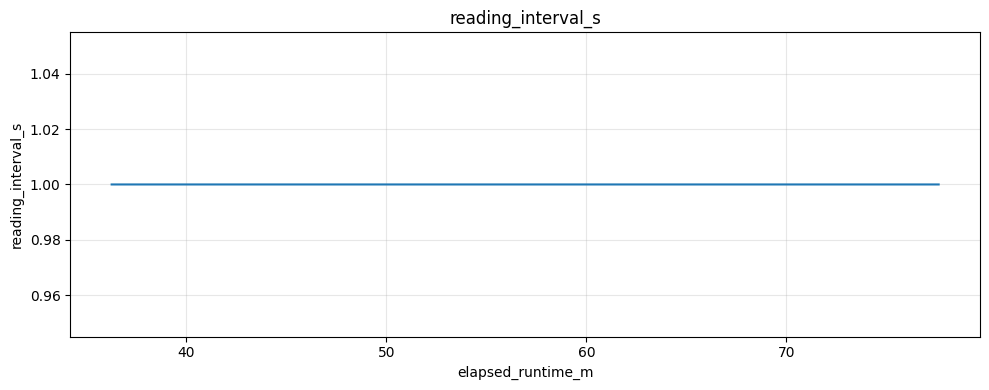

In [391]:
plot_all_timeseries(dffirst)

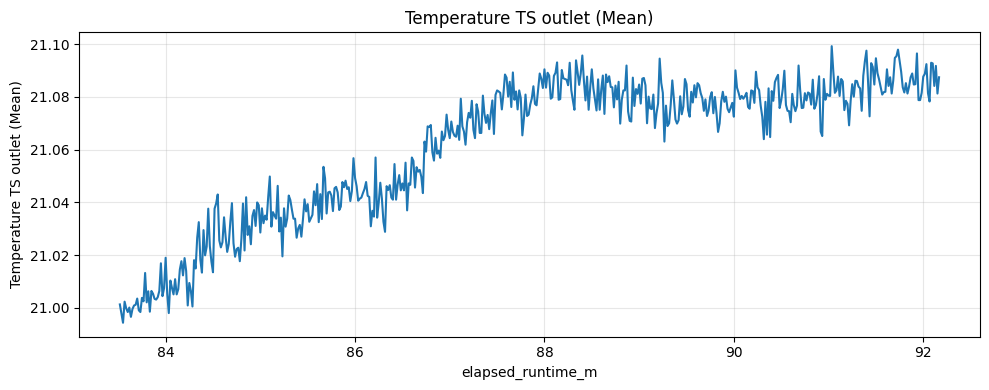

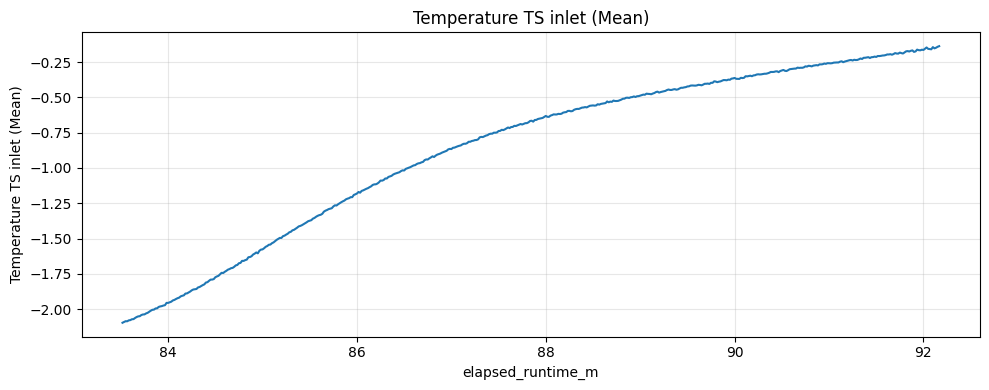

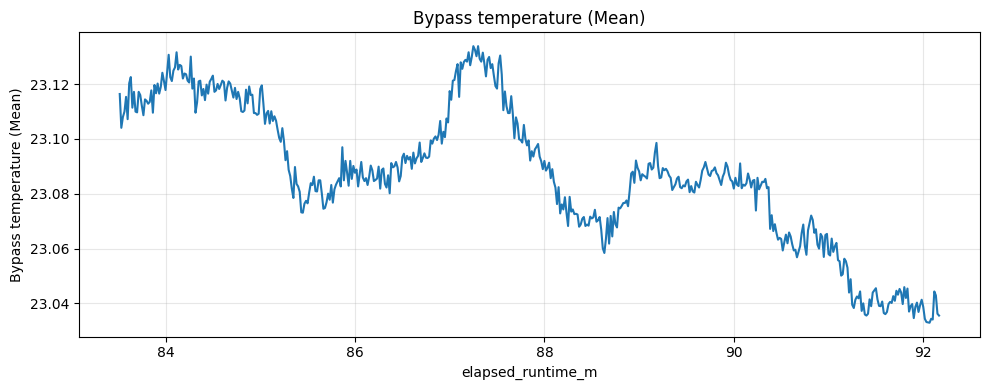

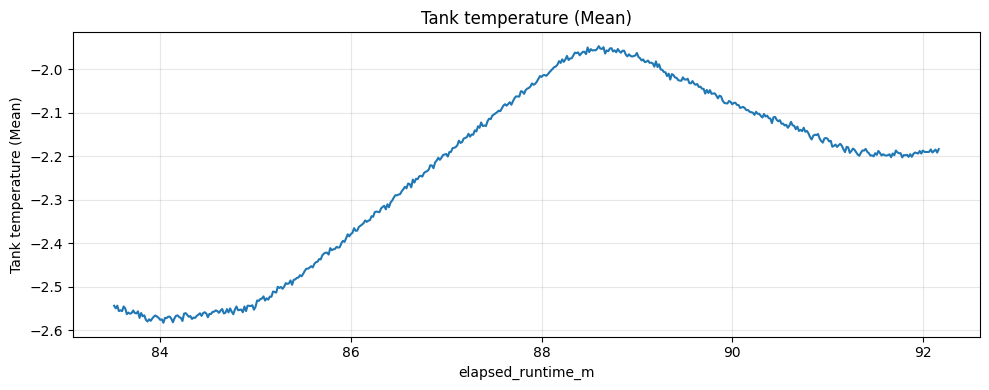

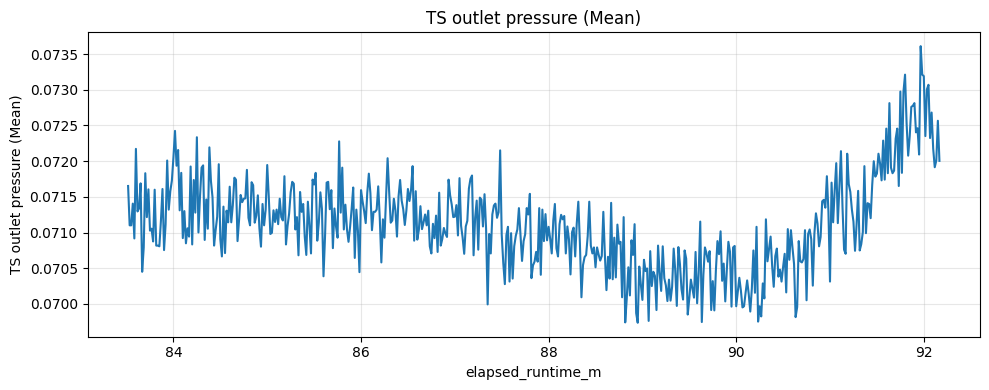

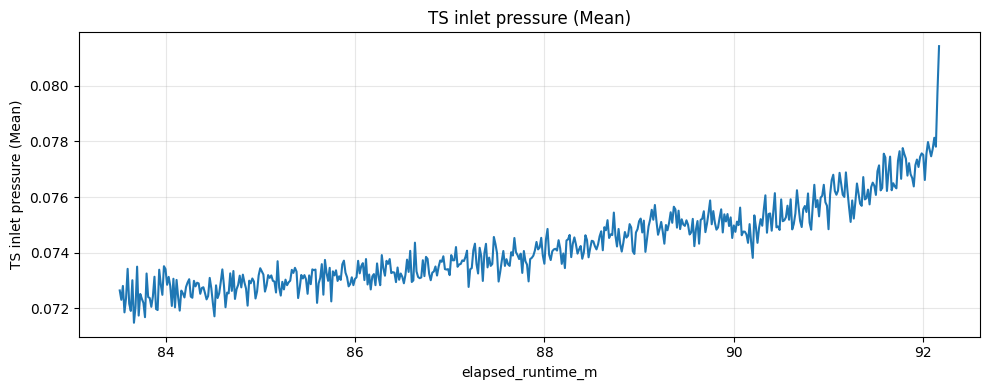

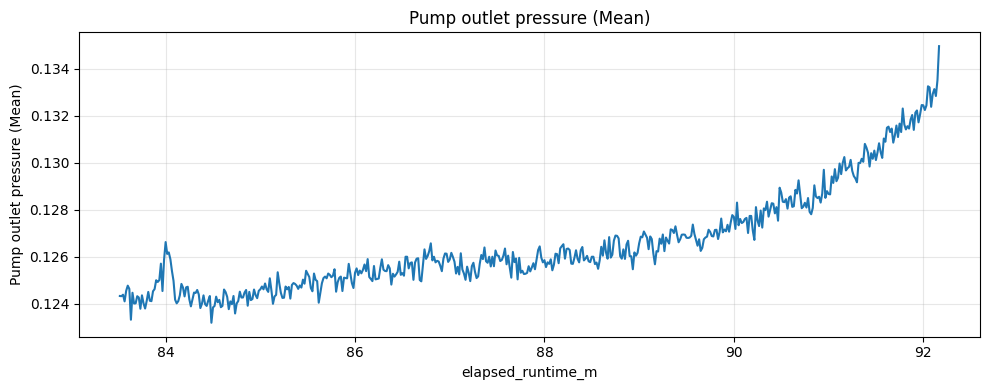

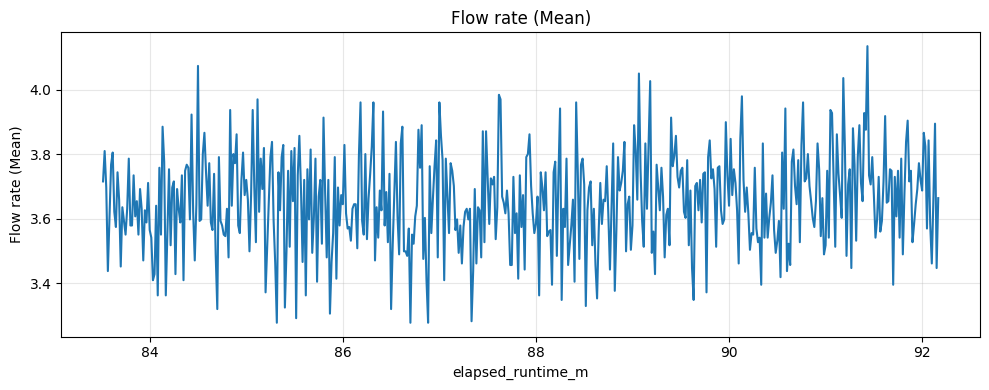

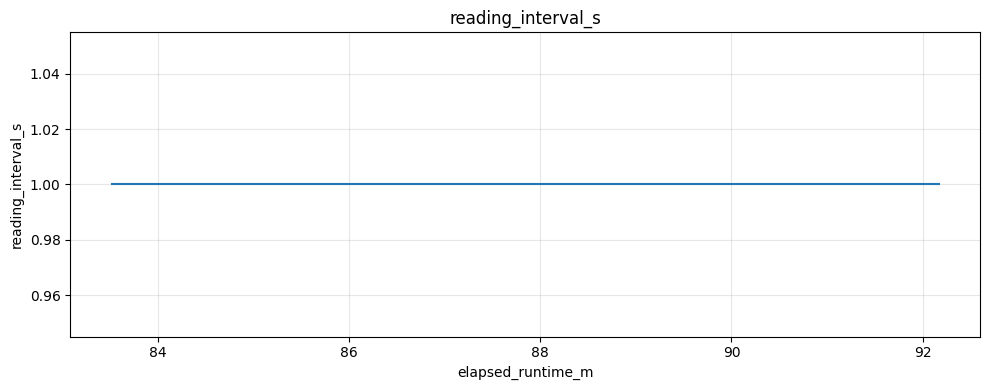

In [392]:
plot_all_timeseries(dfsnd)

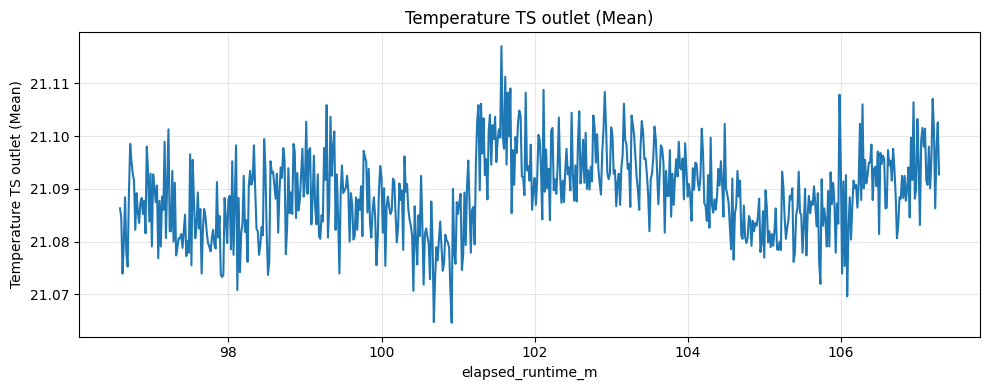

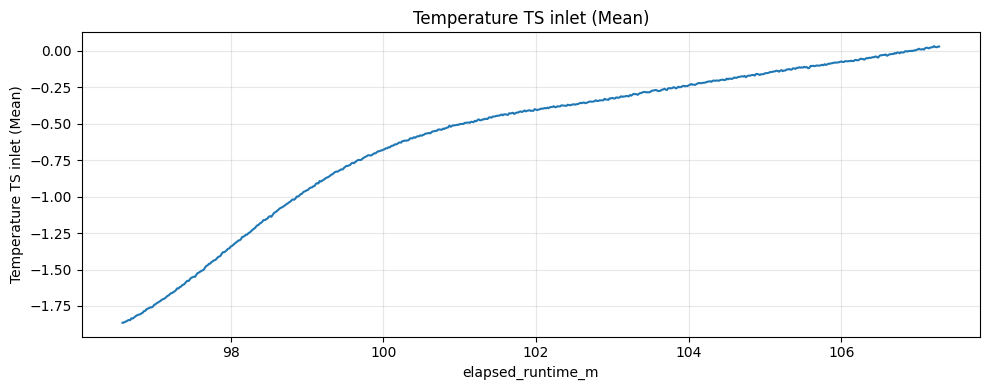

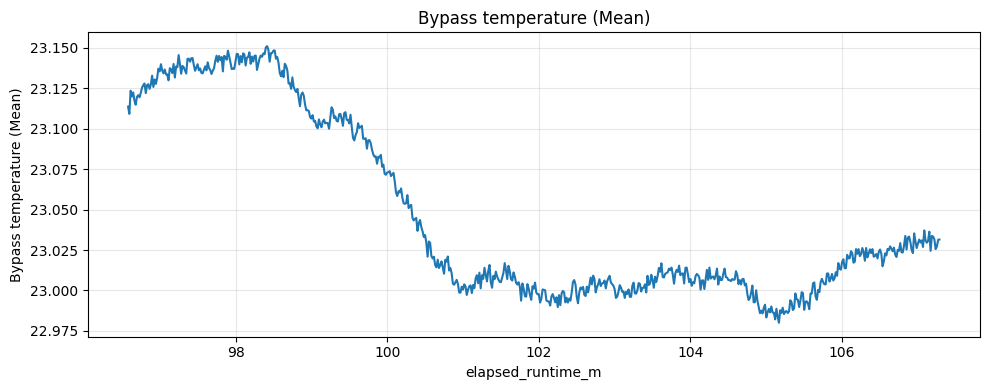

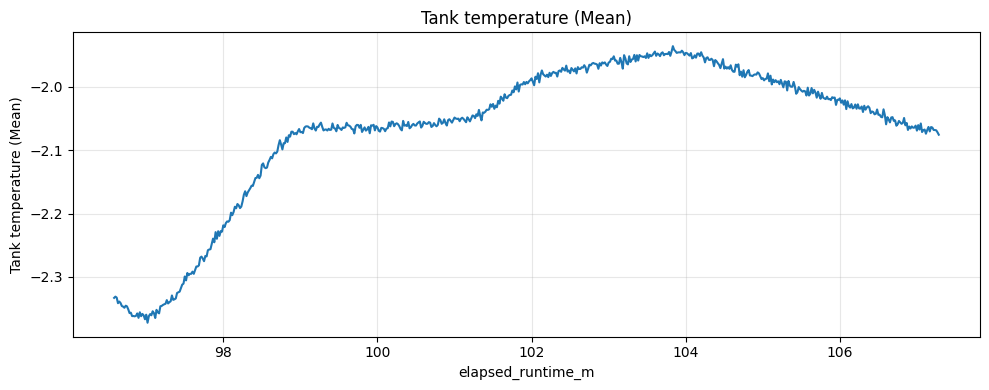

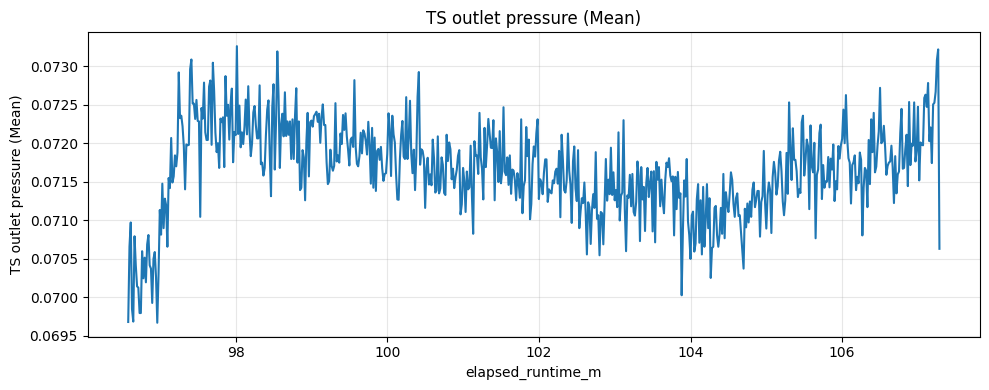

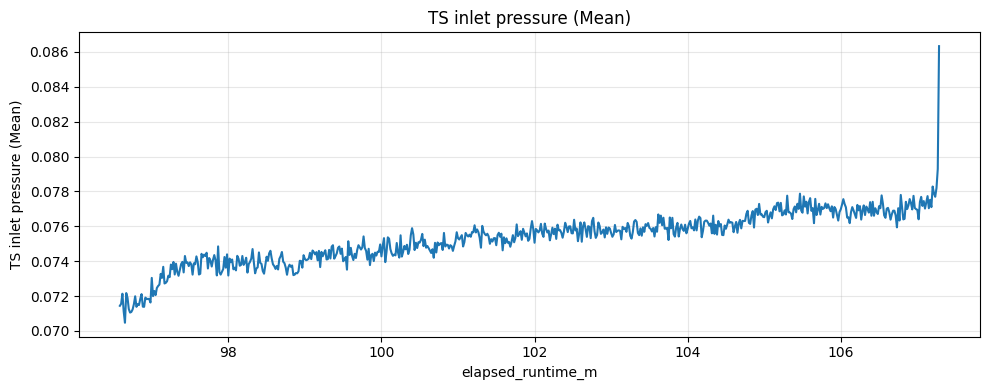

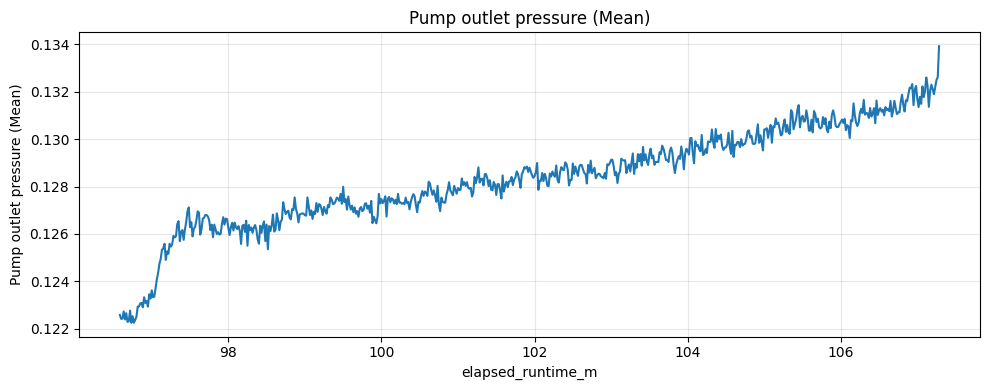

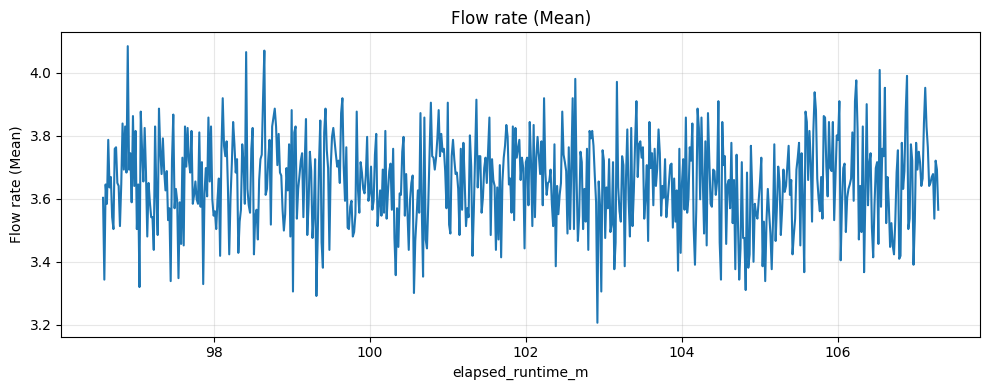

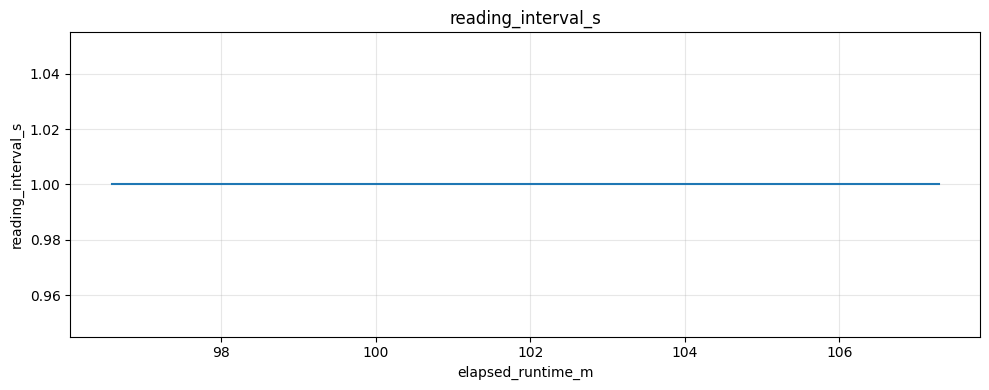

In [393]:
plot_all_timeseries(dfthrd)

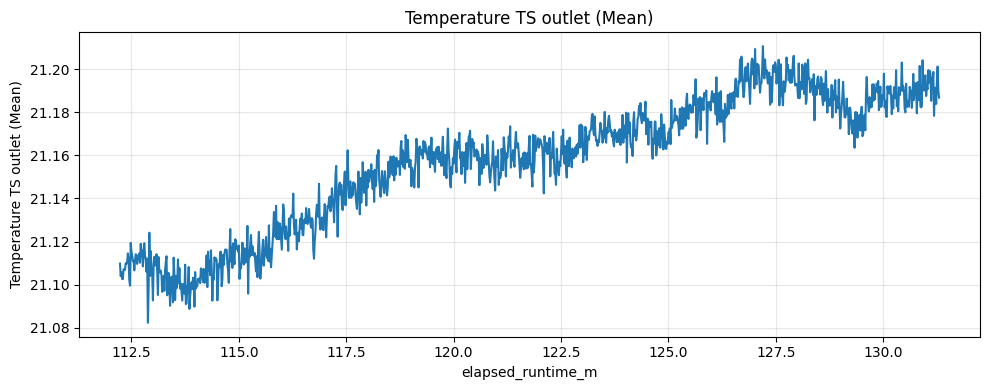

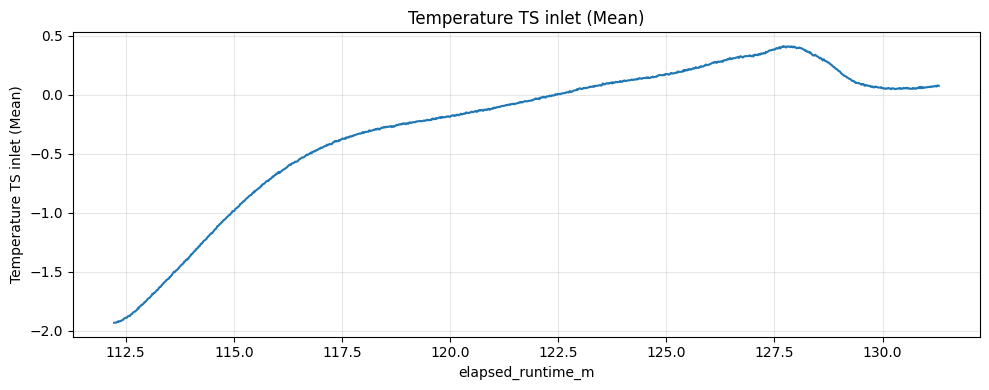

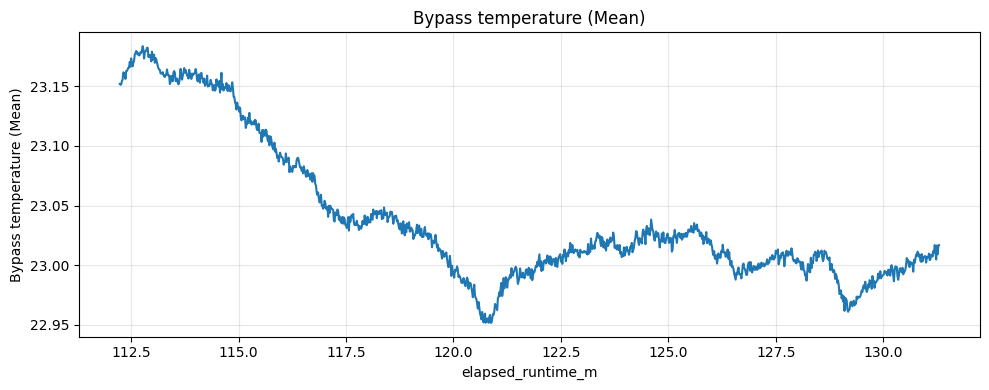

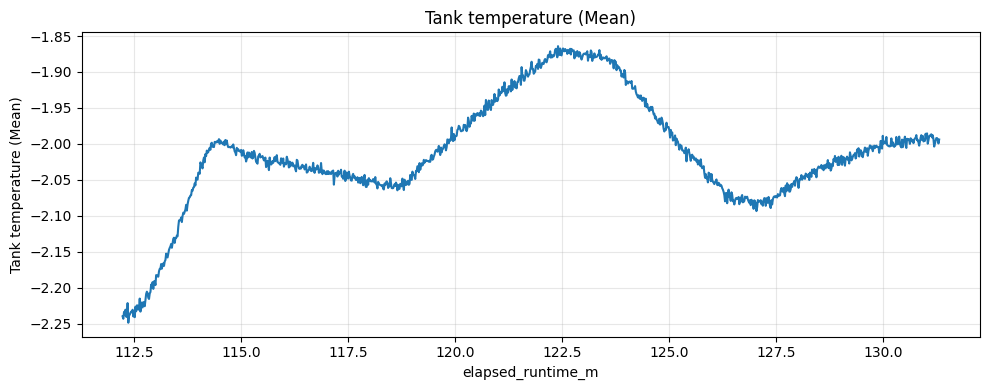

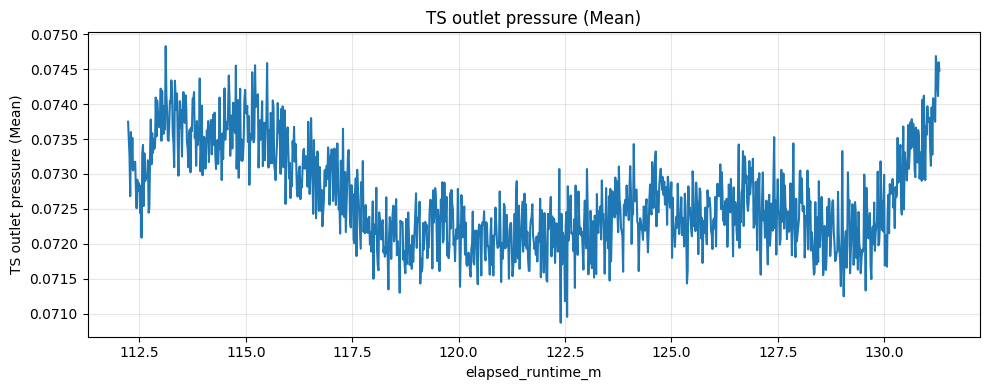

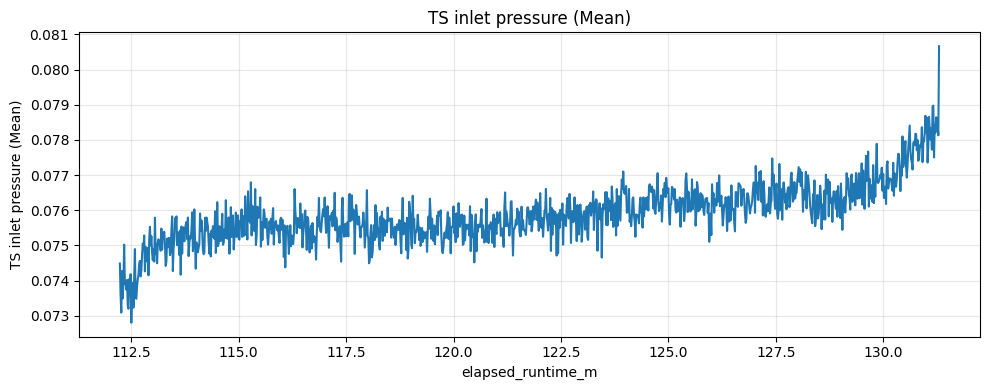

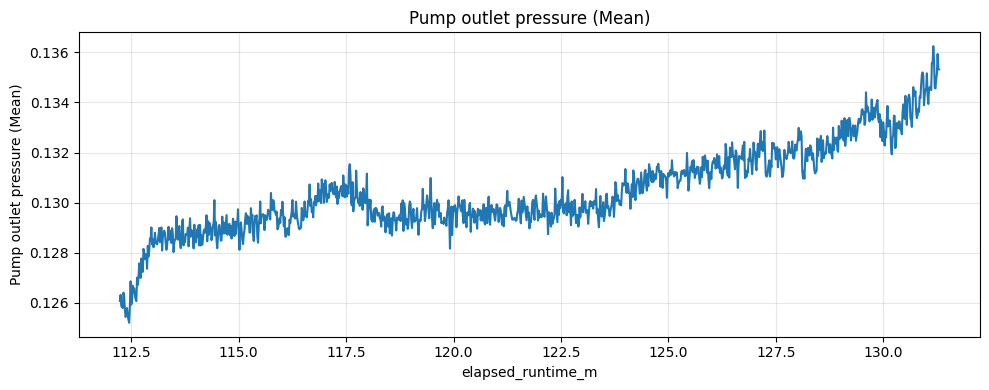

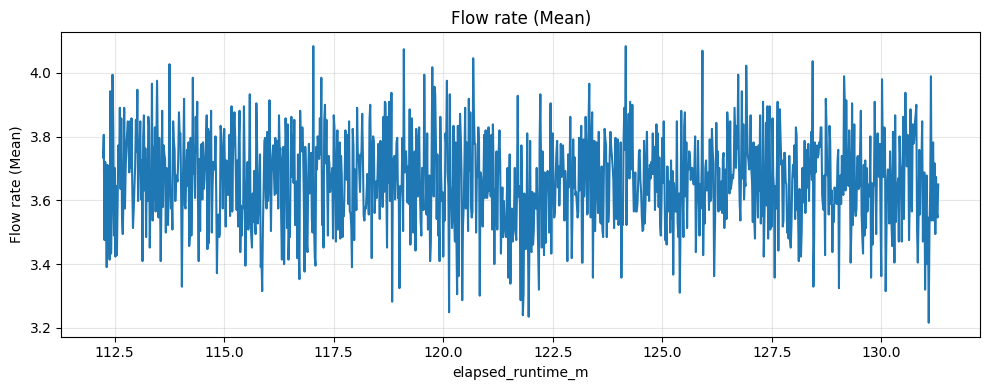

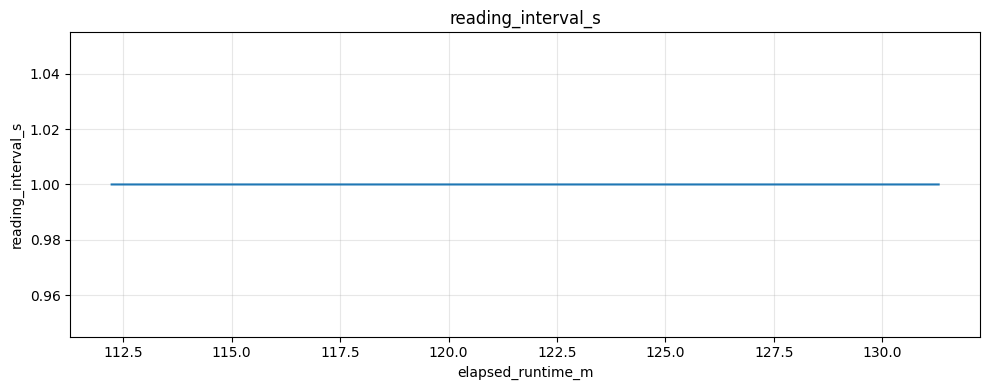

In [394]:
plot_all_timeseries(dffrth)

## 30.06

### Init

In [395]:
df = df3006.copy()

In [396]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


In [397]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    16793
0.0        1
Name: count, dtype: int64

In [398]:
rename_map = {
    "Unnamed: 9": "dp TS in - TS out (Mean)",
    "Unnamed: 10": "dp pump out - TS in (Mean)",
}

df = df.rename(columns=rename_map)

### plotting

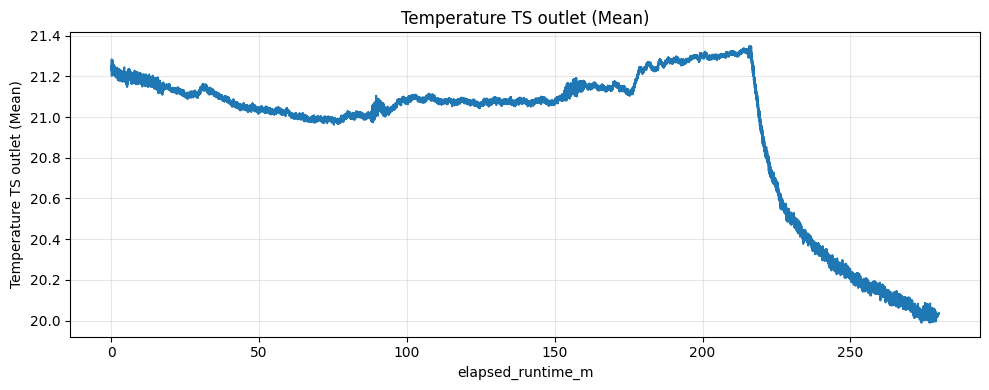

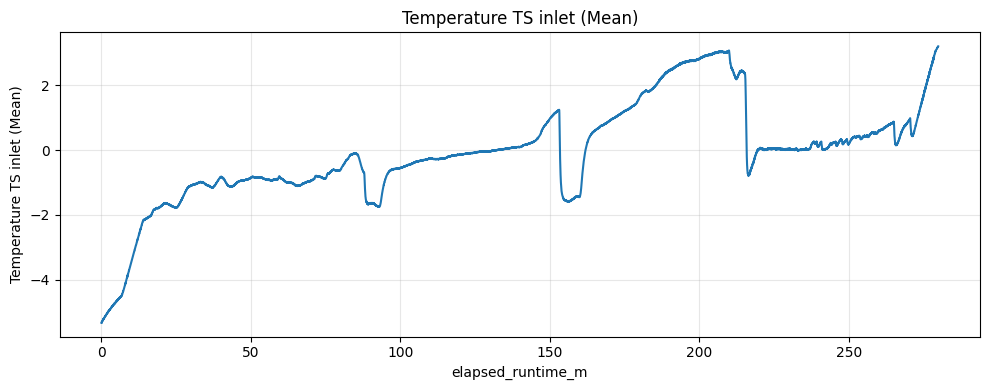

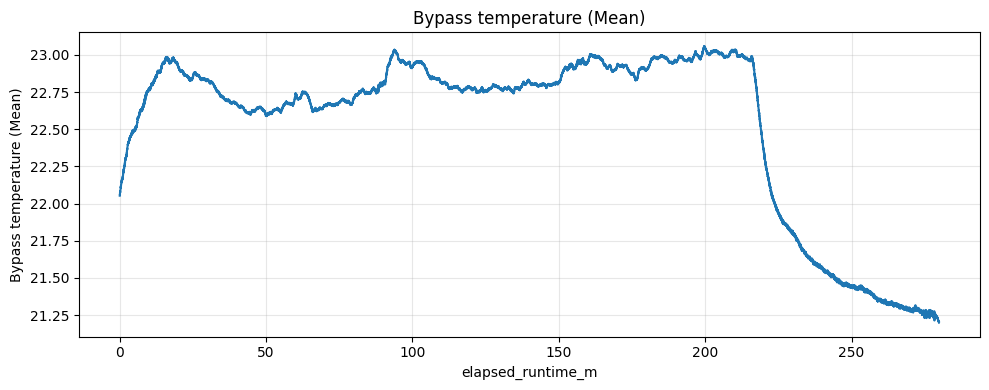

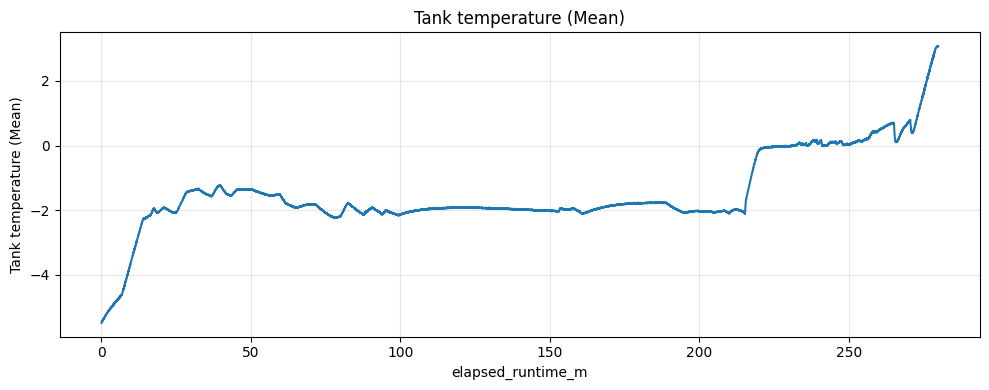

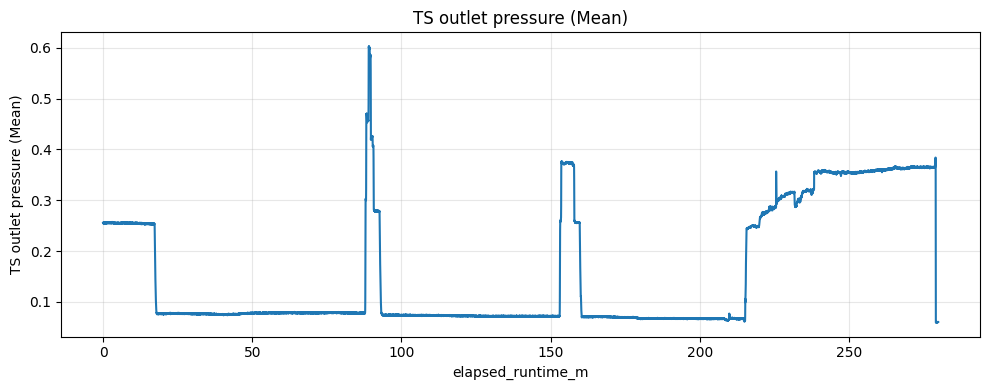

...

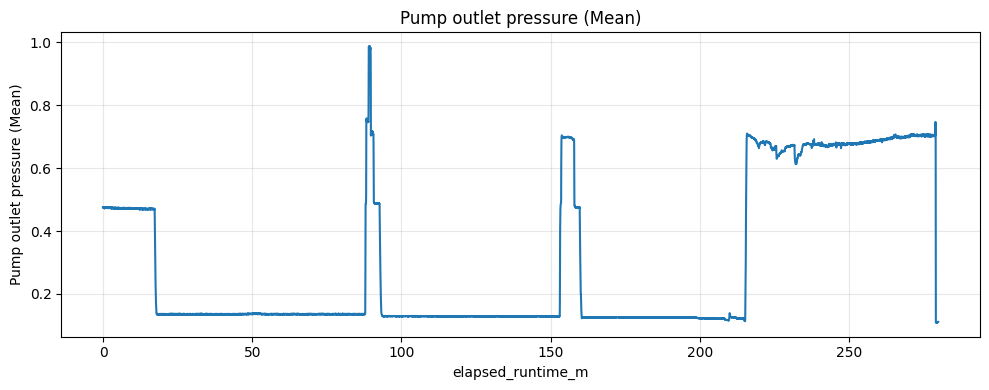

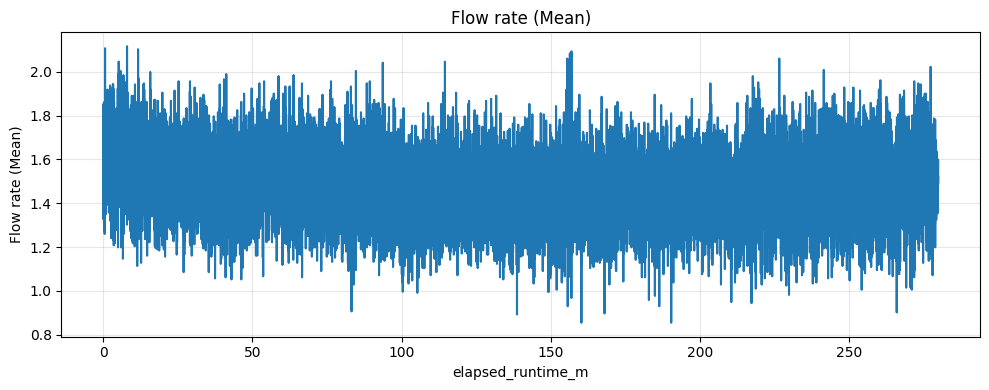

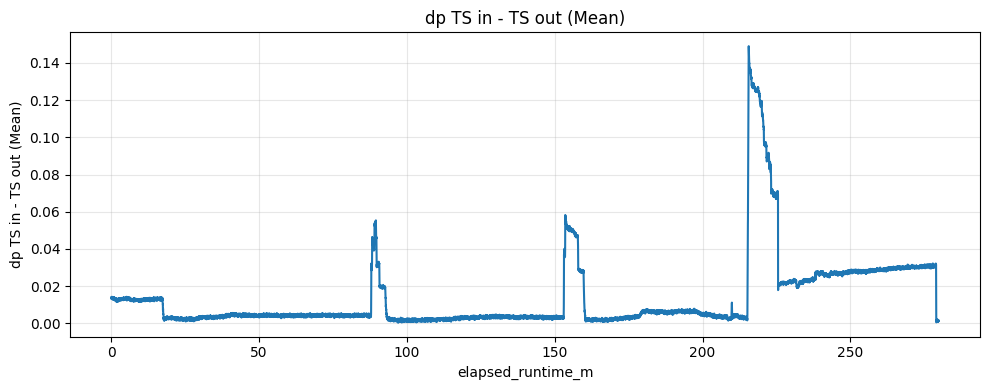

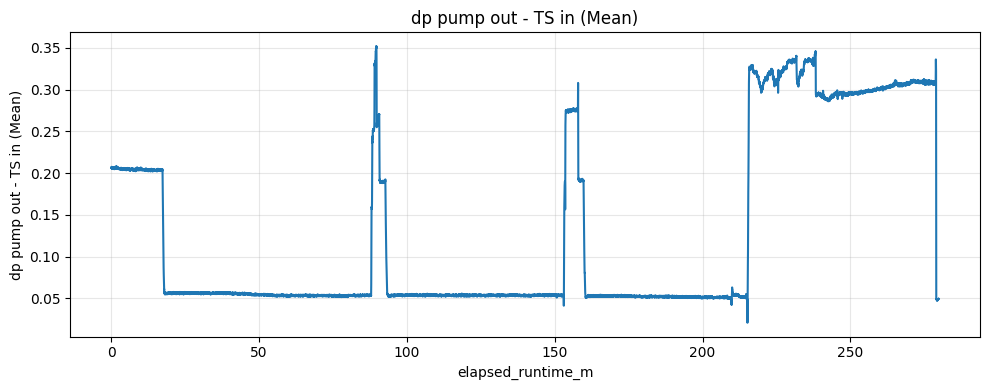

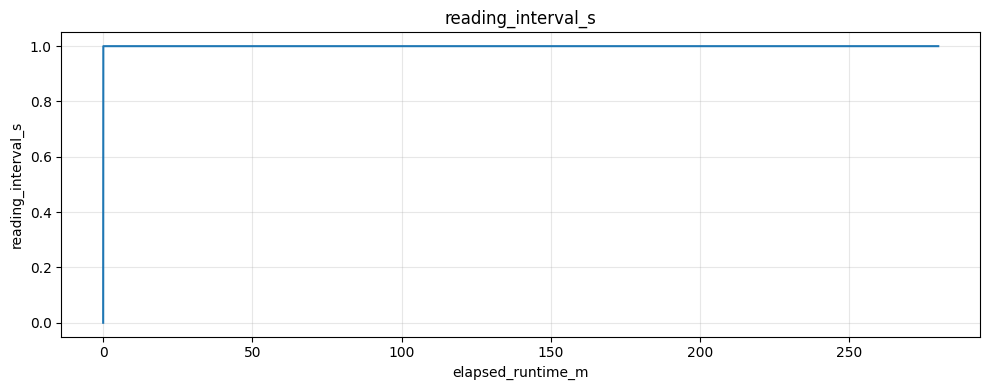

In [399]:
plot_all_timeseries(df)

3 runs, følge timestamps i description, bare blokkering i 3. run, igjen spikes i pressure rett før timestamp, betyr det "stabilisering / klargjøring av rigg?

### snipping

In [400]:
df.drop(columns=['dp TS in - TS out (Mean)', 'dp pump out - TS in (Mean)'], inplace=True)

fra description: Three runs were conducted; blockage was achieved only in the third run. Also, before the start of the second and third runs, a small non-removable sediment remained on the glass tube.

13:53:03 – 15:02:50

15:08:37 – 16:08:03

16:15:39 – 17:03:21 (loop blockage)

In [401]:
start = find_index_at_timestamp(df, 135303)
end = find_index_at_timestamp(df, 150250)
dffirst = snip_df_at_timecode(df, start, end)

In [402]:
start = find_index_at_timestamp(df, 150837)
end = find_index_at_timestamp(df, 160803)
dfsnd = snip_df_at_timecode(df, start, end)

In [403]:
start = find_index_at_timestamp(df, 161539)
end = find_index_at_timestamp(df, 170321)
dfthrd = snip_df_at_timecode(df, start, end)

In [404]:
dffirst.to_csv('../data/split/no_plug/3006-1.csv', index=False)
dfsnd.to_csv('../data/split/no_plug/3006-2.csv', index=False)
dfthrd.to_csv('../data/split/plug/3006-3.csv', index=False)

### Plot after snip

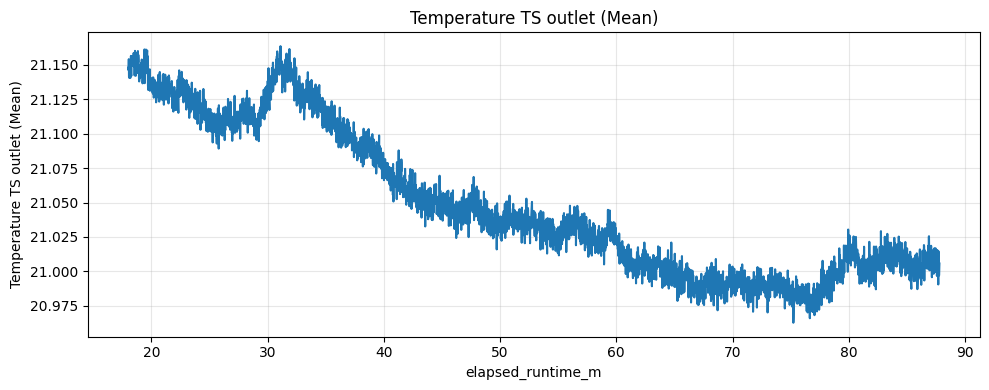

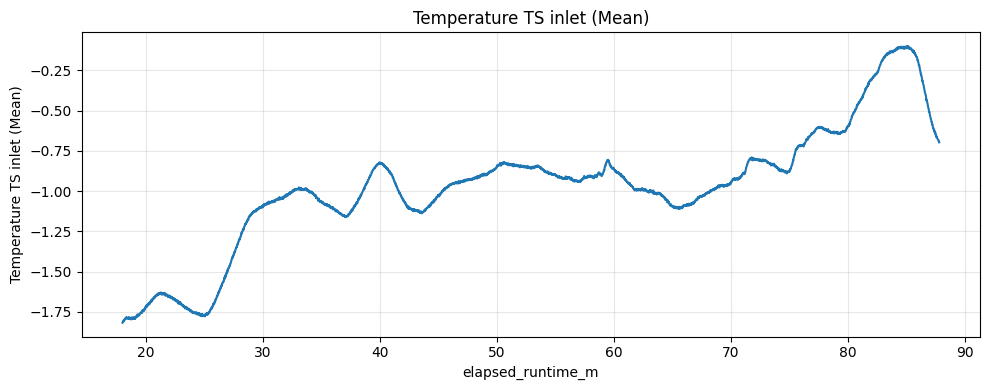

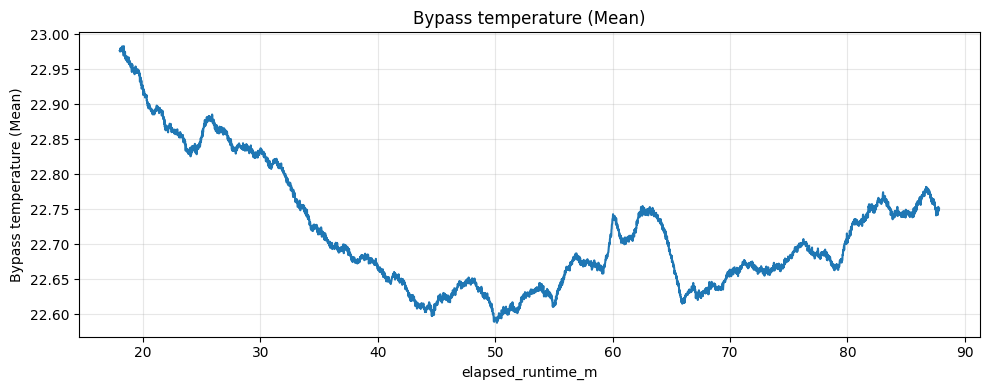

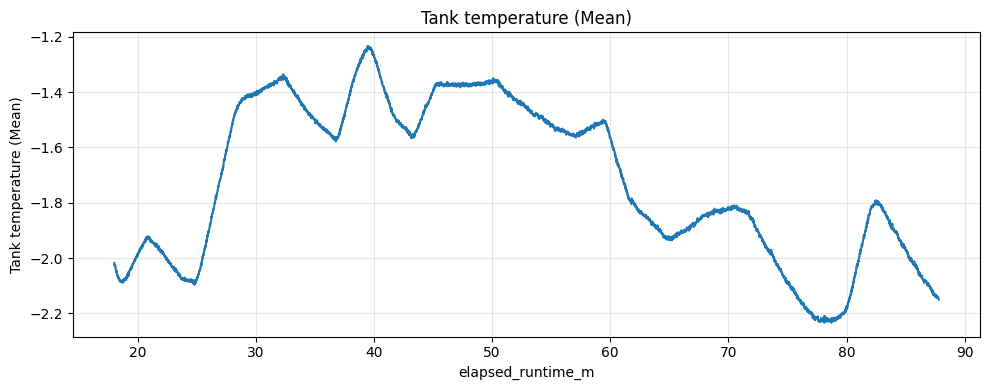

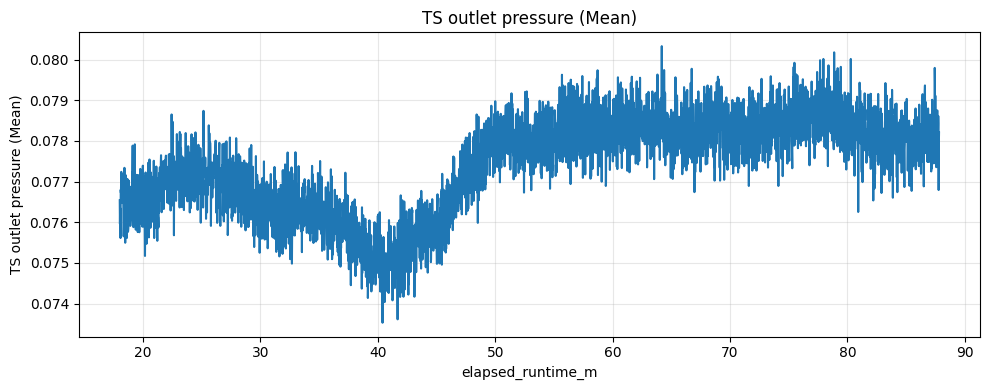

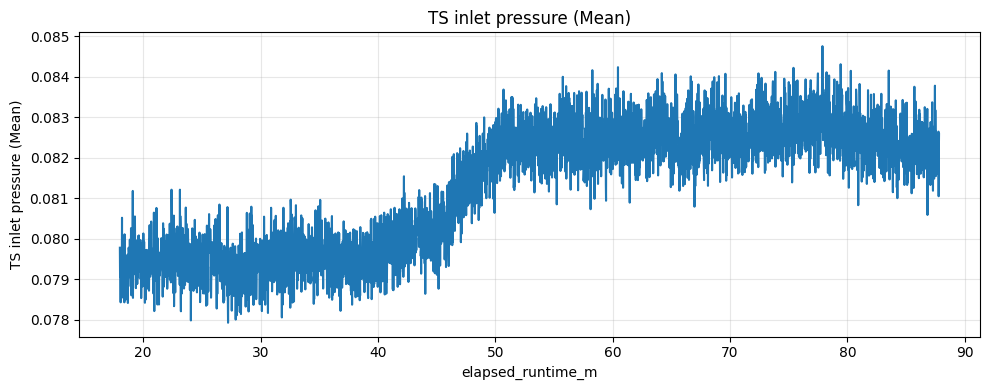

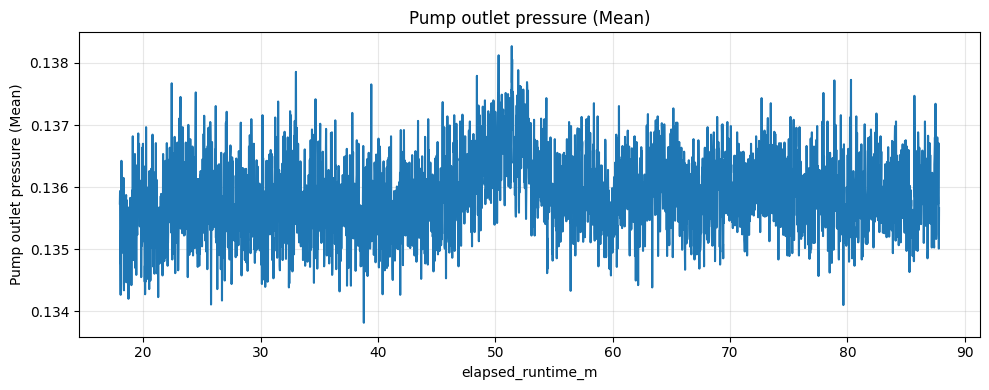

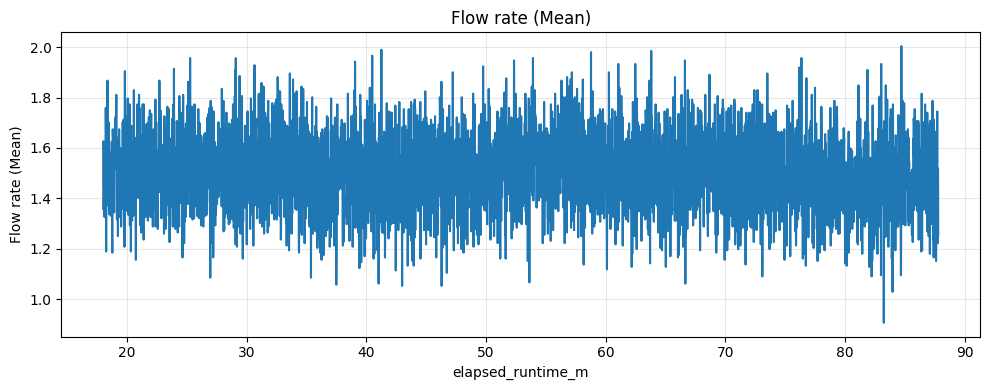

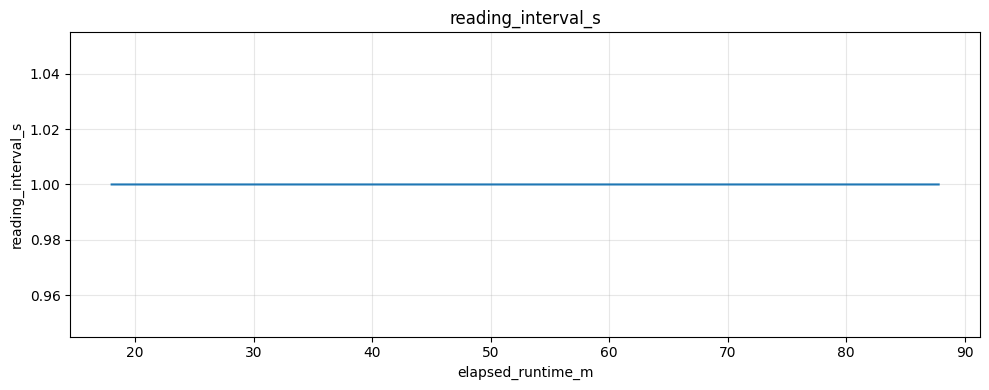

In [405]:
plot_all_timeseries(dffirst)

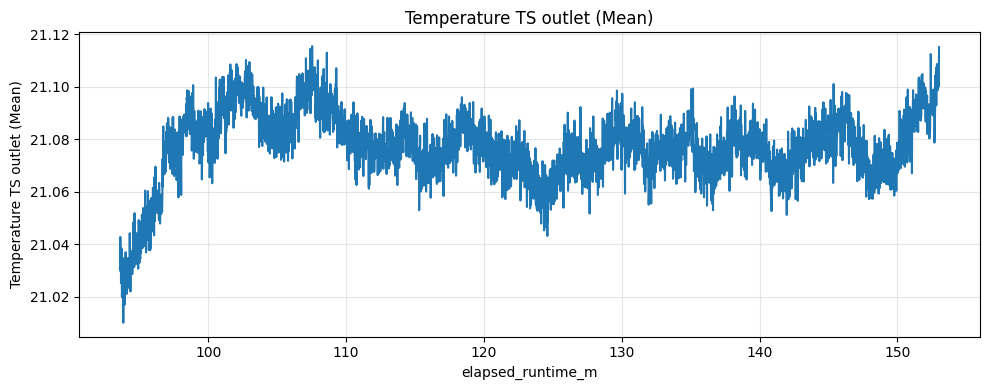

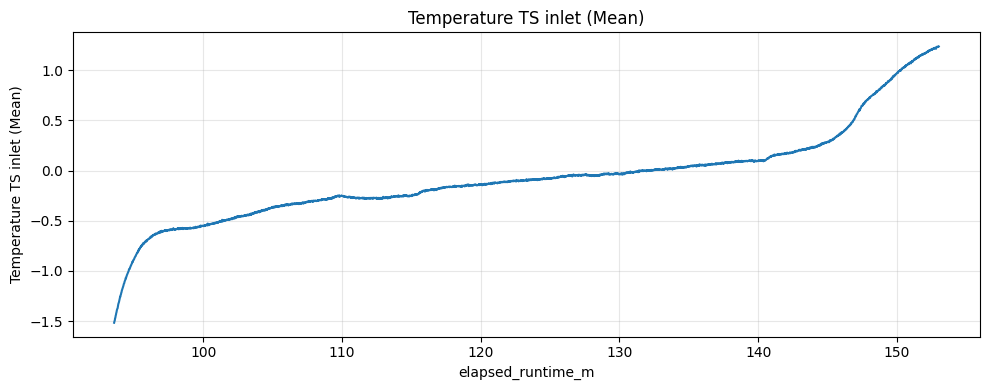

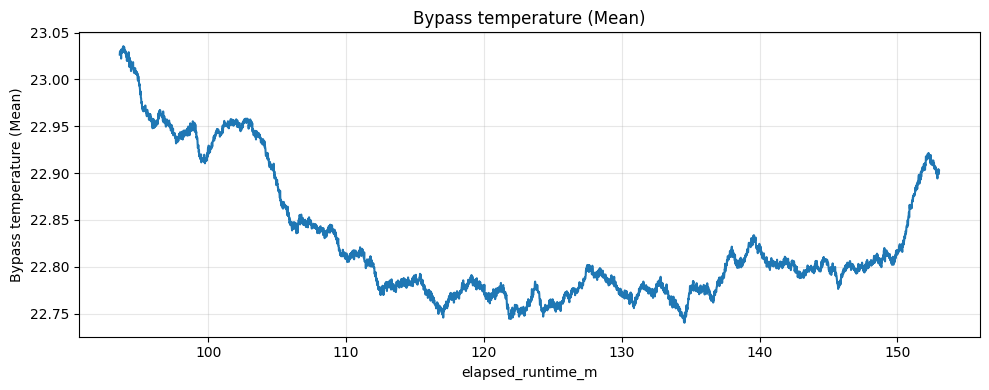

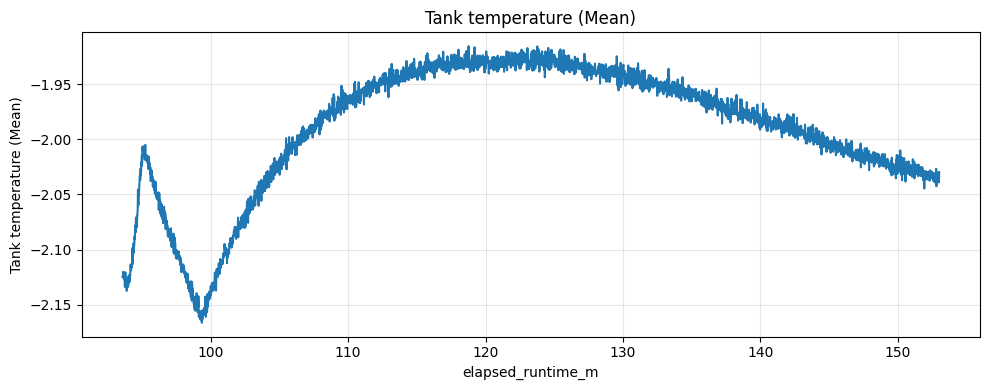

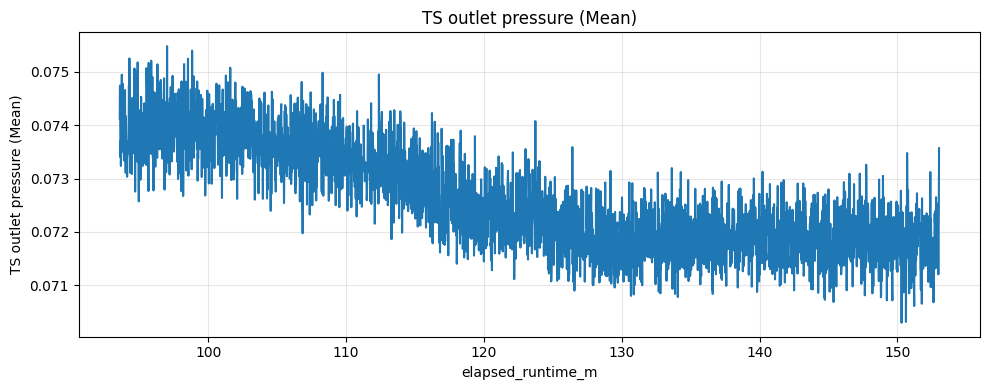

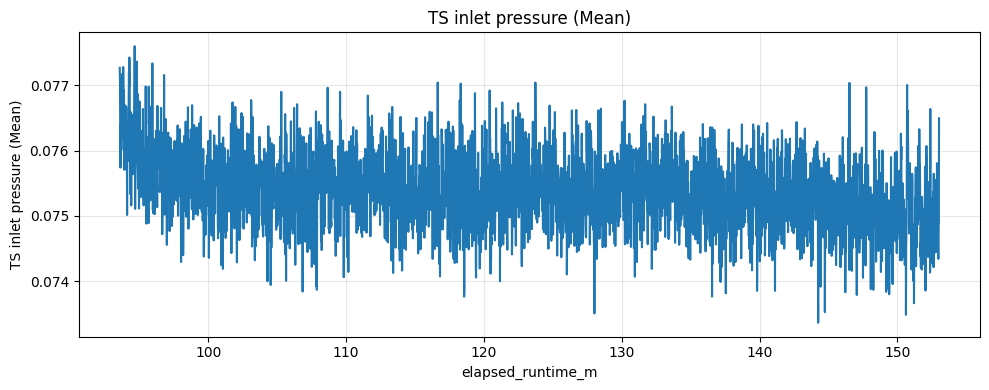

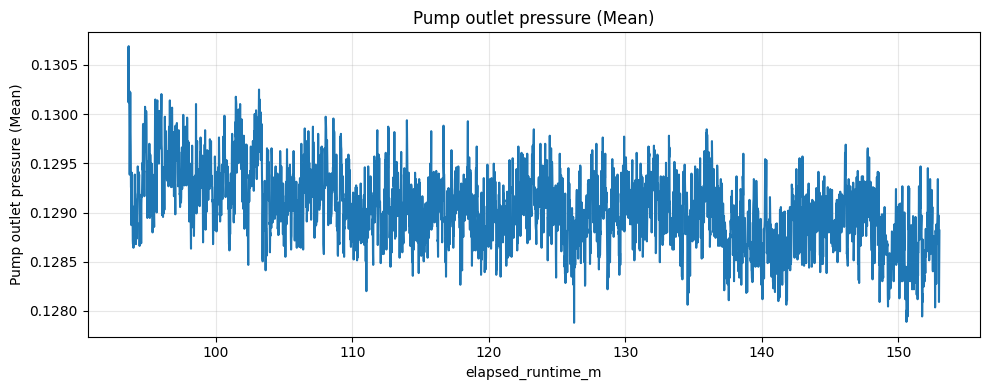

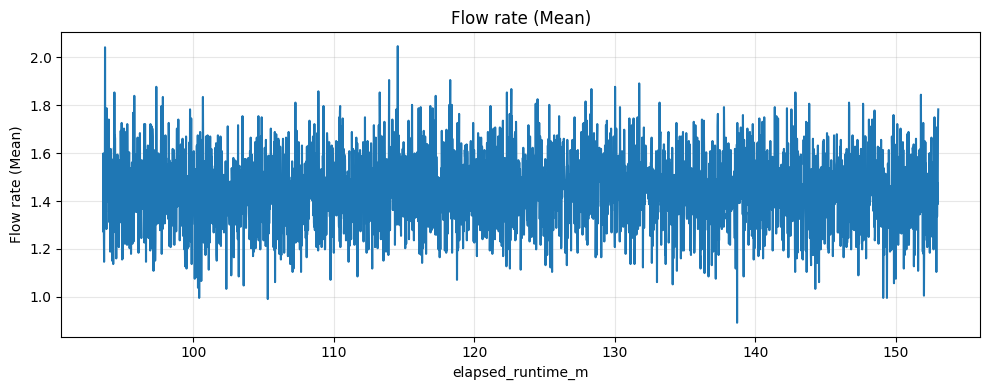

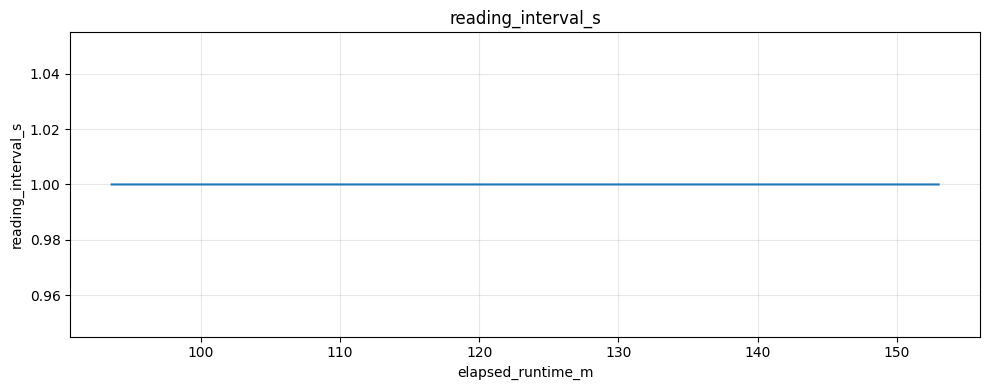

In [406]:
plot_all_timeseries(dfsnd)

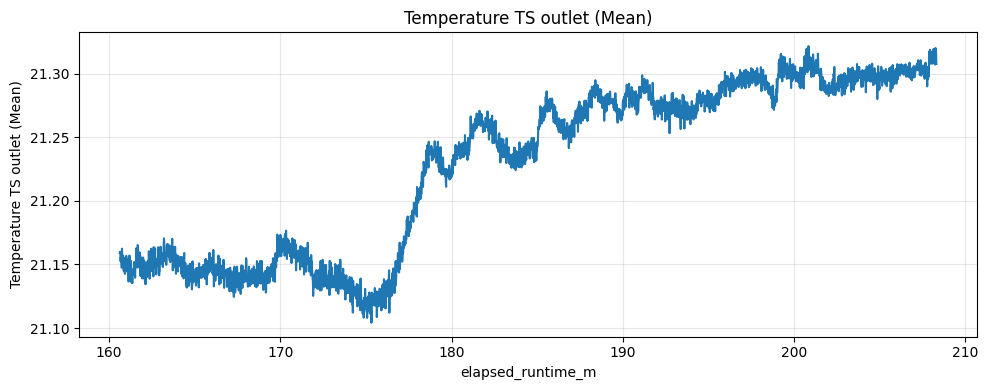

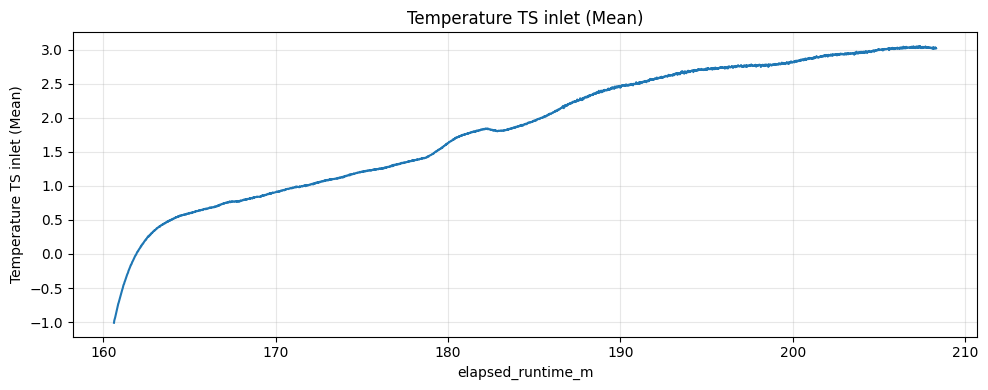

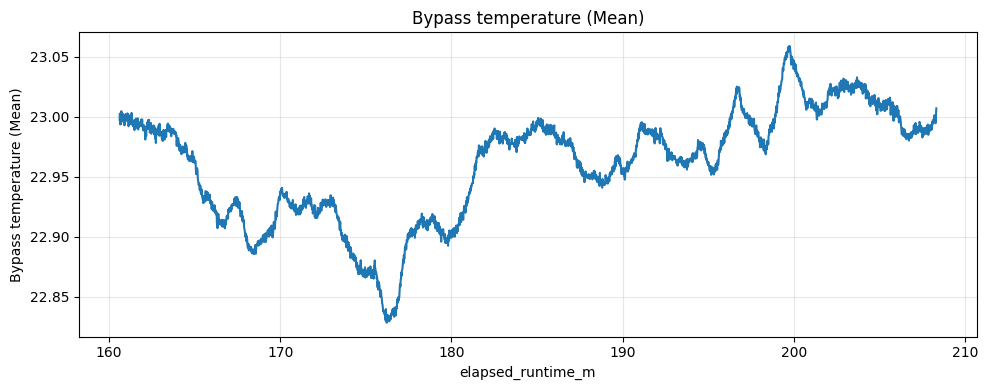

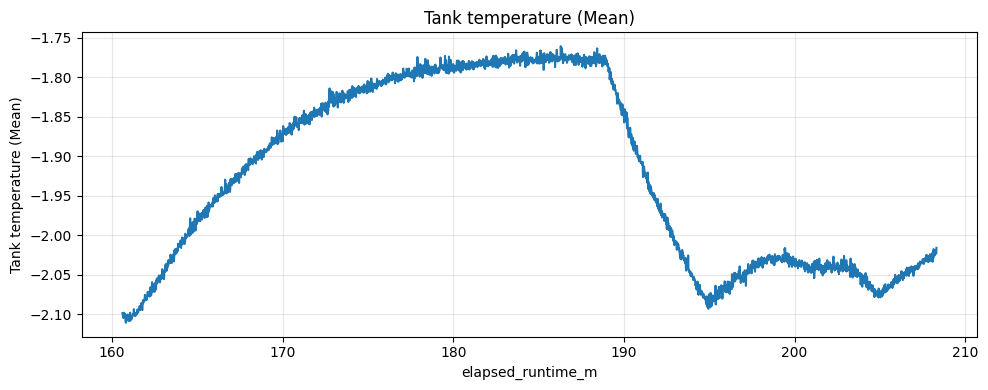

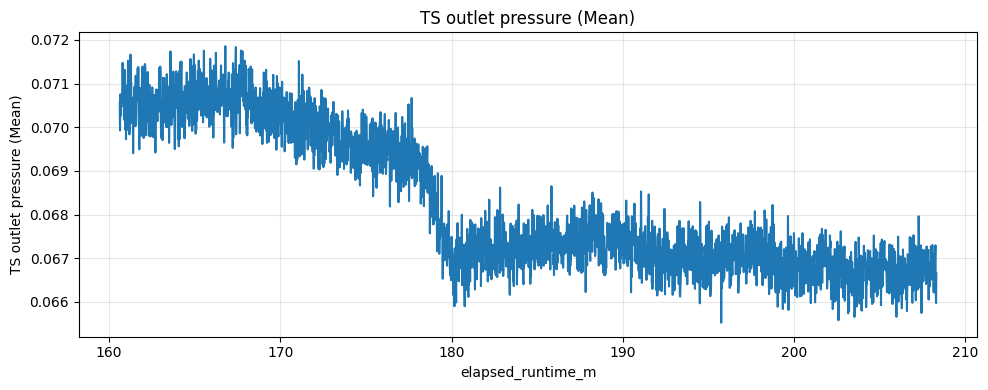

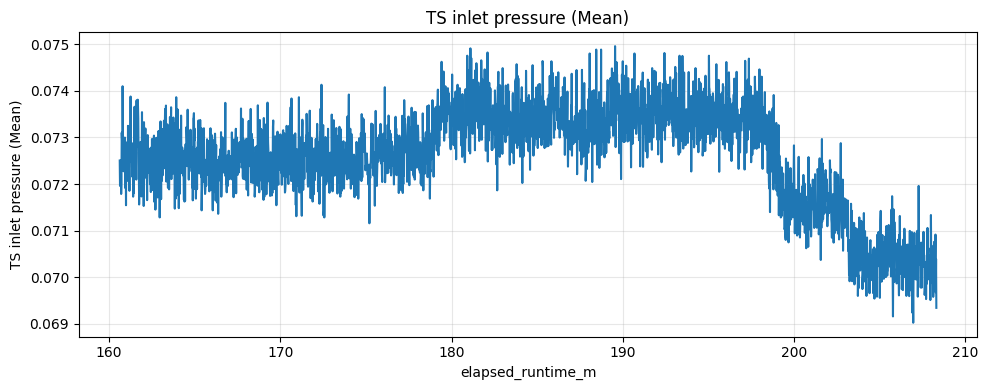

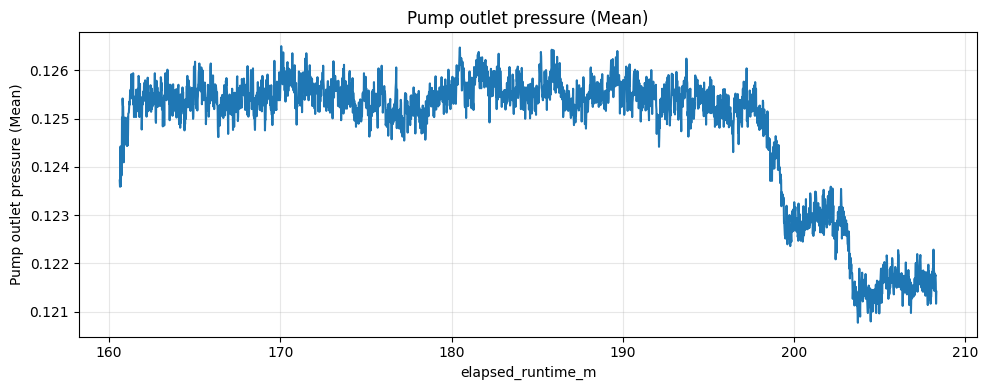

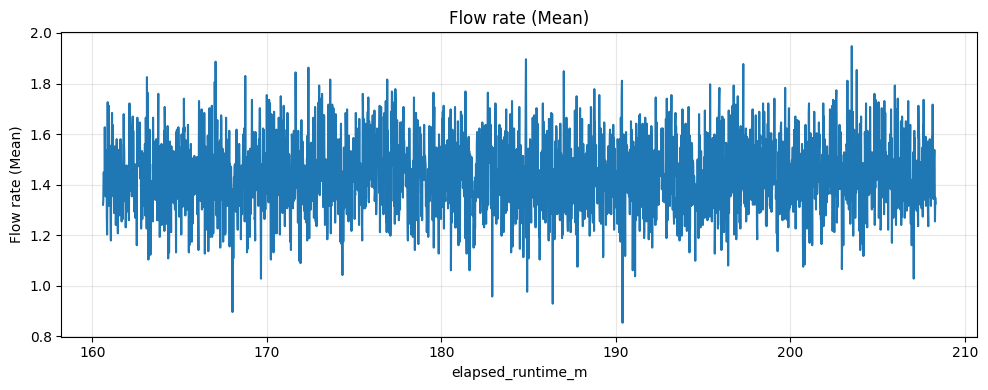

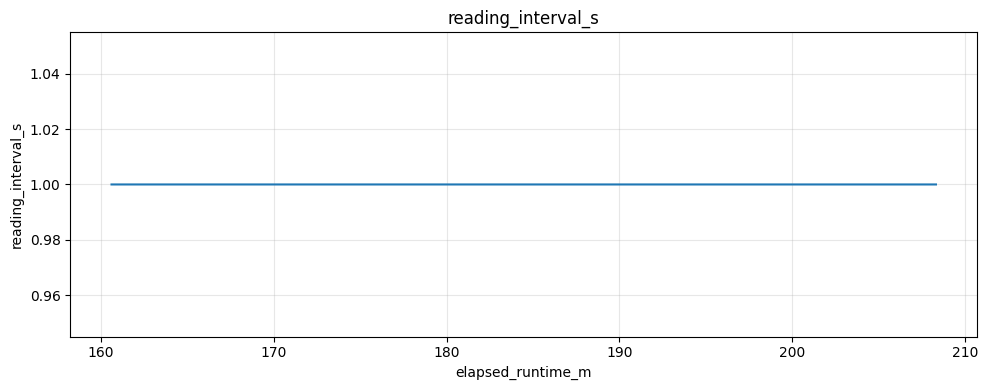

In [407]:
plot_all_timeseries(dfthrd)

## 07.12

### init

In [81]:
df = df0712.copy()

In [82]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


In [83]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.00    1416
1.50    1290
0.50    1271
2.00    1184
2.50     837
0.99       6
0.00       1
Name: count, dtype: int64

In [84]:
df = df.rename(columns=mapping)

### plotting

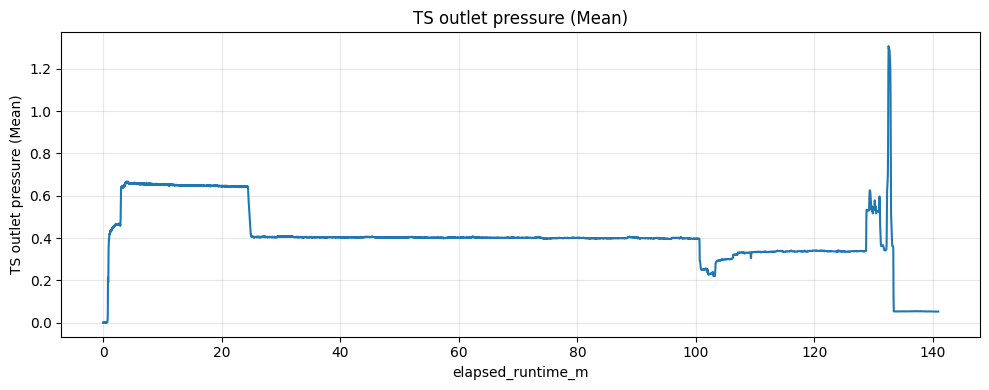

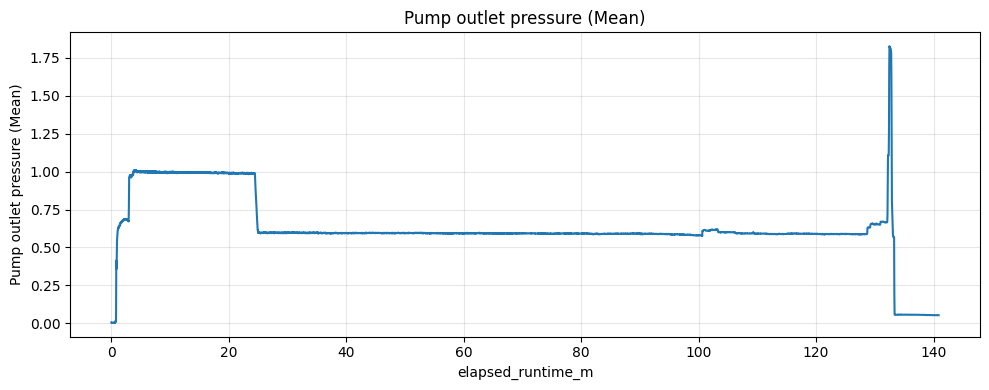

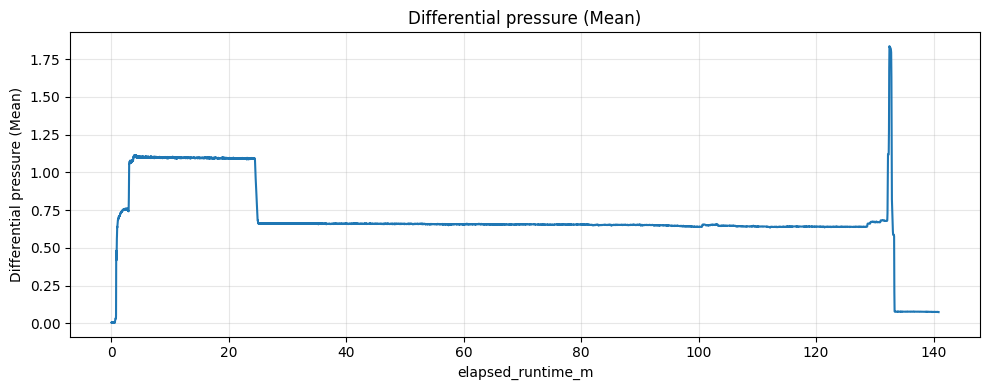

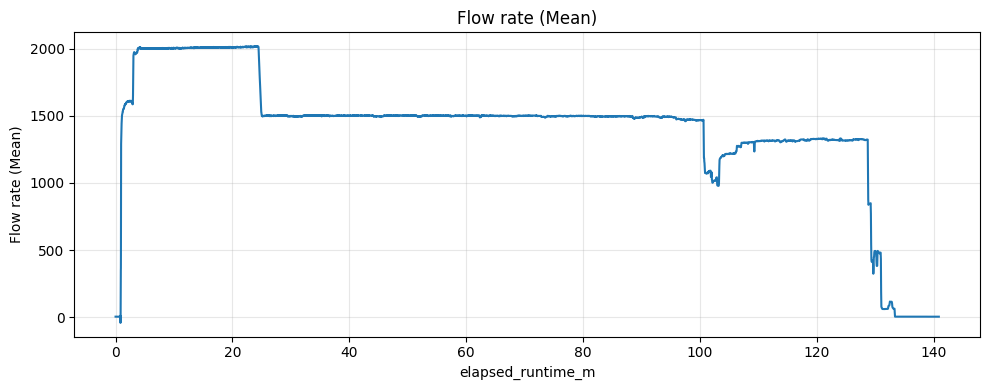

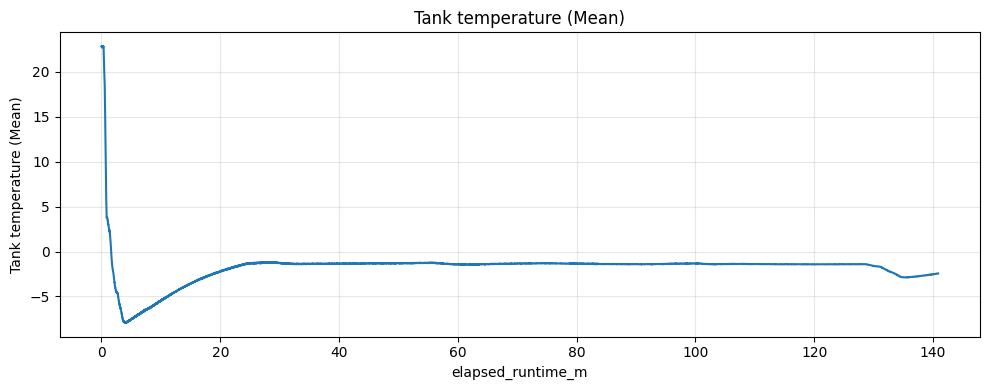

...

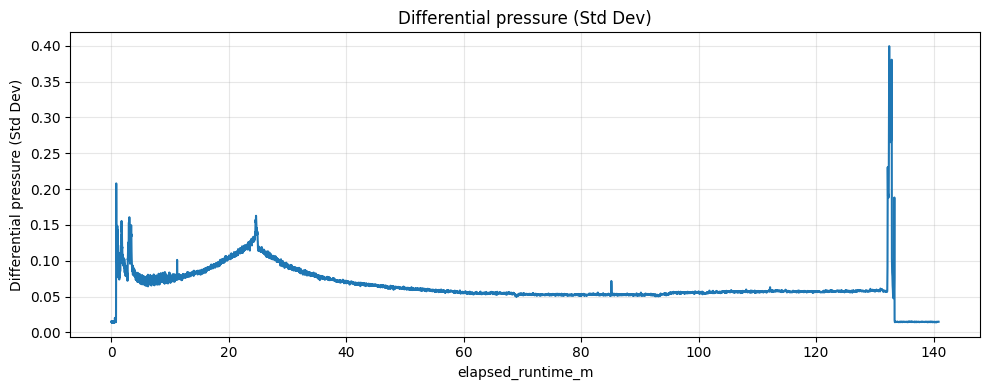

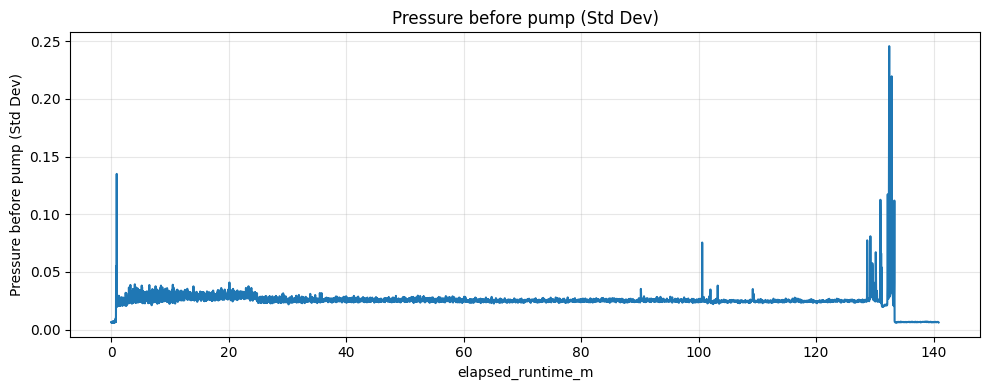

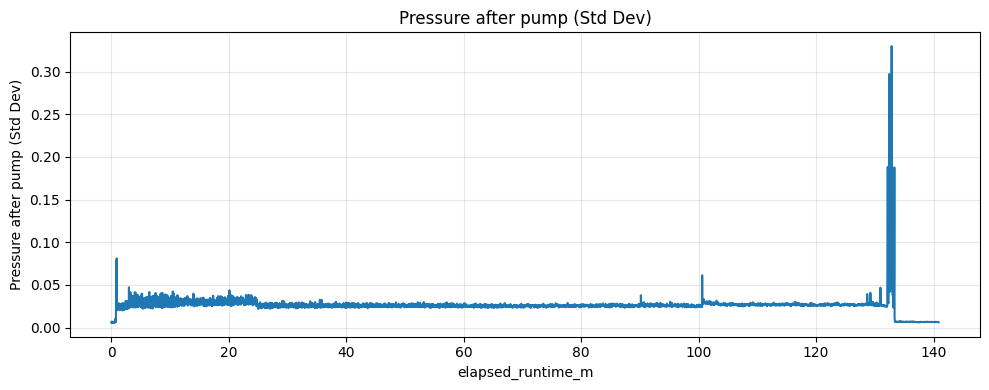

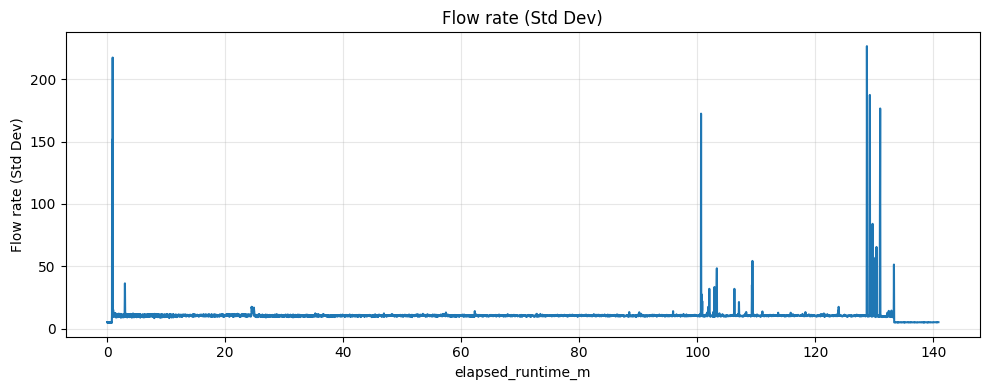

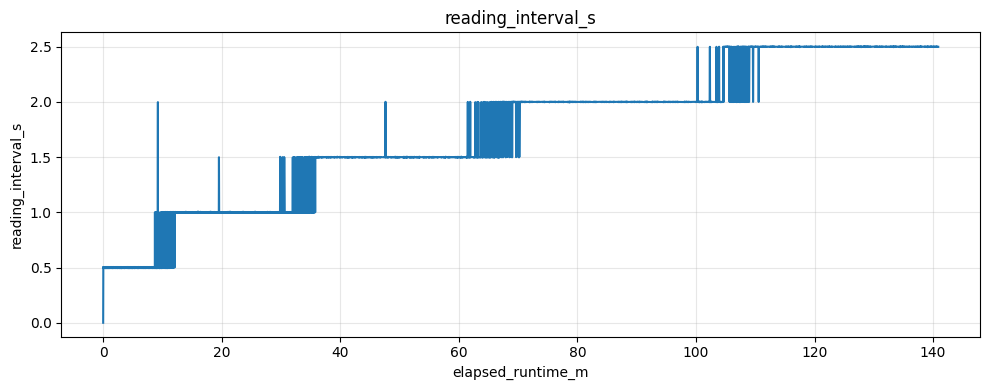

In [412]:
plot_all_timeseries(df)

### snipping

Finne target flowrate 1500kg/h

In [64]:
i = 2233    
df.loc[i-1:i+1]

,Time,TS outlet pressure (Mean),Pump outlet pressure (Mean),Differential pressure (Mean),Flow rate (Mean),Tank temperature (Mean),Temperature TS inlet (Mean),Temperature TS outlet (Mean),Bypass temperature (Mean),Temperature TS outlet (Std Dev),Temperature TS inlet (Std Dev),Bypass temperature (Std Dev),Tank temperature (Std Dev),Differential pressure (Std Dev),Pressure before pump (Std Dev),Pressure after pump (Std Dev),Flow rate (Std Dev),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
2232,2021-12-07 11:08:36.746,0.405707,0.596239,0.662533,1498.357234,-1.274810,-1.144815,-1.116961,24.839909,0.241004,0.249546,0.209139,0.976323,0.107861,0.024732,0.024159,9.995053,1.000,1597.903,26.631717
2233,2021-12-07 11:08:37.747,0.406148,0.595998,0.660705,1500.361028,-1.294235,-1.152297,-1.121818,24.837283,0.235388,0.240418,0.212087,0.974532,0.113270,0.026578,0.026480,10.483474,1.001,1598.904,26.648400
2234,2021-12-07 11:08:38.747,0.405738,0.596465,0.661109,1499.116319,-1.258929,-1.134053,-1.105804,24.844503,0.246301,0.237452,0.205825,0.990464,0.106406,0.026181,0.025708,11.039216,1.000,1599.904,26.665067


In [85]:
df.drop(columns=['Temperature TS outlet (Std Dev)', 'Temperature TS inlet (Std Dev)', 'Bypass temperature (Std Dev)', 'Tank temperature (Std Dev)', 'Differential pressure (Std Dev)', 'Pressure before pump (Std Dev)', 'Pressure after pump (Std Dev)', 'Flow rate (Std Dev)'], inplace = True)

In [86]:
i = 5005
df.loc[i-3:i+4]

,Time,TS outlet pressure (Mean),Pump outlet pressure (Mean),Differential pressure (Mean),Flow rate (Mean),Tank temperature (Mean),Temperature TS inlet (Mean),Temperature TS outlet (Mean),Bypass temperature (Mean),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
5002,2021-12-07 12:22:29.470,0.396282,0.578486,0.637920,1466.826653,-1.321329,-1.172651,-0.954936,24.961444,1.998,6030.627,100.510450
5003,2021-12-07 12:22:31.472,0.396726,0.579515,0.638284,1465.804652,-1.348895,-1.179782,-0.950573,24.962082,2.002,6032.629,100.543817
5004,2021-12-07 12:22:33.470,0.398205,0.581783,0.640668,1469.543741,-1.328289,-1.177969,-0.942394,24.963808,1.998,6034.627,100.577117
5005,2021-12-07 12:22:35.472,0.377703,0.574778,0.642816,1467.597740,-1.316755,-1.170467,-0.954378,24.953554,2.002,6036.629,100.610483
5006,2021-12-07 12:22:37.470,0.292908,0.608597,0.652489,1296.161913,-1.332557,-1.173899,-0.948961,24.955337,1.998,6038.627,100.643783
5007,2021-12-07 12:22:39.471,0.292333,0.606443,0.651123,1186.203920,-1.328360,-1.166669,-0.943040,24.947881,2.001,6040.628,100.677133
5008,2021-12-07 12:22:41.470,0.288191,0.609016,0.651913,1185.970537,-1.333019,-1.171591,-0.935361,24.949653,1.999,6042.627,100.710450
5009,2021-12-07 12:22:43.471,0.279614,0.608438,0.651031,1157.898569,-1.331575,-1.160369,-0.930308,24.959761,2.001,6044.628,100.743800


In [87]:
df = snip_df_at_timecode(df, 2233, 5005)

In [88]:
df.to_csv('../data/split/no_plug/0712.csv', index=False)

### Plot after snip

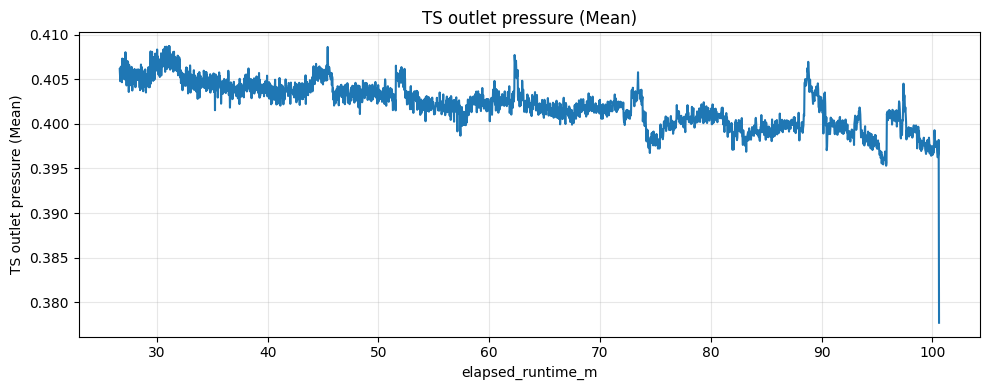

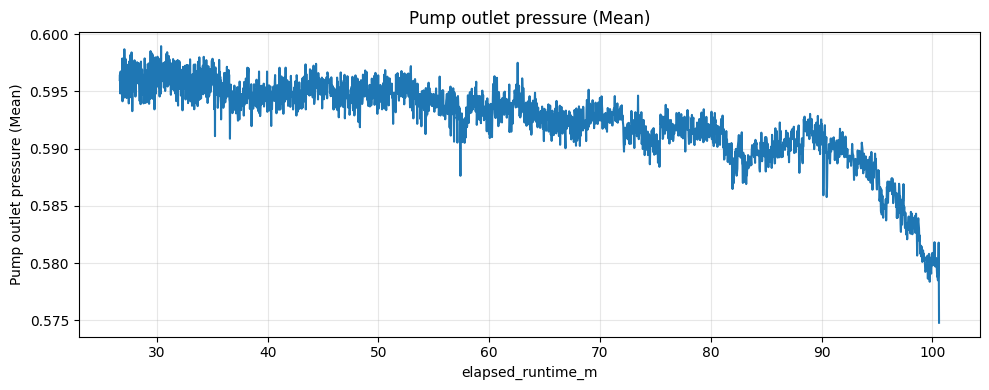

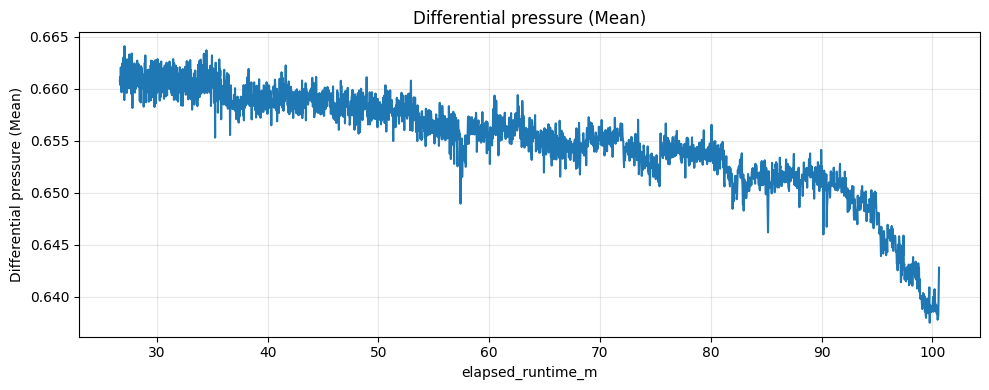

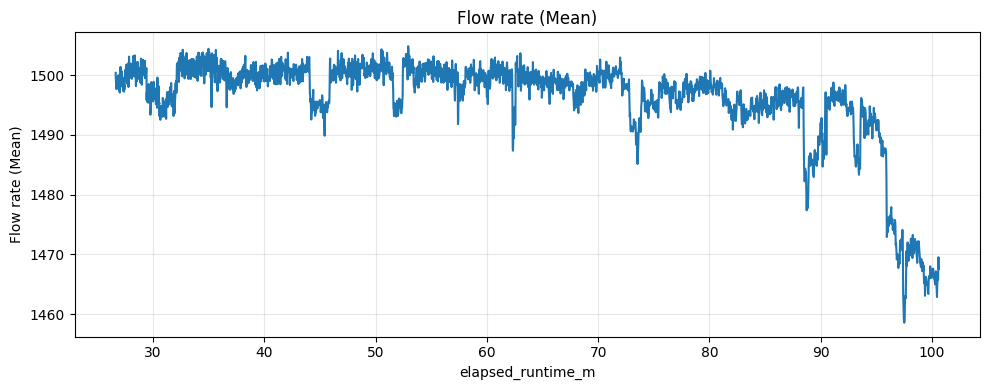

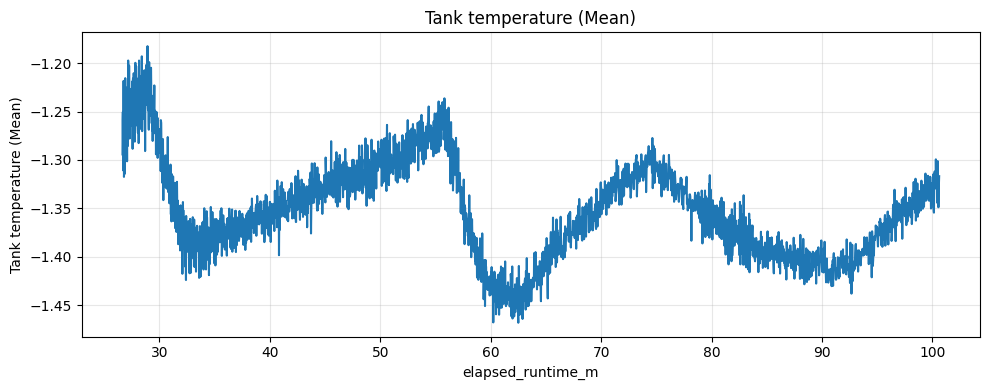

...

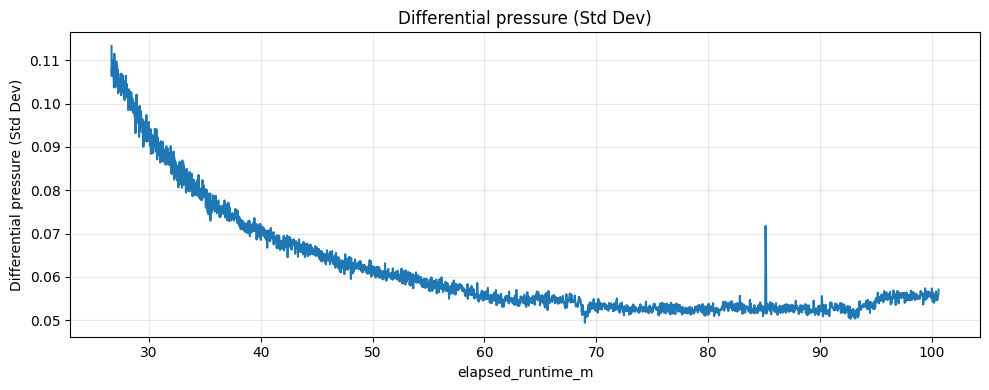

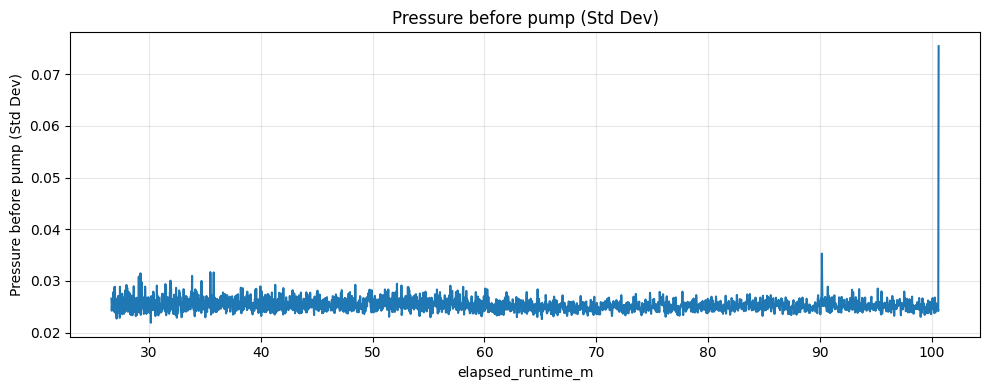

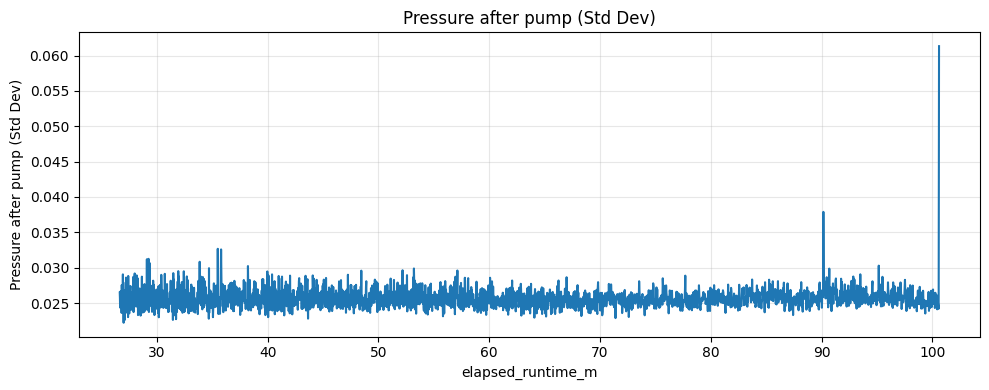

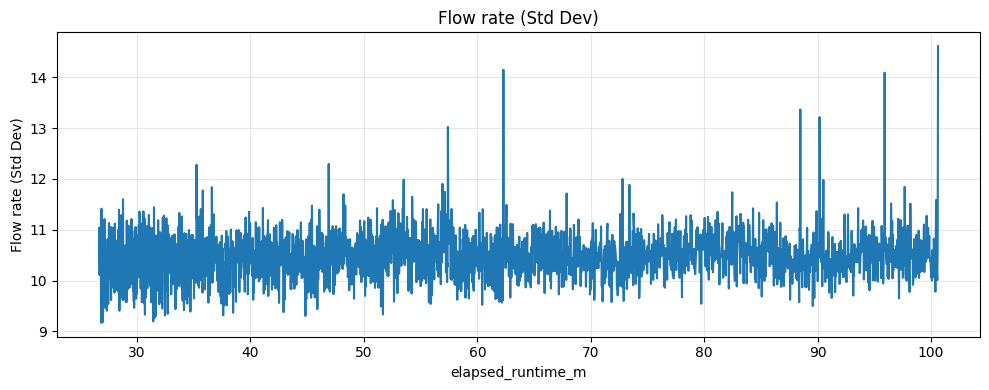

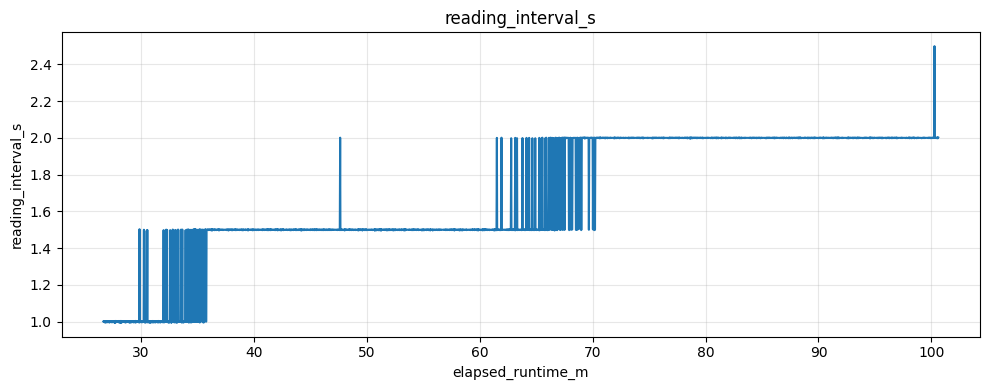

In [80]:
plot_all_timeseries(df2)

## 11.12

### init

In [422]:
df = df1112.copy()

In [423]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


In [424]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()


reading_interval_s
0.50    172
0.20    165
0.35    156
0.25    155
0.95    151
       ... 
2.14      1
1.69      1
0.64      1
4.09      1
0.00      1
Name: count, Length: 110, dtype: int64

In [425]:
df = df.rename(columns=mapping)

### plotting

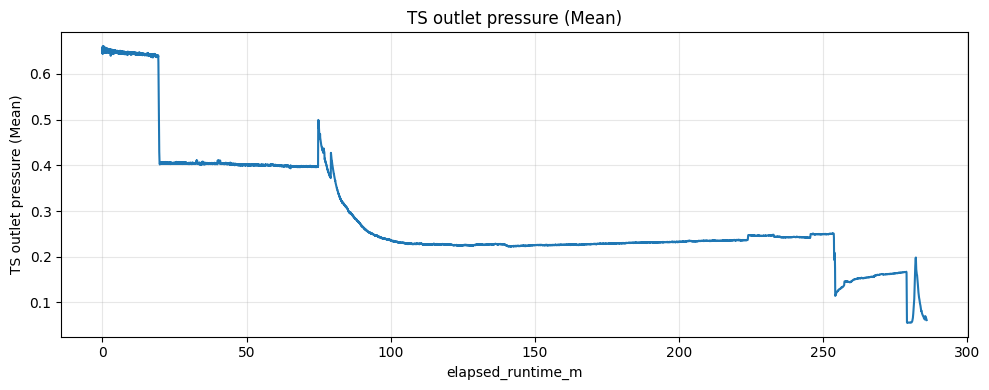

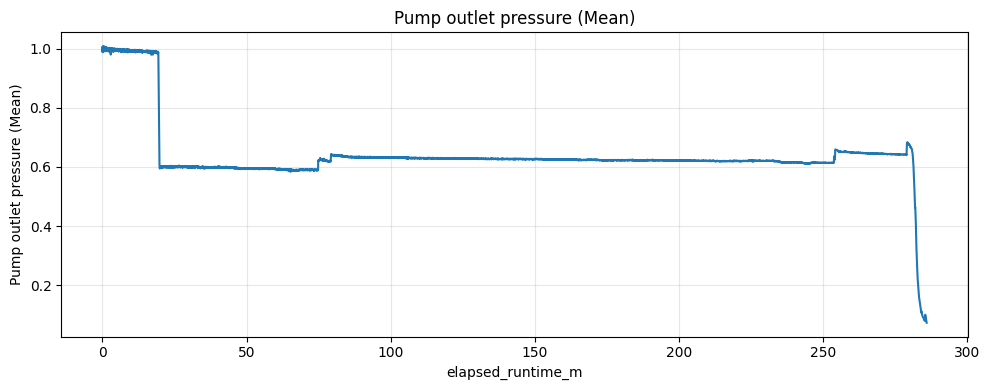

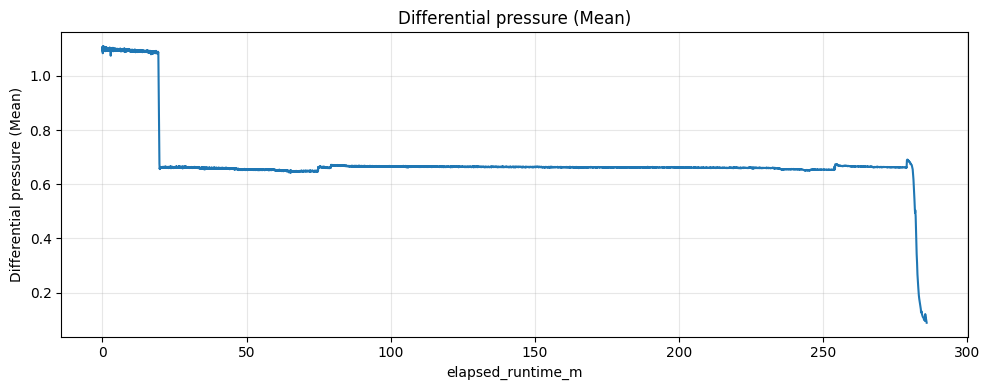

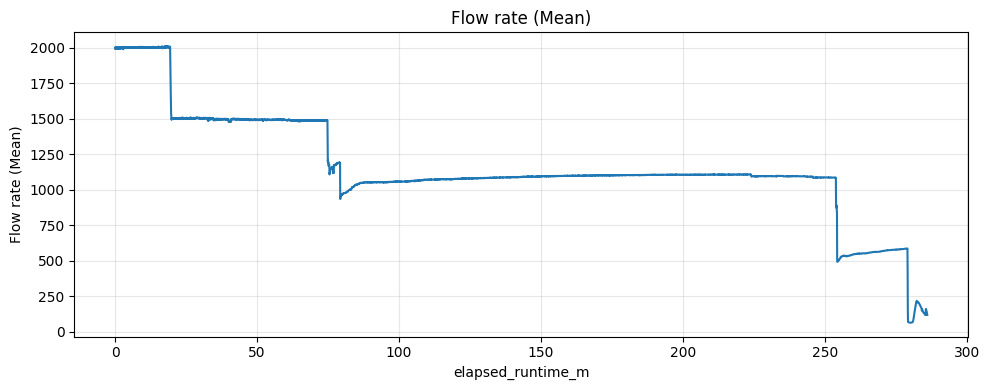

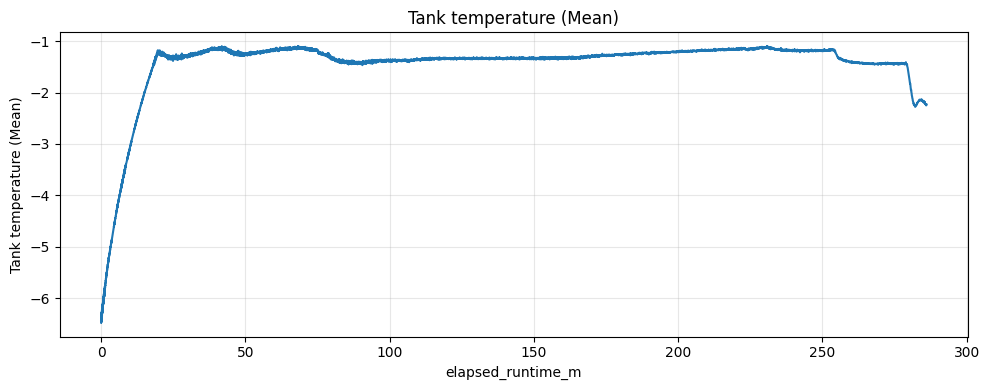

...

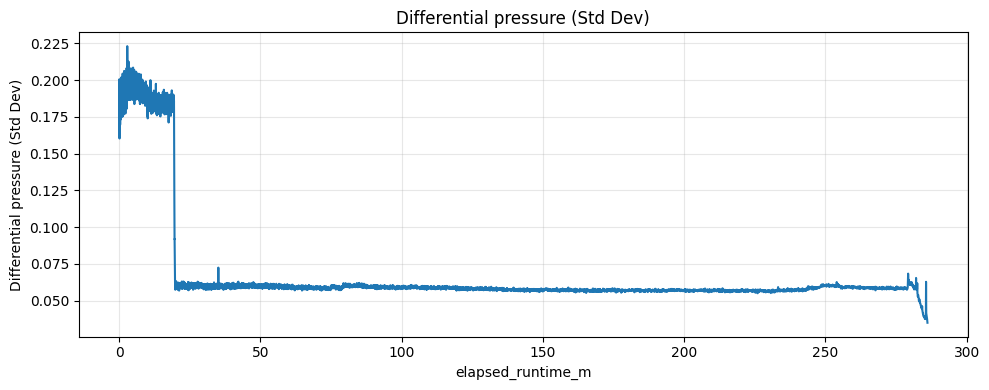

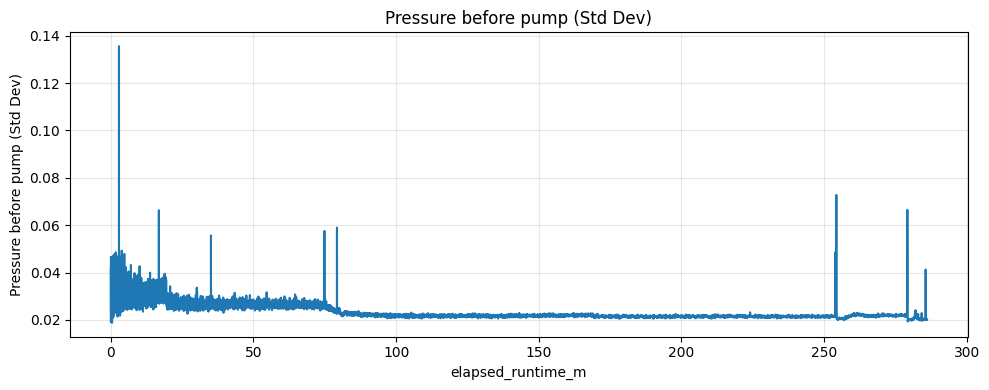

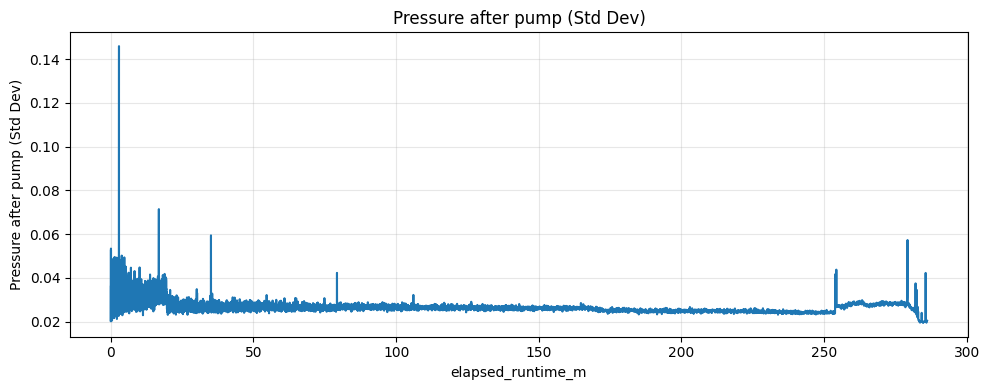

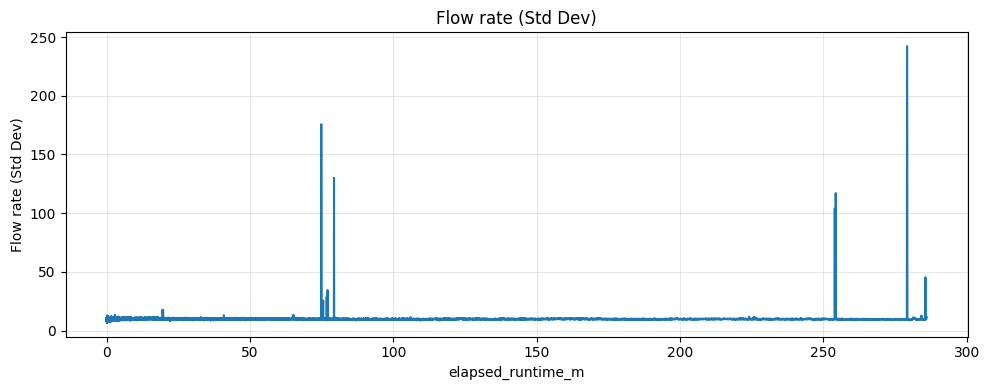

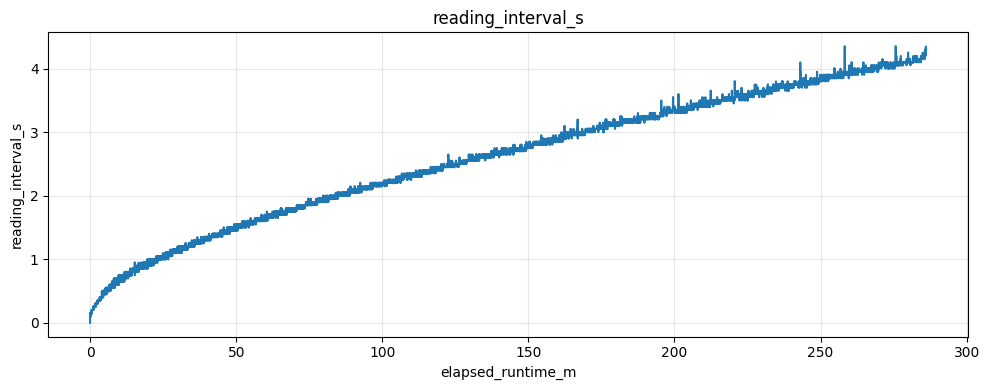

In [426]:
plot_all_timeseries(df)

### Snipping


finne target flowrate 1500 kg/h

In [427]:
i = 2356
df.loc[i-5:i+5]

,Time,TS outlet pressure (Mean),Pump outlet pressure (Mean),Differential pressure (Mean),Flow rate (Mean),Tank temperature (Mean),Temperature TS inlet (Mean),Temperature TS outlet (Mean),Bypass temperature (Mean),Temperature TS outlet (Std Dev),Temperature TS inlet (Std Dev),Bypass temperature (Std Dev),Tank temperature (Std Dev),Differential pressure (Std Dev),Pressure before pump (Std Dev),Pressure after pump (Std Dev),Flow rate (Std Dev),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
2351,2021-12-11 12:02:14.110,0.413426,0.613532,0.675769,1533.281718,-1.184728,-1.109872,-1.112836,24.509281,0.207634,0.204168,0.178509,0.944394,0.062416,0.025357,0.024394,10.911237,0.951,1186.074,19.767900
2352,2021-12-11 12:02:15.058,0.408836,0.606263,0.669168,1524.304197,-1.208608,-1.105580,-1.110673,24.508945,0.217501,0.211279,0.170889,0.947598,0.062257,0.024536,0.025040,11.175782,0.948,1187.022,19.783700
2353,2021-12-11 12:02:16.009,0.407955,0.604207,0.666621,1515.523103,-1.232204,-1.104489,-1.110351,24.517425,0.221535,0.232033,0.174138,0.872154,0.061076,0.027539,0.027666,11.168338,0.951,1187.973,19.799550
2354,2021-12-11 12:02:16.959,0.405578,0.600976,0.662819,1509.355145,-1.230434,-1.103056,-1.103918,24.518703,0.197028,0.204962,0.176361,0.899967,0.058929,0.025631,0.024518,9.961365,0.950,1188.923,19.815383
2355,2021-12-11 12:02:17.860,0.404855,0.598956,0.660420,1505.978583,-1.218885,-1.102360,-1.101622,24.517522,0.228394,0.218939,0.164845,0.902717,0.059861,0.027055,0.027117,9.753773,0.901,1189.824,19.830400
2356,2021-12-11 12:02:18.809,0.404055,0.597512,0.658216,1501.167042,-1.225480,-1.108120,-1.107569,24.516112,0.213881,0.215069,0.171132,0.887736,0.060438,0.025993,0.027002,10.515546,0.949,1190.773,19.846217
2357,2021-12-11 12:02:19.710,0.402606,0.596660,0.658615,1497.836251,-1.200385,-1.103089,-1.103370,24.515337,0.224477,0.213782,0.176159,0.940594,0.057329,0.025693,0.025246,9.233496,0.901,1191.674,19.861233
2358,2021-12-11 12:02:20.610,0.402589,0.596007,0.657299,1498.079585,-1.190898,-1.096616,-1.108240,24.519310,0.201952,0.211735,0.179125,0.957413,0.059984,0.025811,0.025685,10.425882,0.900,1192.574,19.876233
2359,2021-12-11 12:02:21.511,0.402192,0.595169,0.656076,1496.098941,-1.200385,-1.101778,-1.105701,24.519999,0.203222,0.202379,0.169436,0.952001,0.058735,0.025143,0.026049,9.955011,0.901,1193.475,19.891250
2360,2021-12-11 12:02:22.410,0.402589,0.596129,0.657860,1494.578885,-1.217889,-1.100203,-1.100272,24.522561,0.202125,0.205556,0.168541,0.967613,0.060703,0.026874,0.026549,9.589038,0.899,1194.374,19.906233


In [428]:
df.drop(columns=['Temperature TS outlet (Std Dev)', 'Temperature TS inlet (Std Dev)', 'Bypass temperature (Std Dev)', 'Tank temperature (Std Dev)', 'Differential pressure (Std Dev)', 'Pressure before pump (Std Dev)', 'Pressure after pump (Std Dev)', 'Flow rate (Std Dev)'], inplace = True)

In [429]:
df = snip_df_at_timecode(df, 2356, 0)

In [430]:
df.to_csv('../data/split/plug/1112.csv', index=False)

### Plot after snip

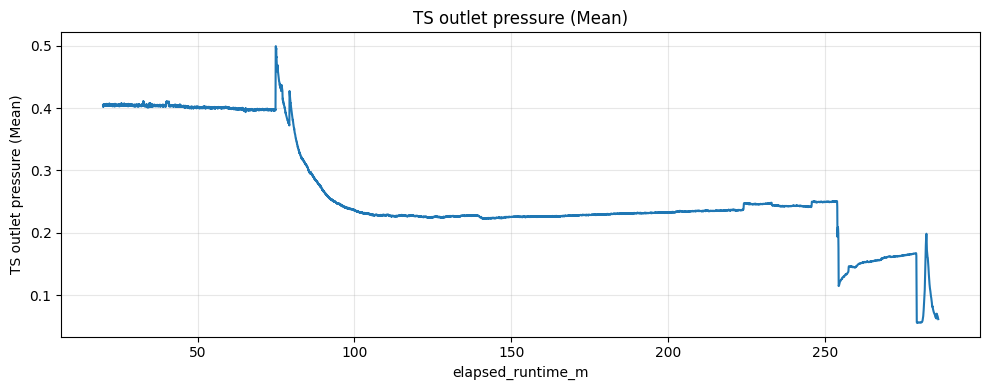

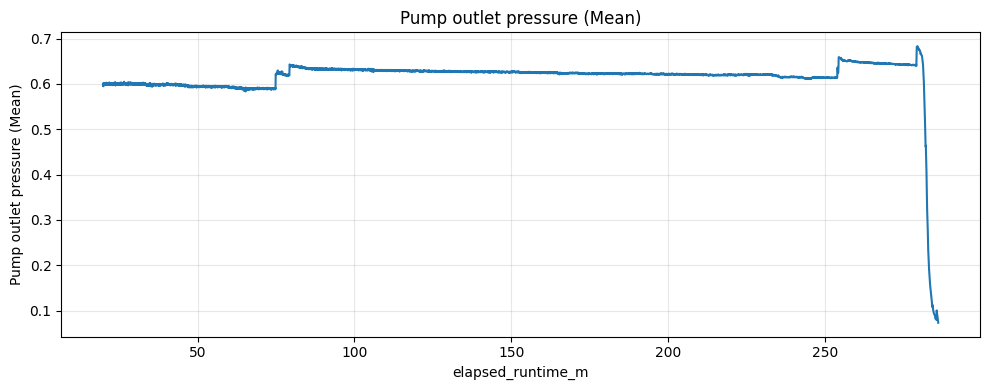

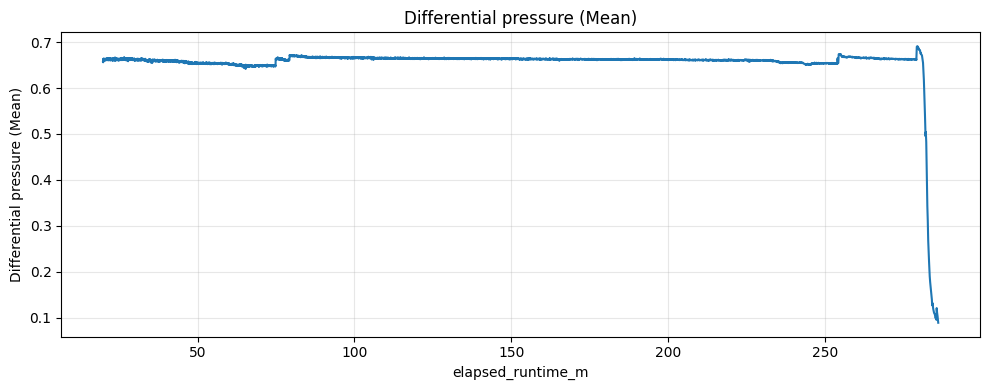

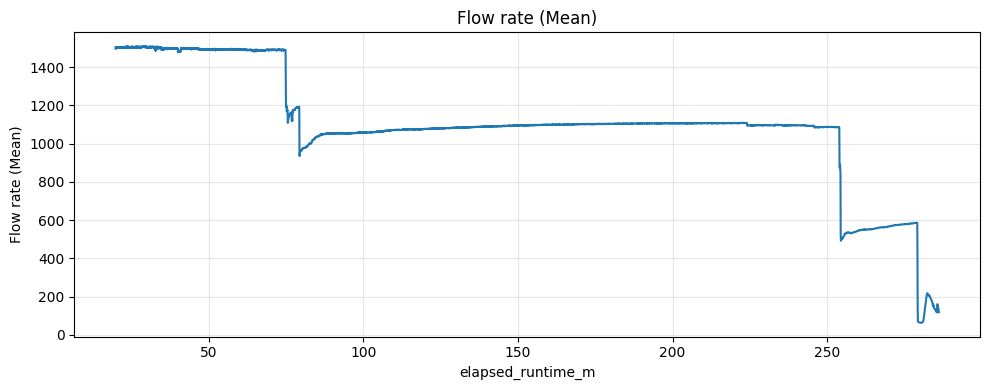

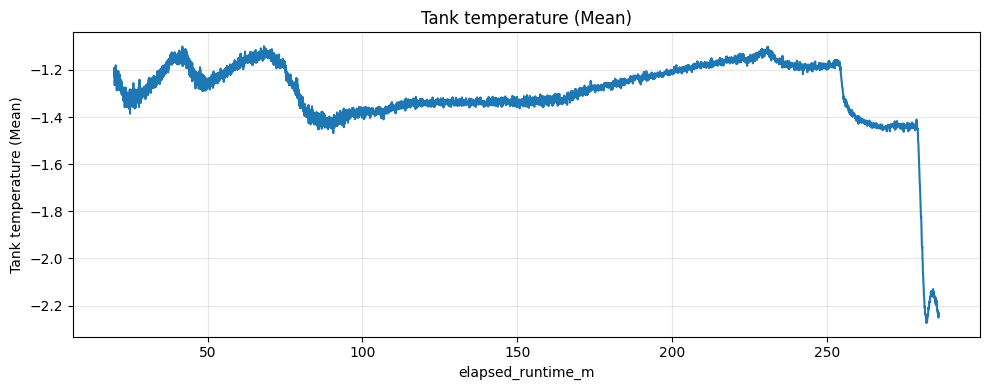

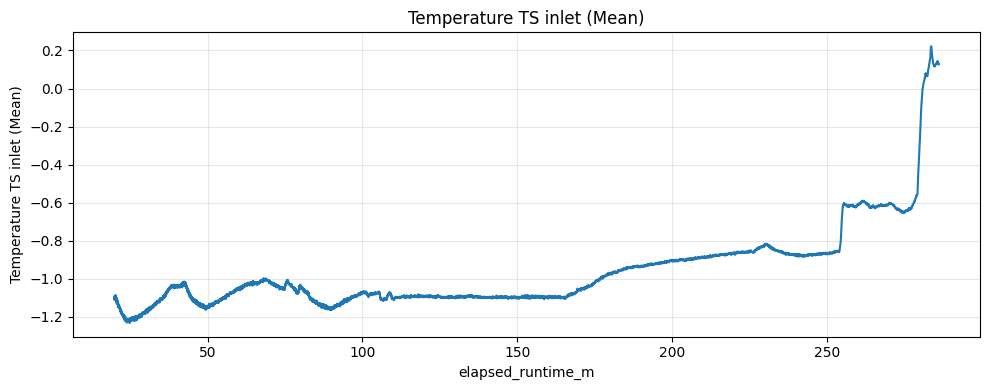

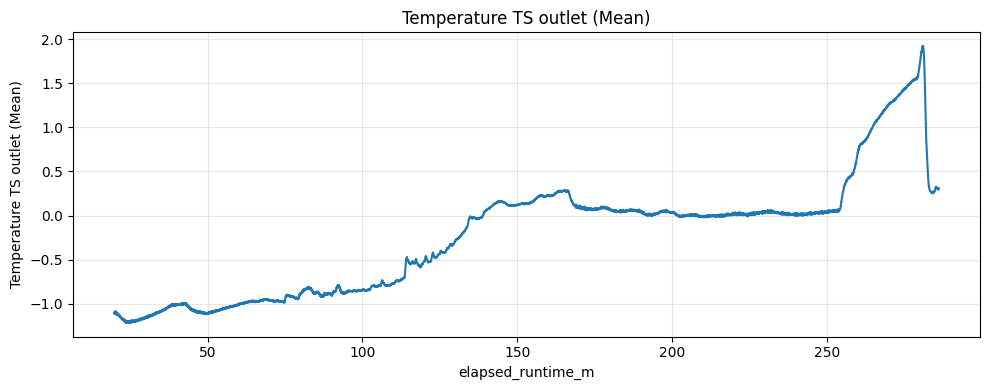

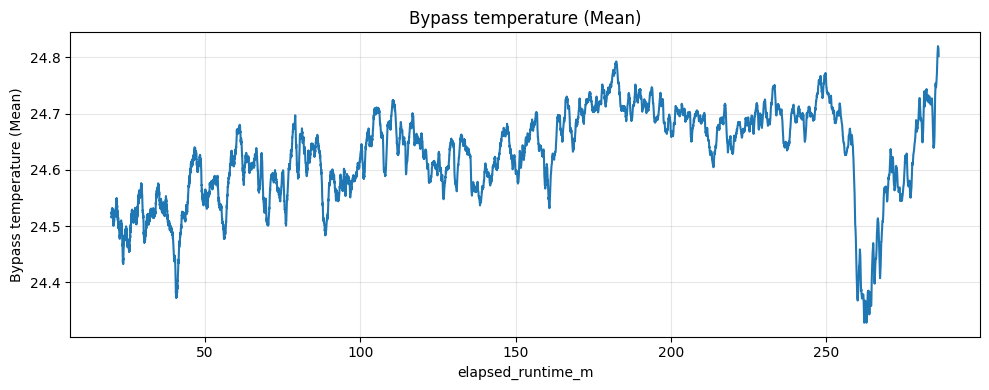

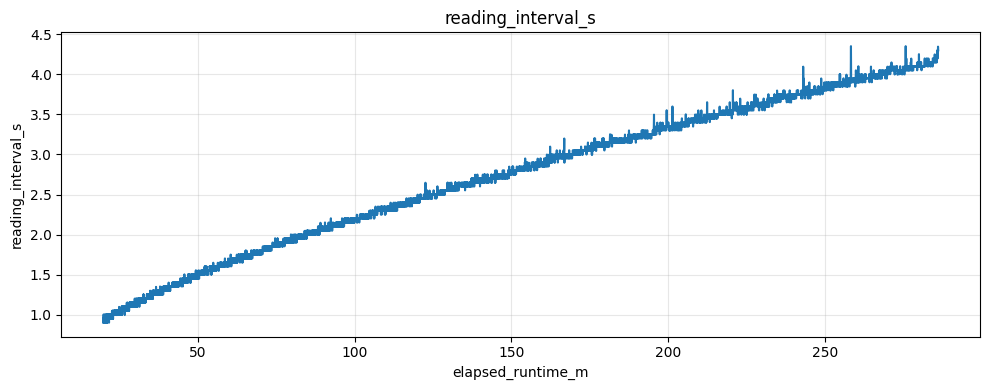

In [431]:
plot_all_timeseries(df)

## 11.03 partial block

### init

In [432]:
df = df1103.copy()

time er splittet inn i dato, time, minutt, sekund, må slå disse sammen til datetime objekt

In [433]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24863 entries, 0 to 24862
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Time                          24863 non-null  object 
 1   Unnamed: 1                    24863 non-null  int64  
 2   Unnamed: 2                    24863 non-null  int64  
 3   Unnamed: 3                    24863 non-null  int64  
 4   Unnamed: 4                    24863 non-null  float64
 5   Unnamed: 5                    24863 non-null  float64
 6   Temperature TS outlet (Mean)  24863 non-null  float64
 7   Temperature TS inlet (Mean)   24863 non-null  float64
 8   Bypass temperature (Mean)     24863 non-null  float64
 9   Tank temperature (Mean)       24863 non-null  float64
 10  TS outlet pressure (Mean)     24863 non-null  float64
 11  TS inlet pressure (Mean)      24863 non-null  float64
 12  Pump outlet pressure (Mean)   24863 non-null  float64
 13  F

In [434]:
df = rebuild_split_time(df)

In [435]:
df.drop(columns = ['Unnamed: 4', 'Unnamed: 5', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18'], inplace = True)

In [436]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
 1.0    24860
 0.0        2
-1.0        1
Name: count, dtype: int64

In [437]:
basic_checklist(df)

Missing values:
No missing values found.



In [438]:
t = df["Time"]

bad = t.diff() < pd.Timedelta(0)
bad_idx = df.index[bad]

bad_idx[:10], bad.sum()

(Index([2837], dtype='int64'), np.int64(1))

In [439]:
i = 2837
df.iloc[i-5:i+5]

,Time,Temperature TS outlet (Mean),Temperature TS inlet (Mean),Bypass temperature (Mean),Tank temperature (Mean),TS outlet pressure (Mean),TS inlet pressure (Mean),Pump outlet pressure (Mean),Flow rate (Mean),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
2832,2022-03-11 14:47:32,-0.276101,-1.073544,24.127094,-1.781694,0.096770,0.109358,0.147945,387.142922,1.0,2832.0,47.200000
2833,2022-03-11 14:47:33,-0.266256,-1.046637,24.131164,-1.744025,0.095300,0.107572,0.147660,385.115555,1.0,2833.0,47.216667
2834,2022-03-11 14:47:34,-0.252342,-1.058450,24.129326,-1.765681,0.094833,0.107163,0.147384,383.111761,1.0,2834.0,47.233333
2835,2022-03-11 14:47:35,-0.270063,-1.103208,24.125388,-1.800725,0.094764,0.106832,0.146750,381.777471,1.0,2835.0,47.250000
2836,2022-03-11 14:47:36,-0.269013,-1.110033,24.129851,-1.788650,0.095226,0.107929,0.147531,380.612913,1.0,2836.0,47.266667
2837,2022-03-11 14:47:35,-0.270063,-1.103208,24.125388,-1.800725,0.094764,0.106832,0.146750,381.777471,-1.0,2835.0,47.250000
2838,2022-03-11 14:47:36,-0.269013,-1.110033,24.129851,-1.788650,0.095226,0.107929,0.147531,380.612913,1.0,2836.0,47.266667
2839,2022-03-11 14:47:37,-0.266256,-1.062650,24.131951,-1.762269,0.096082,0.108334,0.148468,380.876942,1.0,2837.0,47.283333
2840,2022-03-11 14:47:38,-0.255230,-1.058319,24.125650,-1.741794,0.095478,0.107504,0.147917,382.993891,1.0,2838.0,47.300000
2841,2022-03-11 14:47:39,-0.256805,-1.078795,24.127619,-1.768175,0.096245,0.108670,0.148937,384.417763,1.0,2839.0,47.316667


2837 og 2838 er kopier av 2835 og 2836

In [440]:
(df.loc[2835] == df.loc[2837]).all()
(df.loc[2836] == df.loc[2838]).all()


np.True_

In [441]:
df = df.drop(index=range(2837, 2839))

In [442]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


In [443]:
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    24859
0.0        2
Name: count, dtype: int64

In [444]:
t = df["Time"]

bad = t.diff() == pd.Timedelta(0)
bad_idx = df.index[bad]

bad_idx[:10], bad.sum()

(Index([2856], dtype='int64'), np.int64(1))

In [445]:
df.drop(index = 2856, inplace = True)

In [446]:
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    24859
0.0        1
Name: count, dtype: int64

In [447]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


### plotting

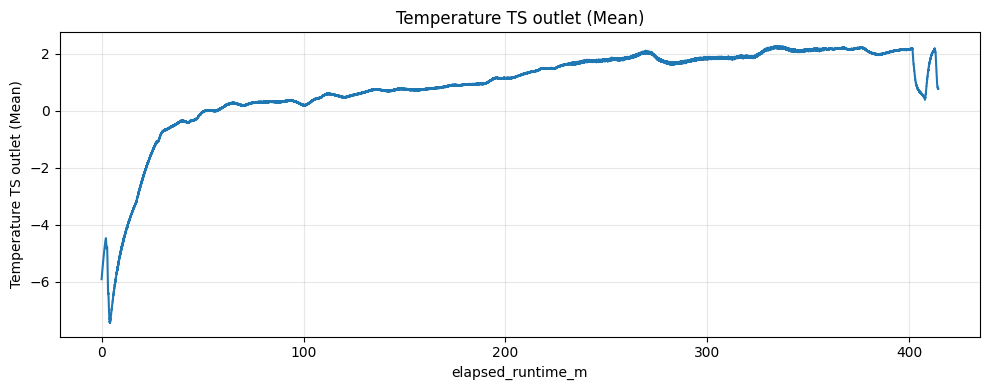

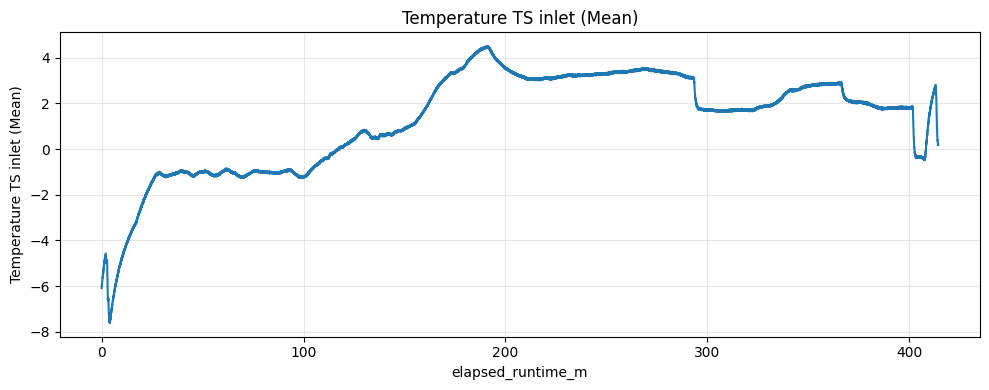

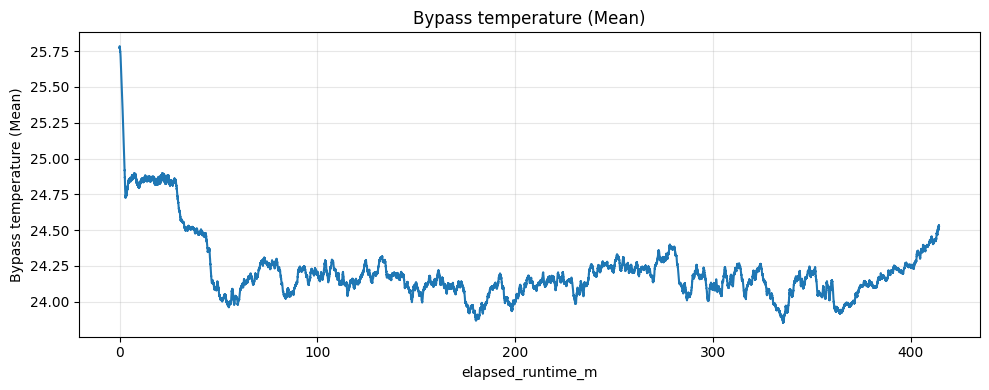

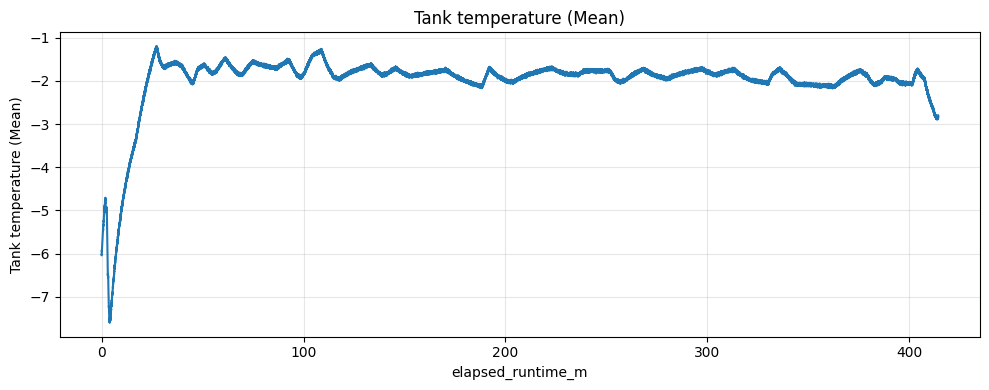

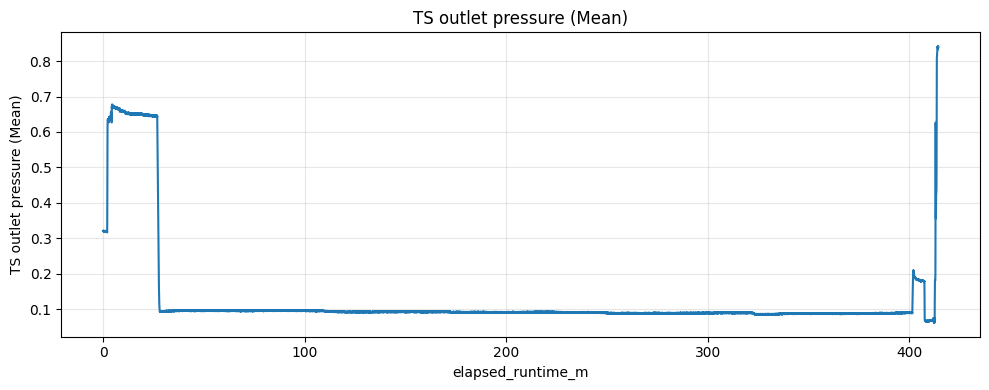

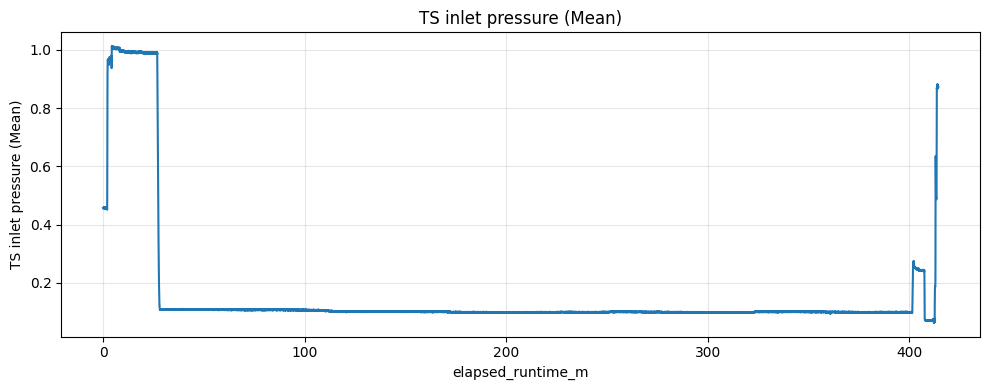

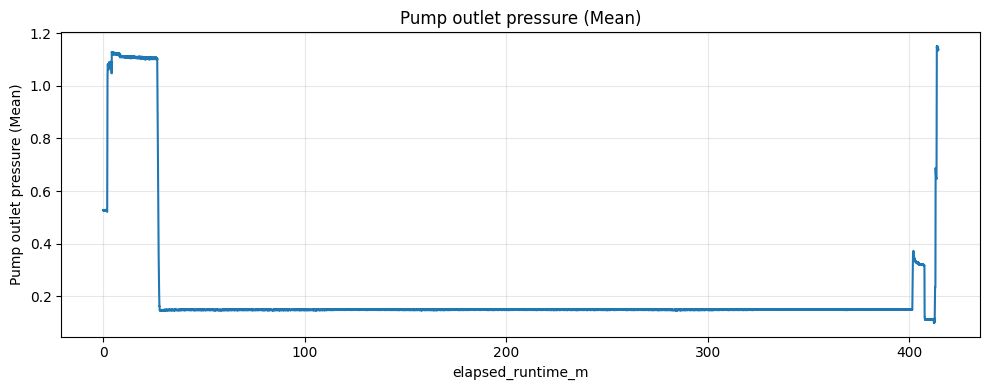

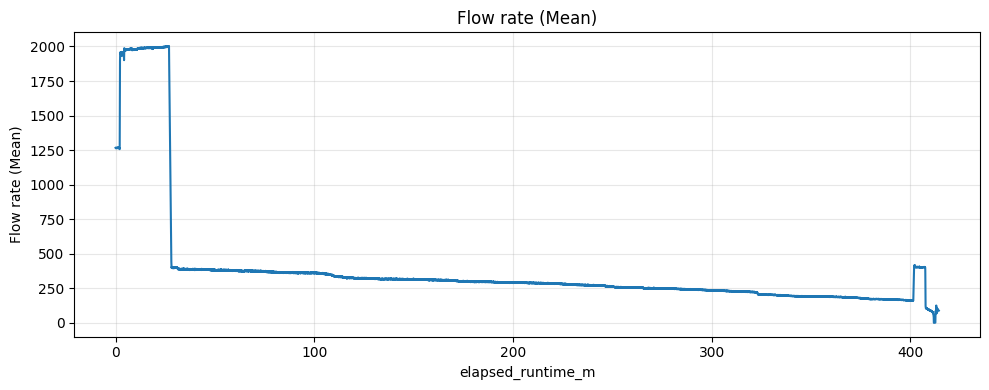

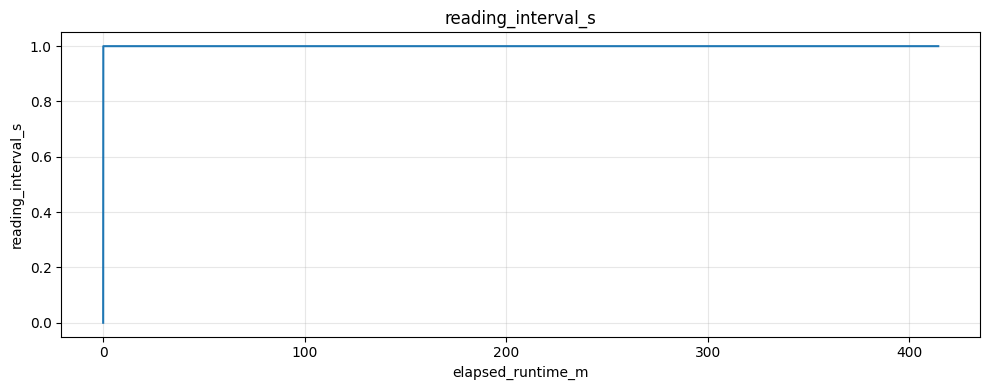

In [448]:
plot_all_timeseries(df)

### snipping

finne target flowrate 400 kg/h

In [449]:
i = 1700
df.iloc[i-5:i+5]

,Time,Temperature TS outlet (Mean),Temperature TS inlet (Mean),Bypass temperature (Mean),Tank temperature (Mean),TS outlet pressure (Mean),TS inlet pressure (Mean),Pump outlet pressure (Mean),Flow rate (Mean),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
1695,2022-03-11 14:28:35,-1.032035,-1.029180,24.842403,-1.395822,0.093783,0.109074,0.147871,404.267106,1.0,1695.0,28.250000
1696,2022-03-11 14:28:36,-1.042011,-1.086145,24.847391,-1.439527,0.094297,0.108659,0.147798,404.993187,1.0,1696.0,28.266667
1697,2022-03-11 14:28:37,-1.055400,-1.080632,24.841878,-1.456327,0.094885,0.109242,0.147017,405.054479,1.0,1697.0,28.283333
1698,2022-03-11 14:28:38,-1.032560,-1.037318,24.840040,-1.415378,0.095053,0.109368,0.147219,403.385437,1.0,1698.0,28.300000
1699,2022-03-11 14:28:39,-1.019828,-1.031280,24.842403,-1.403697,0.093788,0.108418,0.146989,403.696614,1.0,1699.0,28.316667
1700,2022-03-11 14:28:40,-1.028229,-1.067900,24.838465,-1.454359,0.093783,0.108265,0.146116,401.772973,1.0,1700.0,28.333333
1701,2022-03-11 14:28:41,-1.034661,-1.061731,24.836364,-1.459740,0.092953,0.107945,0.145868,399.641879,1.0,1701.0,28.350000
1702,2022-03-11 14:28:42,-1.011034,-1.032331,24.836627,-1.428634,0.093278,0.108061,0.146162,399.033669,1.0,1702.0,28.366667
1703,2022-03-11 14:28:43,-1.006964,-1.023011,24.842271,-1.425484,0.093142,0.108460,0.146594,400.344386,1.0,1703.0,28.383333
1704,2022-03-11 14:28:44,-1.013002,-1.057794,24.839646,-1.451602,0.092827,0.107189,0.146052,399.146824,1.0,1704.0,28.400000


In [450]:
i = 24090
df.iloc[i-5:i+5]

,Time,Temperature TS outlet (Mean),Temperature TS inlet (Mean),Bypass temperature (Mean),Tank temperature (Mean),TS outlet pressure (Mean),TS inlet pressure (Mean),Pump outlet pressure (Mean),Flow rate (Mean),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
24088,2022-03-11 20:41:45,2.176388,1.807487,24.230800,-2.089473,0.089535,0.098762,0.148349,161.275315,1.0,24085.0,401.416667
24089,2022-03-11 20:41:46,2.194896,1.856576,24.234345,-2.028704,0.088590,0.097854,0.148321,160.964138,1.0,24086.0,401.433333
24090,2022-03-11 20:41:47,2.189120,1.829669,24.235526,-2.047998,0.090480,0.099702,0.150251,160.157906,1.0,24087.0,401.450000
24091,2022-03-11 20:41:48,2.177438,1.791081,24.239070,-2.090654,0.095547,0.106433,0.159071,162.925498,1.0,24088.0,401.466667
24092,2022-03-11 20:41:49,2.173106,1.792524,24.232901,-2.088948,0.098849,0.111374,0.167403,173.807276,1.0,24089.0,401.483333
24093,2022-03-11 20:41:50,2.185182,1.831507,24.230931,-2.050623,0.103900,0.117690,0.175507,185.014375,1.0,24090.0,401.500000
24094,2022-03-11 20:41:51,2.197521,1.860777,24.233426,-2.028311,0.110085,0.125324,0.185429,196.537367,1.0,24091.0,401.516667
24095,2022-03-11 20:41:52,2.177438,1.801975,24.235526,-2.072935,0.114353,0.132176,0.196058,209.559667,1.0,24092.0,401.533333
24096,2022-03-11 20:41:53,2.181113,1.791606,24.234476,-2.092360,0.121074,0.140440,0.207432,222.308509,1.0,24093.0,401.550000
24097,2022-03-11 20:41:54,2.184263,1.801187,24.238545,-2.072935,0.126613,0.147386,0.217391,235.896587,1.0,24094.0,401.566667


In [451]:
df = snip_df_at_timecode(df, 1700, 24088)

In [452]:
df.to_csv('../data/split/partial_plug/1103.csv', index=False)

### plot after snip

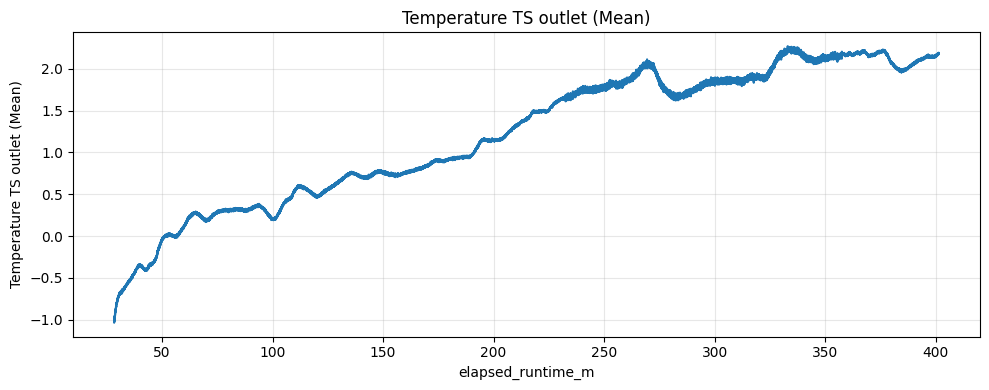

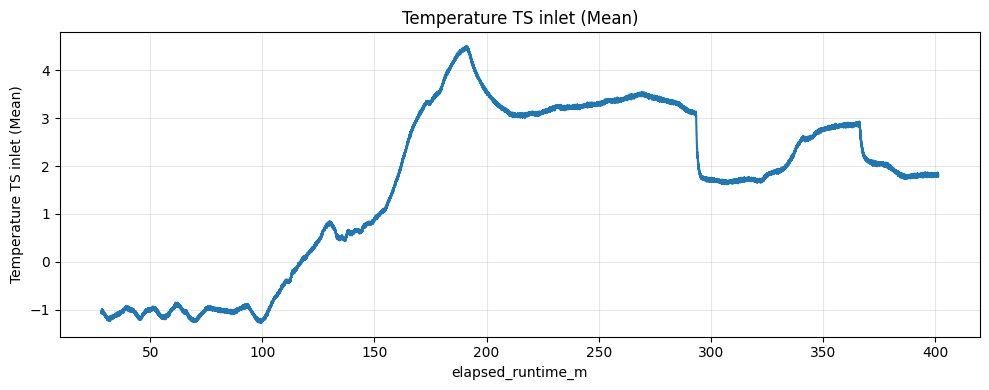

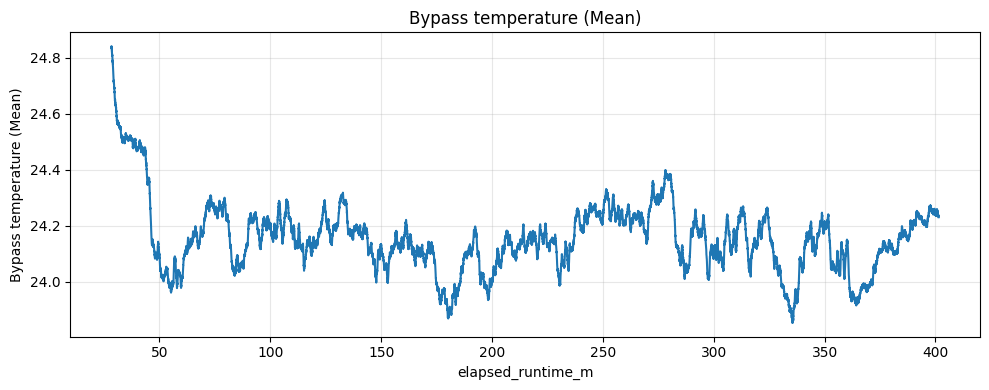

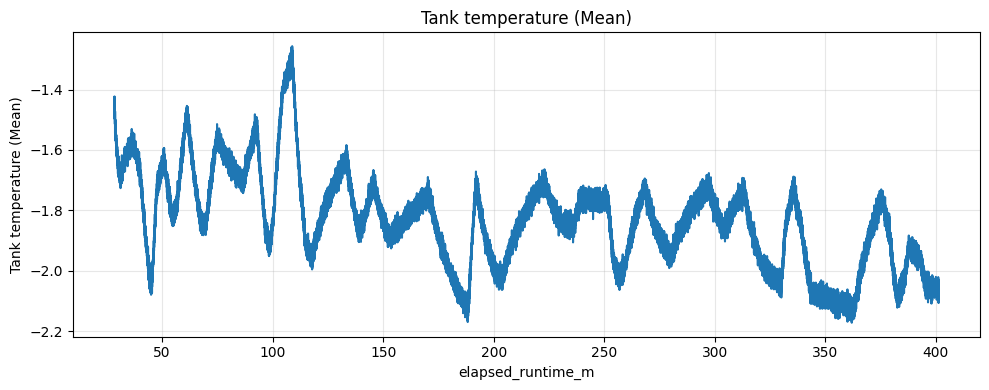

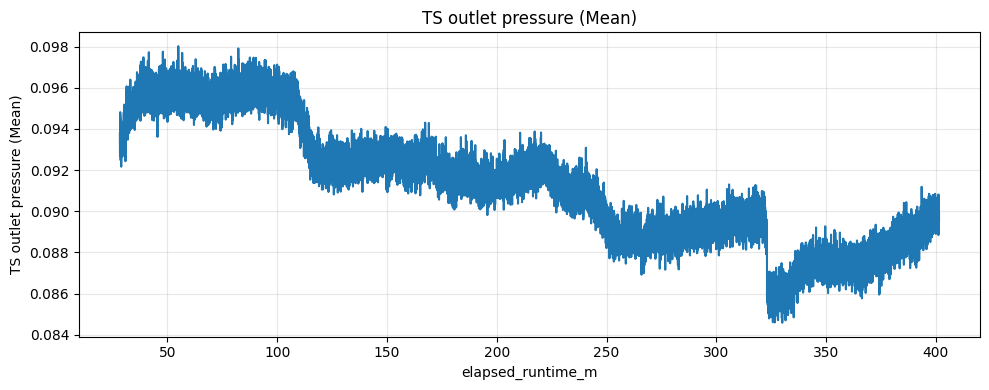

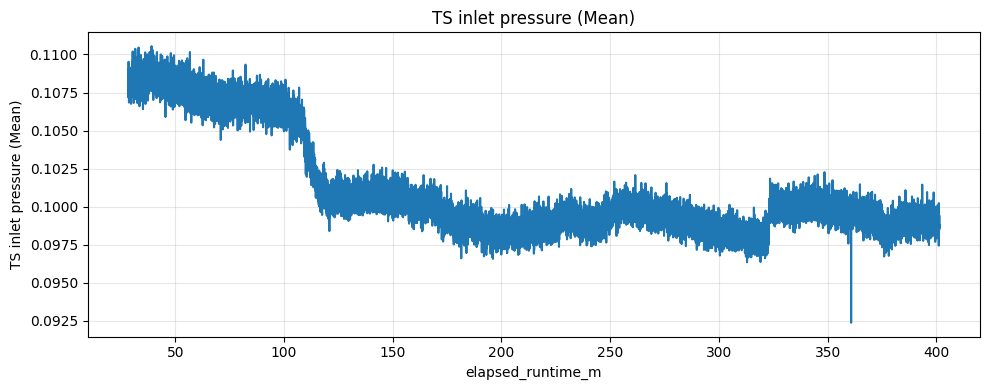

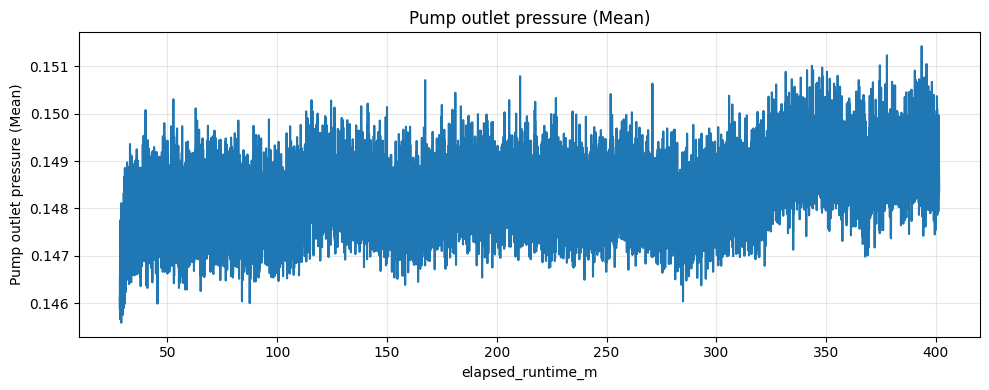

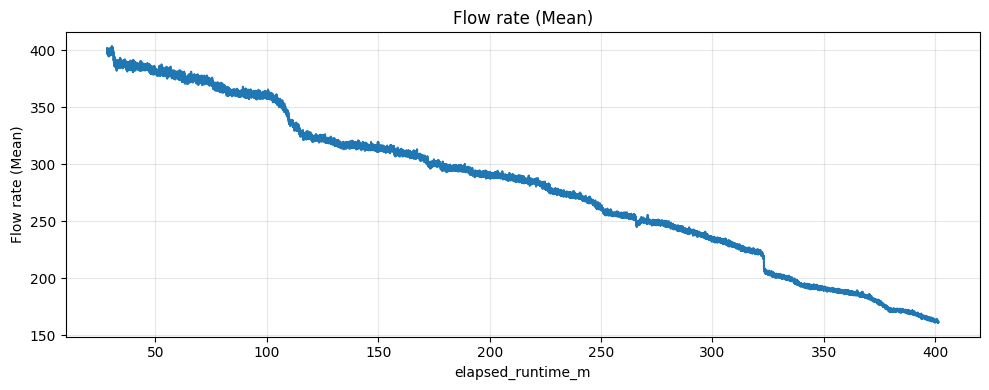

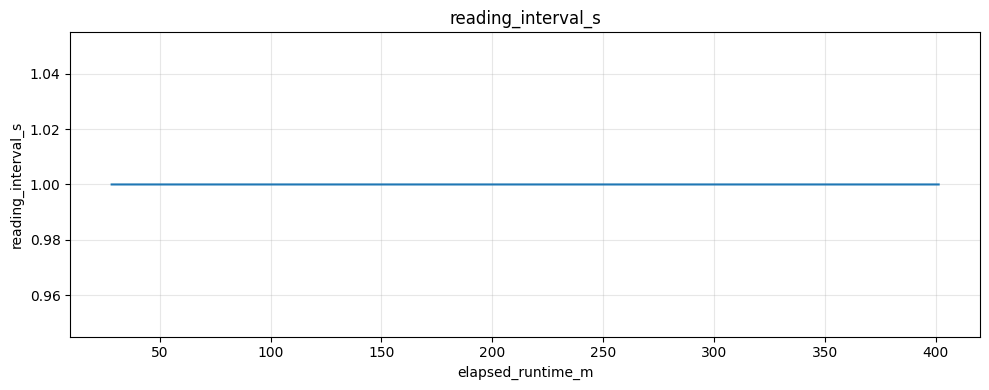

In [453]:
plot_all_timeseries(df)

## 15.03

### init

In [454]:
df = df1503.copy()

In [455]:
df = rebuild_split_time(df)

In [456]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    7751
0.0       1
Name: count, dtype: int64

In [457]:
df.drop(columns = ['Unnamed: 4', 'Unnamed: 13', 'Unnamed: 14'], inplace = True)

In [458]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


### plotting

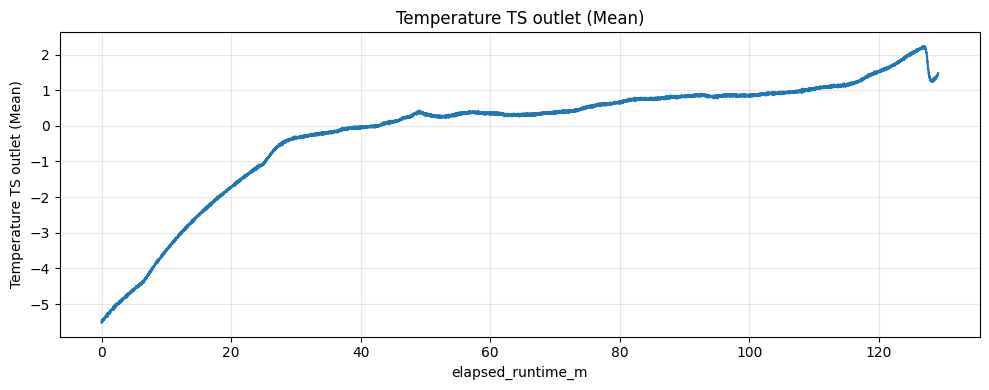

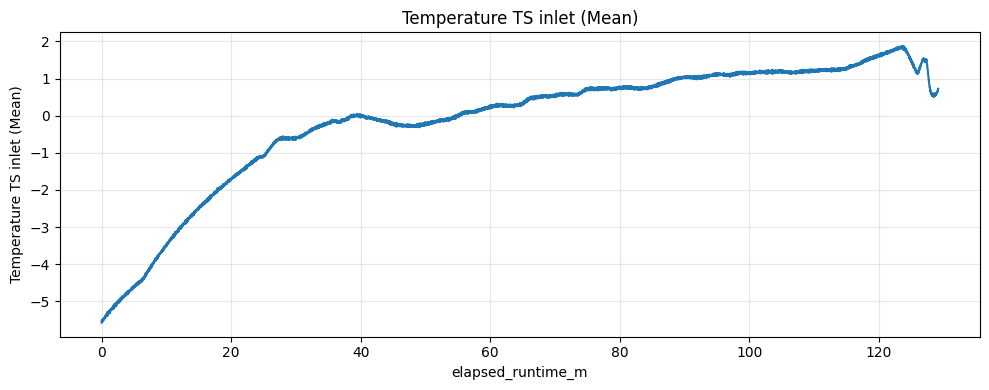

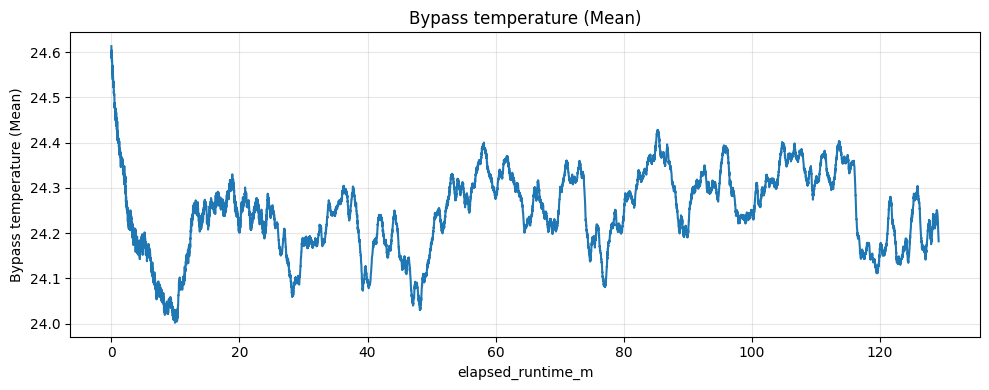

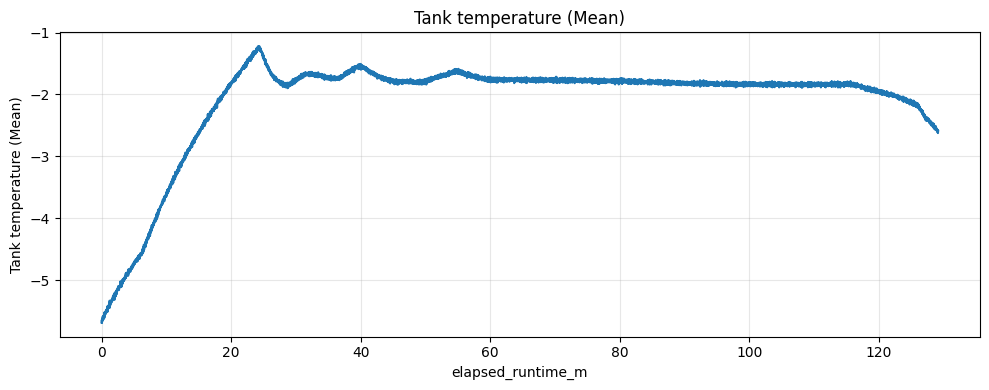

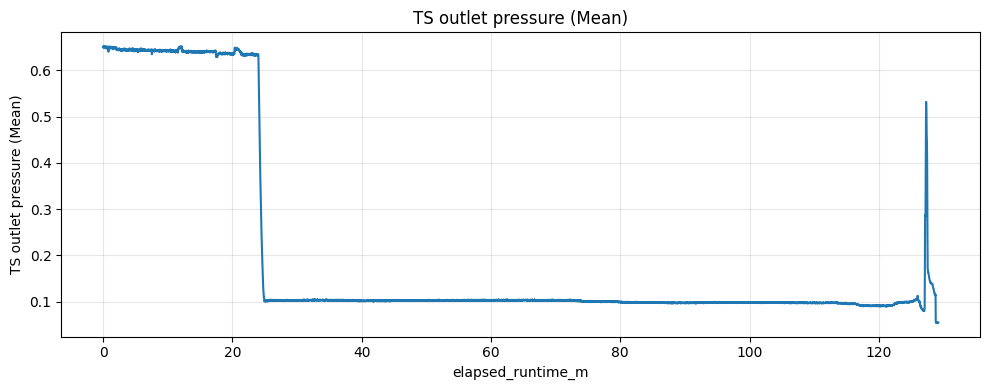

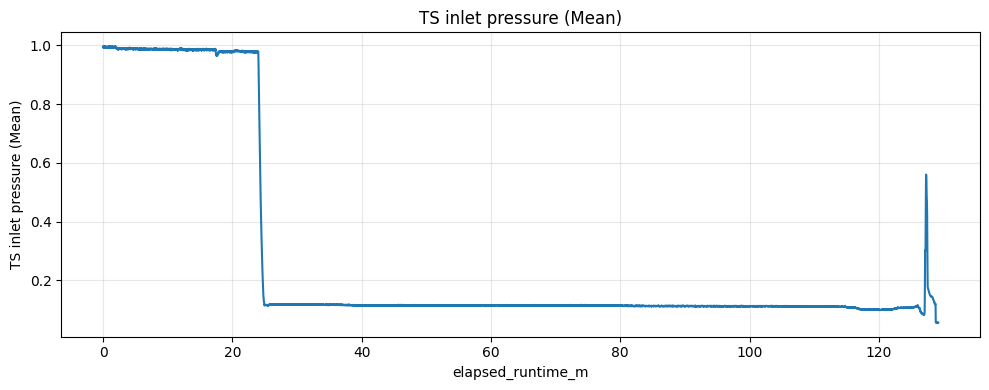

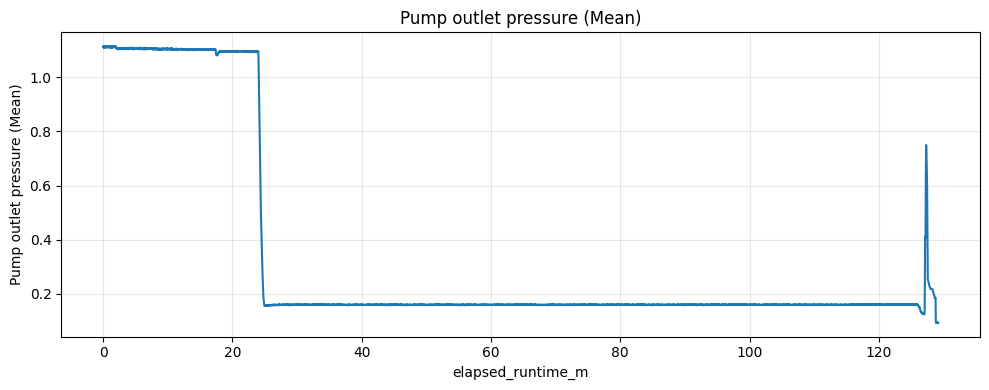

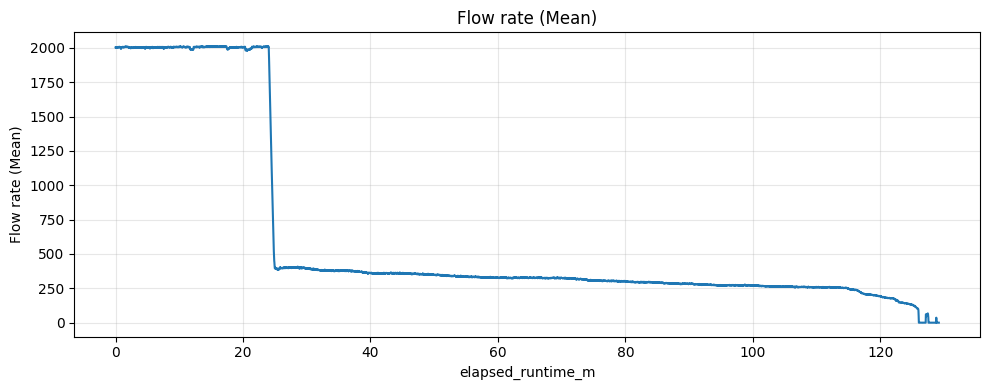

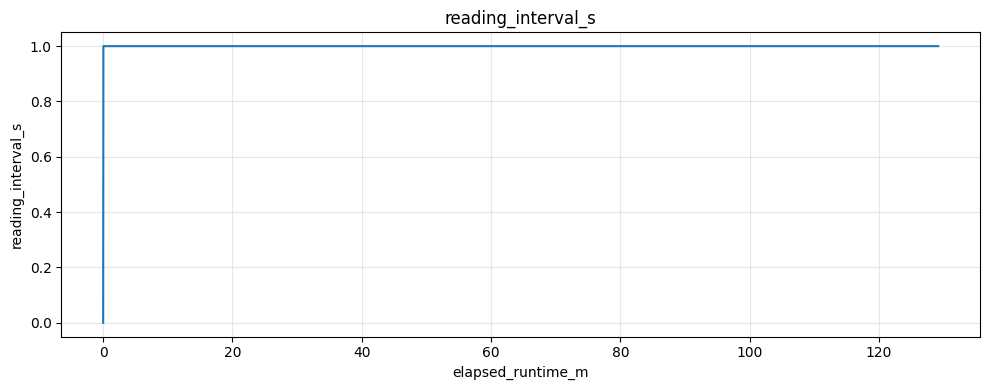

In [459]:
plot_all_timeseries(df)

### snipping

finne target flowrate 400 kg/h

In [460]:
i = 1500
df.iloc[i-5:i+5]

,Time,Temperature TS outlet (Mean),Temperature TS inlet (Mean),Bypass temperature (Mean),Tank temperature (Mean),TS outlet pressure (Mean),TS inlet pressure (Mean),Pump outlet pressure (Mean),Flow rate (Mean),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
1495,2022-03-15 13:09:59,-1.100948,-1.109246,24.238414,-1.383747,0.107943,0.124106,0.164307,443.093553,1.0,1495.0,24.916667
1496,2022-03-15 13:10:00,-1.062094,-1.088114,24.241040,-1.358284,0.105885,0.121308,0.161046,433.838384,1.0,1496.0,24.933333
1497,2022-03-15 13:10:01,-1.052250,-1.083257,24.244715,-1.356578,0.102619,0.117265,0.157031,422.136230,1.0,1497.0,24.950000
1498,2022-03-15 13:10:02,-1.083621,-1.105439,24.246947,-1.388603,0.100724,0.114582,0.155249,406.827247,1.0,1498.0,24.966667
1499,2022-03-15 13:10:03,-1.095697,-1.120533,24.248260,-1.424565,0.101621,0.115763,0.155340,395.785166,1.0,1499.0,24.983333
1500,2022-03-15 13:10:04,-1.052381,-1.105045,24.249310,-1.391490,0.103055,0.116734,0.157196,394.922356,1.0,1500.0,25.000000
1501,2022-03-15 13:10:05,-1.033610,-1.064094,24.247866,-1.371934,0.102619,0.117443,0.157545,399.429713,1.0,1501.0,25.016667
1502,2022-03-15 13:10:06,-1.061175,-1.078926,24.249704,-1.404484,0.101989,0.115590,0.156599,402.720649,1.0,1502.0,25.033333
1503,2022-03-15 13:10:07,-1.081783,-1.107933,24.254955,-1.411309,0.102603,0.117091,0.157242,399.358991,1.0,1503.0,25.050000
1504,2022-03-15 13:10:08,-1.059600,-1.091920,24.251016,-1.433228,0.102031,0.116246,0.156057,399.179828,1.0,1504.0,25.066667


In [461]:
i = 7564
df.iloc[i-5:i+5]

,Time,Temperature TS outlet (Mean),Temperature TS inlet (Mean),Bypass temperature (Mean),Tank temperature (Mean),TS outlet pressure (Mean),TS inlet pressure (Mean),Pump outlet pressure (Mean),Flow rate (Mean),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
7559,2022-03-15 14:51:03,2.101963,1.131265,24.280947,-2.214815,0.111161,0.114881,0.160605,88.162783,1.0,7559.0,125.983333
7560,2022-03-15 14:51:04,2.125721,1.152922,24.281603,-2.183578,0.113093,0.116052,0.160109,74.103224,1.0,7560.0,126.000000
7561,2022-03-15 14:51:05,2.159061,1.178254,24.282784,-2.141054,0.107334,0.112639,0.158354,49.251470,1.0,7561.0,126.016667
7562,2022-03-15 14:51:06,2.122439,1.164604,24.274777,-2.174522,0.106005,0.111610,0.158225,3.805433,1.0,7562.0,126.033333
7563,2022-03-15 14:51:07,2.102094,1.132315,24.272283,-2.201691,0.105748,0.111248,0.158271,0.179745,1.0,7563.0,126.050000
7564,2022-03-15 14:51:08,2.124146,1.142159,24.273070,-2.197622,0.105538,0.111169,0.157803,0.637081,1.0,7564.0,126.066667
7565,2022-03-15 14:51:09,2.141604,1.177204,24.275171,-2.153916,0.104388,0.109400,0.157205,0.330619,1.0,7565.0,126.083333
7566,2022-03-15 14:51:10,2.157486,1.186655,24.268082,-2.154835,0.104499,0.109610,0.156654,0.429630,1.0,7566.0,126.100000
7567,2022-03-15 14:51:11,2.107869,1.144391,24.270970,-2.195784,0.103202,0.108439,0.154854,0.311760,1.0,7567.0,126.116667
7568,2022-03-15 14:51:12,2.110232,1.163291,24.270051,-2.206547,0.102325,0.107903,0.152786,0.118452,1.0,7568.0,126.133333


In [462]:
df = snip_df_at_timecode(df, 1498, 7562)

In [463]:
df.to_csv('../data/split/plug/1503.csv', index=False)

### plot after snip

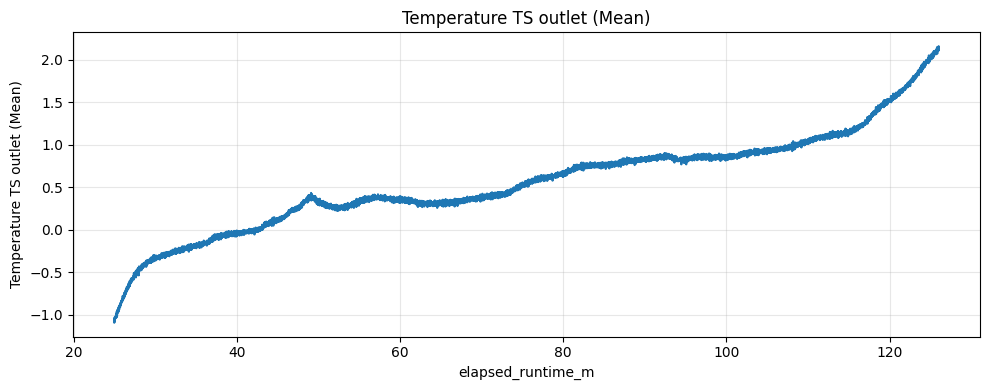

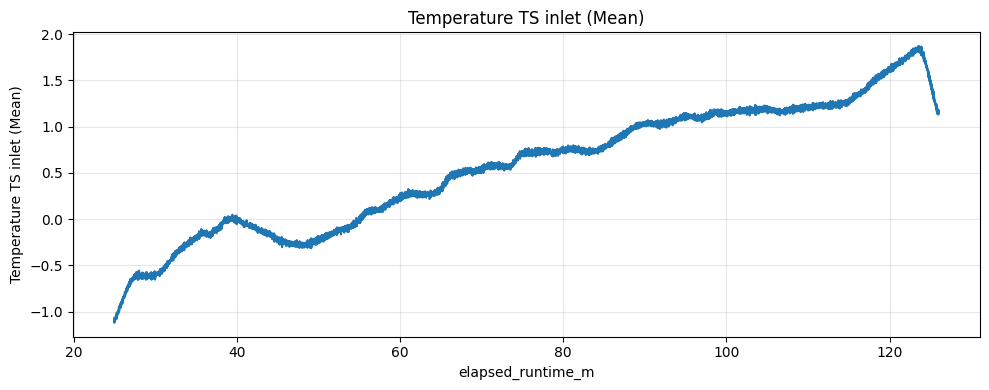

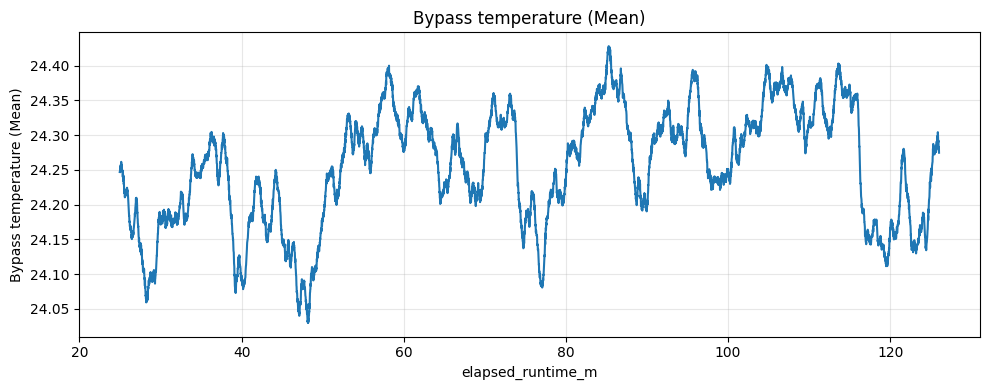

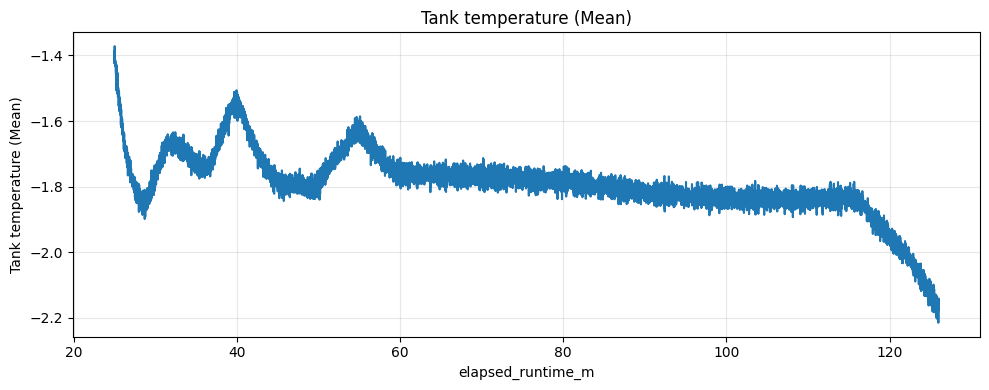

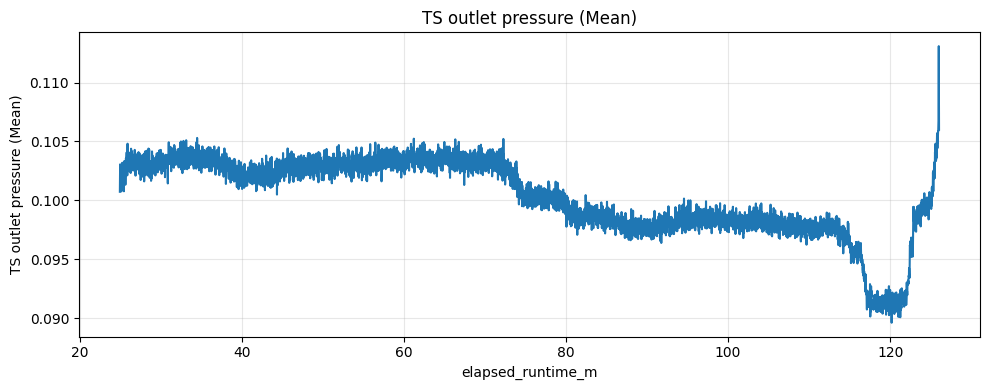

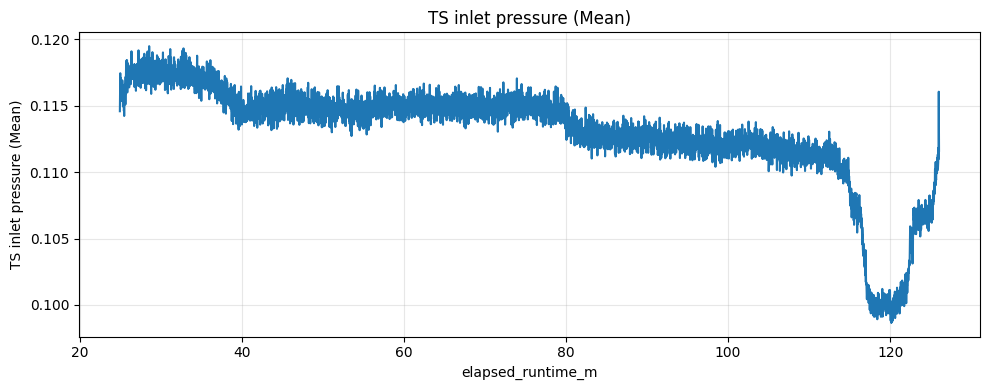

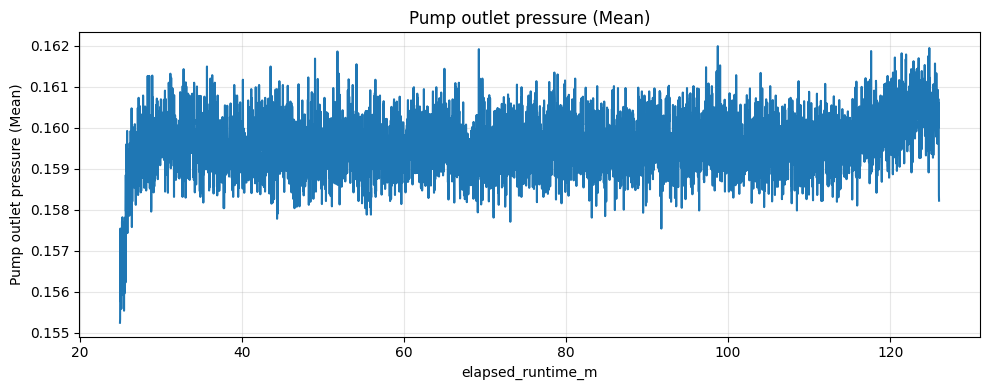

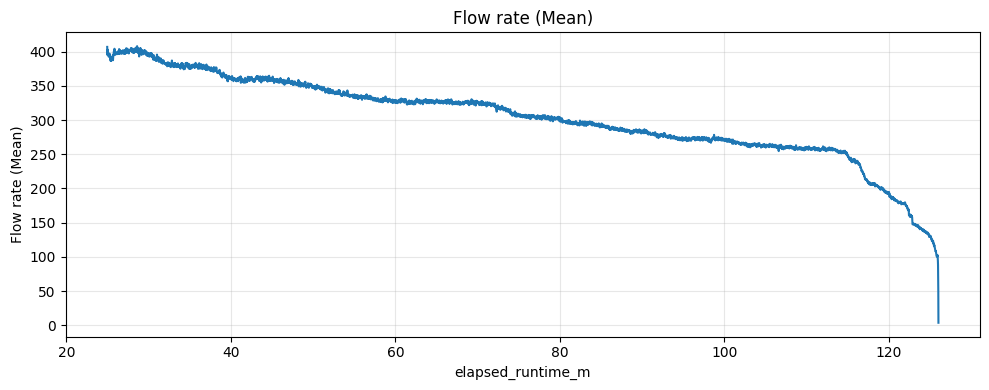

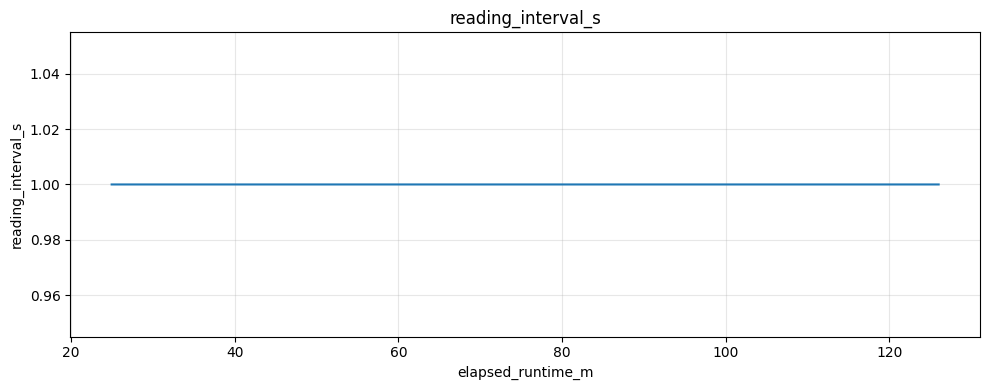

In [464]:
plot_all_timeseries(df)

## 25.03

### init

In [465]:
df = df2503.copy()

In [466]:
basic_checklist(df)

Missing values:
Time                              0
Unnamed: 1                      821
Temperature TS outlet (Mean)      0
Temperature TS inlet (Mean)       0
Bypass temperature (Mean)         0
Tank temperature (Mean)           0
TS outlet pressure (Mean)         0
TS inlet pressure (Mean)          0
Pump outlet pressure (Mean)       0
Flow rate (Mean)                  0
Unnamed: 10                       0
Unnamed: 11                       0
dtype: int64

Time column is monotonic increasing.


In [467]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    15390
0.0        1
Name: count, dtype: int64

In [468]:
df.drop(columns = ['Unnamed: 1', 'Unnamed: 10', 'Unnamed: 11'], inplace = True)

### plotting


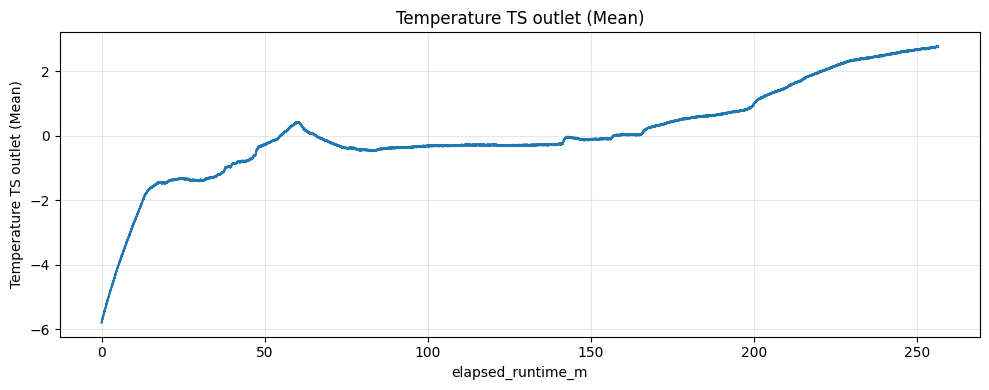

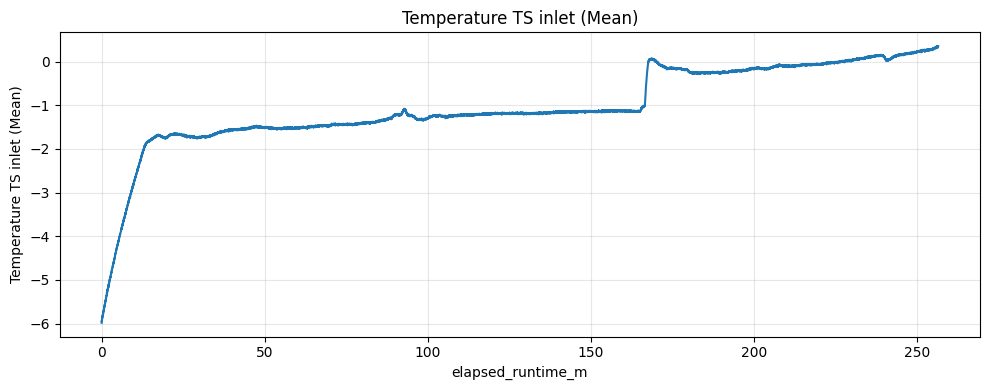

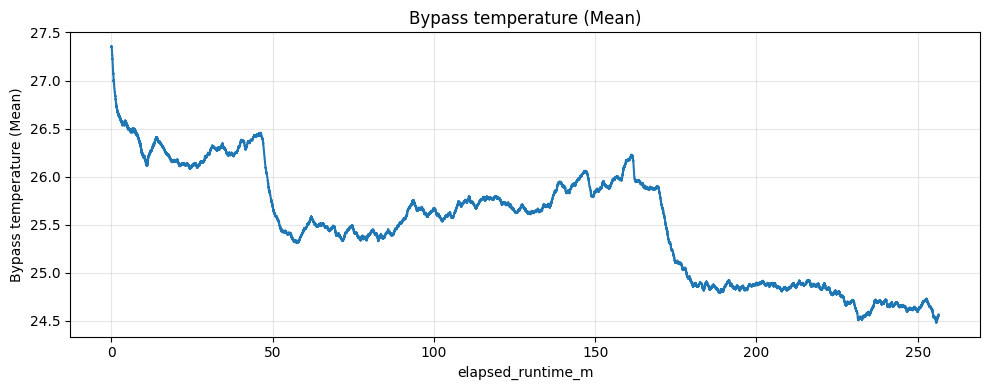

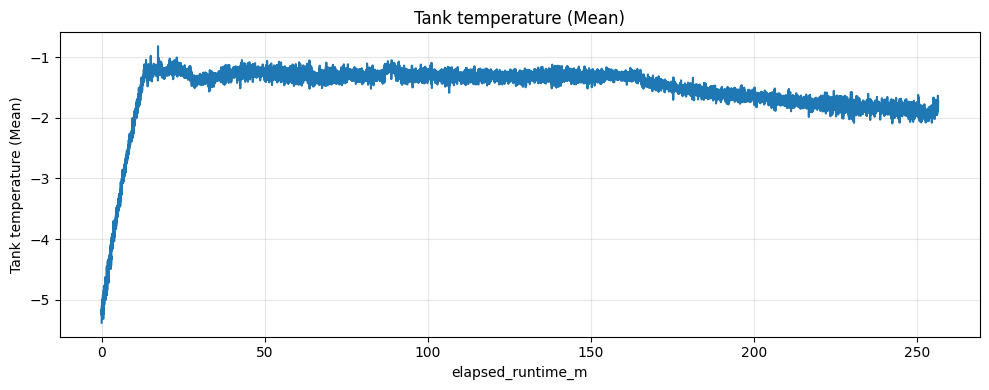

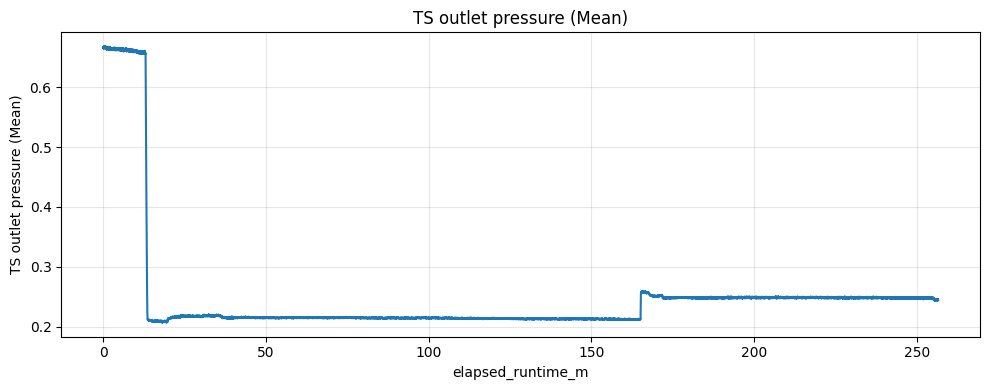

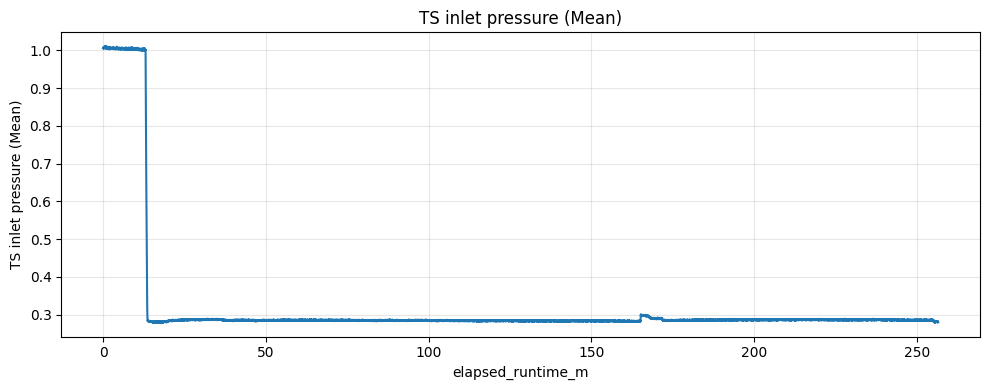

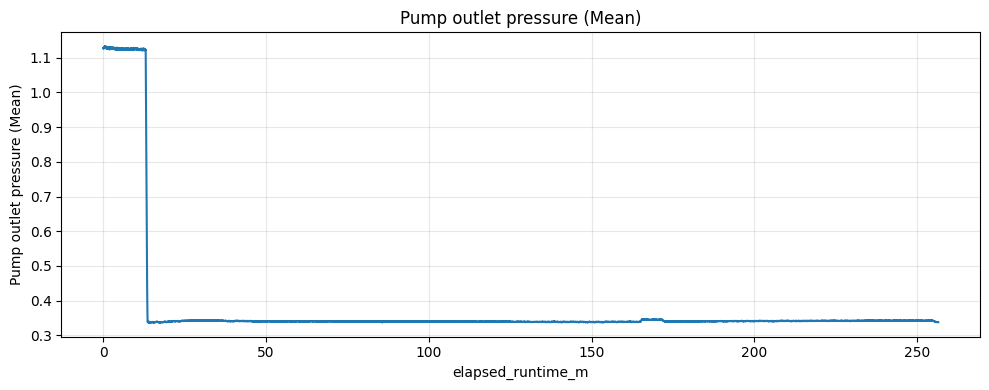

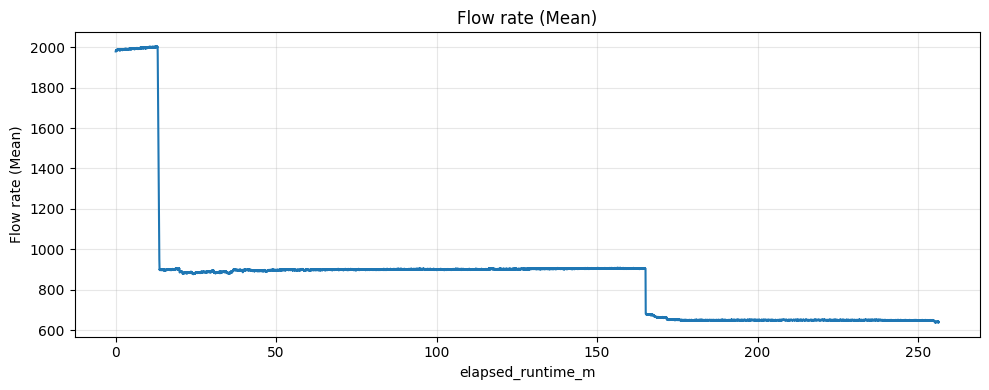

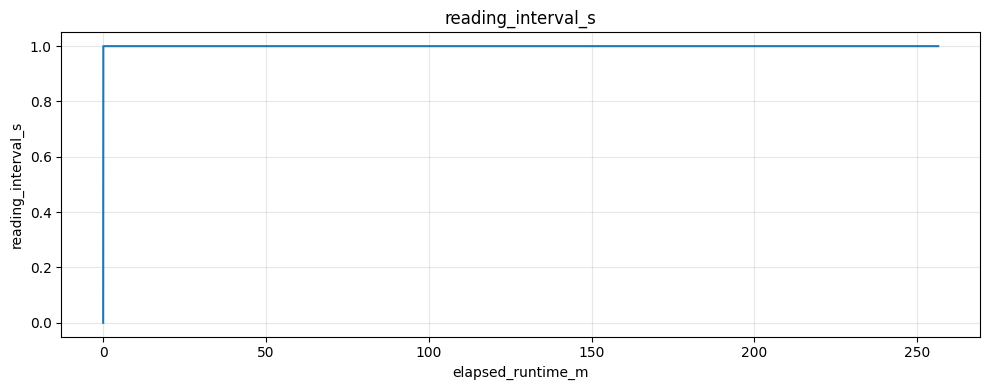

In [469]:
plot_all_timeseries(df)

### snipping

finne target flowrate 900 kg/h

In [470]:
i = 823
df.iloc[i-5:i+5]

,Time,Temperature TS outlet (Mean),Temperature TS inlet (Mean),Bypass temperature (Mean),Tank temperature (Mean),TS outlet pressure (Mean),TS inlet pressure (Mean),Pump outlet pressure (Mean),Flow rate (Mean),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
818,2022-03-25 13:57:40.474,-1.782457,-1.879183,26.380533,-1.226248,0.217707,0.292697,0.348512,924.206737,1.0,818.0,13.633333
819,2022-03-25 13:57:41.474,-1.794402,-1.880365,26.390772,-1.320222,0.212782,0.285441,0.341346,916.653614,1.0,819.0,13.650000
820,2022-03-25 13:57:42.474,-1.781013,-1.864614,26.379745,-1.257879,0.212488,0.284606,0.339518,905.356934,1.0,820.0,13.666667
821,2022-03-25 13:57:43.474,-1.775106,-1.862514,26.380664,-1.223885,0.212672,0.284081,0.338599,899.161676,1.0,821.0,13.683333
822,2022-03-25 13:57:44.474,-1.787314,-1.878264,26.380270,-1.195273,0.212394,0.284910,0.339729,897.718944,1.0,822.0,13.700000
823,2022-03-25 13:57:45.474,-1.774844,-1.862383,26.382370,-1.244623,0.212667,0.285057,0.340519,899.883041,1.0,823.0,13.716667
824,2022-03-25 13:57:46.474,-1.773269,-1.864351,26.391428,-1.238848,0.210903,0.283619,0.338085,901.641665,1.0,824.0,13.733333
825,2022-03-25 13:57:47.474,-1.765524,-1.858576,26.395892,-1.206167,0.211312,0.283083,0.338278,898.977798,1.0,825.0,13.750000
826,2022-03-25 13:57:48.474,-1.771562,-1.863695,26.396023,-1.159442,0.210887,0.282989,0.337699,897.308756,1.0,826.0,13.766667
827,2022-03-25 13:57:49.474,-1.756861,-1.862908,26.388672,-1.268379,0.211800,0.283440,0.339509,896.577961,1.0,827.0,13.783333


In [471]:
df = snip_df_at_timecode(df, 823, 0)

In [472]:
df.to_csv('../data/split/partial_plug/2503.csv', index = False)

### plot after snip

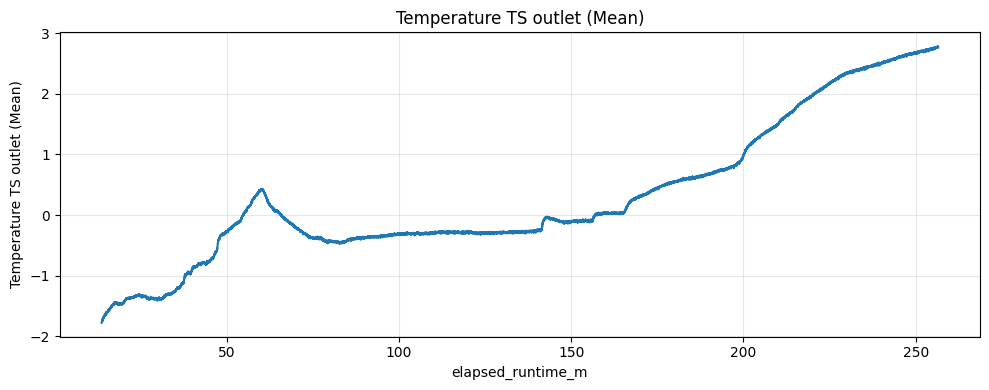

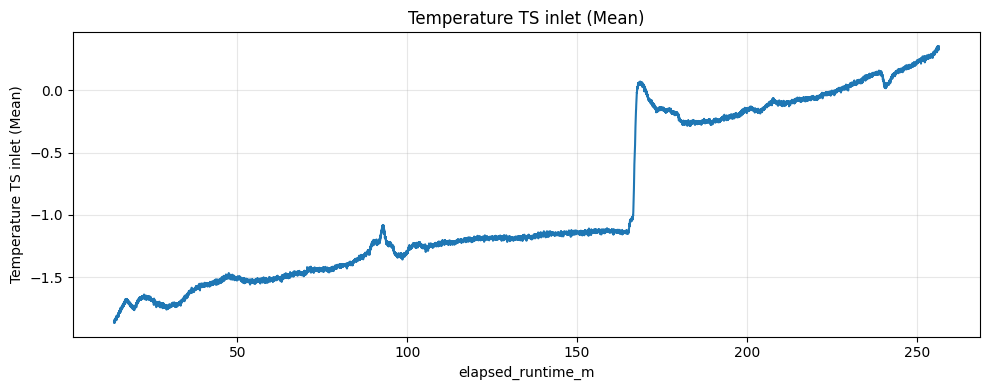

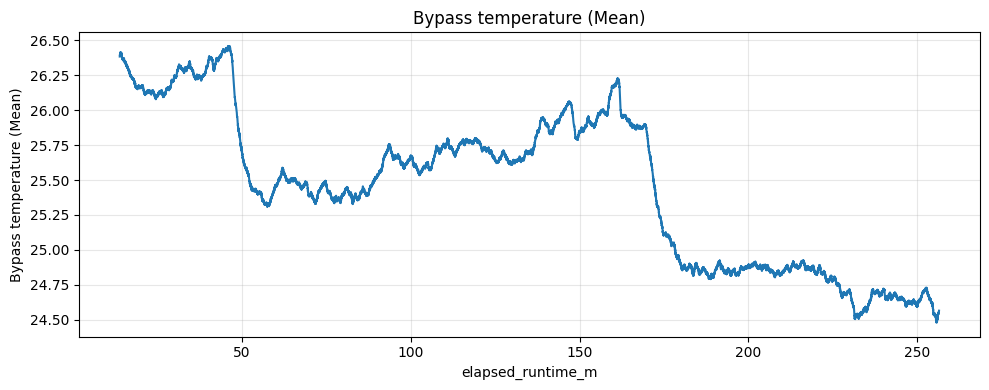

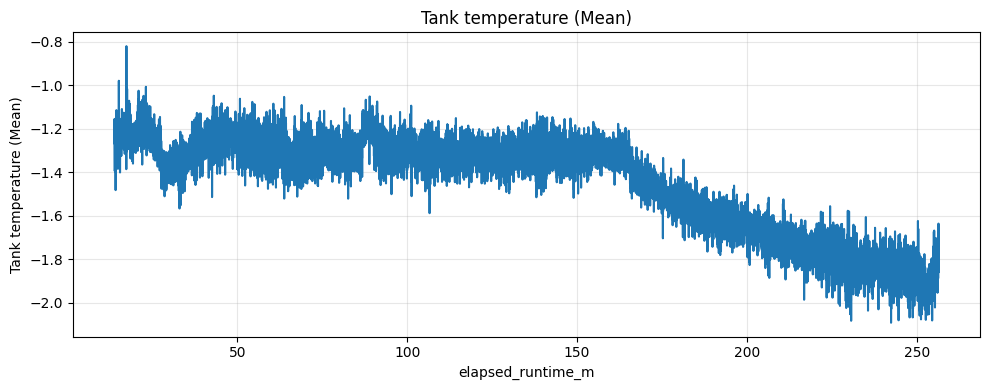

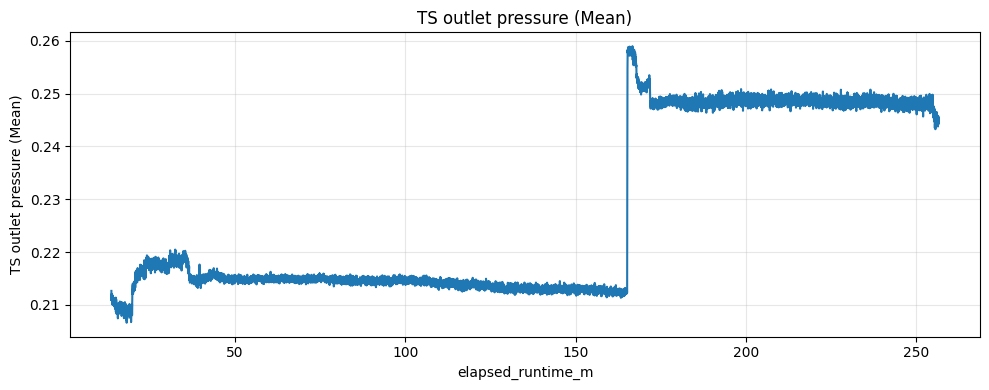

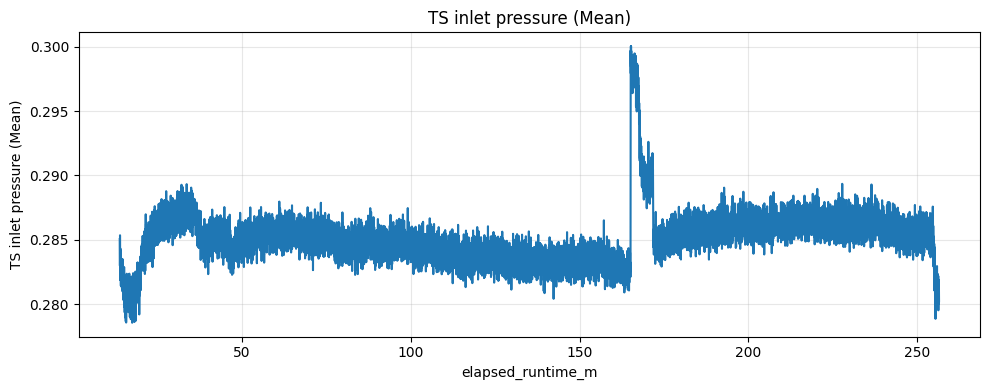

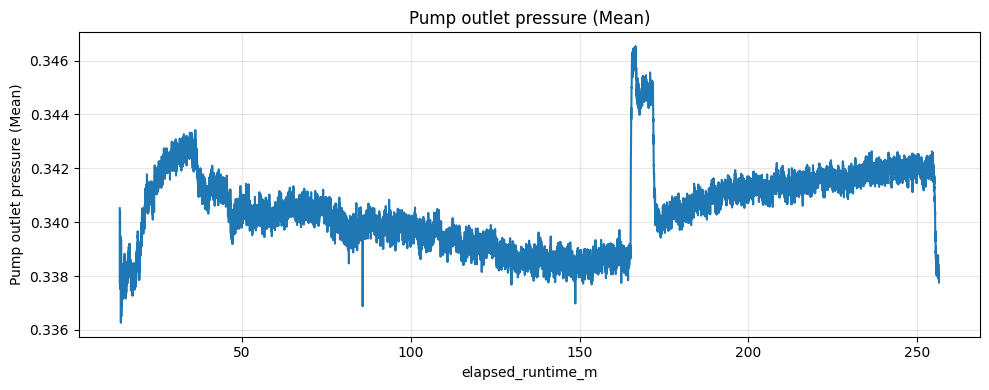

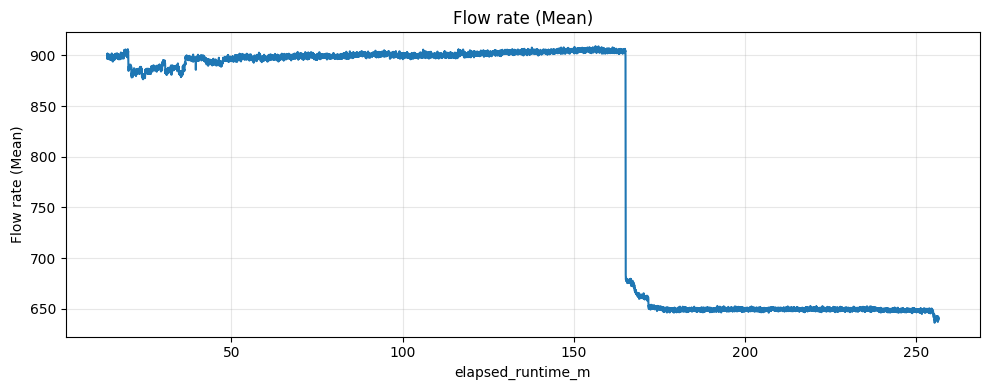

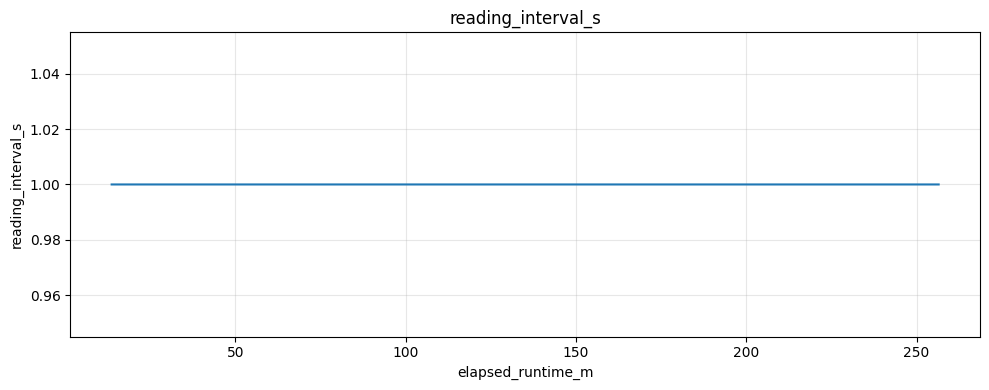

In [473]:
plot_all_timeseries(df)

## 04.04

### init


In [474]:
df = df0404.copy()

In [475]:
basic_checklist(df)

Missing values:
Time                                0
Unnamed: 1                      14054
Temperature TS outlet (Mean)        0
Temperature TS inlet (Mean)         0
Bypass temperature (Mean)           0
Tank temperature (Mean)             0
TS outlet pressure (Mean)           0
TS inlet pressure (Mean)            0
Pump outlet pressure (Mean)         0
Flow rate (Mean)                    0
Unnamed: 10                         0
Unnamed: 11                         0
dtype: int64

Time column is monotonic increasing.


In [476]:
df.drop(columns = ['Unnamed: 1', 'Unnamed: 10', 'Unnamed: 11'], inplace = True)

In [477]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    33366
0.0        1
Name: count, dtype: int64

### plotting


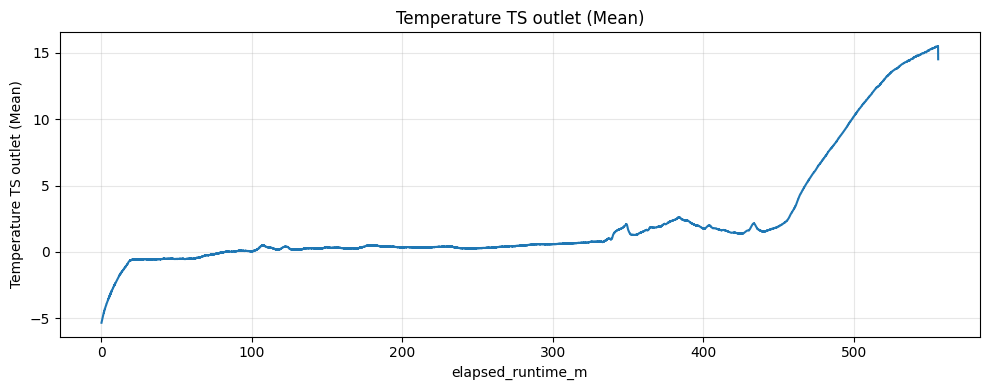

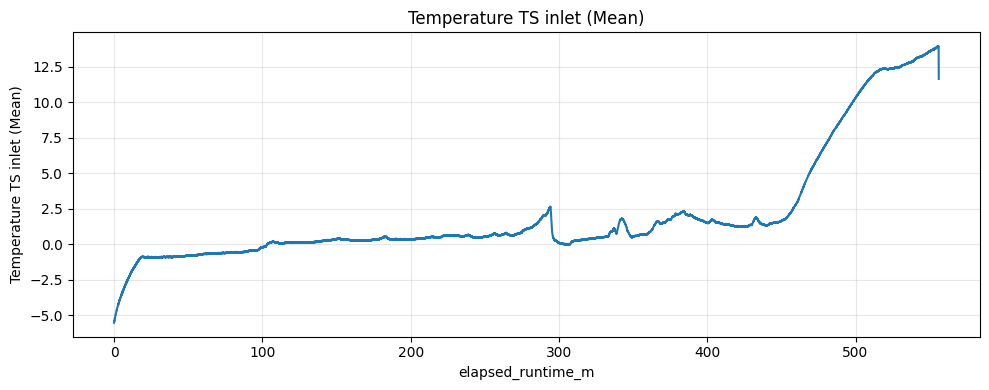

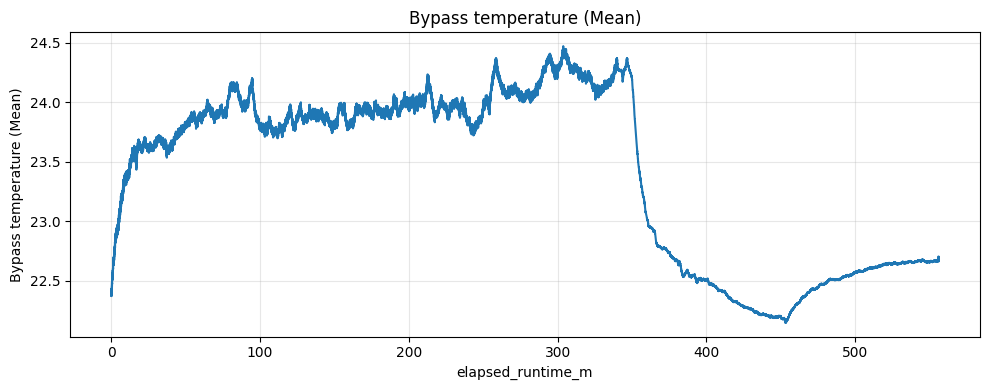

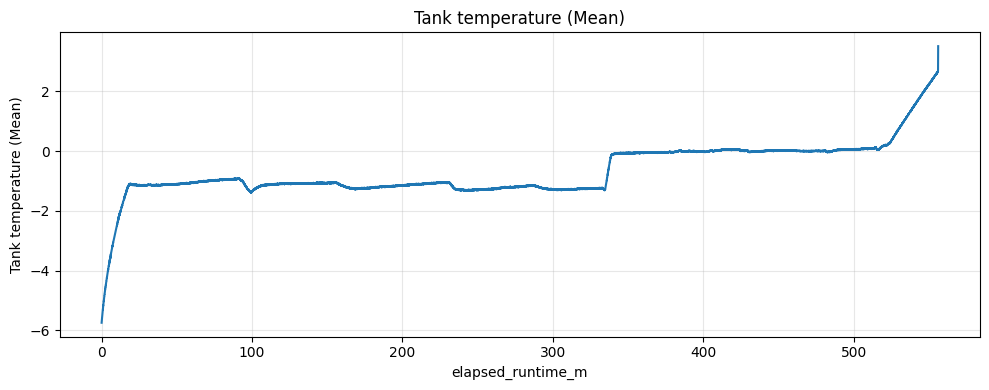

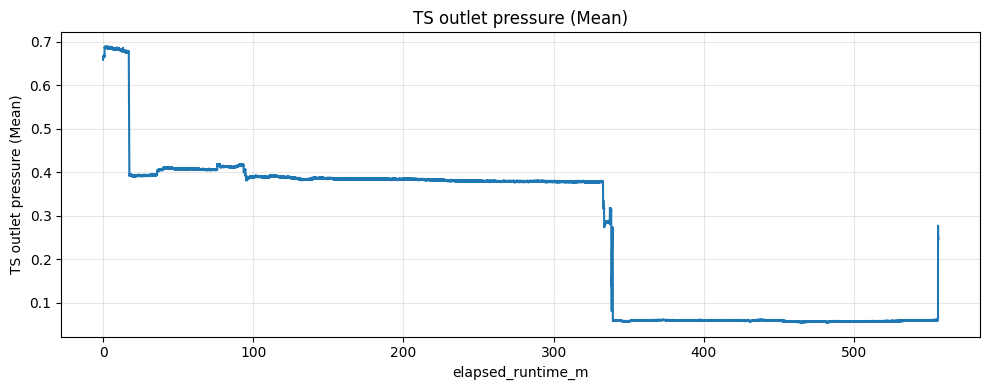

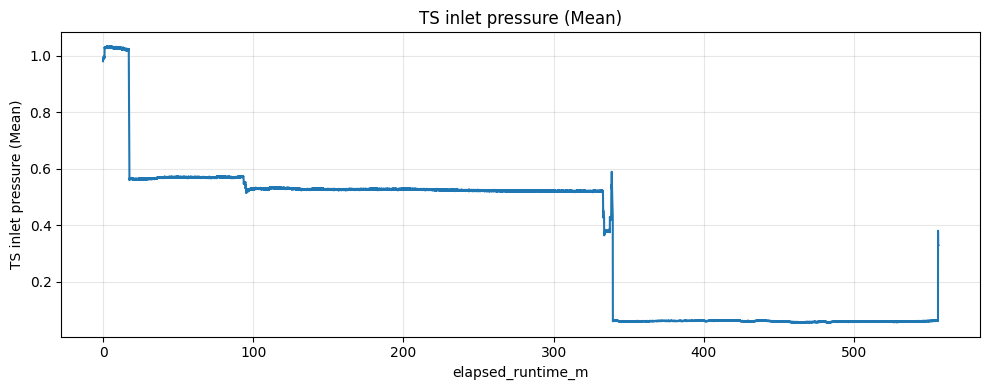

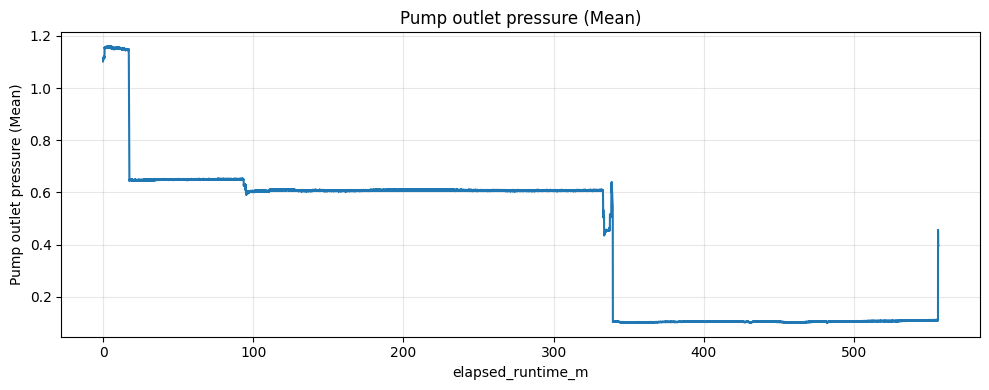

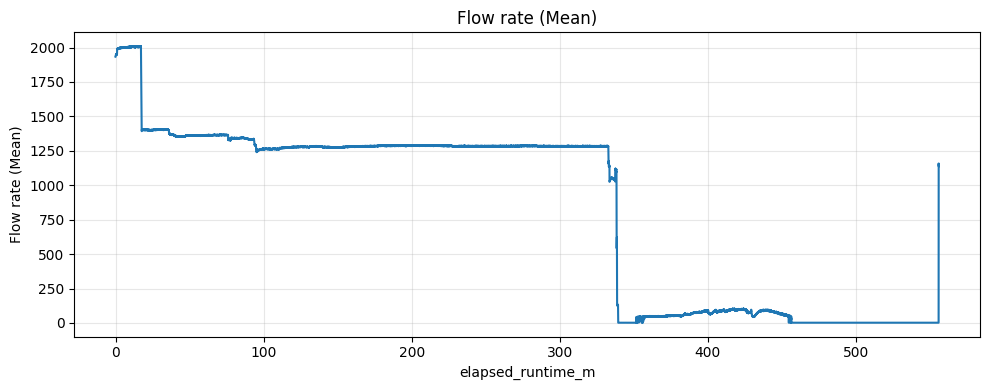

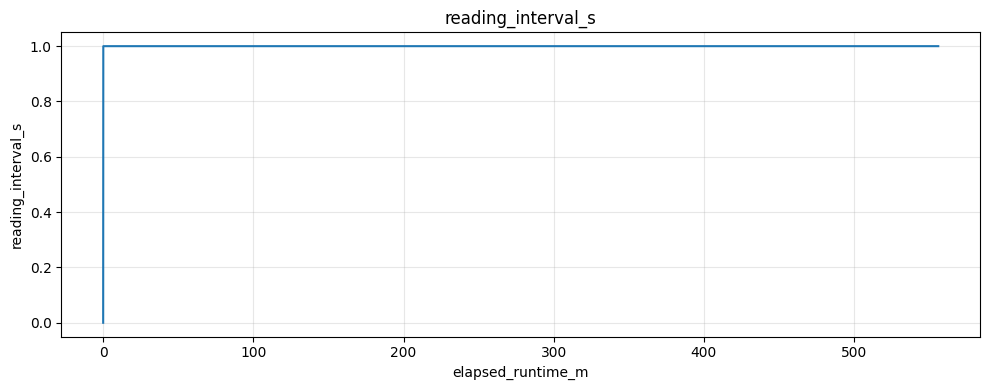

In [478]:
plot_all_timeseries(df)

### snipping

finne target flowrate 1400 kg/h

In [479]:
i = 1053
df.loc[i-5:i+5]

,Time,Temperature TS outlet (Mean),Temperature TS inlet (Mean),Bypass temperature (Mean),Tank temperature (Mean),TS outlet pressure (Mean),TS inlet pressure (Mean),Pump outlet pressure (Mean),Flow rate (Mean),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
1048,2022-04-04 11:46:16.233,-0.861133,-1.000042,23.580997,-1.198029,0.415856,0.599794,0.687183,1483.156692,1.0,1048.0,17.466667
1049,2022-04-04 11:46:17.233,-0.858770,-1.009099,23.588611,-1.184117,0.405371,0.582583,0.668376,1457.060228,1.0,1049.0,17.483333
1050,2022-04-04 11:46:18.233,-0.857195,-0.999911,23.568001,-1.190286,0.402084,0.577511,0.662533,1432.345203,1.0,1050.0,17.500000
1051,2022-04-04 11:46:19.233,-0.855489,-1.001880,23.586642,-1.183986,0.401827,0.576109,0.660861,1419.978261,1.0,1051.0,17.516667
1052,2022-04-04 11:46:20.233,-0.846825,-0.994267,23.585067,-1.191336,0.394051,0.562888,0.647319,1414.975849,1.0,1052.0,17.533333
1053,2022-04-04 11:46:21.233,-0.847088,-1.003192,23.588348,-1.182936,0.392408,0.561686,0.645454,1402.203434,1.0,1053.0,17.550000
1054,2022-04-04 11:46:22.233,-0.845250,-1.006473,23.574171,-1.186348,0.394440,0.563813,0.648128,1397.710221,1.0,1054.0,17.566667
1055,2022-04-04 11:46:23.233,-0.835012,-0.995842,23.614472,-1.177423,0.393033,0.561219,0.646253,1397.064293,1.0,1055.0,17.583333
1056,2022-04-04 11:46:24.233,-0.834224,-0.988360,23.599375,-1.165742,0.393815,0.563093,0.646722,1395.918594,1.0,1056.0,17.600000
1057,2022-04-04 11:46:25.233,-0.829893,-0.989935,23.607252,-1.171779,0.393253,0.561880,0.646134,1397.460337,1.0,1057.0,17.616667


In [480]:
i = 19970
df.loc[i-5:i+5]

,Time,Temperature TS outlet (Mean),Temperature TS inlet (Mean),Bypass temperature (Mean),Tank temperature (Mean),TS outlet pressure (Mean),TS inlet pressure (Mean),Pump outlet pressure (Mean),Flow rate (Mean),reading_interval_s,elapsed_runtime_s,elapsed_runtime_m
19965,2022-04-04 17:01:33.233,0.751282,0.527758,24.162407,-1.230054,0.377681,0.519798,0.607566,1282.697187,1.0,19965.0,332.750000
19966,2022-04-04 17:01:34.233,0.750889,0.513451,24.156500,-1.233467,0.377239,0.519588,0.607327,1282.918783,1.0,19966.0,332.766667
19967,2022-04-04 17:01:35.233,0.753514,0.517258,24.154793,-1.230185,0.376751,0.517840,0.605379,1282.885780,1.0,19967.0,332.783333
19968,2022-04-04 17:01:36.233,0.755614,0.535108,24.171202,-1.235304,0.377759,0.519867,0.607786,1281.325178,1.0,19968.0,332.800000
19969,2022-04-04 17:01:37.233,0.745507,0.528546,24.133789,-1.237142,0.378074,0.519982,0.607740,1282.084262,1.0,19969.0,332.816667
19970,2022-04-04 17:01:38.233,0.747082,0.528414,24.130639,-1.233860,0.376756,0.518197,0.606472,1283.390264,1.0,19970.0,332.833333
19971,2022-04-04 17:01:39.233,0.751808,0.514370,24.152036,-1.243179,0.371160,0.509371,0.595641,1280.731112,1.0,19971.0,332.850000
19972,2022-04-04 17:01:40.233,0.743013,0.520670,24.130901,-1.229529,0.370314,0.508142,0.595705,1270.056786,1.0,19972.0,332.866667
19973,2022-04-04 17:01:41.233,0.745638,0.510695,24.156368,-1.221654,0.372850,0.511529,0.599205,1267.477786,1.0,19973.0,332.883333
19974,2022-04-04 17:01:42.233,0.742357,0.526183,24.127357,-1.242260,0.365232,0.499831,0.584552,1268.703636,1.0,19974.0,332.900000


In [481]:
df = snip_df_at_timecode(df, 1053, 19970)

In [482]:
df.to_csv('../data/split/no_plug/0404.csv', index=False)

### plot after snip

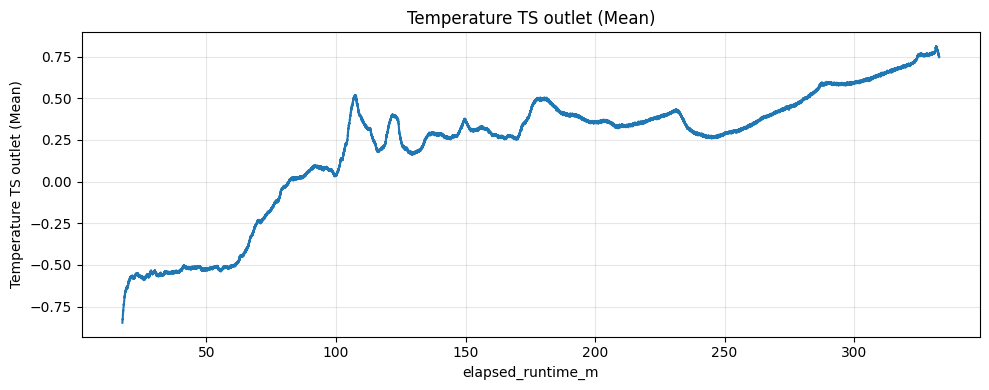

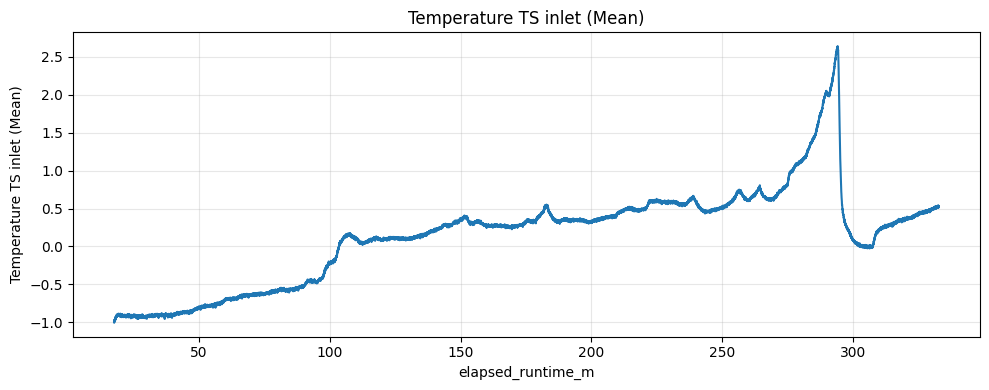

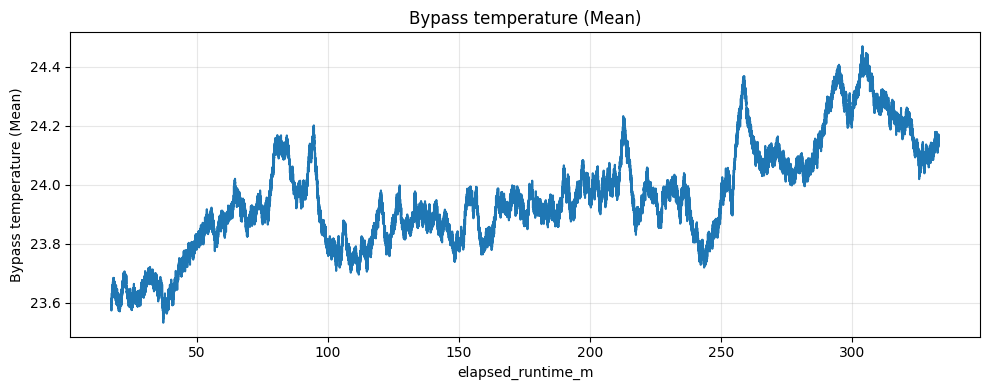

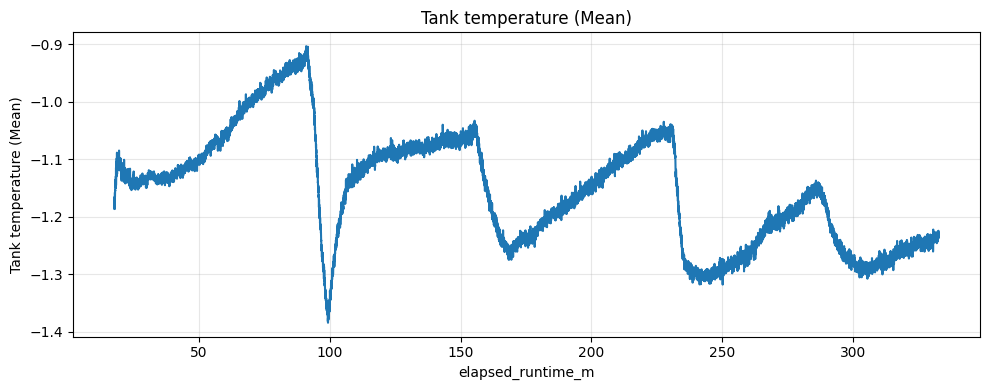

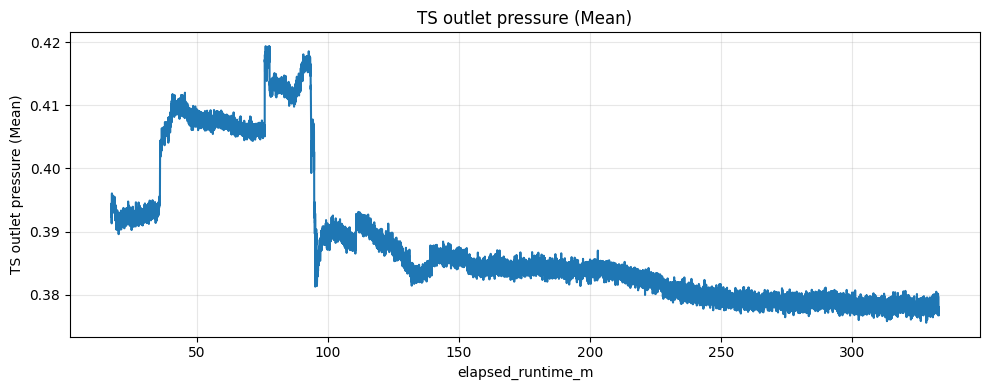

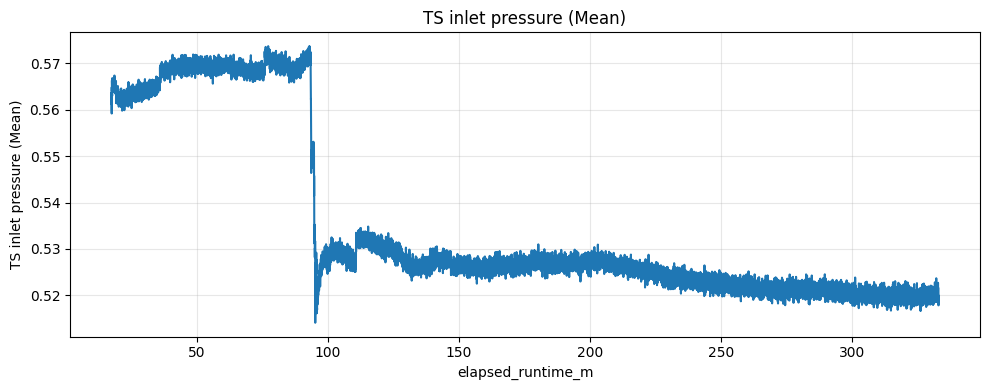

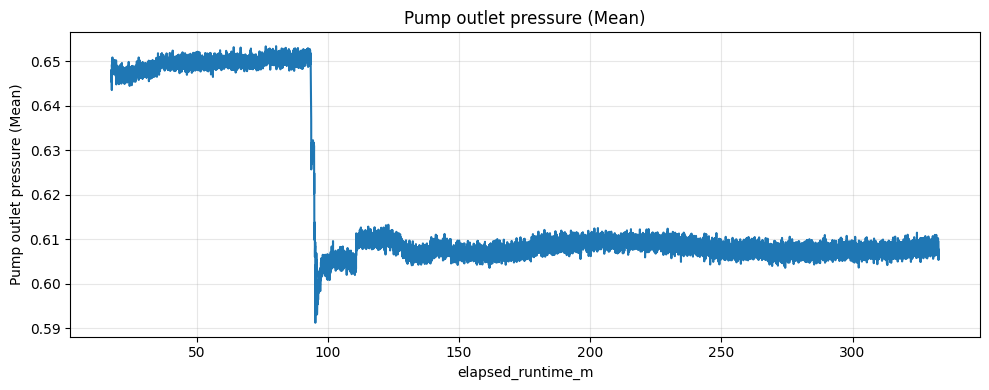

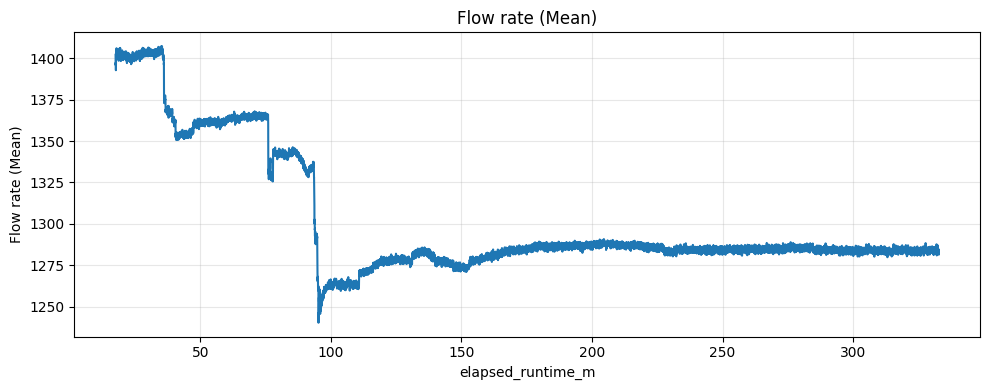

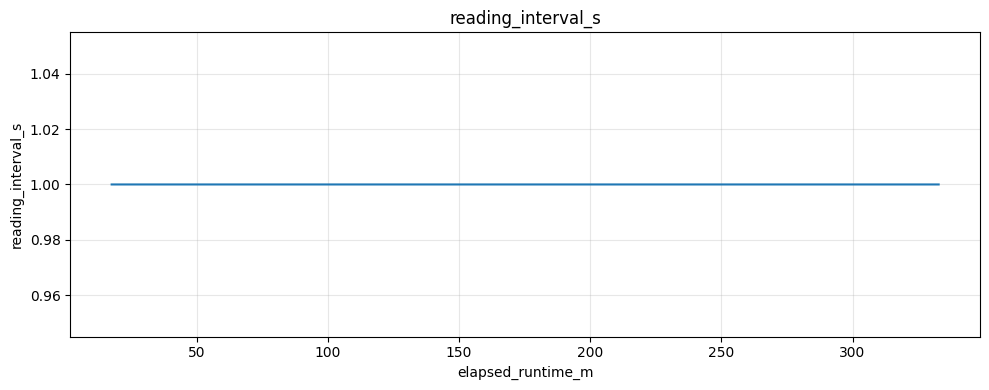

In [483]:
plot_all_timeseries(df)

## 13.10

### init

In [484]:
df = df1310.copy()

In [485]:
basic_checklist(df)

Missing values:
Time                               0
Temperature TS outlet (Mean)       0
Temperature TS inlet (Mean)        0
Bypass temperature (Mean)          0
Tank temperature (Mean)            0
TS outlet pressure (Mean)          0
TS inlet pressure (Mean)           0
Pump outlet pressure (Mean)        0
Flow rate (Mean)                   0
Unnamed: 9                         0
Unnamed: 10                     5510
dtype: int64

Time column is monotonic increasing.


In [486]:
df.drop(columns = ['Unnamed: 9', 'Unnamed: 10'], inplace = True)

In [487]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    5571
0.0       1
Name: count, dtype: int64

### plotting


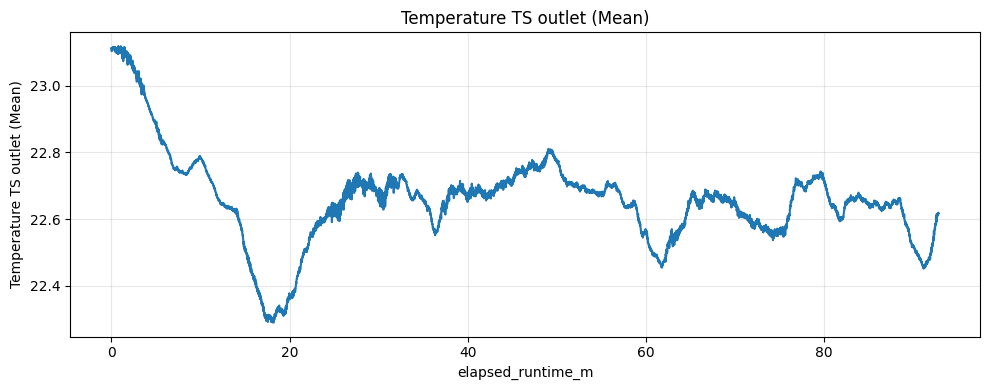

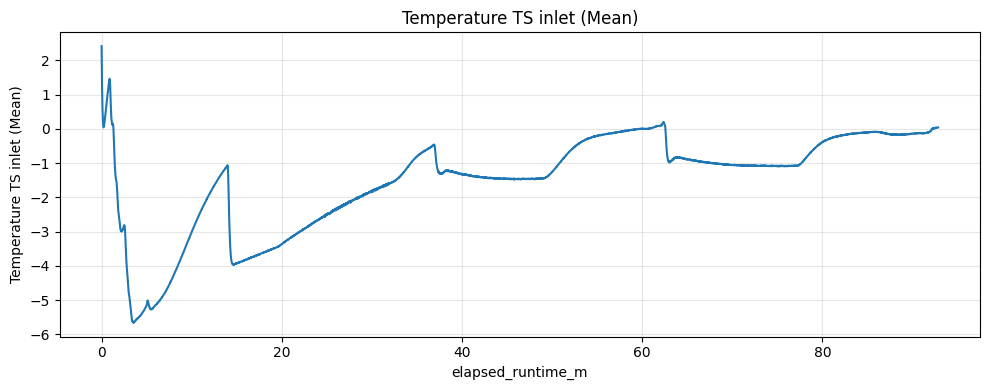

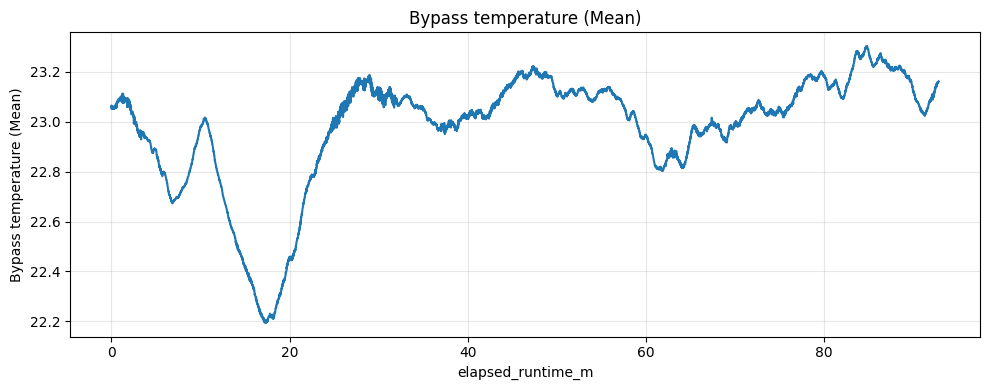

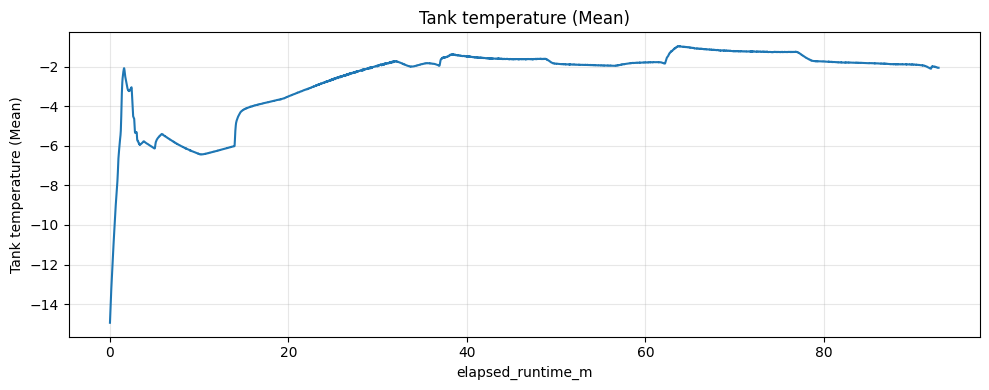

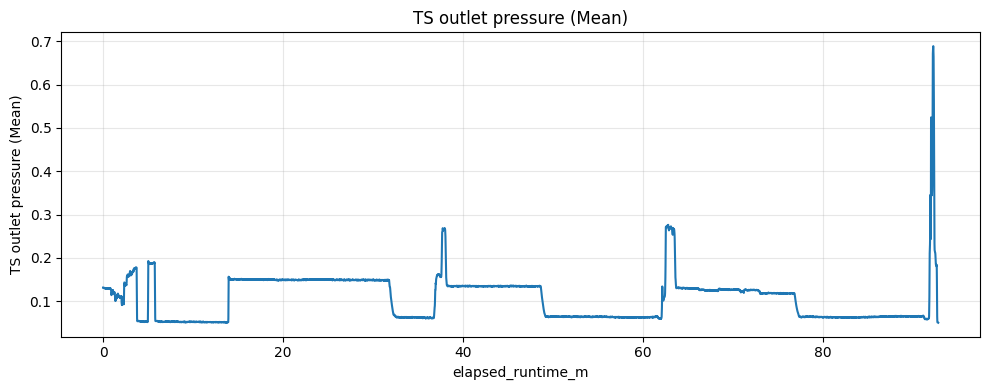

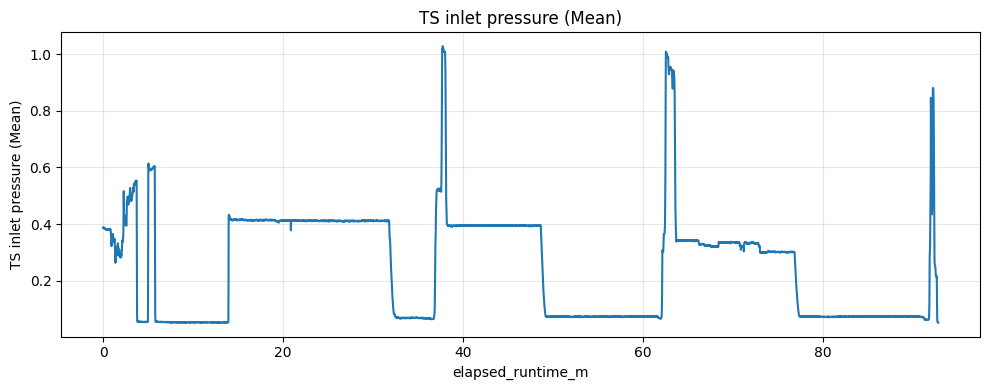

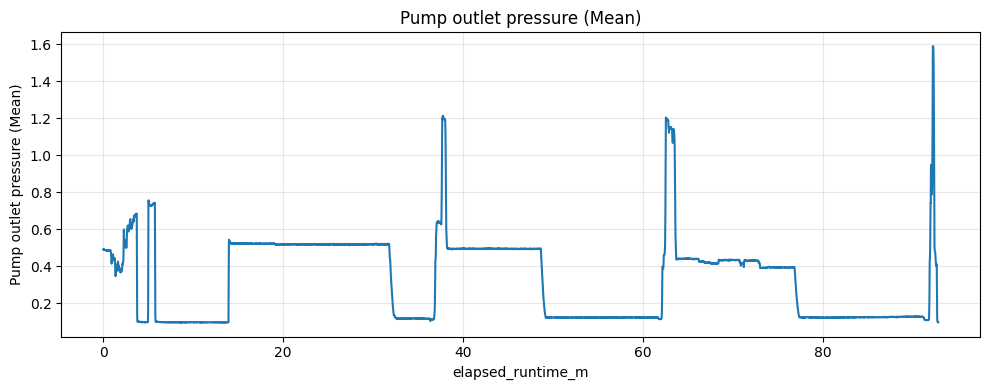

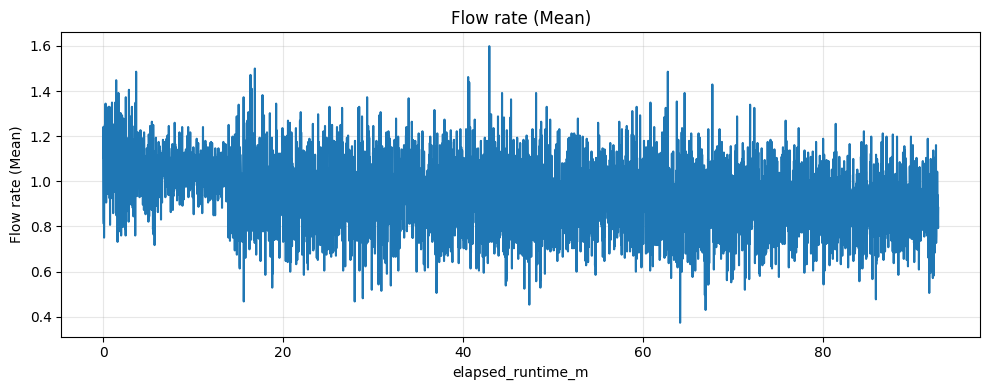

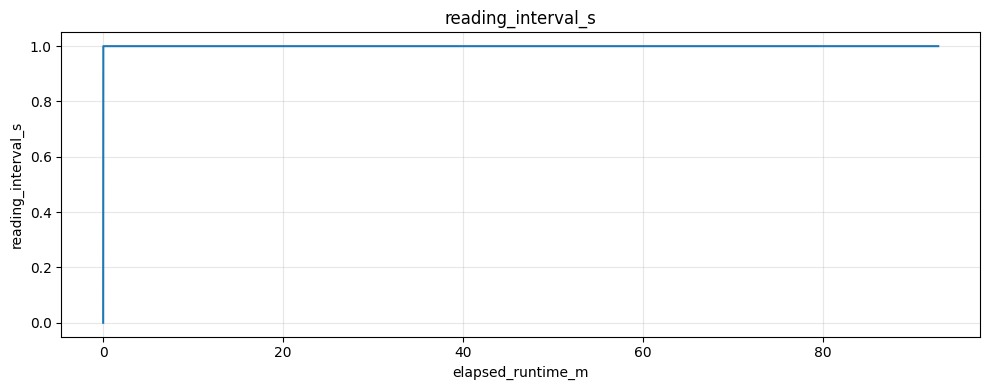

In [488]:
plot_all_timeseries(df)

### snipping

Time codes:

14:36:10 – 14:39:59 – loop blocked (4.5 Hz)

14:52:49 - 15:05:17 – orifice blocked (5 Hz)

15:20:58 - 15:34:45 – loop blocked (5.5 Hz)


In [489]:
start = find_index_at_timestamp(df, 143610)
end = find_index_at_timestamp(df, 143959)
dffirst = snip_df_at_timecode(df, start, end)

In [490]:
start = find_index_at_timestamp(df, 145249)
end = find_index_at_timestamp(df, 150517)
dfsnd = snip_df_at_timecode(df, start, end)

In [491]:
start = find_index_at_timestamp(df, 152058)
end = find_index_at_timestamp(df, 153445)
dfthrd = snip_df_at_timecode(df, start, end)

In [492]:
dffirst.to_csv('../data/split/plug/1310-1.csv', index=False)
dfsnd.to_csv('../data/split/plug/1310-2.csv', index=False)
dfthrd.to_csv('../data/split/plug/1310-3.csv', index=False)

### plot after snip

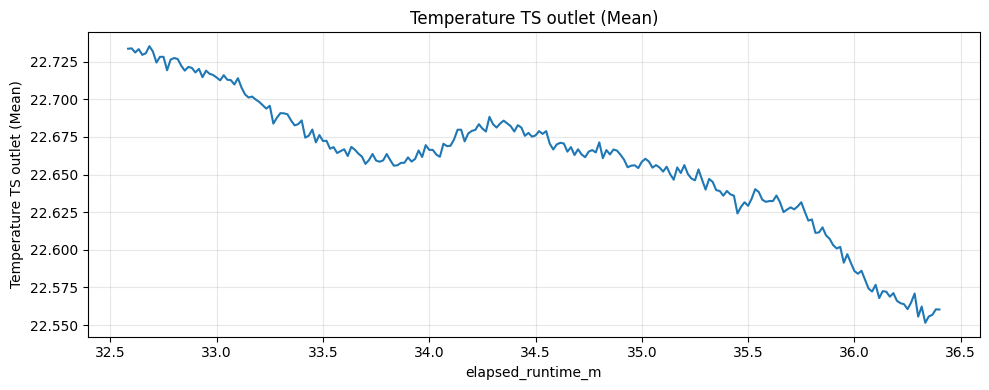

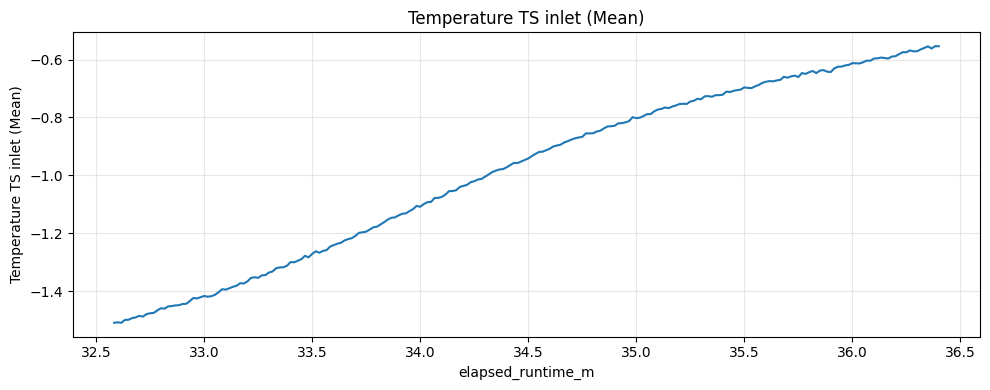

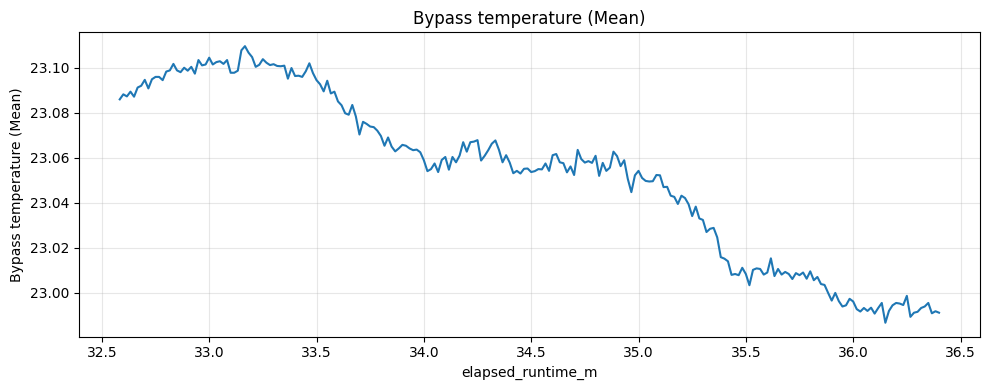

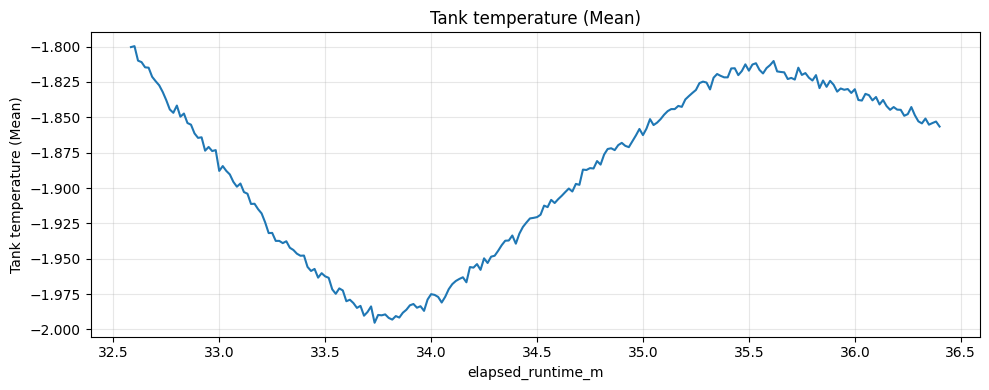

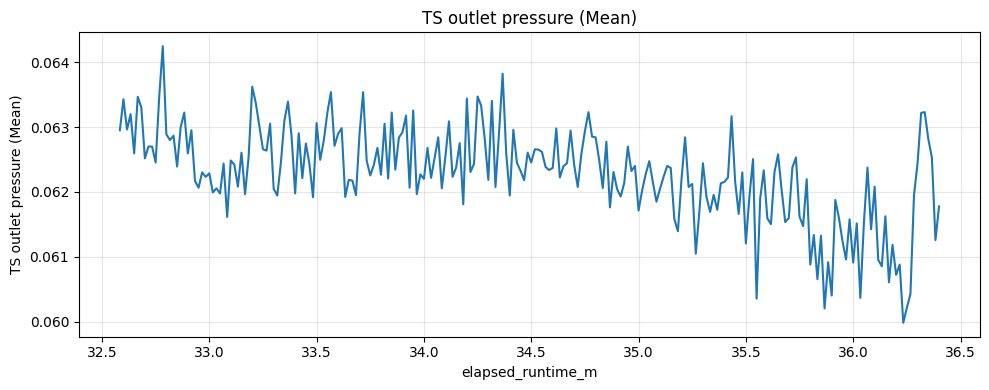

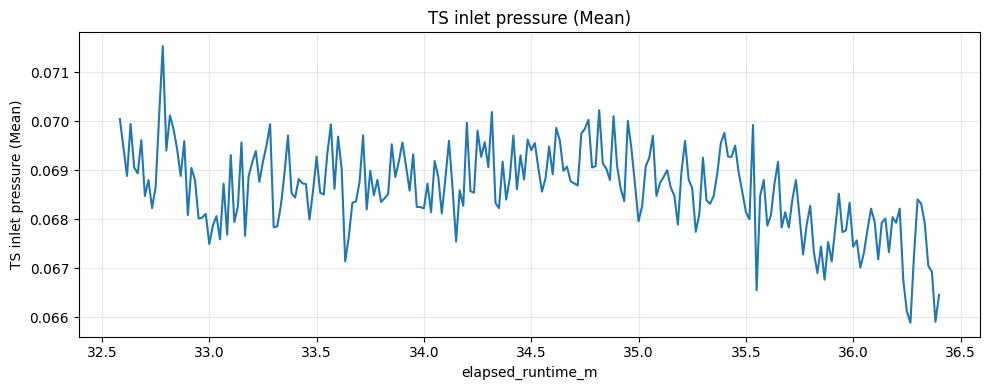

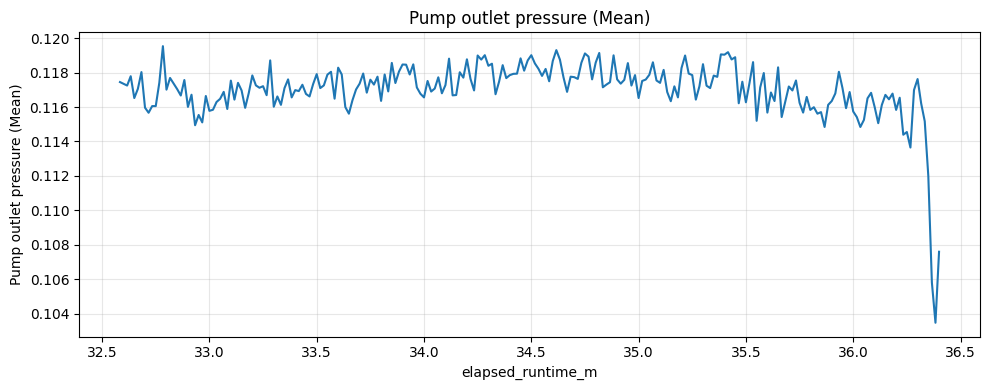

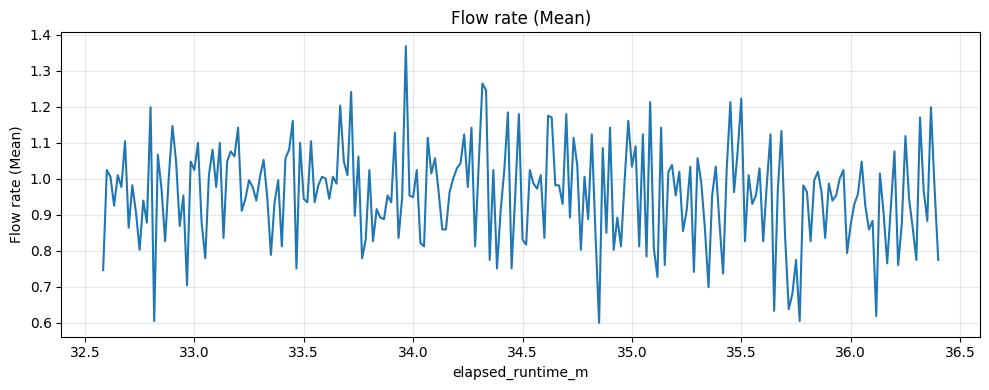

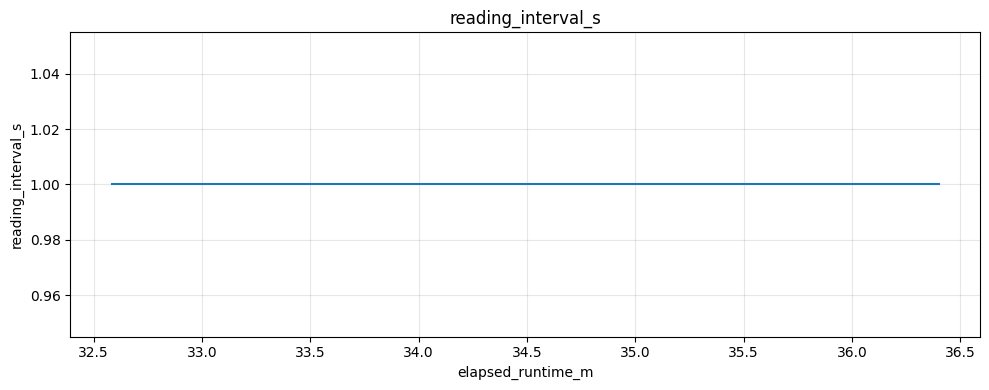

In [493]:
plot_all_timeseries(dffirst)

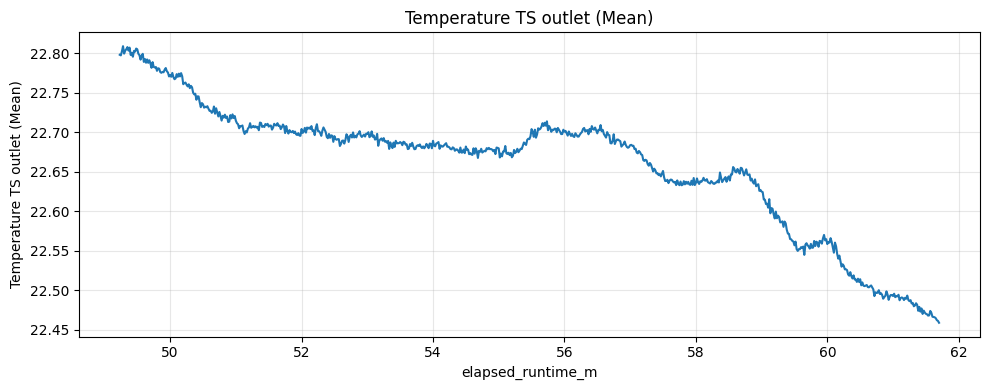

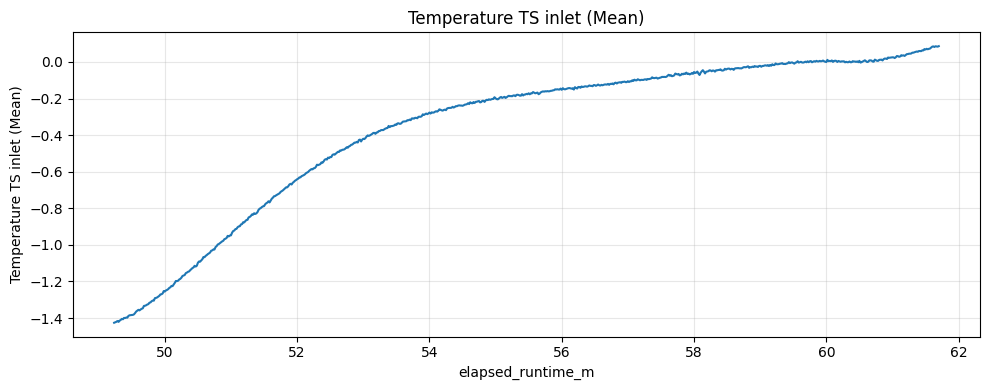

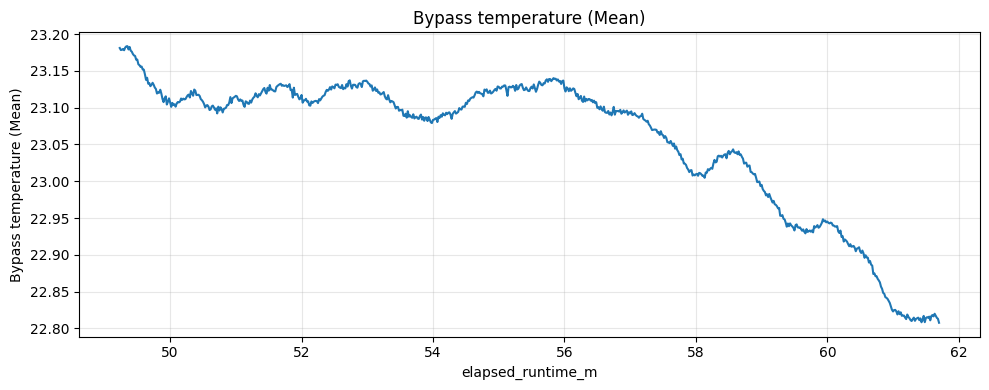

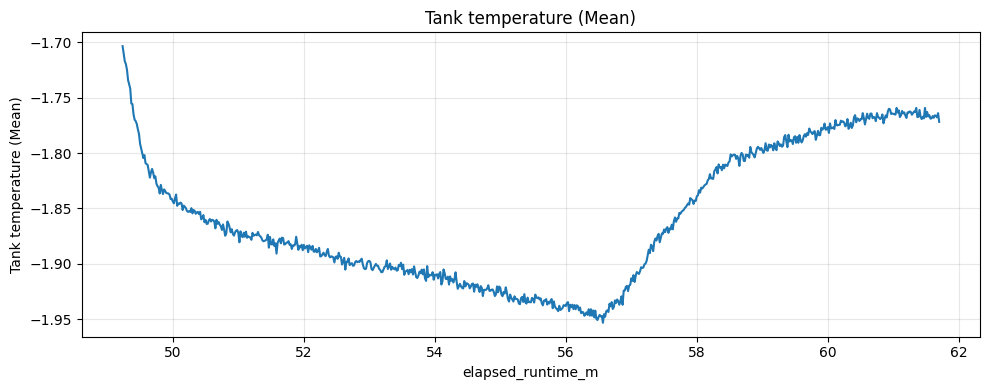

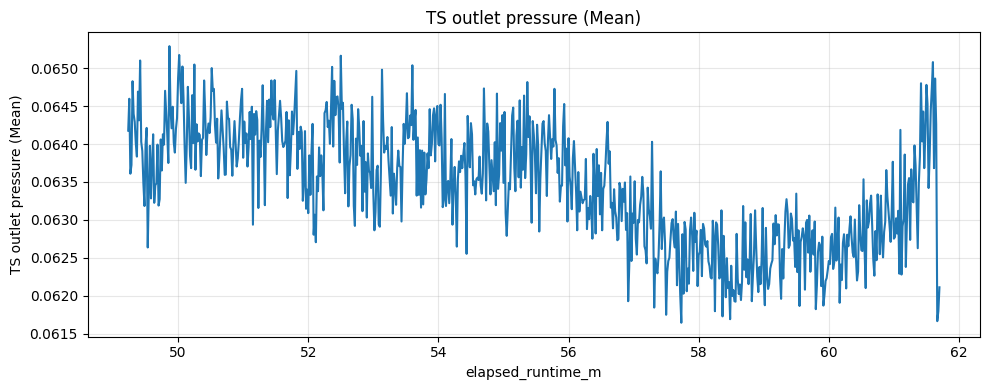

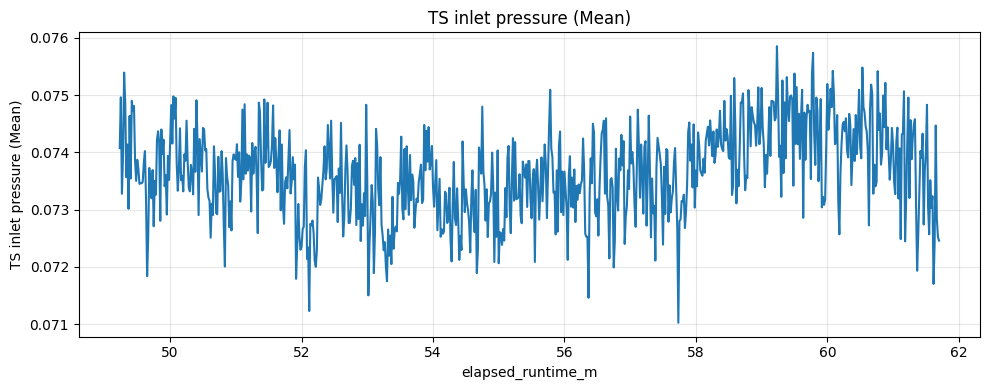

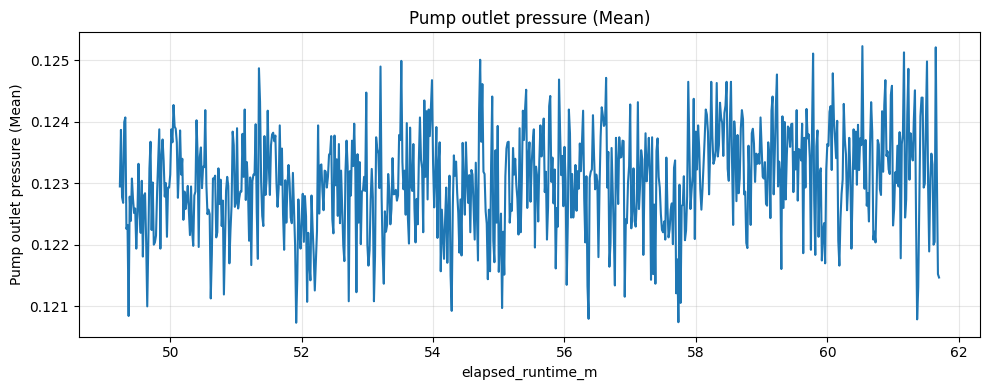

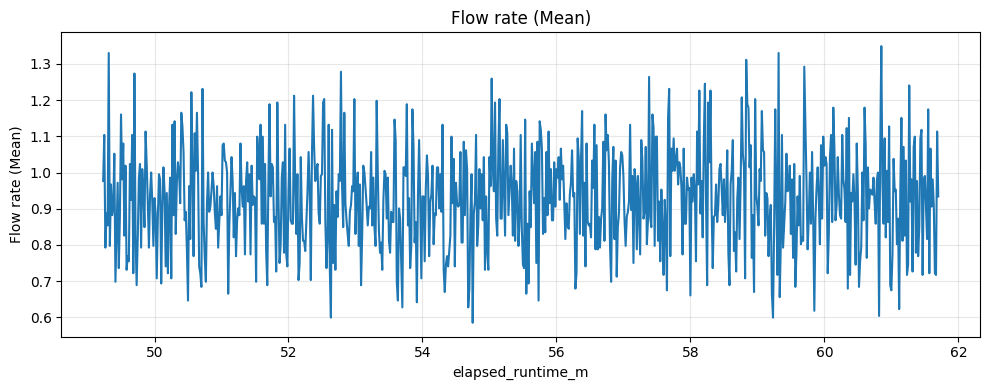

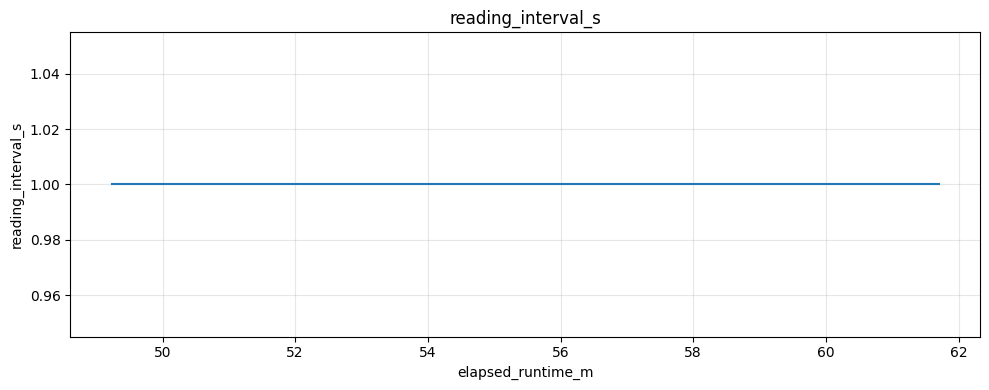

In [494]:
plot_all_timeseries(dfsnd)

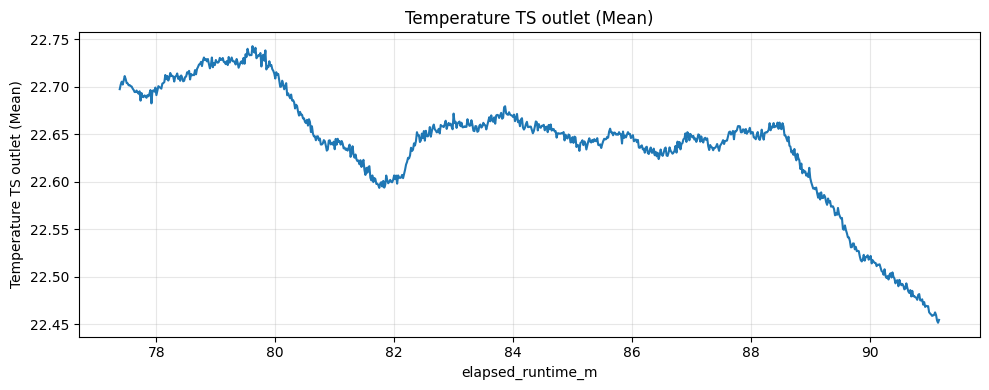

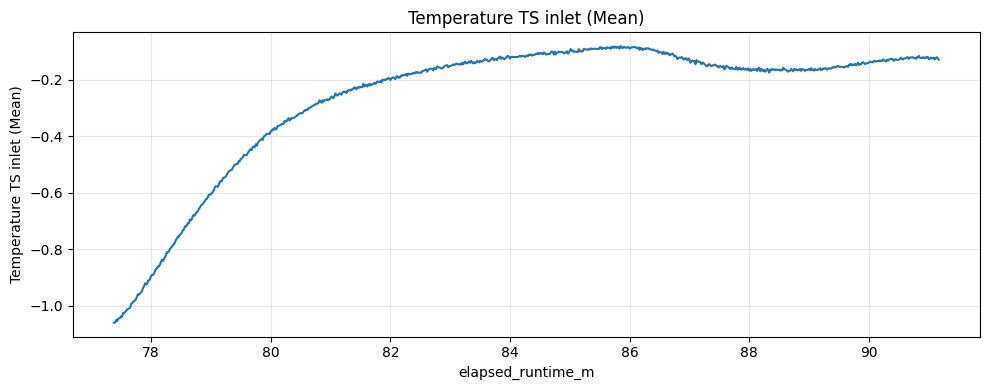

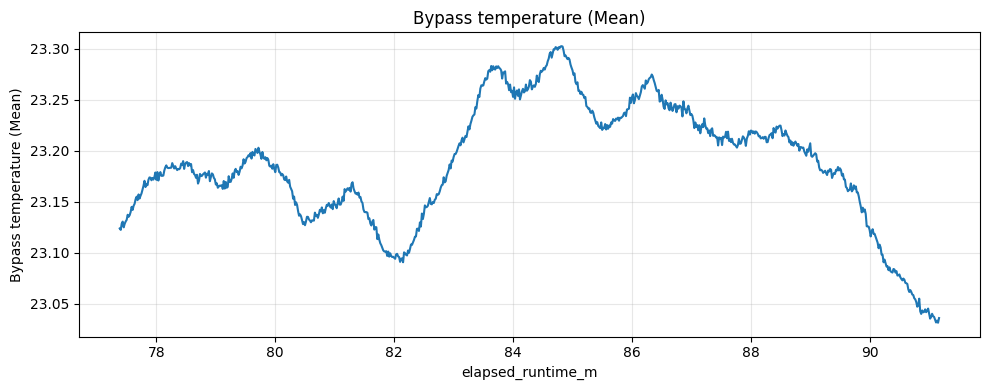

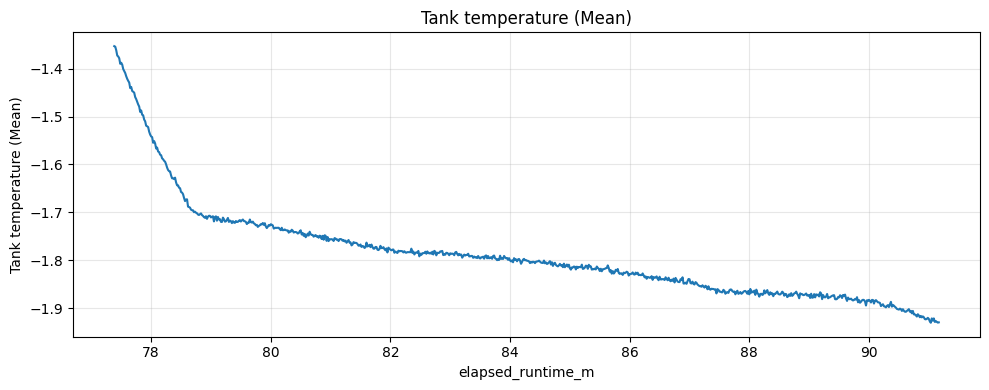

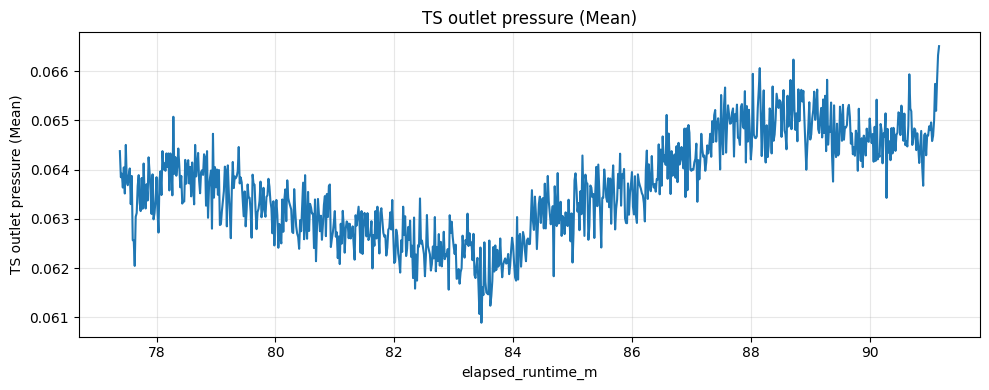

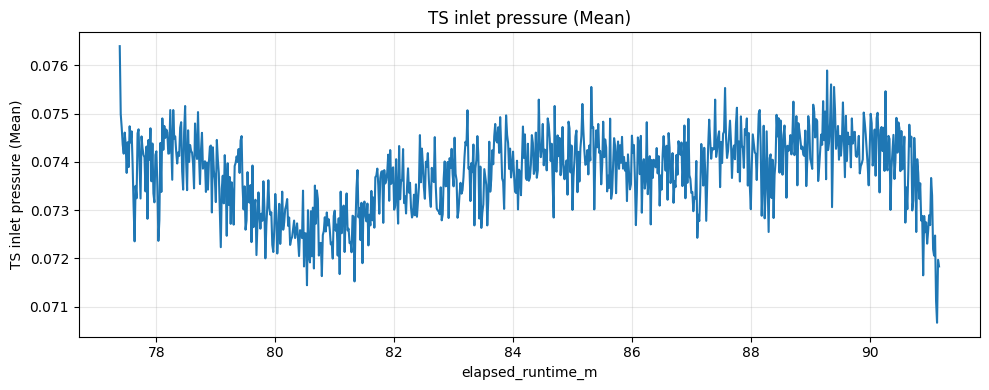

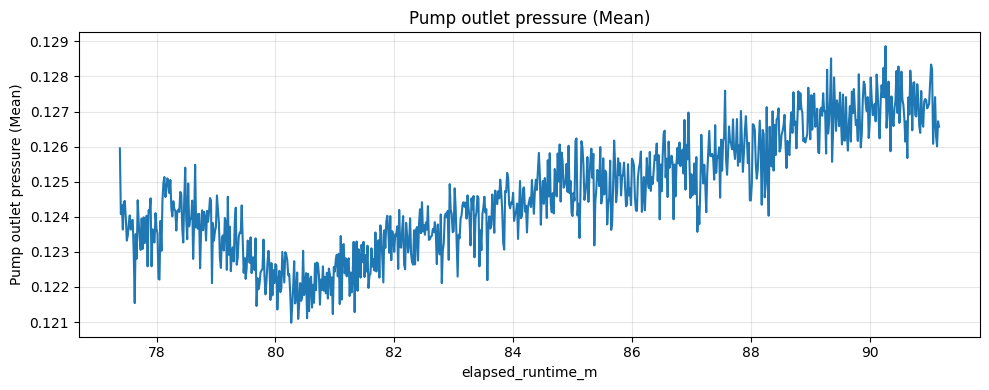

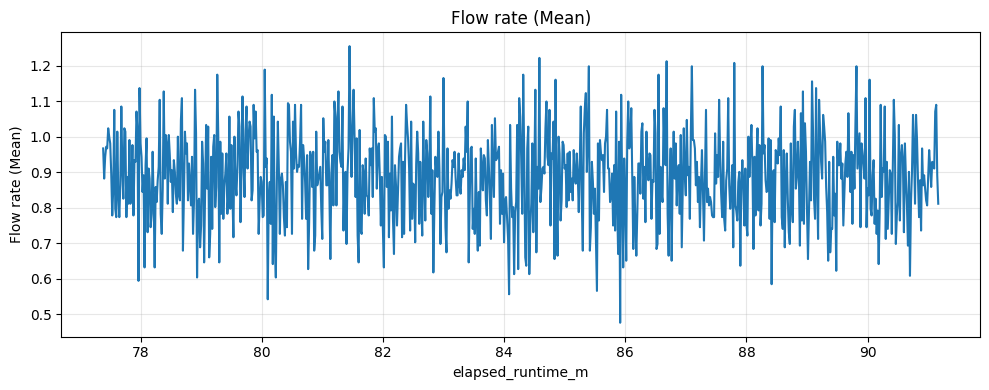

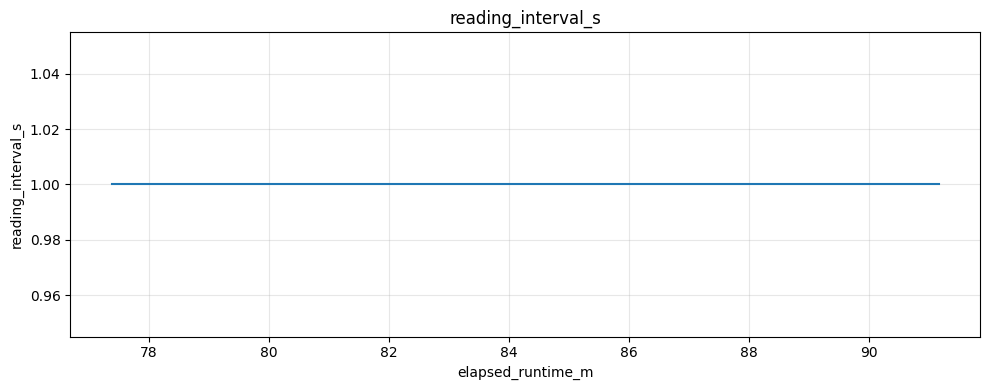

In [495]:
plot_all_timeseries(dfthrd)

## 27.01

### init

In [496]:
df = df2701.copy()

In [497]:
df = df.drop_duplicates()

In [498]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3285 entries, 0 to 3292
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Time                          3285 non-null   datetime64[ns]
 1   Temperature TS outlet (Mean)  3285 non-null   float64       
 2   Temperature TS inlet (Mean)   3285 non-null   float64       
 3   Bypass temperature (Mean)     3285 non-null   float64       
 4   Tank temperature (Mean)       3285 non-null   float64       
 5   TS outlet pressure (Mean)     3285 non-null   float64       
 6   TS inlet pressure (Mean)      3285 non-null   float64       
 7   Pump outlet pressure (Mean)   3285 non-null   float64       
 8   Flow rate (Mean)              3285 non-null   float64       
 9   Unnamed: 9                    3285 non-null   float64       
 10  Unnamed: 10                   3285 non-null   float64       
dtypes: datetime64[ns](1), float64(10)
m

In [499]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


In [500]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()


reading_interval_s
1.0    3284
0.0       1
Name: count, dtype: int64

In [501]:
df.drop(columns = ['Unnamed: 9', 'Unnamed: 10'], inplace=True)

### plotting

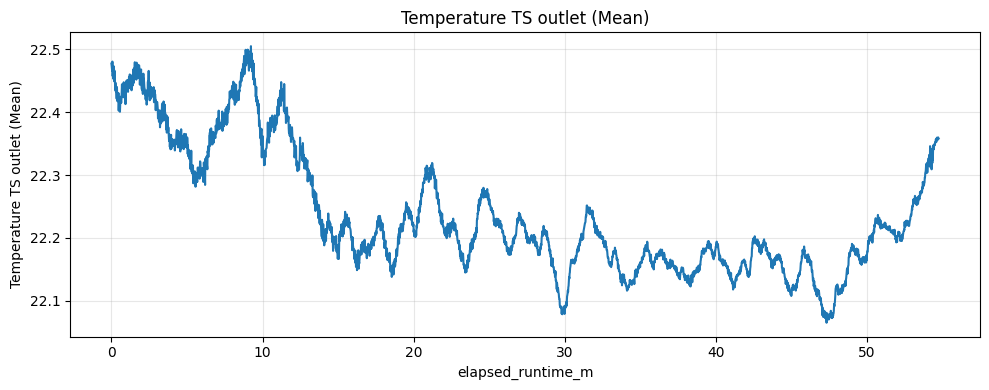

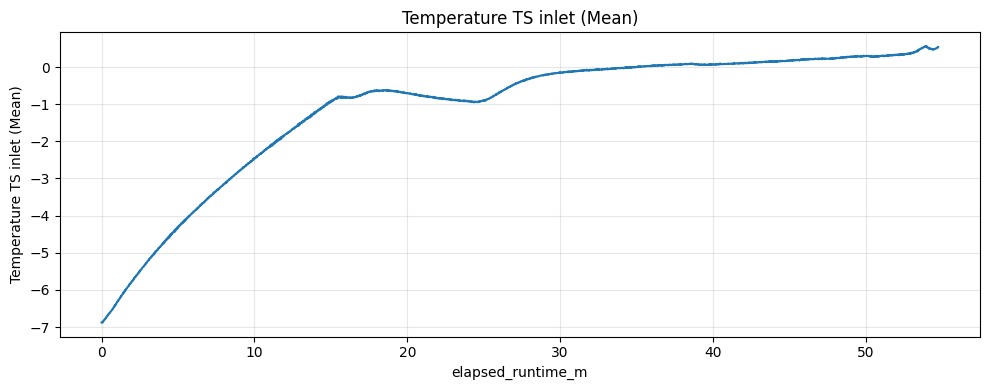

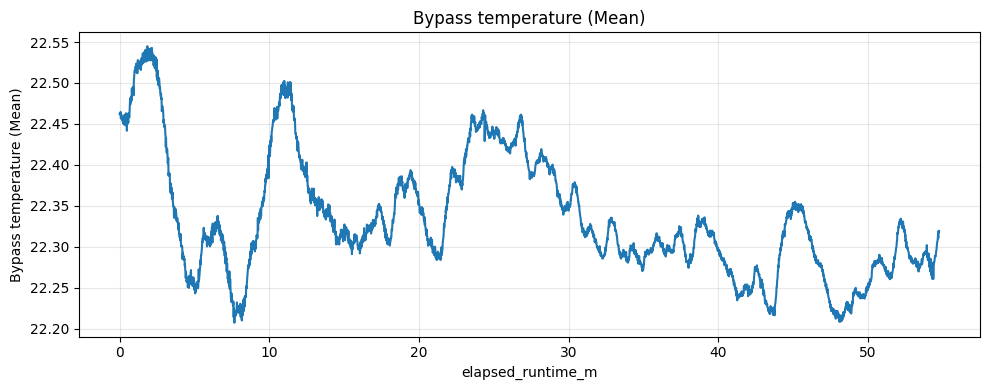

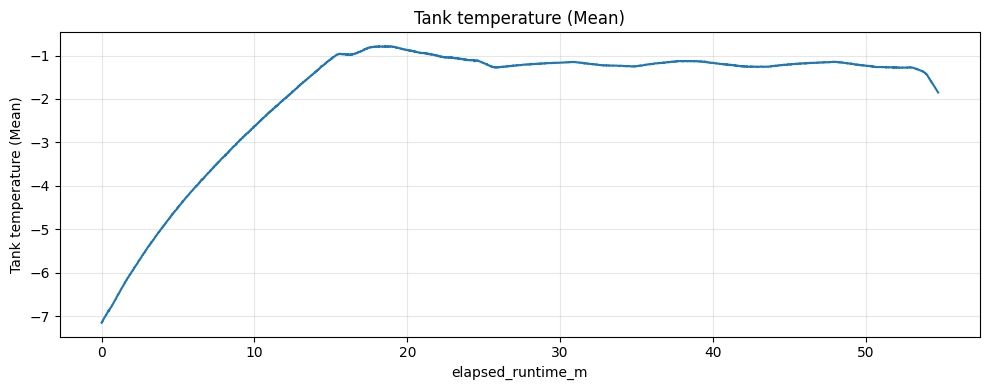

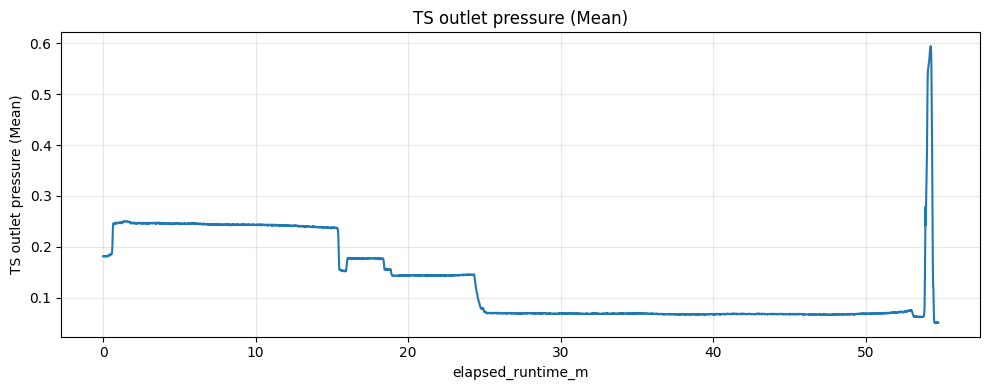

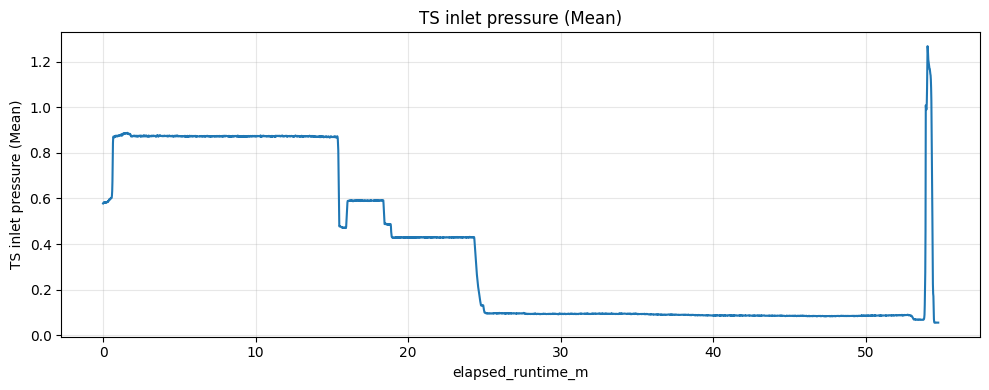

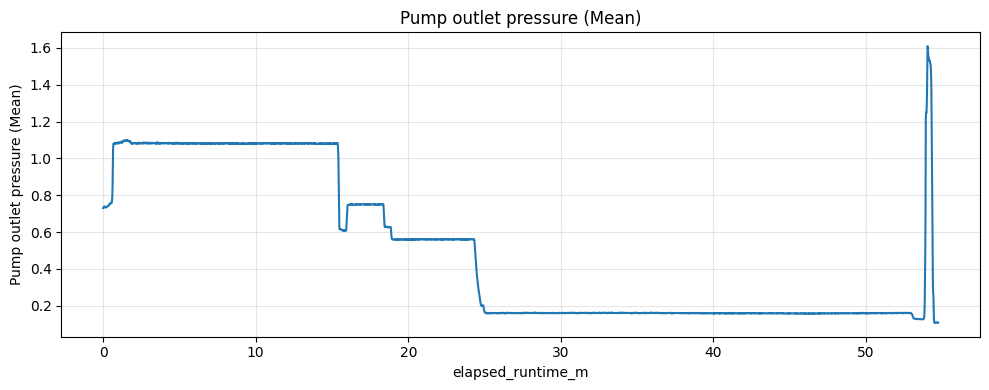

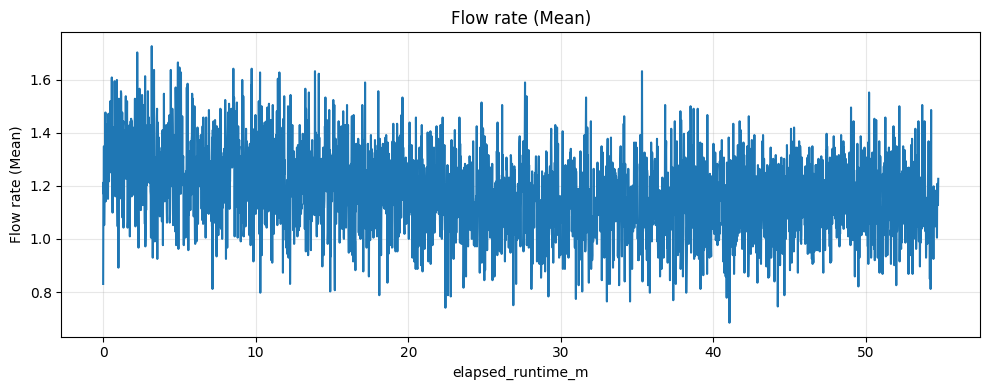

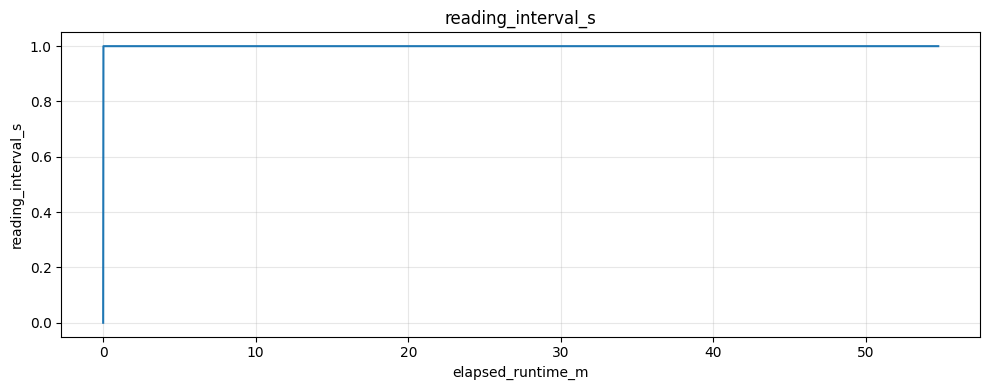

In [502]:
plot_all_timeseries(df)

### snipping

Time-codes

14:25:56  –– 14:53:52 blockage of the orifice


In [503]:
start = find_index_at_timestamp(df, 142556)
end = find_index_at_timestamp(df, 145352)
df = snip_df_at_timecode(df, start, end)

In [504]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1677 entries, 0 to 1676
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Time                          1677 non-null   datetime64[ns]
 1   Temperature TS outlet (Mean)  1677 non-null   float64       
 2   Temperature TS inlet (Mean)   1677 non-null   float64       
 3   Bypass temperature (Mean)     1677 non-null   float64       
 4   Tank temperature (Mean)       1677 non-null   float64       
 5   TS outlet pressure (Mean)     1677 non-null   float64       
 6   TS inlet pressure (Mean)      1677 non-null   float64       
 7   Pump outlet pressure (Mean)   1677 non-null   float64       
 8   Flow rate (Mean)              1677 non-null   float64       
 9   reading_interval_s            1677 non-null   float64       
 10  elapsed_runtime_s             1677 non-null   float64       
 11  elapsed_runtime_m             

In [505]:
df.to_csv('../data/split/plug/2701.csv', index=False)

### plot after snip

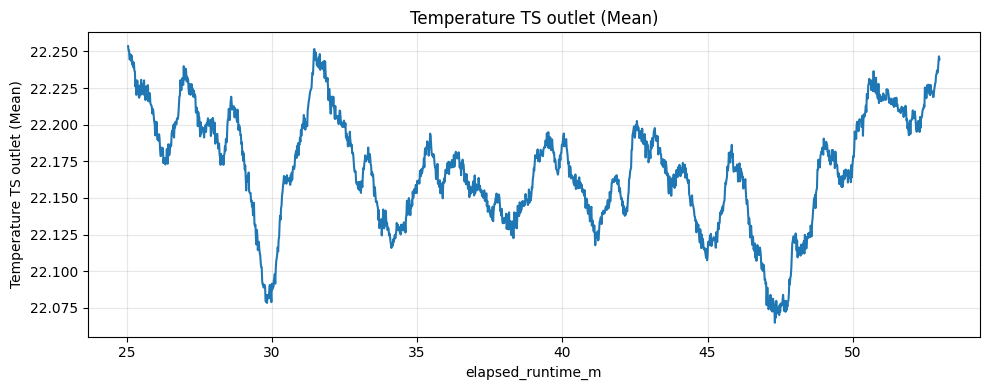

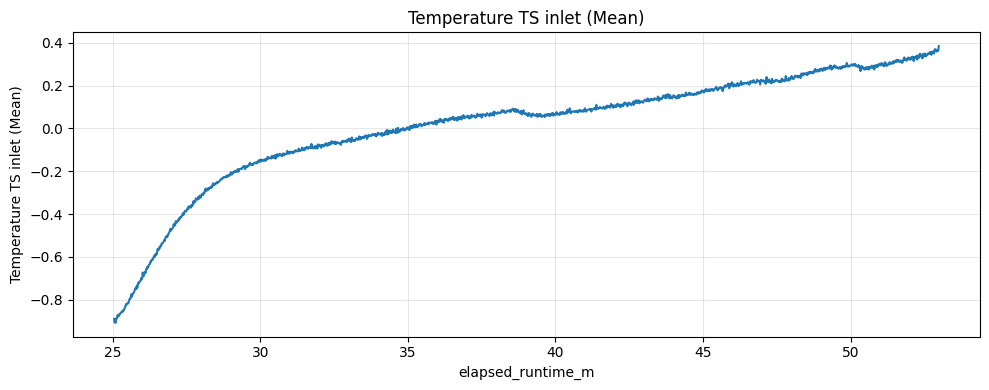

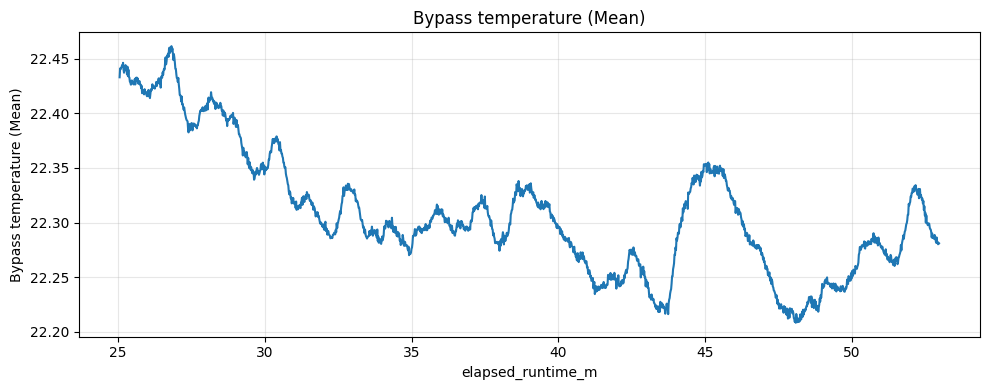

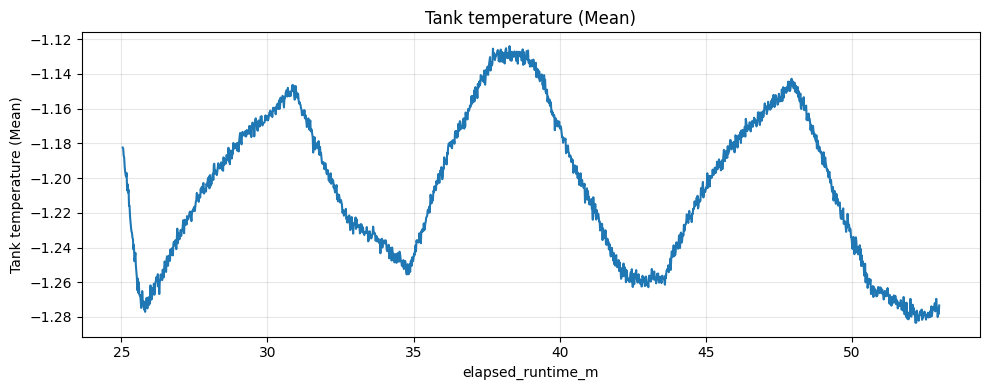

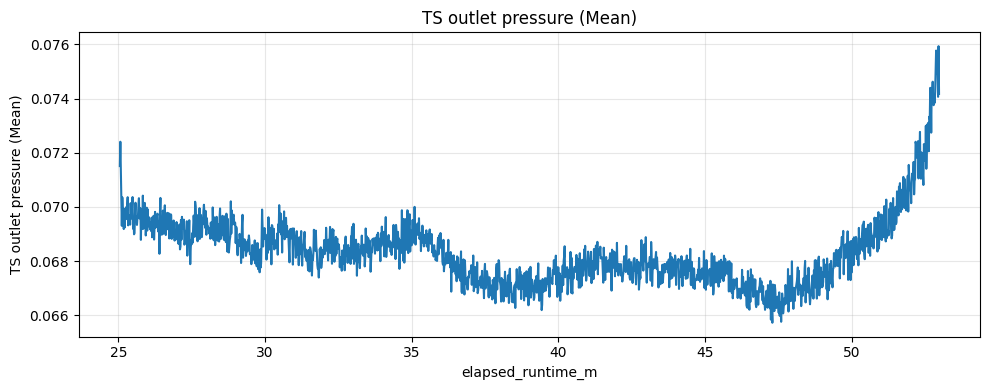

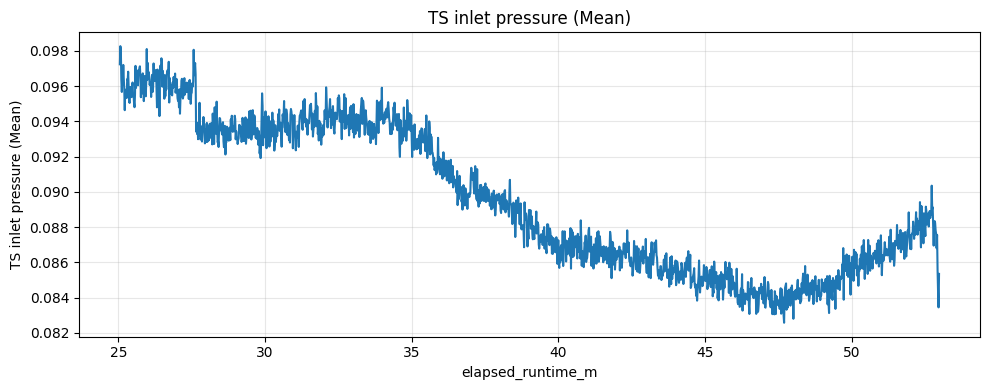

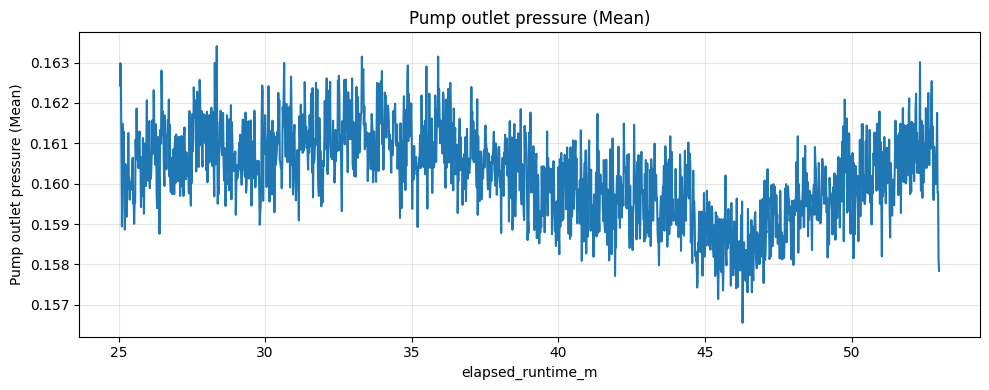

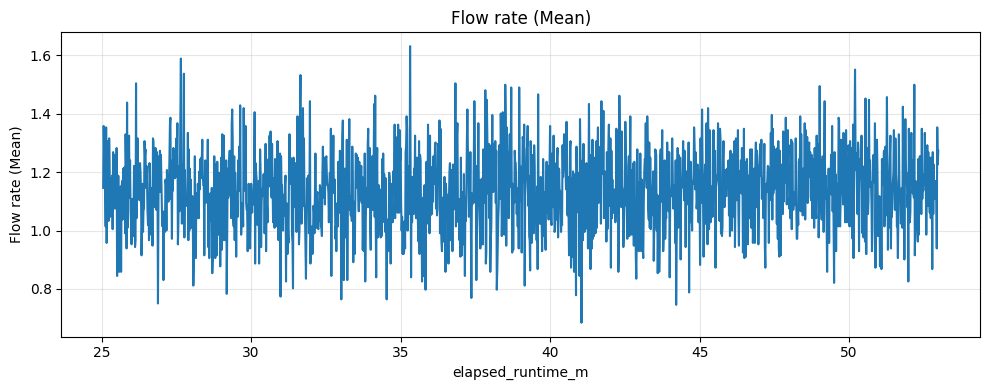

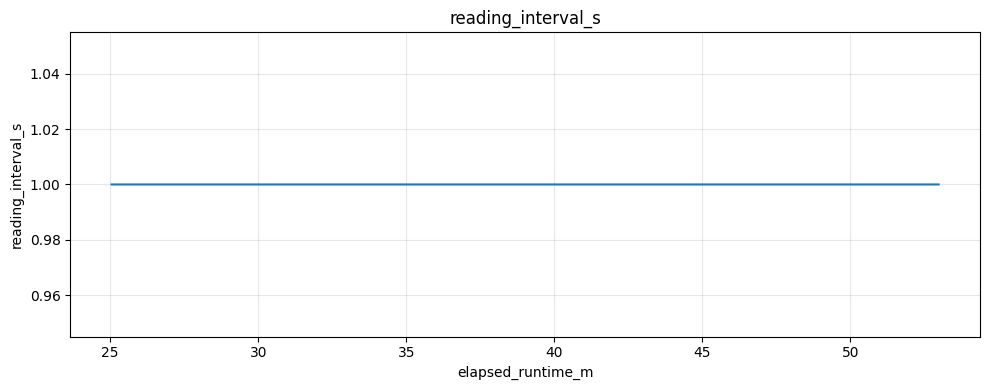

In [506]:
plot_all_timeseries(df)

## 14.07

### init

In [507]:
df = df1407.copy()

In [508]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


In [509]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    6277
0.0       1
Name: count, dtype: int64

In [510]:
df.drop(columns = ['Unnamed: 9', 'Unnamed: 10'], inplace = True)

### plotting

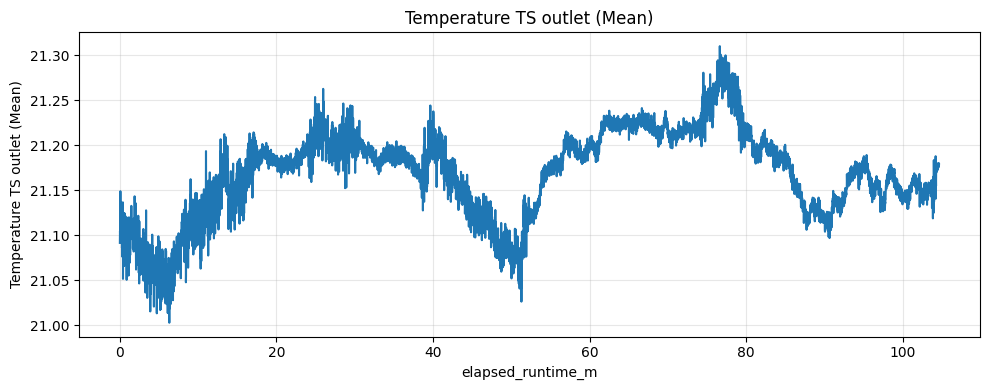

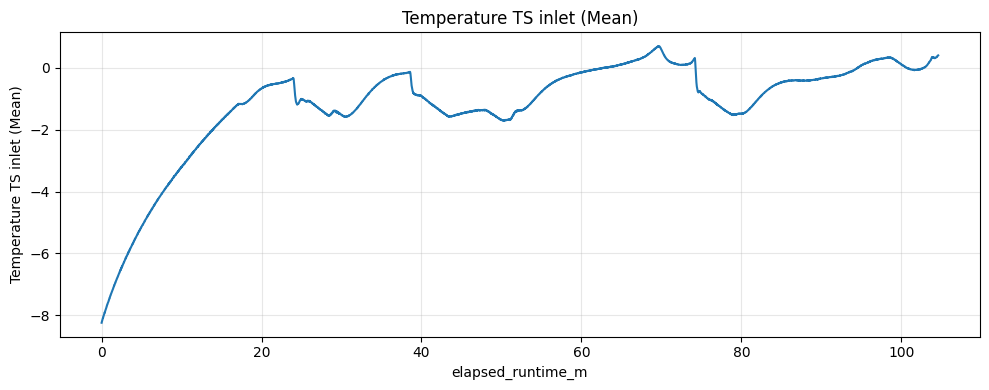

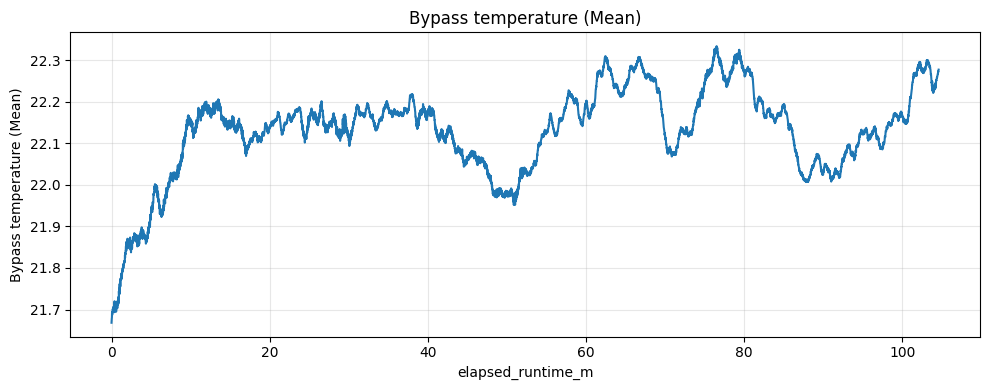

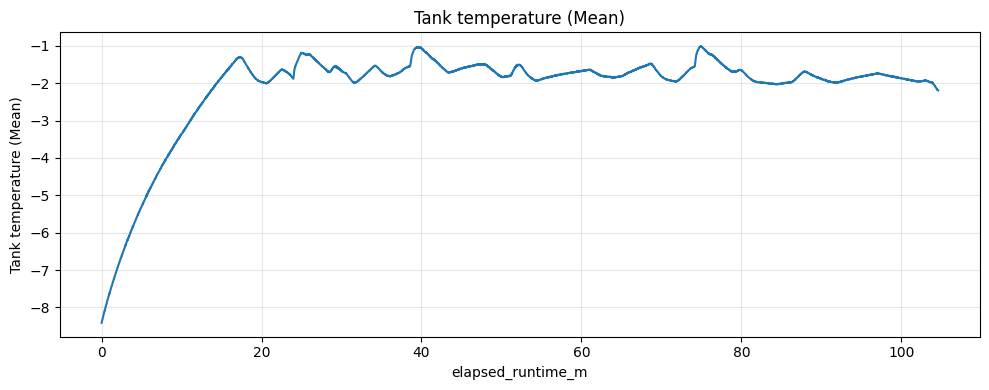

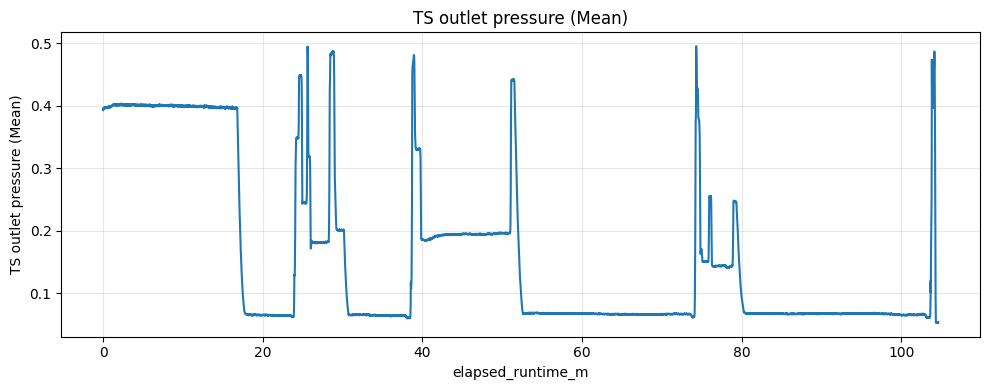

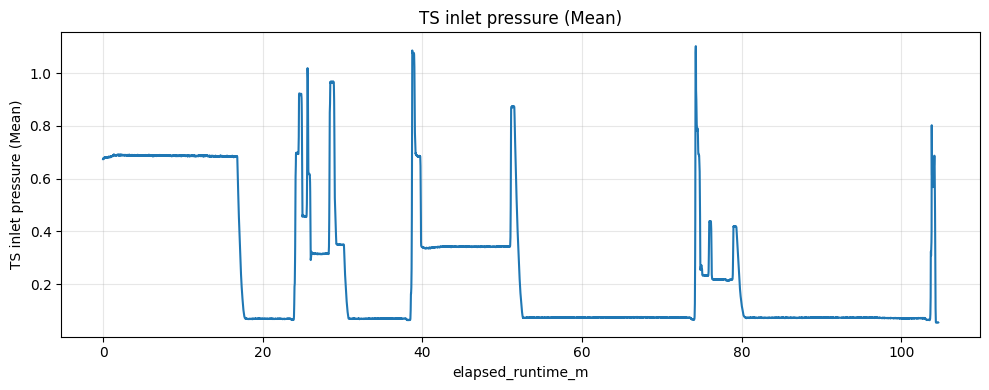

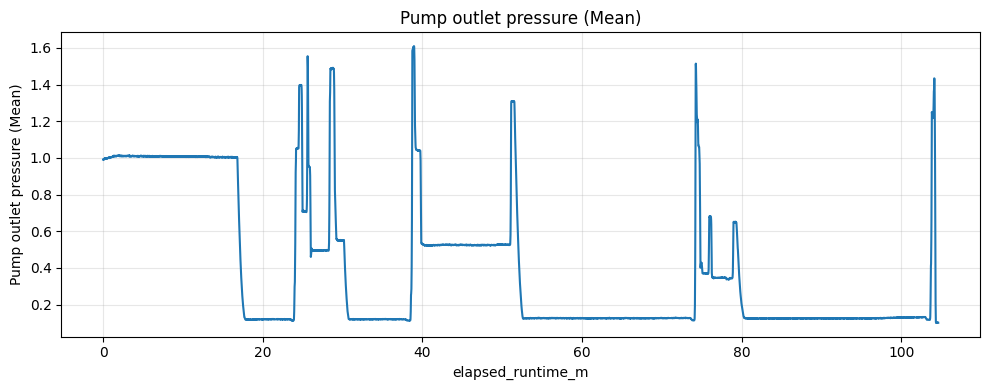

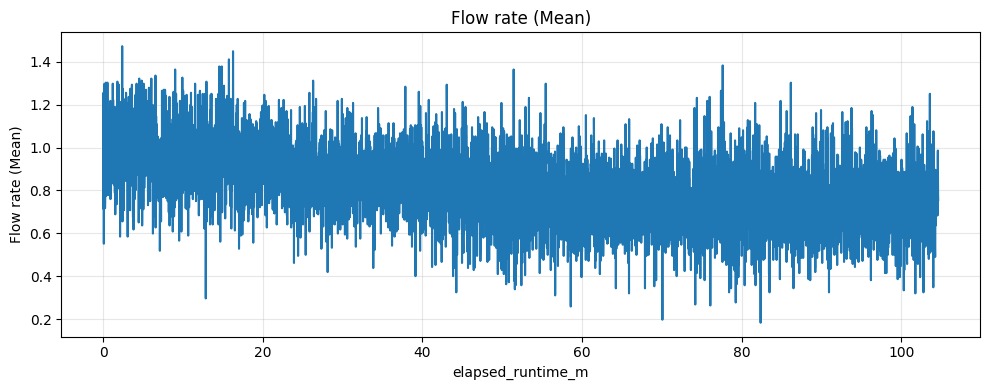

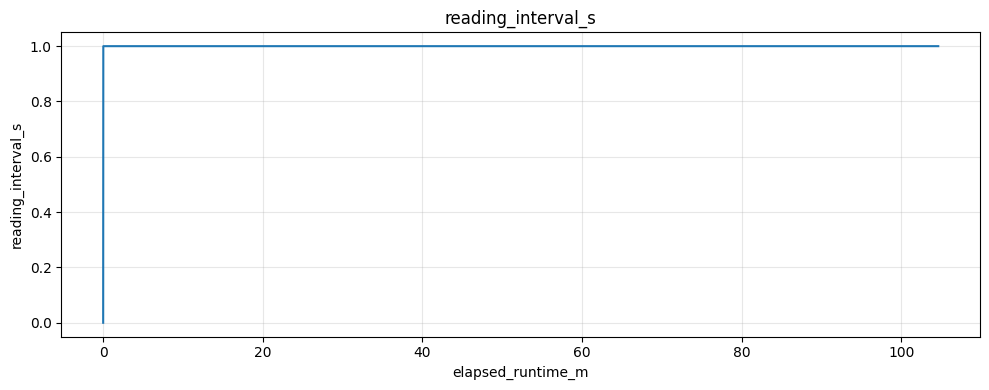

In [511]:
plot_all_timeseries(df)

### snipping

Time codes:

13:11:01 - 13:16:39 loop blocked

13:23:53 - 13:31:01 orifice blocked

13:45:42 - 14:06:44 loop blocked

14:13:36 - 14:36:09 loop blocked


In [512]:
start = find_index_at_timestamp(df, 131101)
end = find_index_at_timestamp(df, 131639)
dffirst = snip_df_at_timecode(df, start, end)

In [513]:
start = find_index_at_timestamp(df, 132353)
end = find_index_at_timestamp(df, 133101)
dfsnd = snip_df_at_timecode(df, start, end)

In [514]:
start = find_index_at_timestamp(df, 134542)
end = find_index_at_timestamp(df, 140644)
dfthrd = snip_df_at_timecode(df, start, end)

In [515]:
start = find_index_at_timestamp(df, 141336)
end = find_index_at_timestamp(df, 143609)
dffrth = snip_df_at_timecode(df, start, end)

In [516]:
dffirst.to_csv('../data/split/plug/1407-1.csv', index=False)
dfsnd.to_csv('../data/split/plug/1407-2.csv', index=False)
dfthrd.to_csv('../data/split/plug/1407-3.csv', index =False)
dffrth.to_csv('../data/split/plug/1407-4.csv', index=False)

### plot after snip

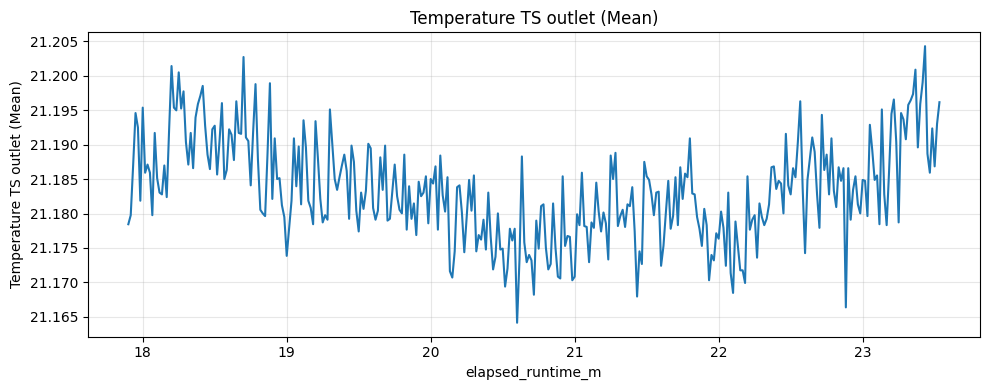

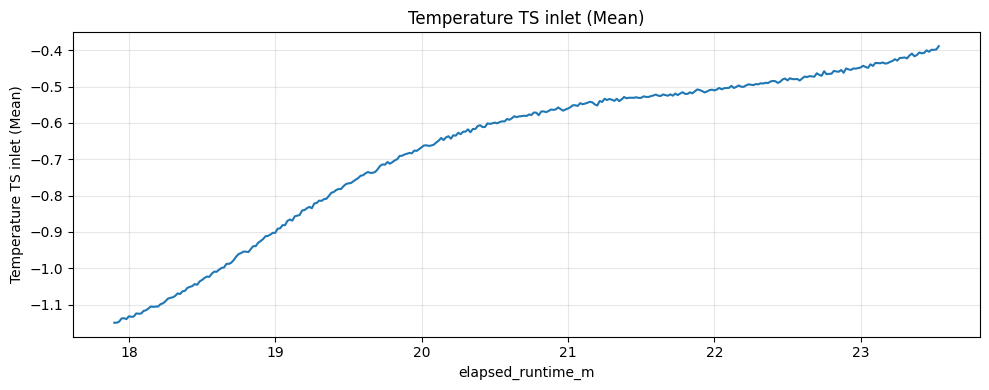

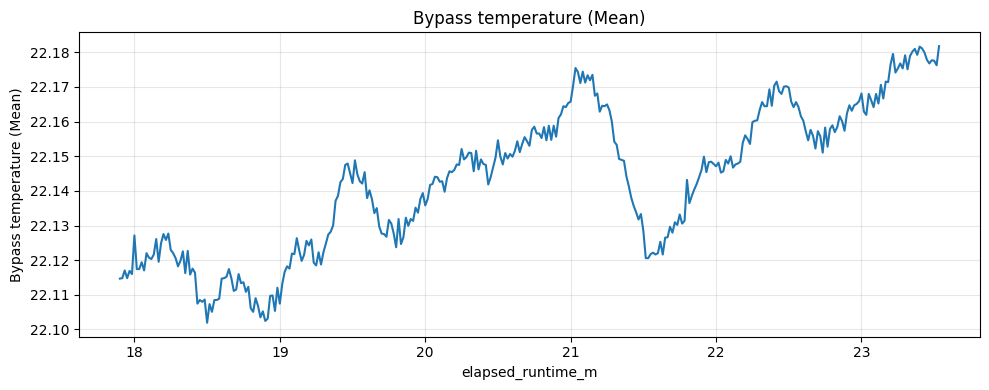

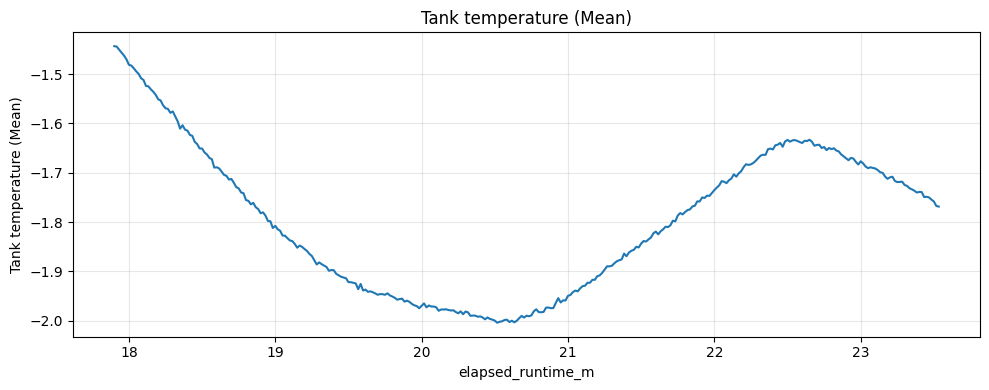

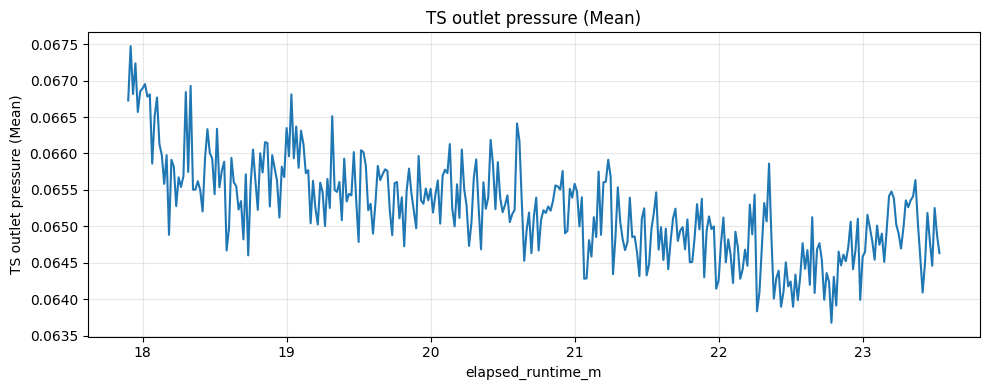

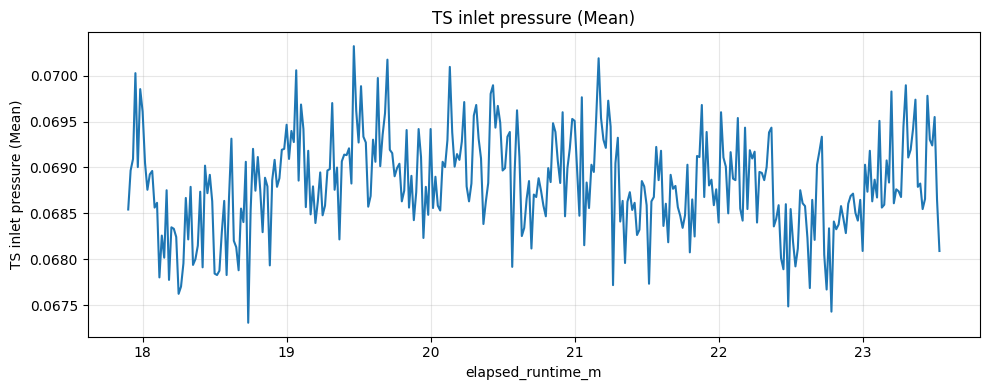

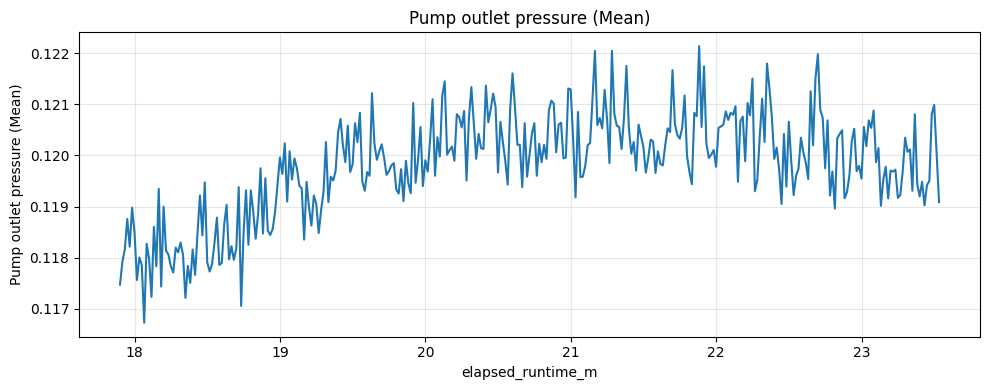

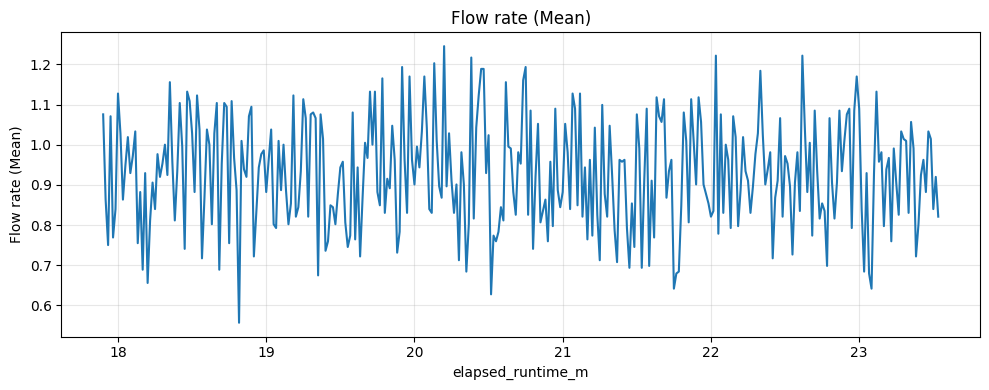

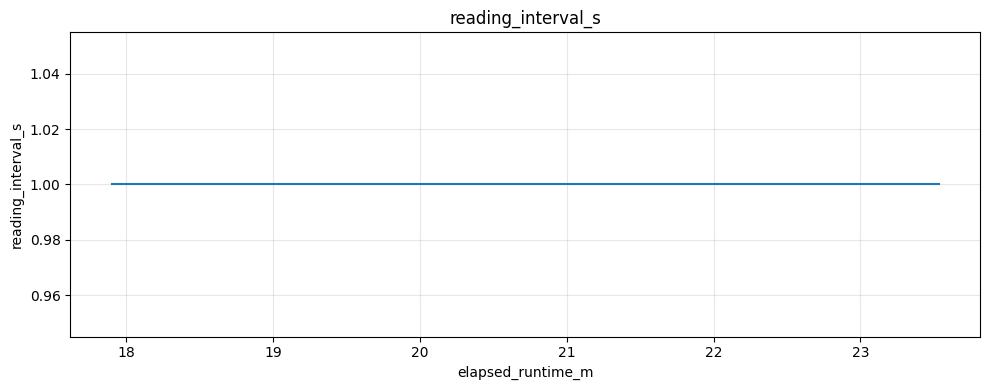

In [517]:
plot_all_timeseries(dffirst)

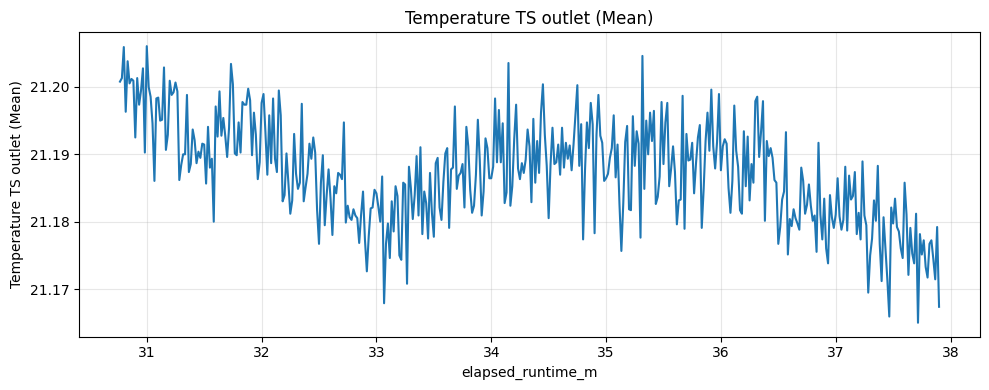

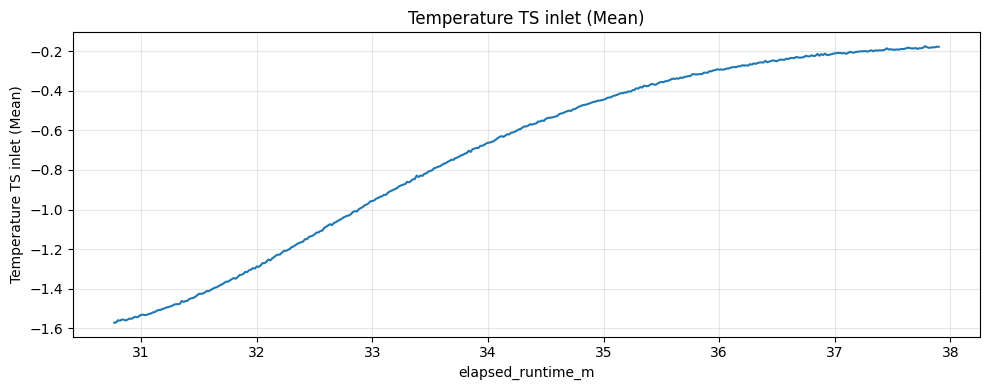

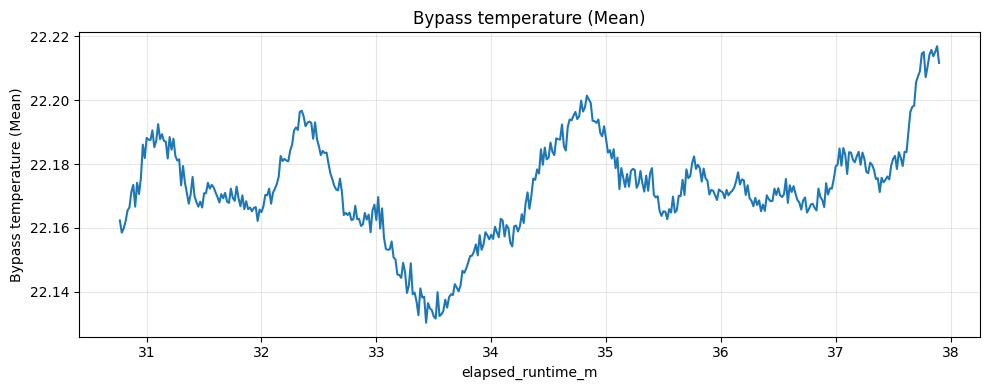

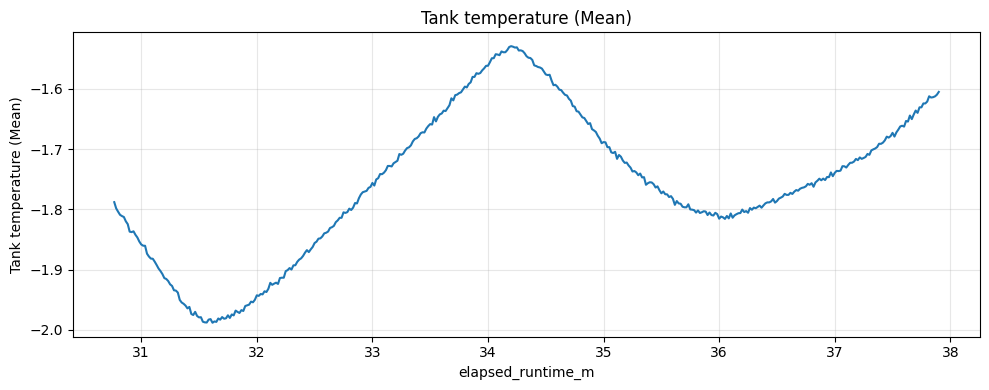

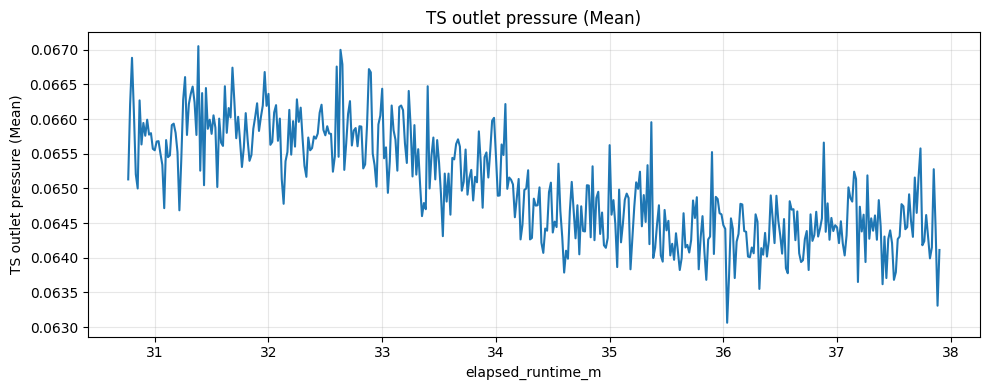

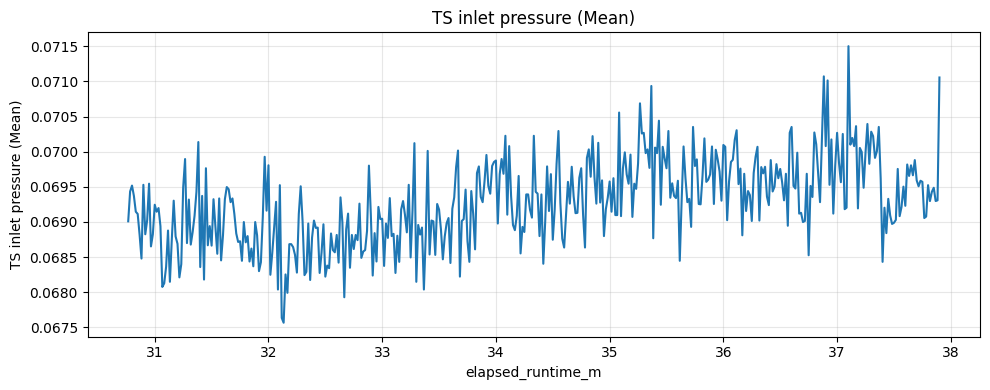

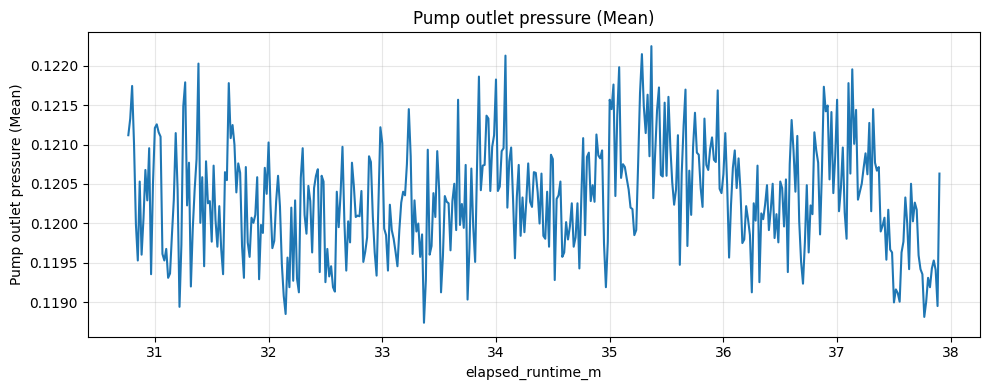

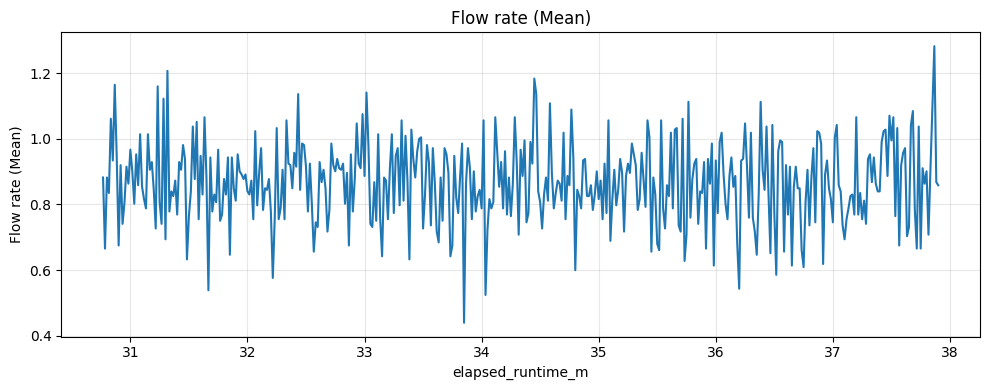

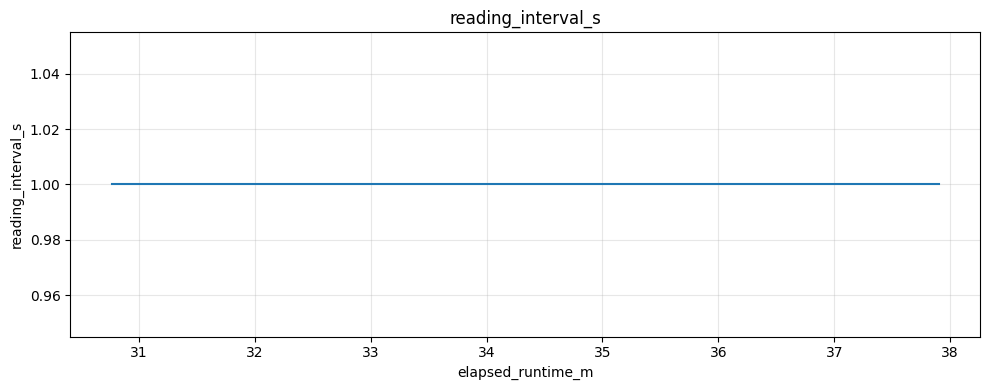

In [518]:
plot_all_timeseries(dfsnd)

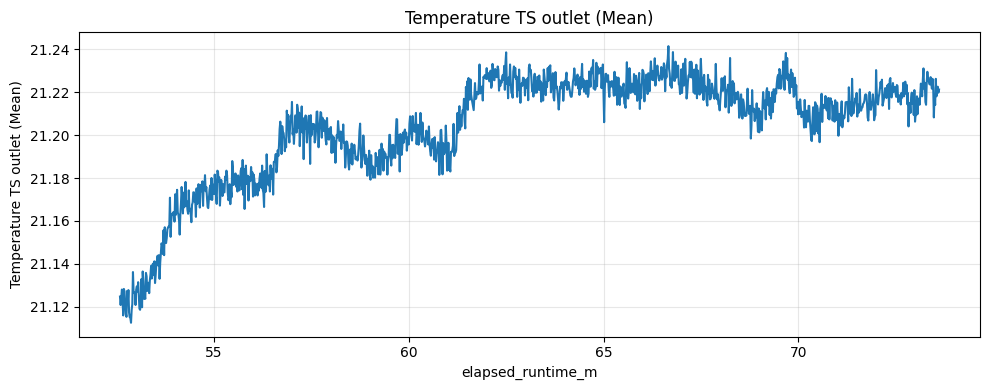

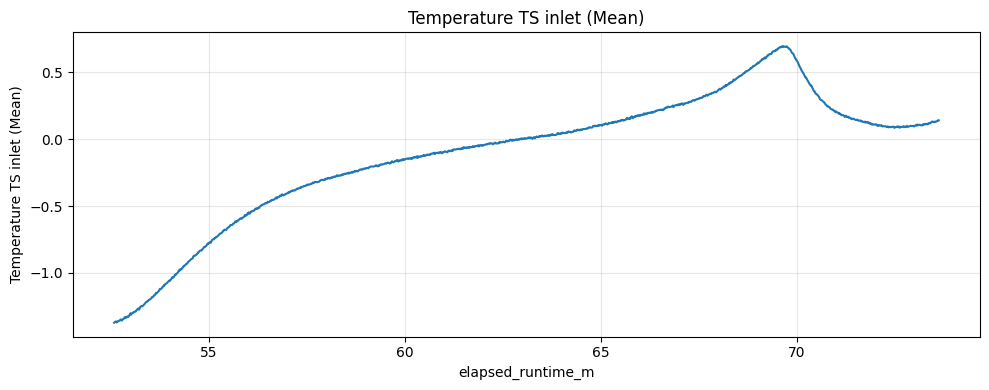

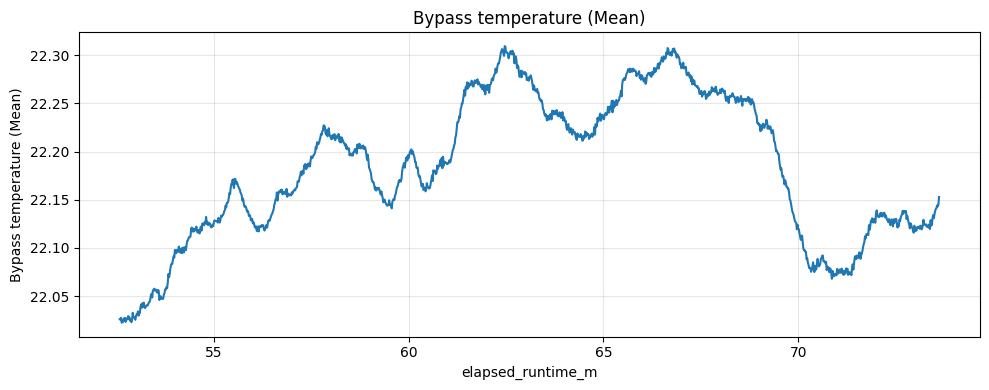

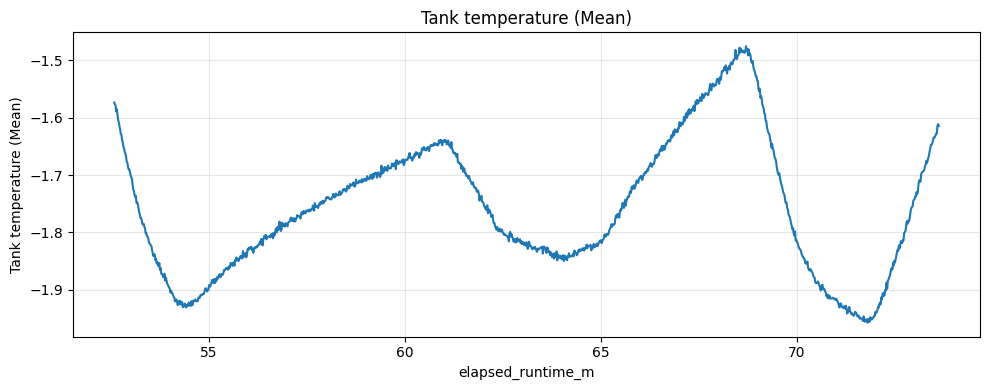

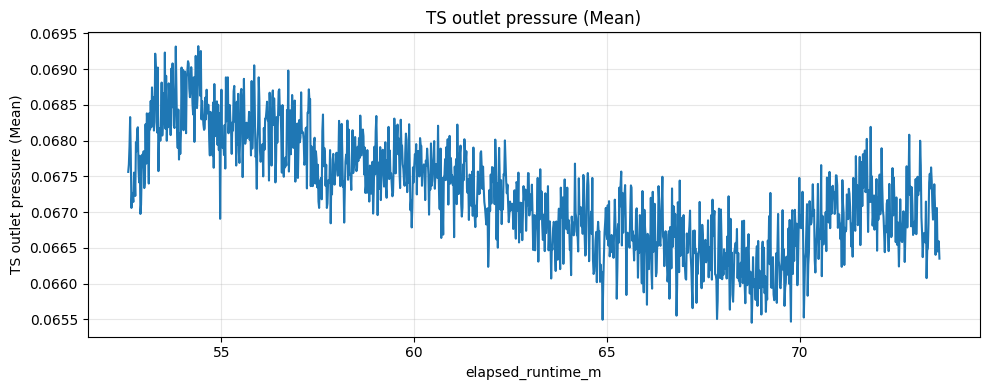

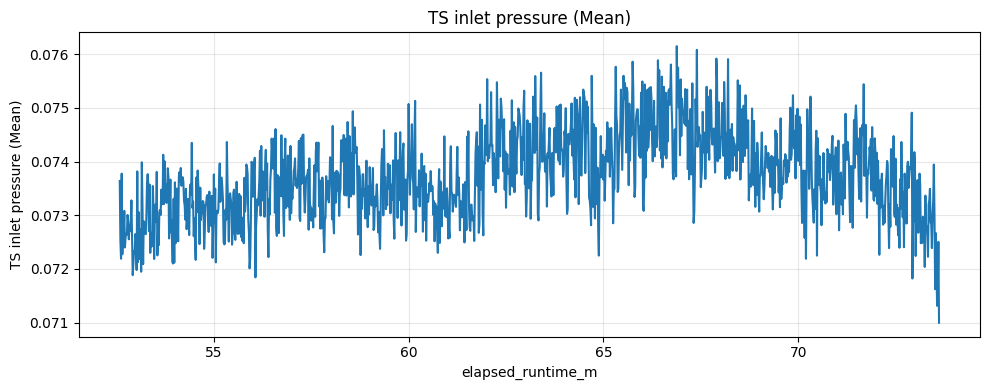

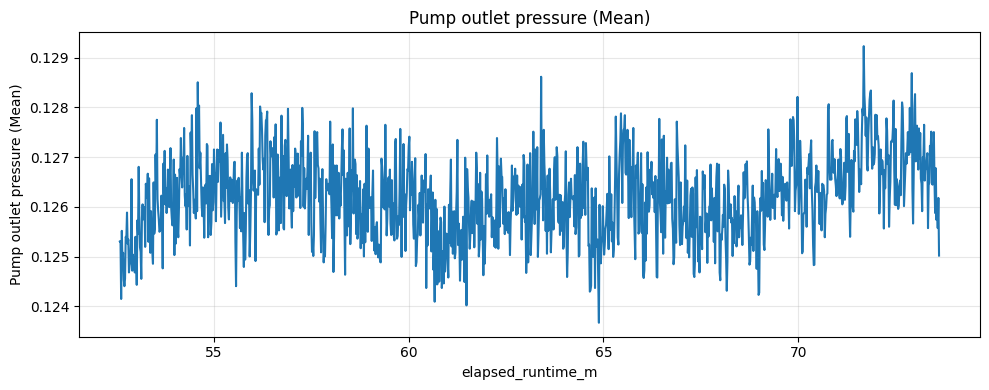

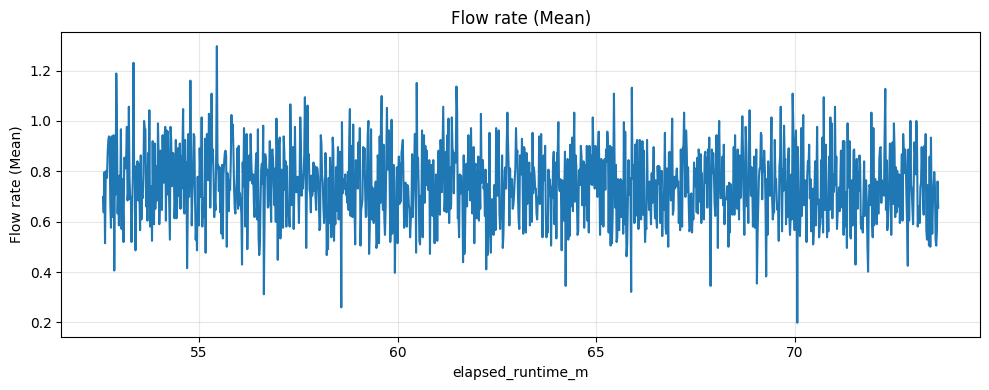

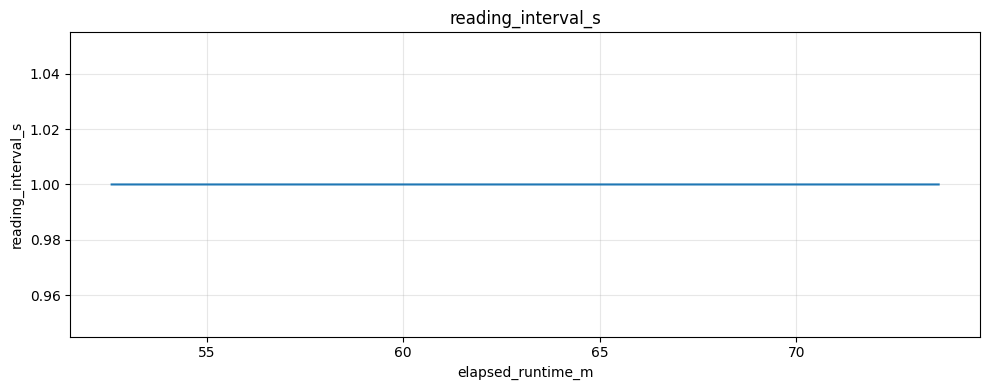

In [519]:
plot_all_timeseries(dfthrd)

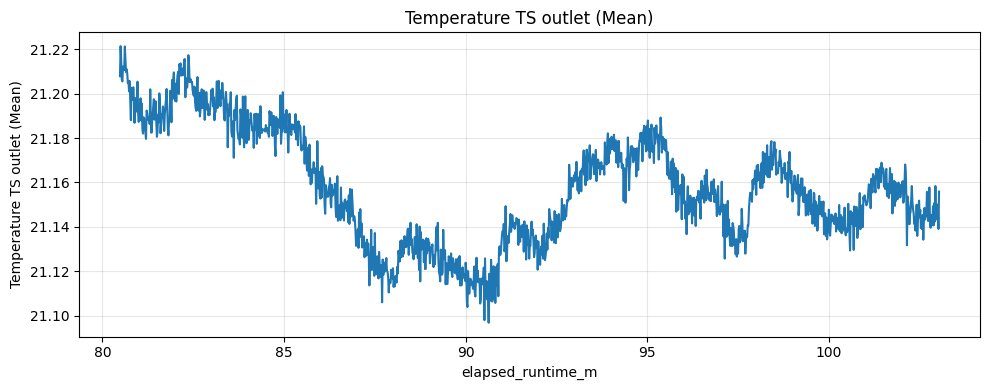

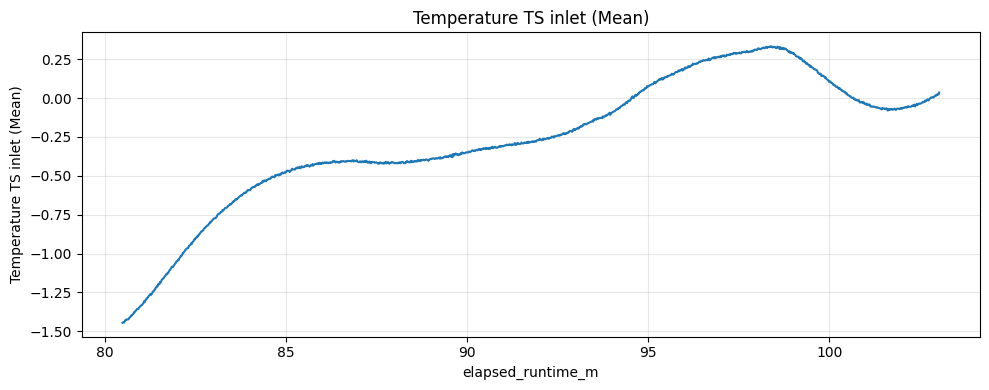

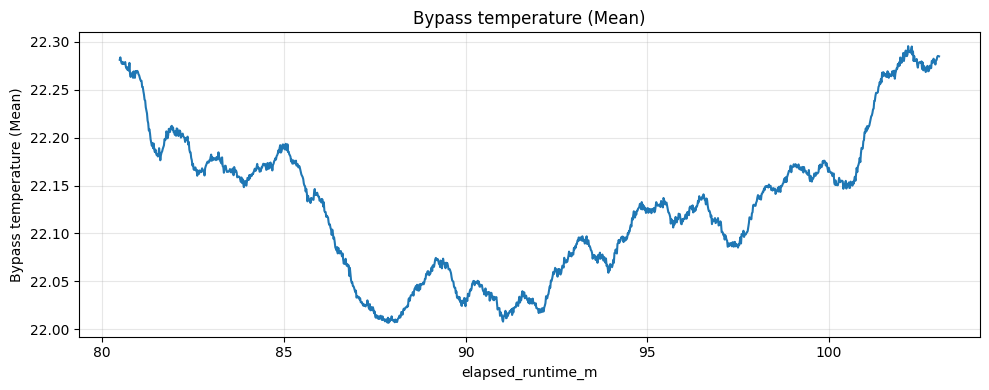

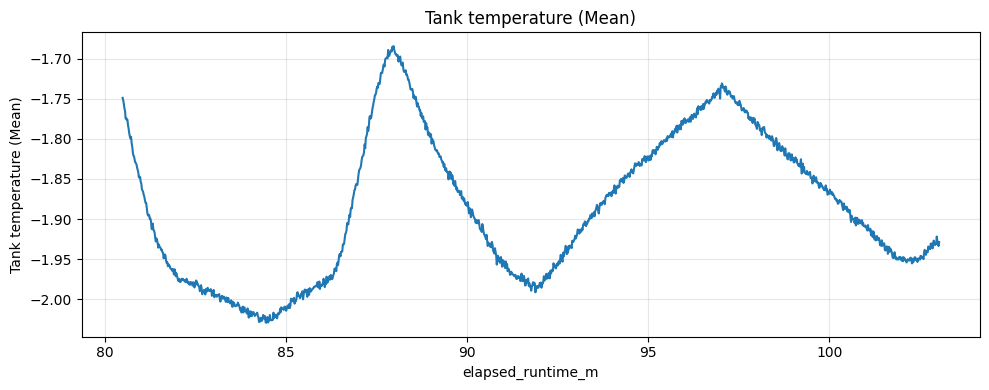

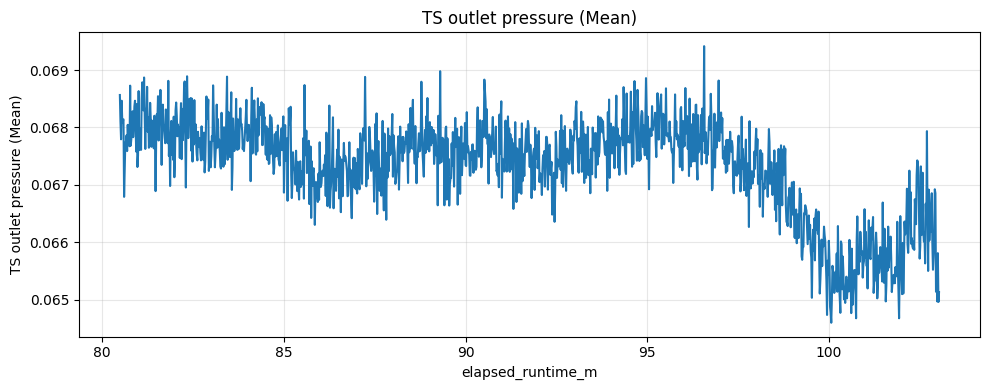

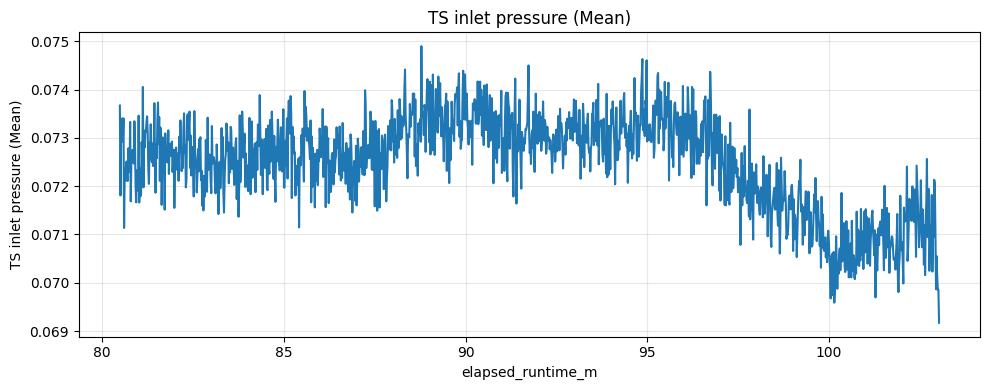

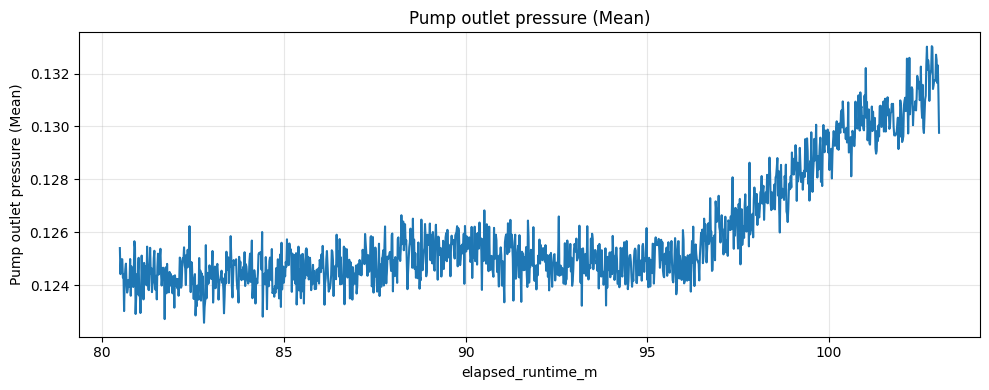

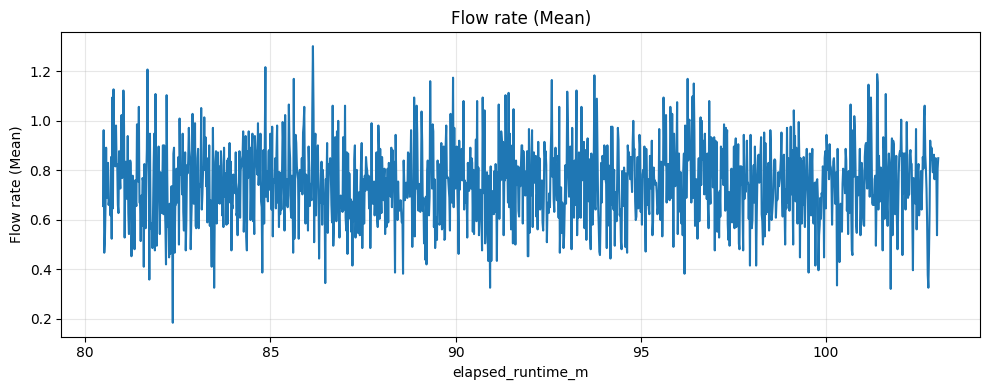

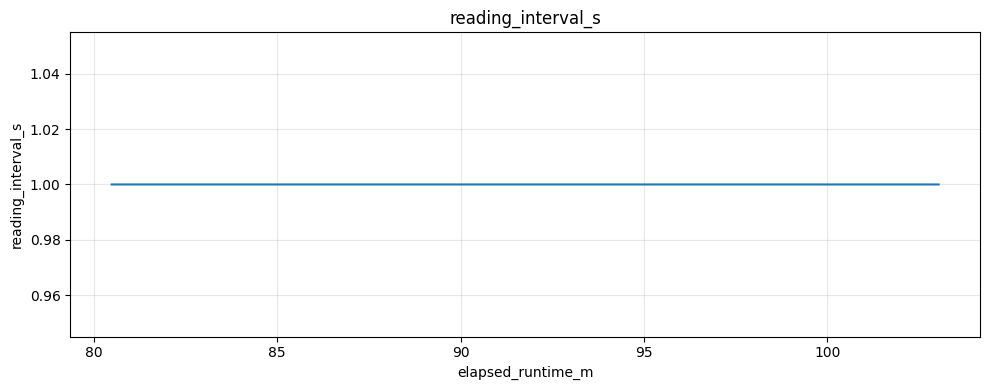

In [520]:
plot_all_timeseries(dffrth)

## 18.11

### init

In [521]:
df = df1811.copy()

In [522]:
basic_checklist(df)

Missing values:
Time                               0
Temperature TS outlet (Mean)       0
Temperature TS inlet (Mean)        0
Bypass temperature (Mean)          0
Tank temperature (Mean)            0
TS outlet pressure (Mean)          0
TS inlet pressure (Mean)           0
Pump outlet pressure (Mean)        0
Flow rate (Mean)                   0
Unnamed: 9                         0
Unnamed: 10                     2217
dtype: int64

Time column is monotonic increasing.


In [523]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    2253
0.0       1
Name: count, dtype: int64

In [524]:
df.drop(columns=['Unnamed: 9', 'Unnamed: 10'], inplace=True)

### plotting

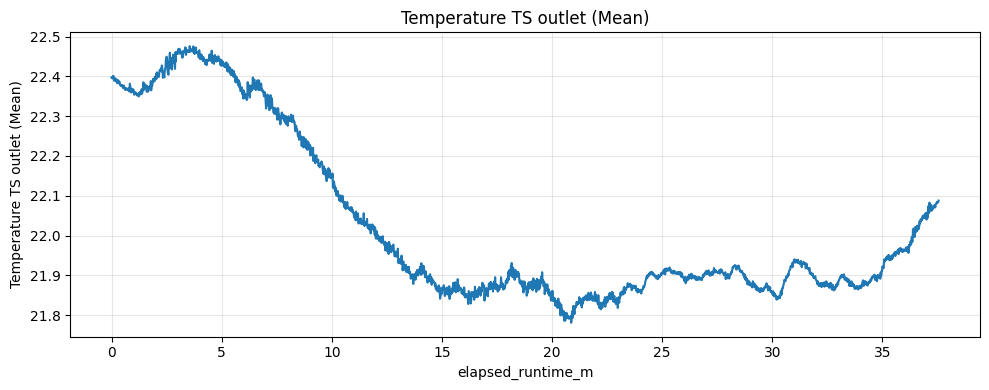

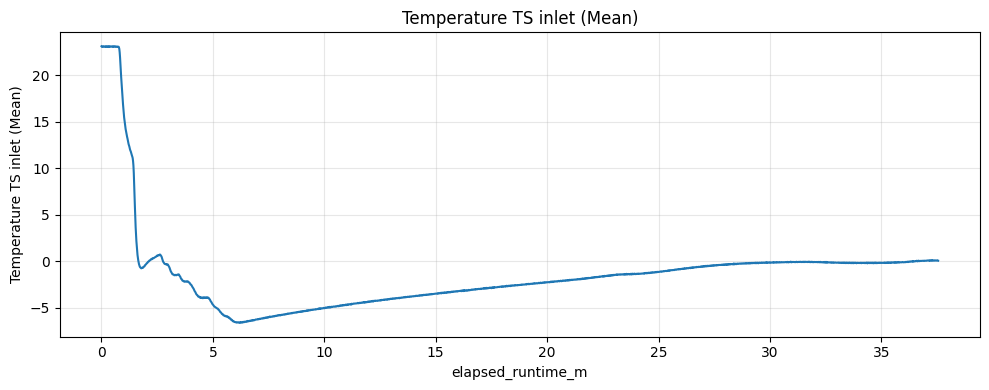

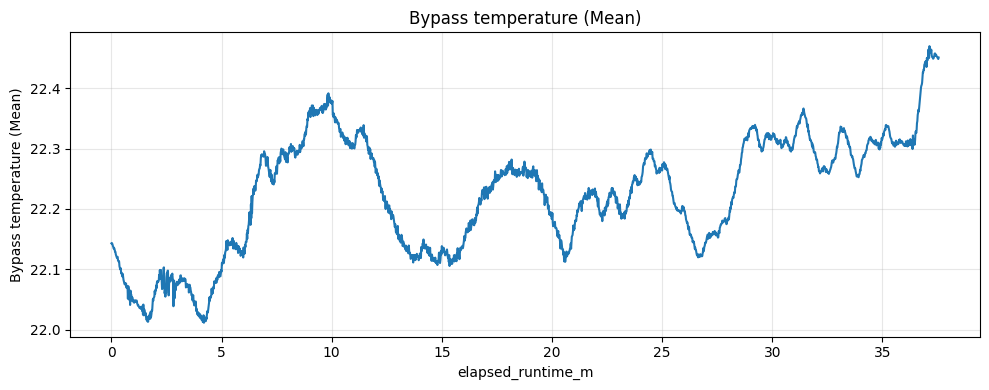

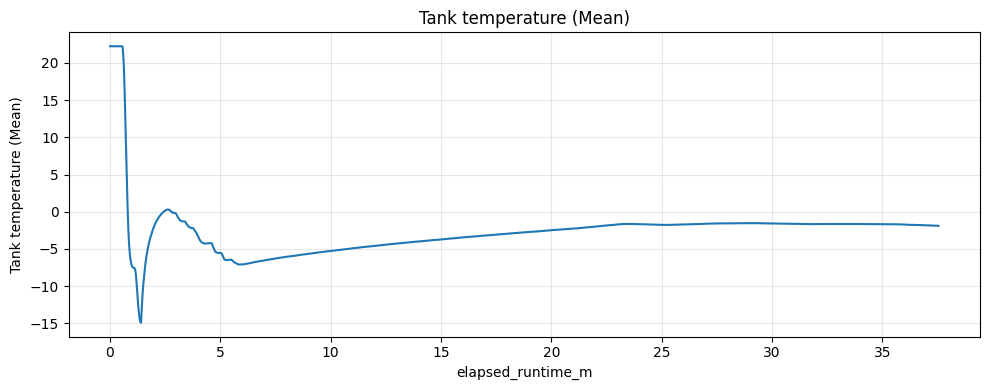

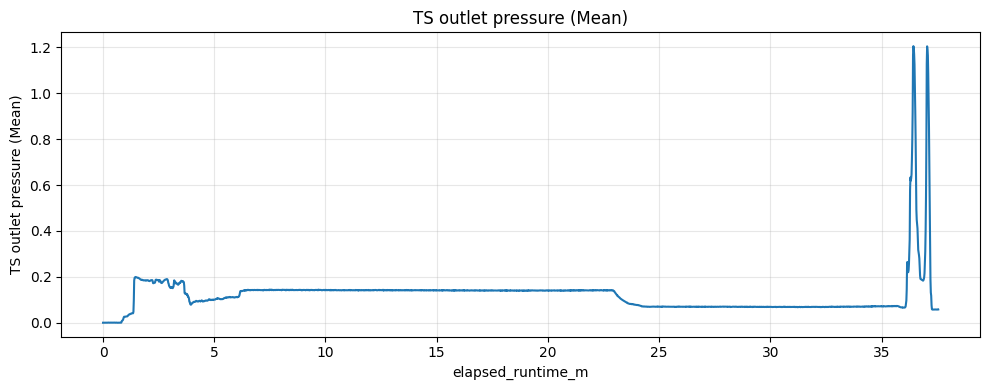

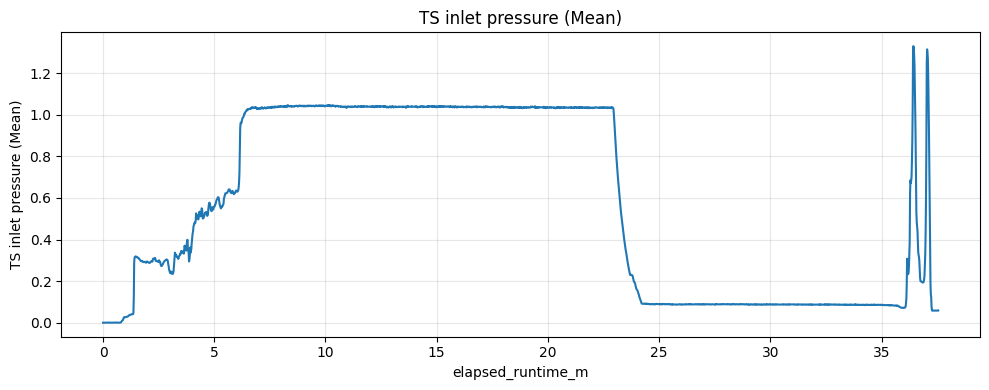

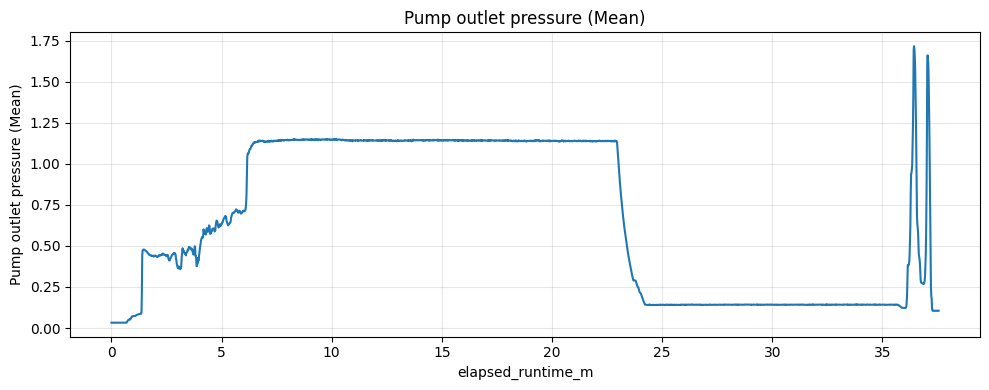

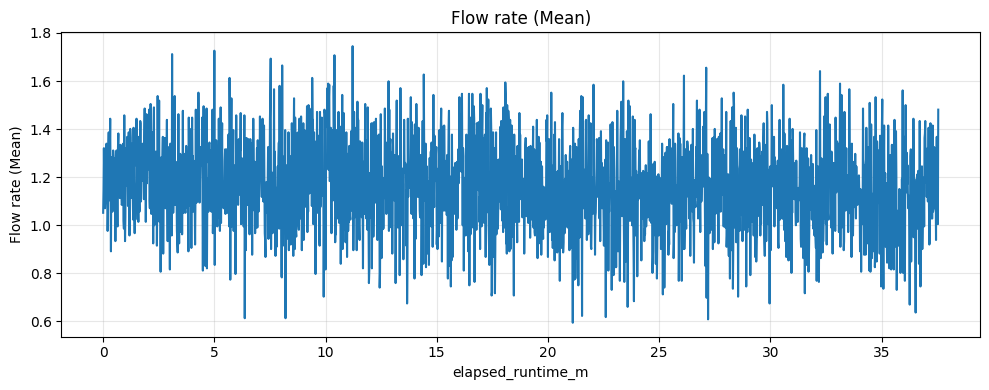

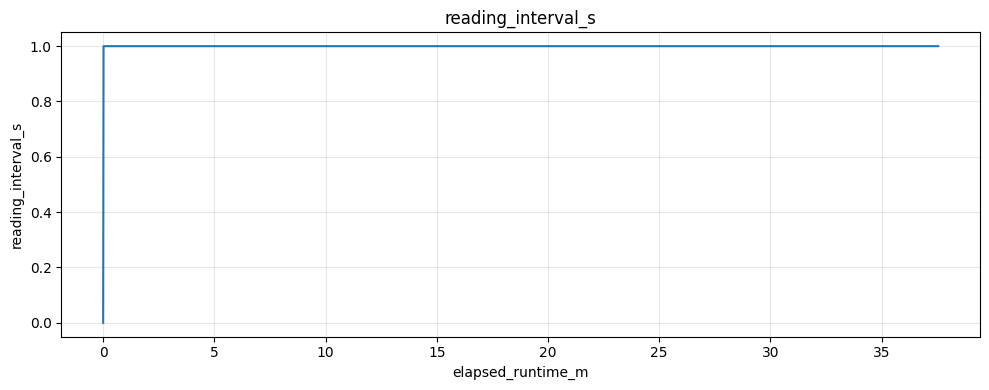

In [525]:
plot_all_timeseries(df)

### snipping

13:40:14 – 13:50:30 - loop blockage

In [526]:
start = find_index_at_timestamp(df, 134014)
end = find_index_at_timestamp(df, 135030)
df = snip_df_at_timecode(df, start, end)

In [527]:
df.to_csv('../data/split/plug/1811.csv', index=False)

### plot after snip

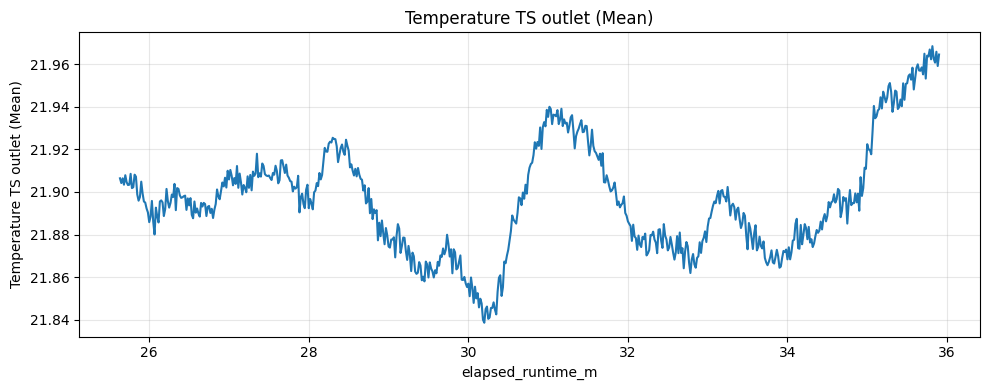

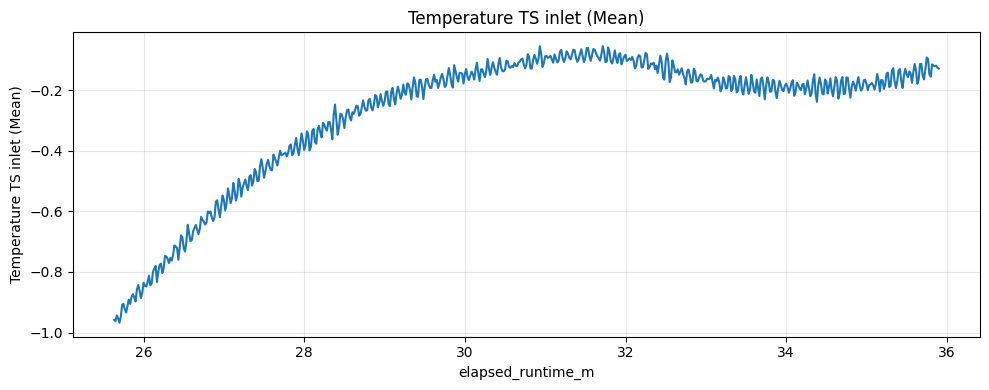

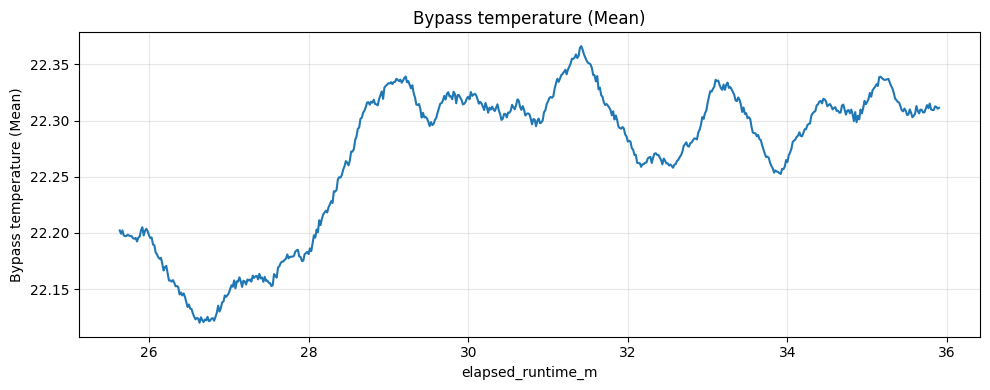

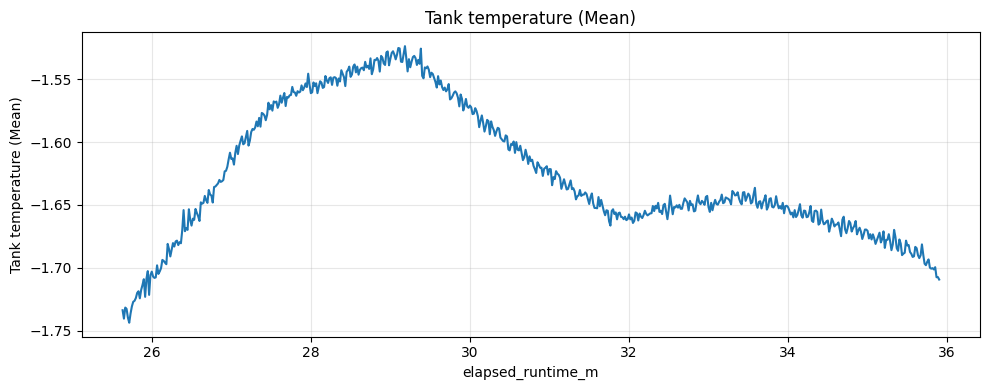

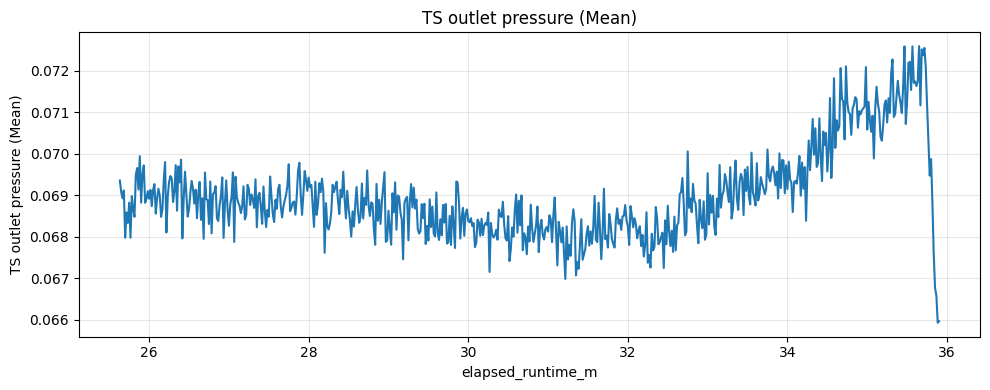

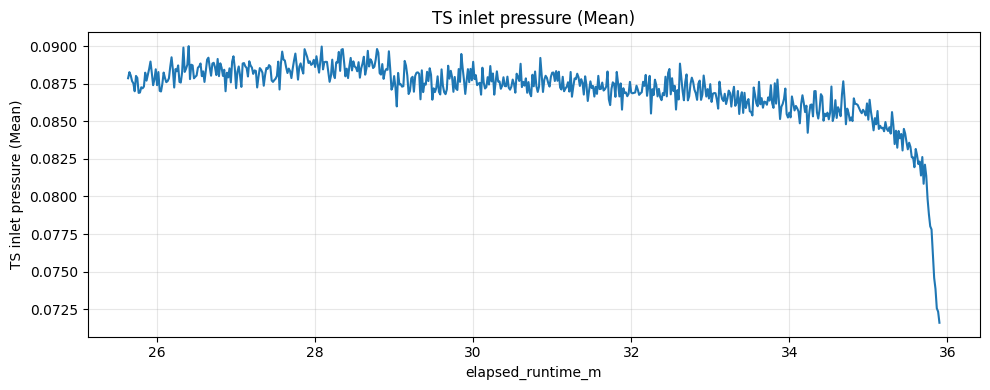

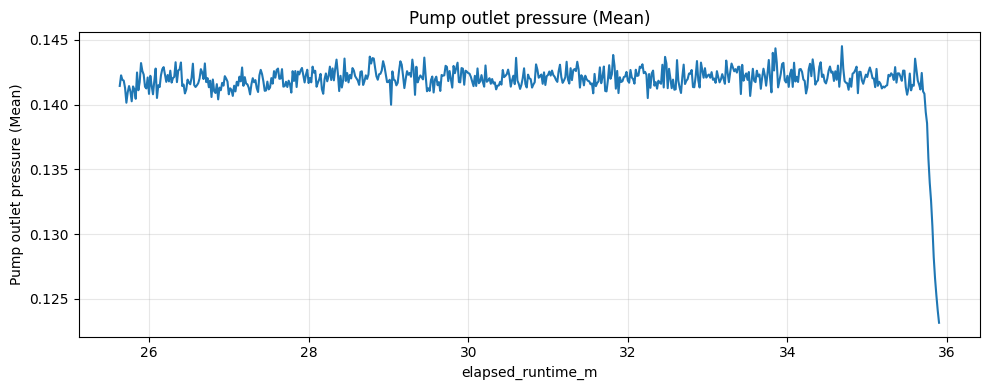

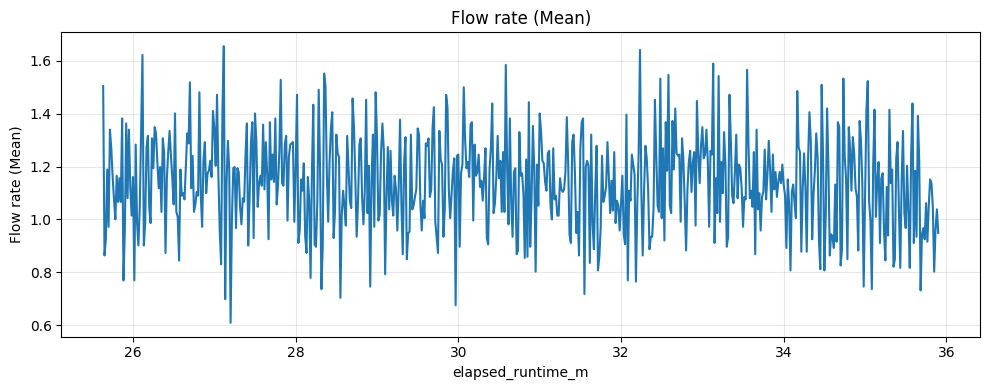

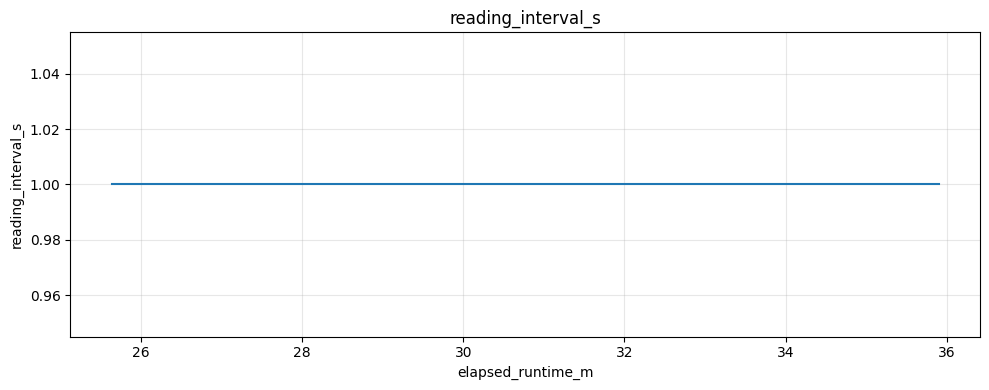

In [528]:
plot_all_timeseries(df)

## 0612

### init

In [529]:
df = df0612.copy()

In [530]:
basic_checklist(df)

Missing values:
Time                               0
Temperature TS outlet (Mean)       0
Temperature TS inlet (Mean)        0
Bypass temperature (Mean)          0
Tank temperature (Mean)            0
TS outlet pressure (Mean)          0
TS inlet pressure (Mean)           0
Pump outlet pressure (Mean)        0
Flow rate (Mean)                   0
Unnamed: 9                         0
Unnamed: 10                     3321
dtype: int64

Time column is monotonic increasing.


In [531]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    3416
0.0       1
Name: count, dtype: int64

In [532]:
df.drop(columns = ['Unnamed: 9', 'Unnamed: 10'], inplace=True)

### plotting

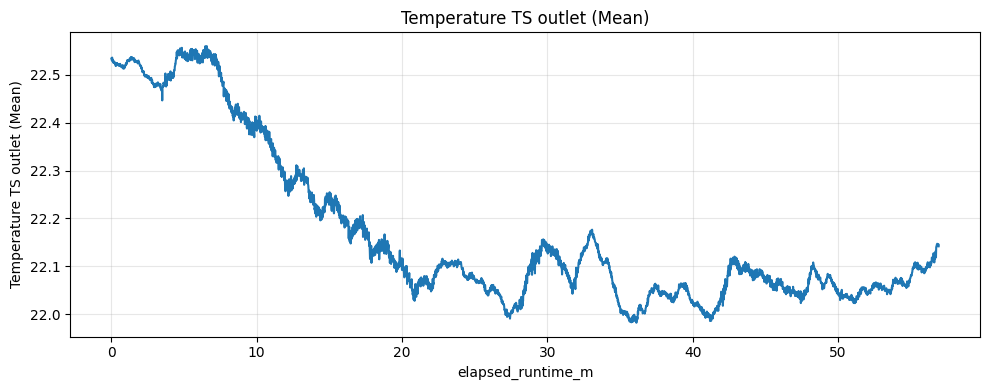

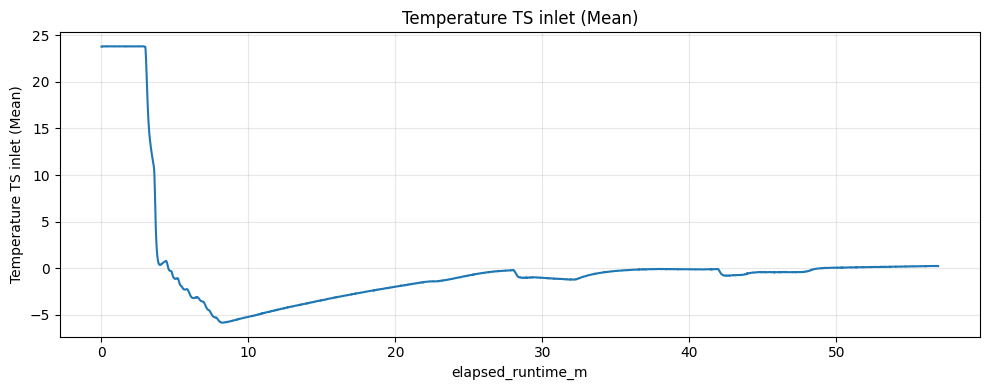

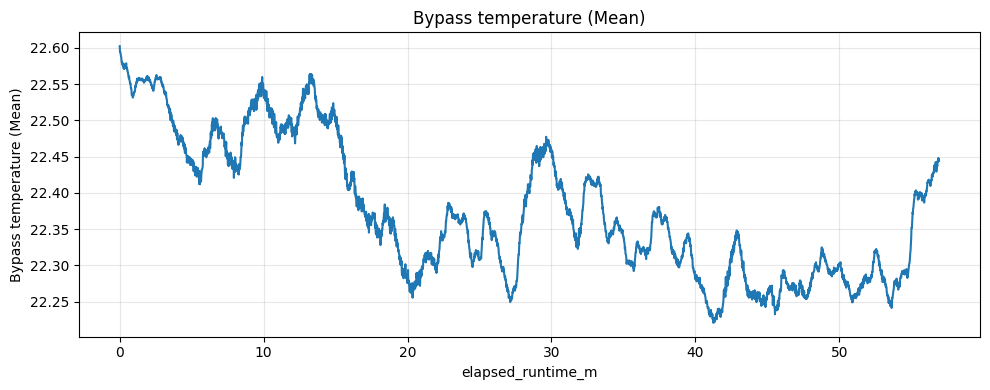

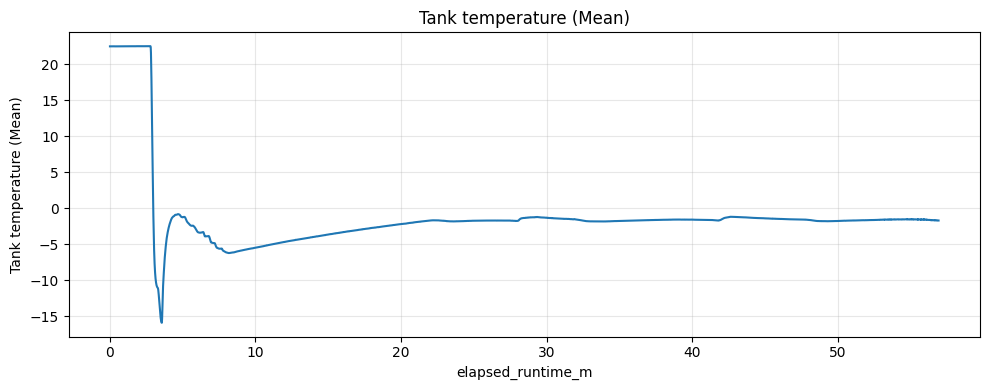

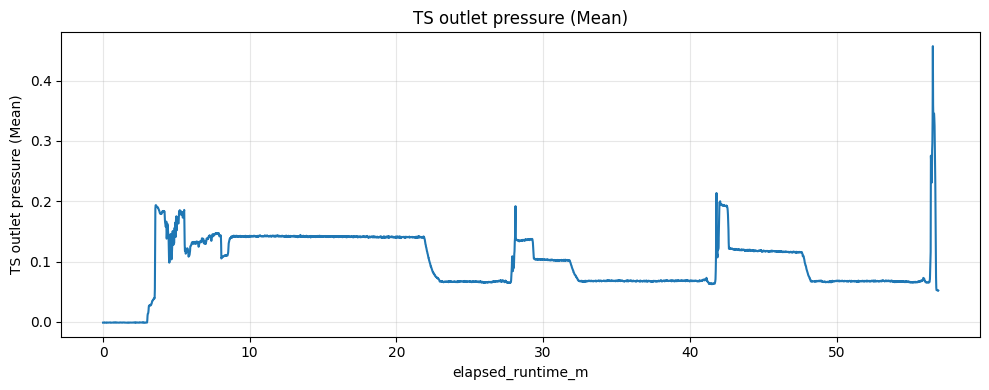

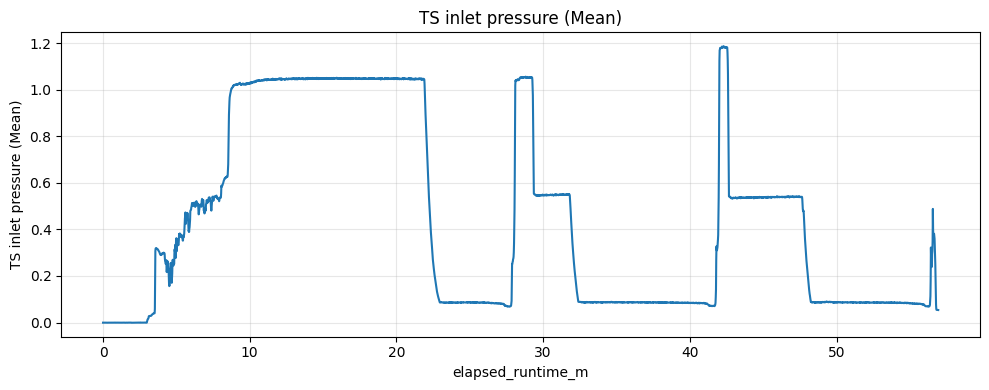

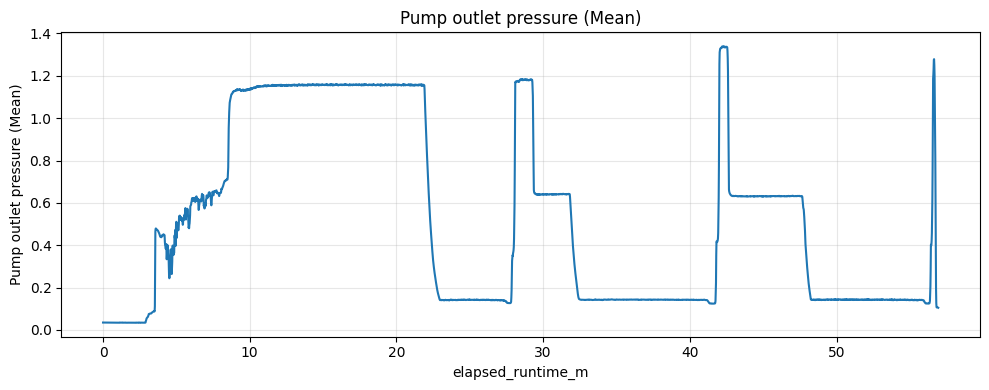

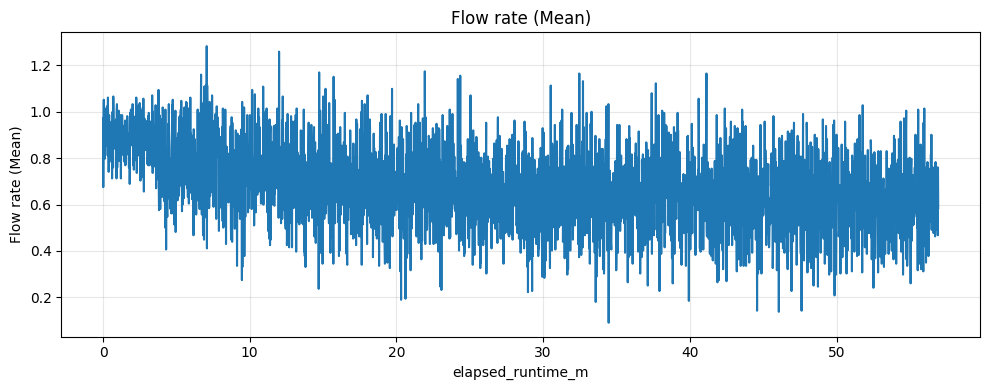

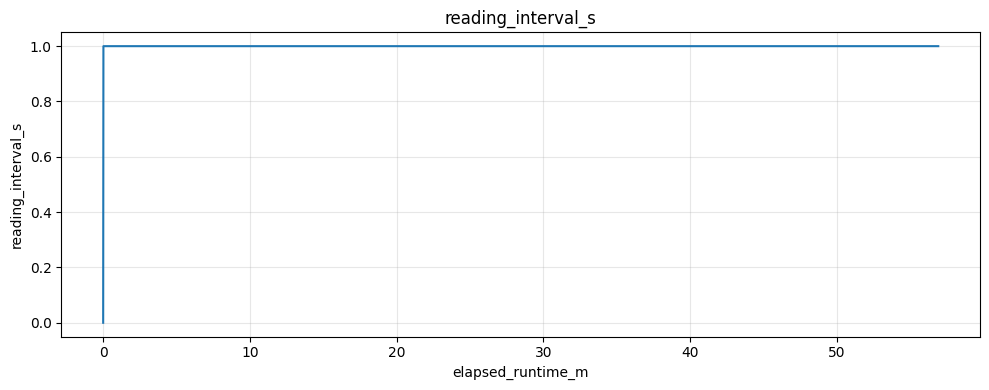

In [533]:
plot_all_timeseries(df)

### snipping

Time codes:

13:42:38 – 13:47:05 – loop blockage

13:52:04 – 14:00:51 – test section plugging

14:07:56 – 14:15:36 – both loop and test section blocked


In [534]:
start = find_index_at_timestamp(df, 134238)
end = find_index_at_timestamp(df, 134705)
dffirst = snip_df_at_timecode(df, start, end)

In [535]:
start = find_index_at_timestamp(df, 135204)
end = find_index_at_timestamp(df, 140051)
dfsnd = snip_df_at_timecode(df, start, end)

In [536]:
start = find_index_at_timestamp(df, 140756)
end = find_index_at_timestamp(df, 141536)
dfthrd = snip_df_at_timecode(df, start, end)

In [537]:
dffirst.to_csv('../data/split/plug/0612-1.csv', index=False)
dfsnd.to_csv('../data/split/plug/0612-2.csv', index=False)
dfthrd.to_csv('../data/split/plug/0612-3.csv', index=False)

### plot after snip

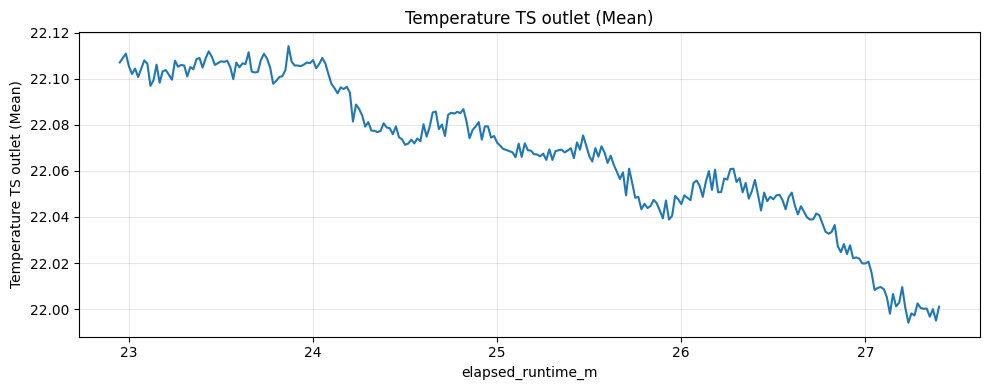

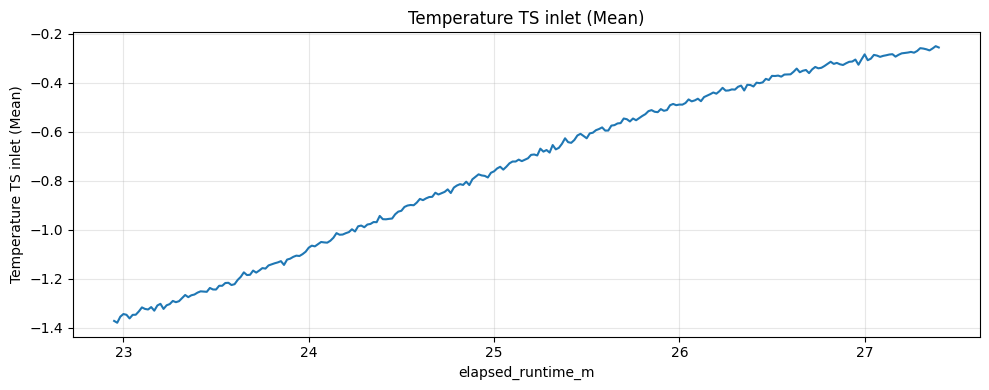

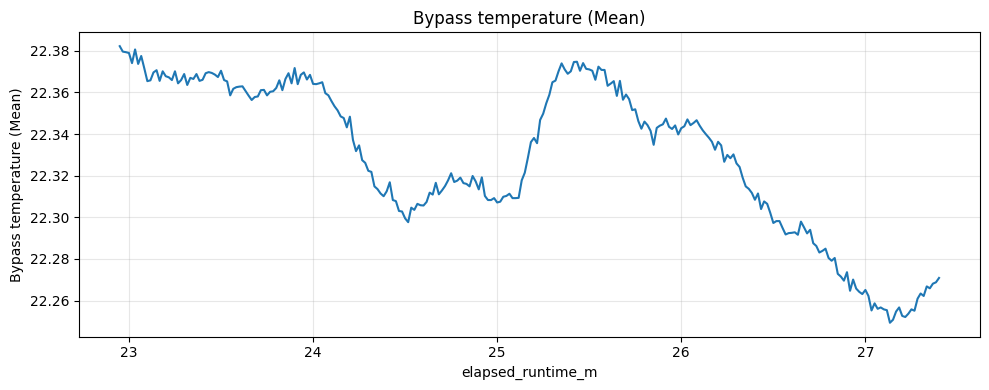

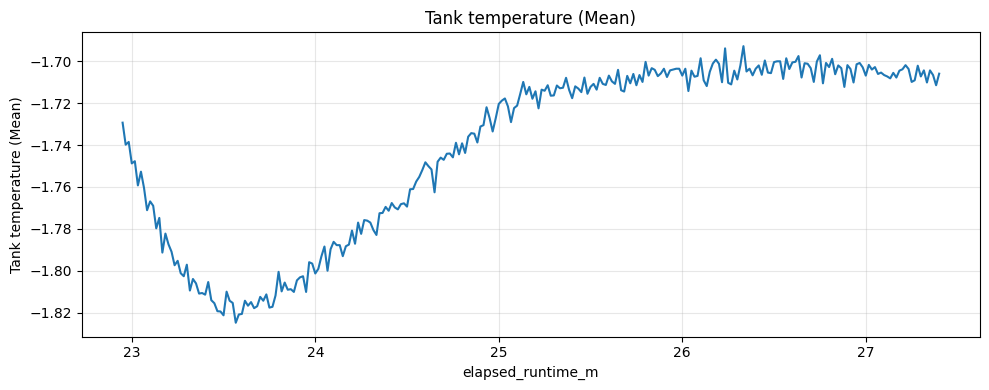

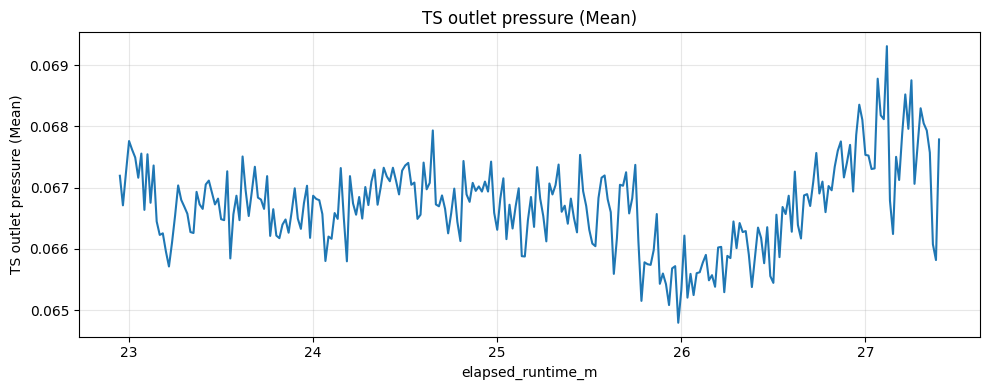

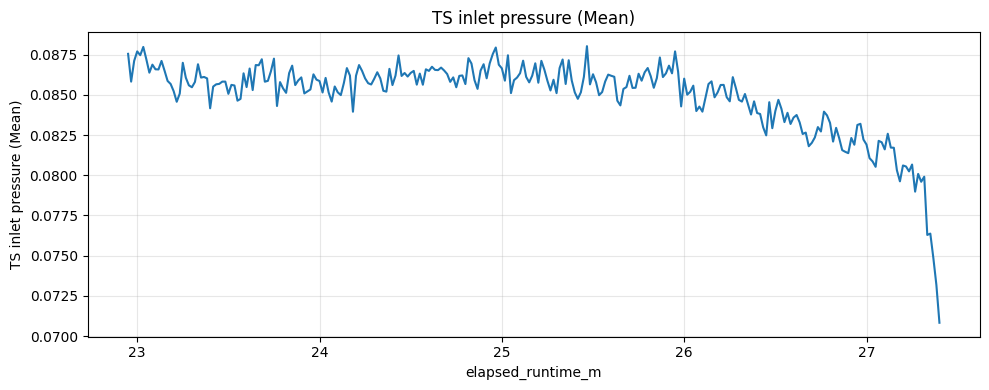

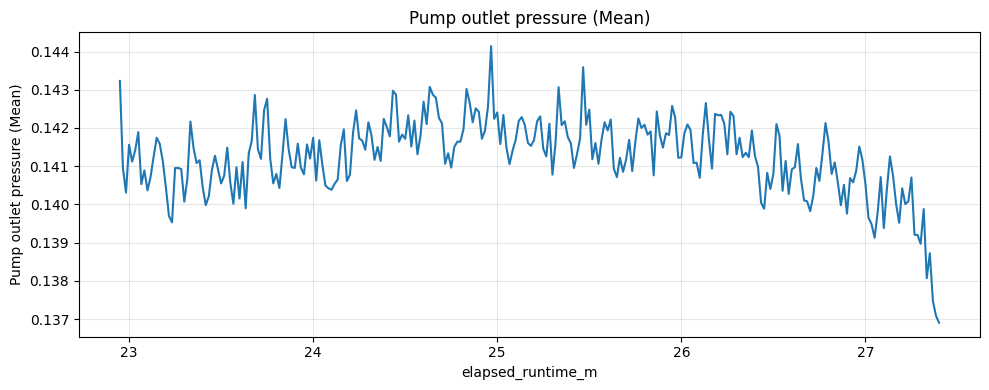

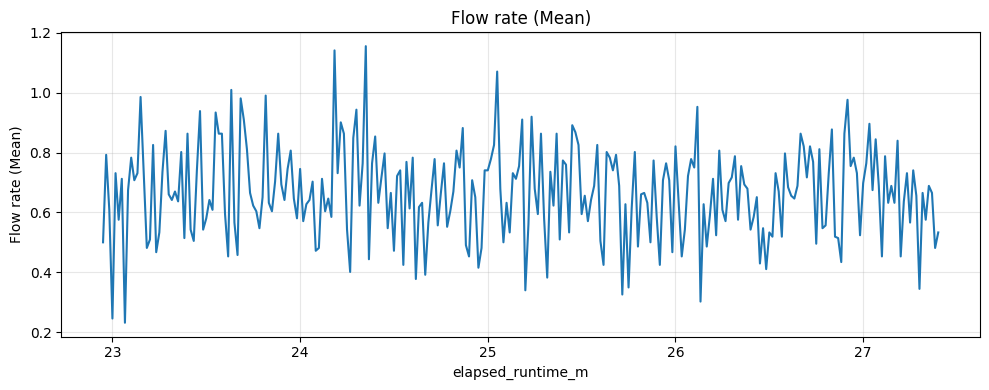

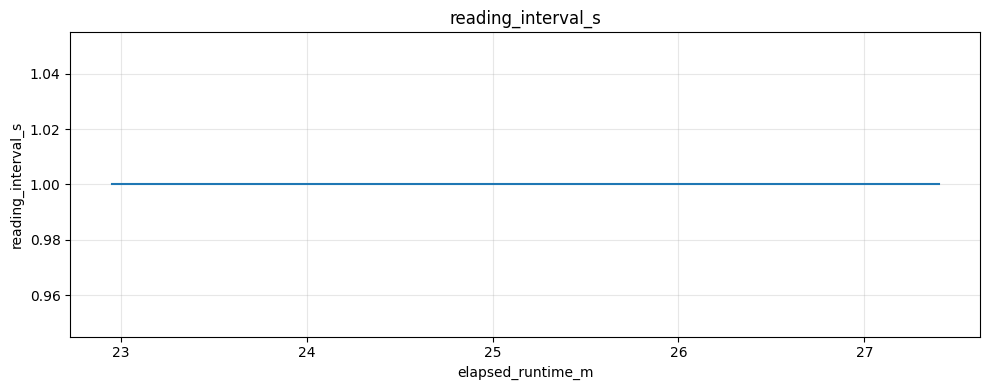

In [538]:
plot_all_timeseries(dffirst)

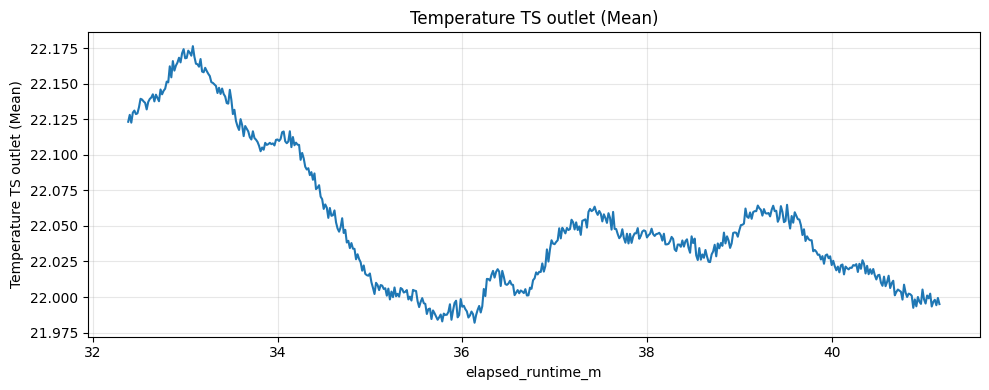

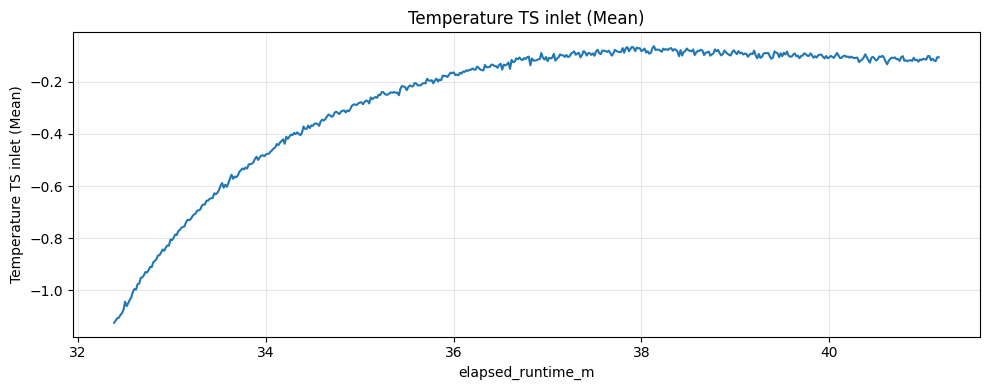

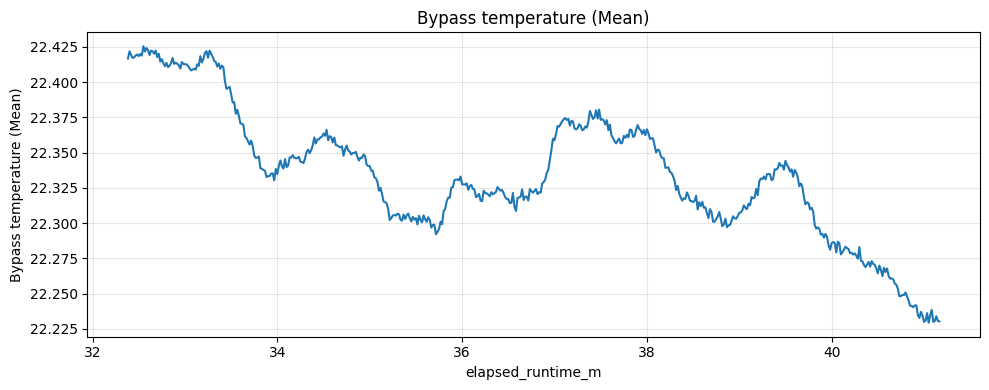

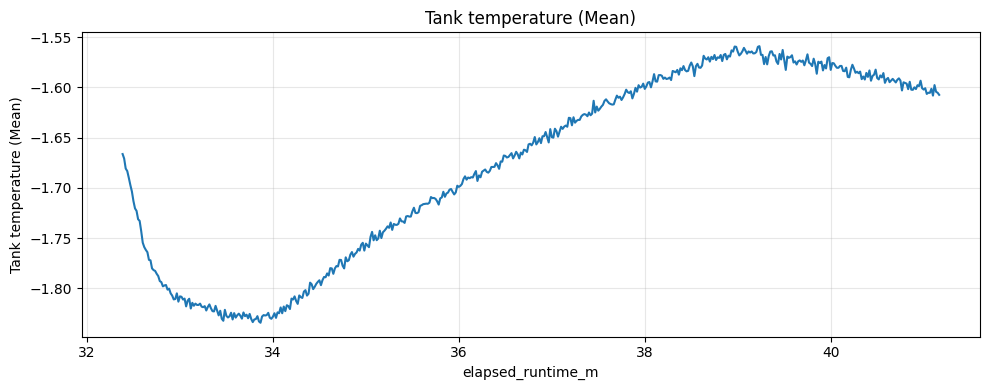

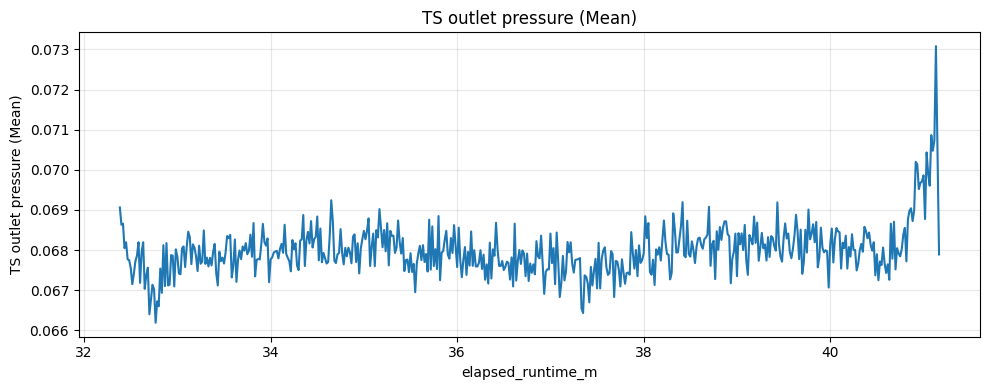

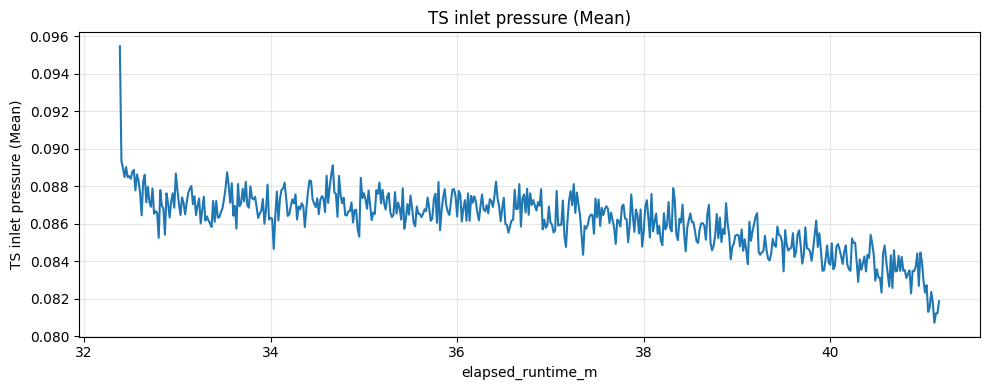

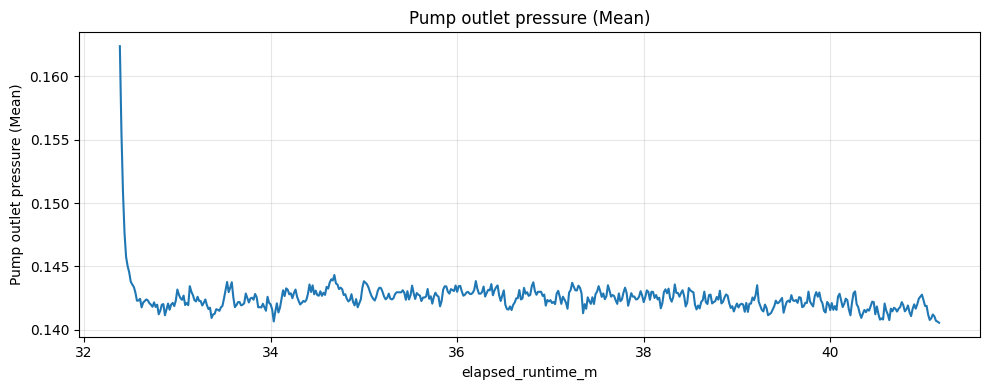

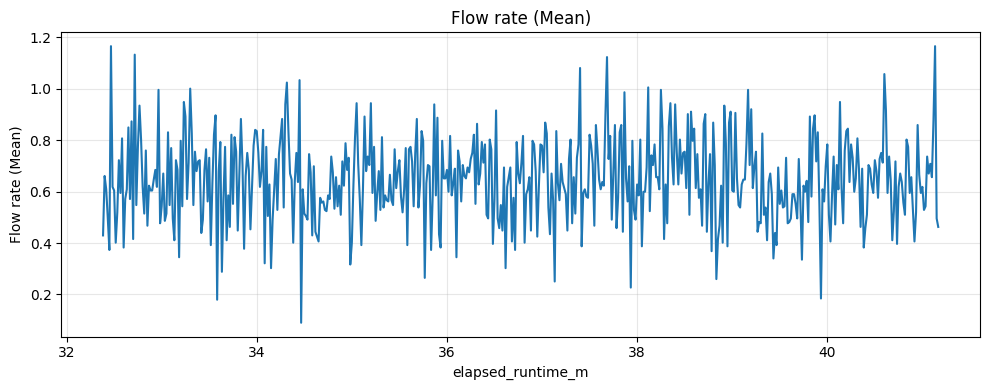

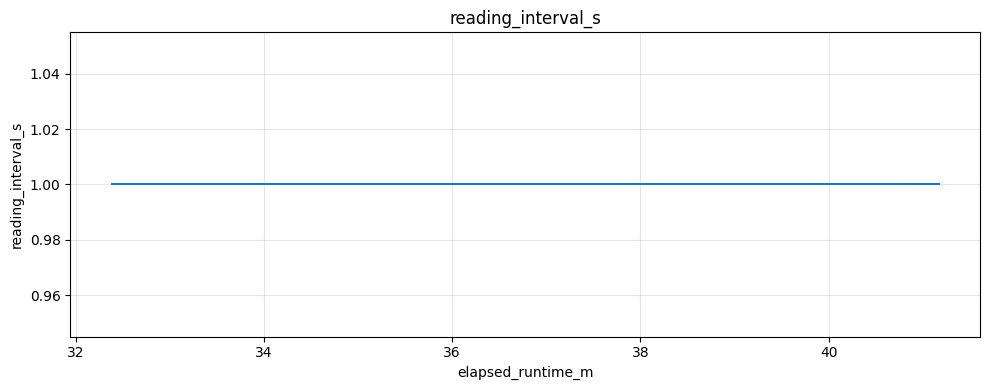

In [539]:
plot_all_timeseries(dfsnd)

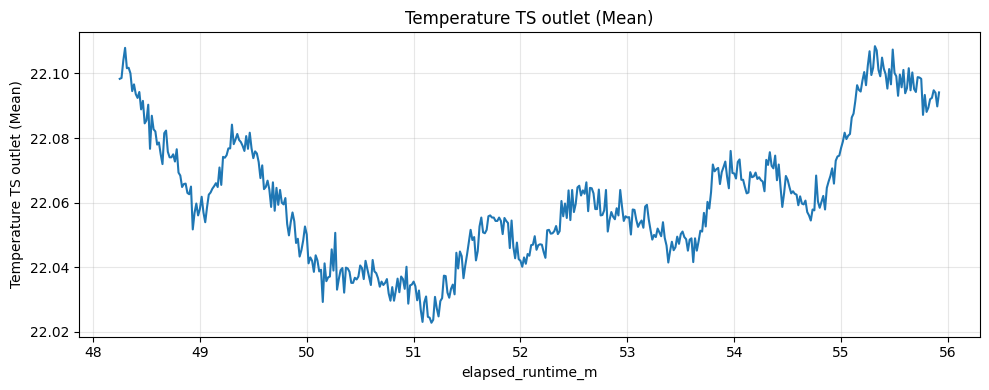

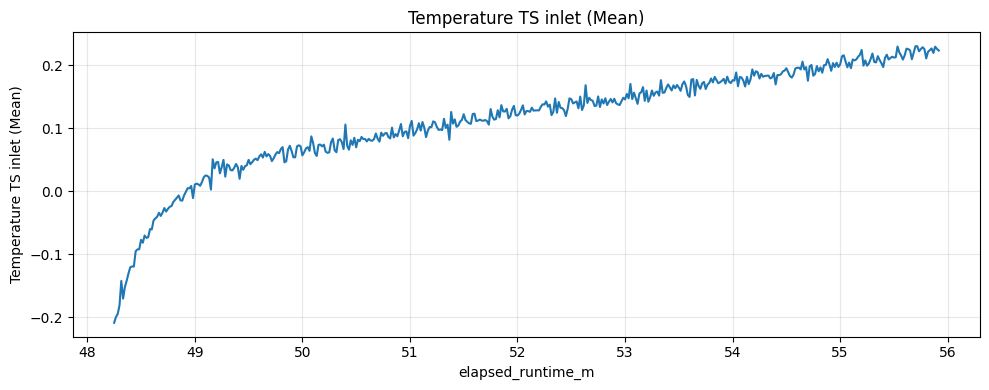

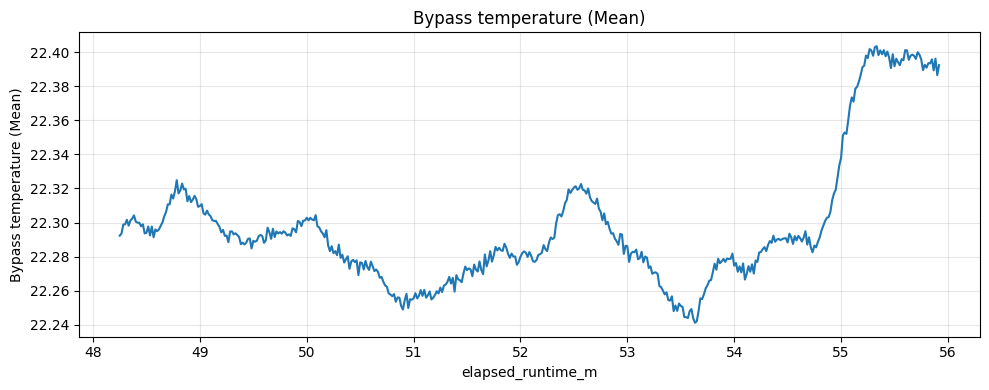

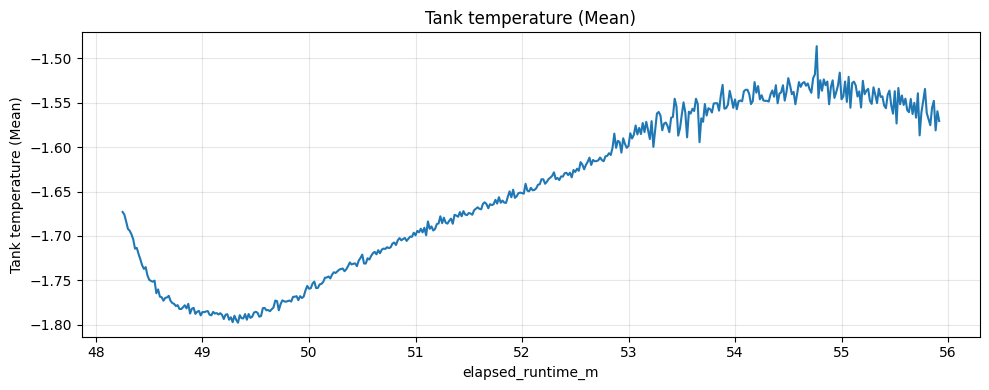

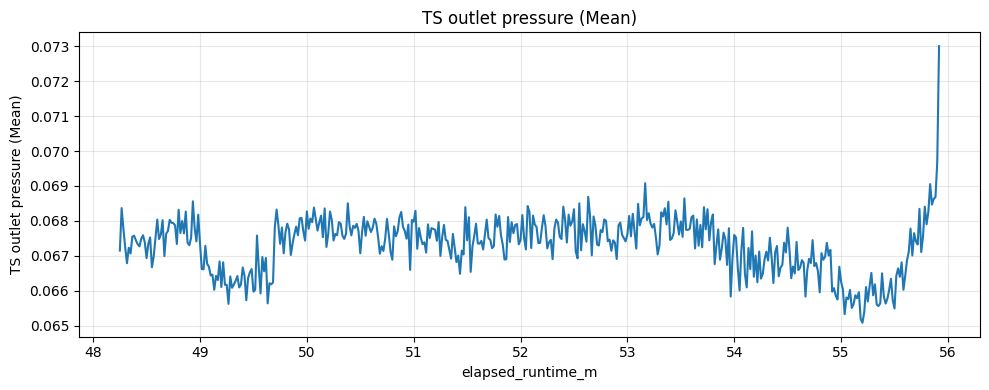

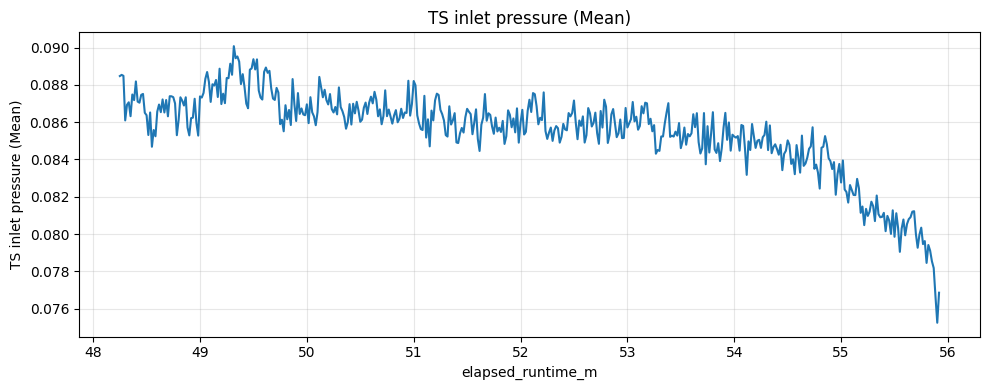

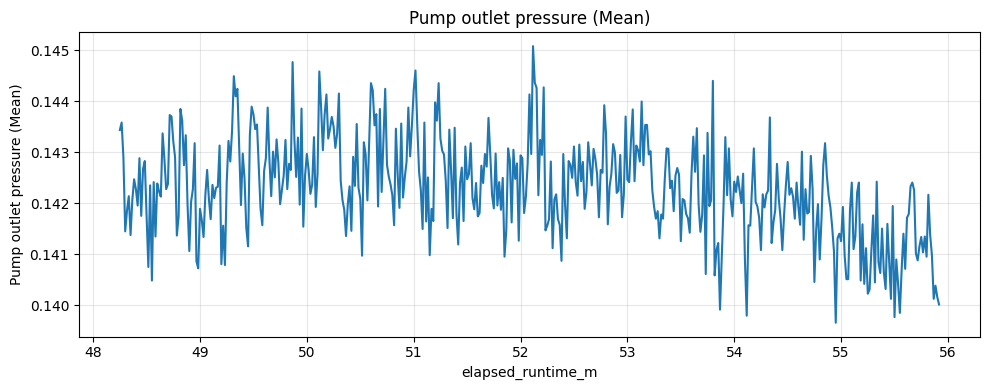

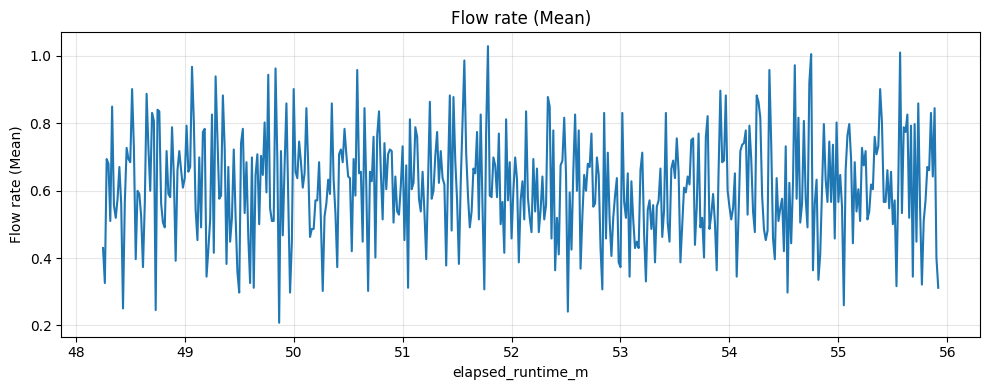

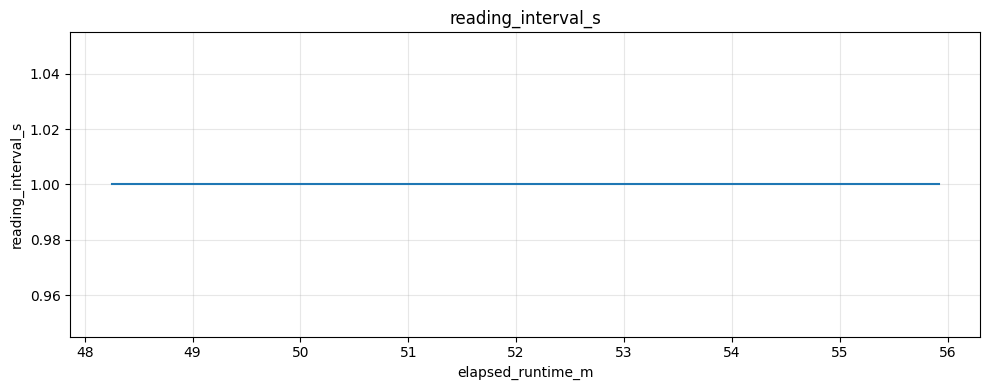

In [540]:
plot_all_timeseries(dfthrd)

## 07.07

### init

In [541]:
df = df0707.copy()

In [542]:
basic_checklist(df)

Missing values:
No missing values found.

Time column is monotonic increasing.


In [543]:
df = sensor_reading_interval(df)
df['reading_interval_s'].round(2).value_counts()

reading_interval_s
1.0    8230
0.0       1
Name: count, dtype: int64

In [544]:
df.drop(columns=['Unnamed: 9', 'Unnamed: 10'], inplace=True)

### plotting

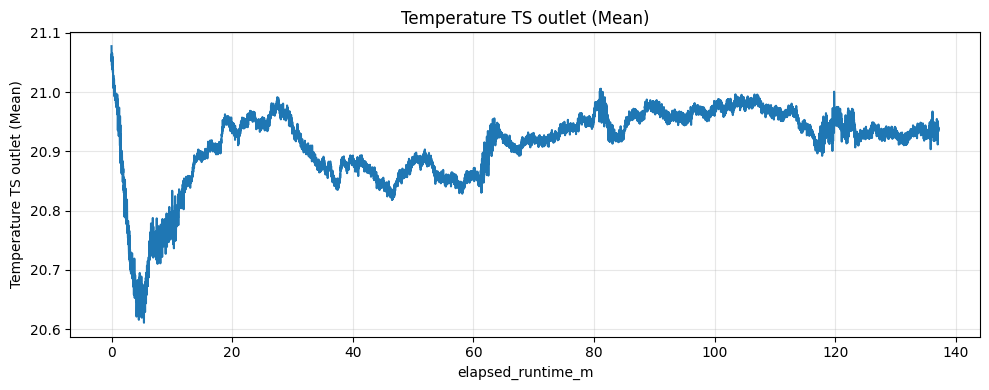

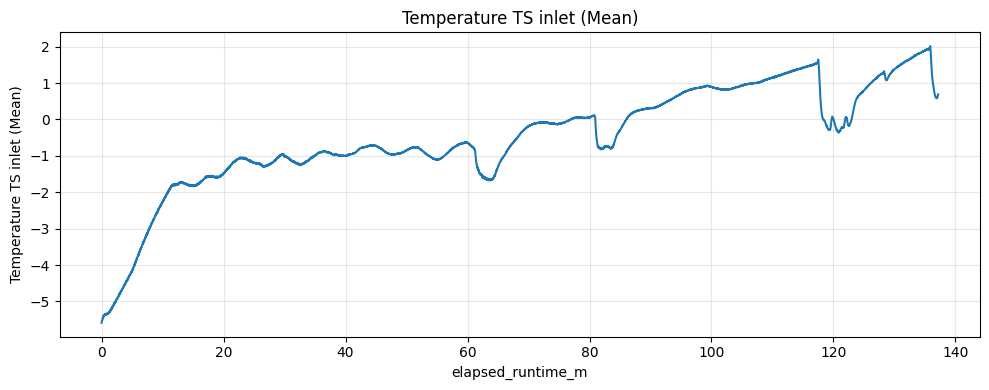

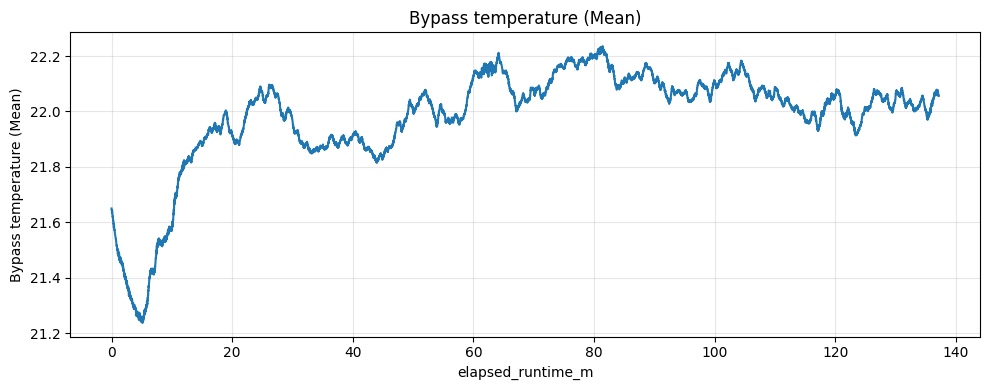

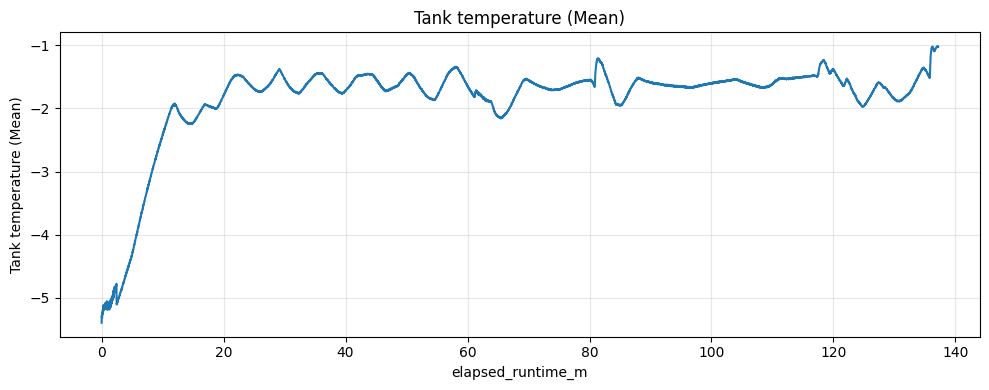

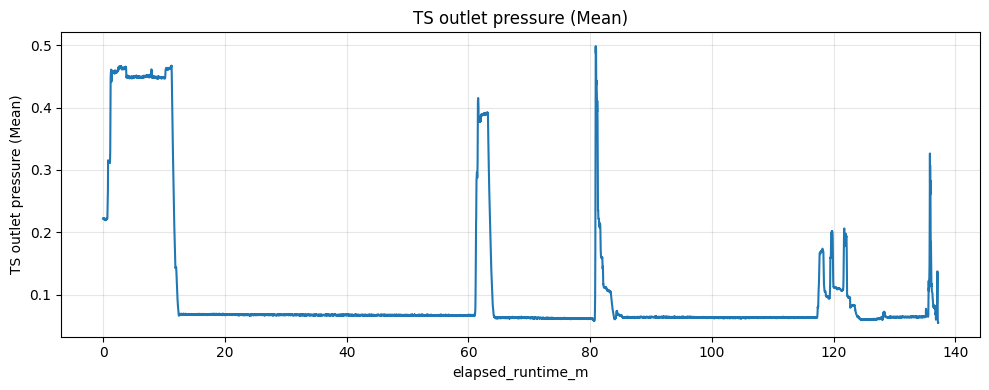

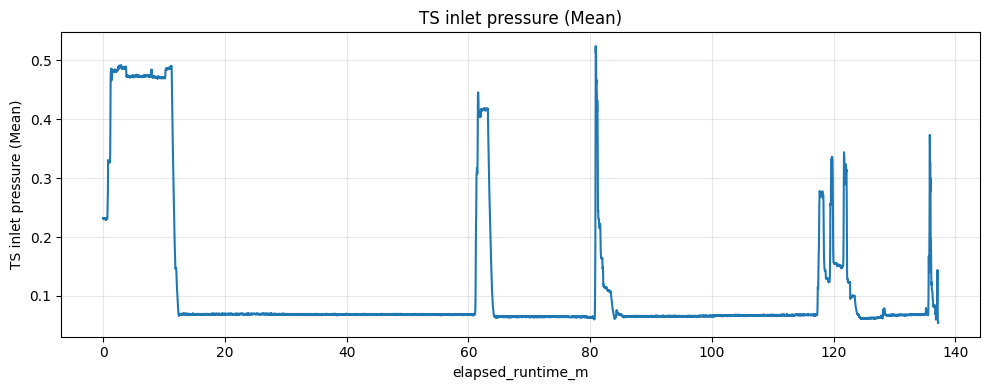

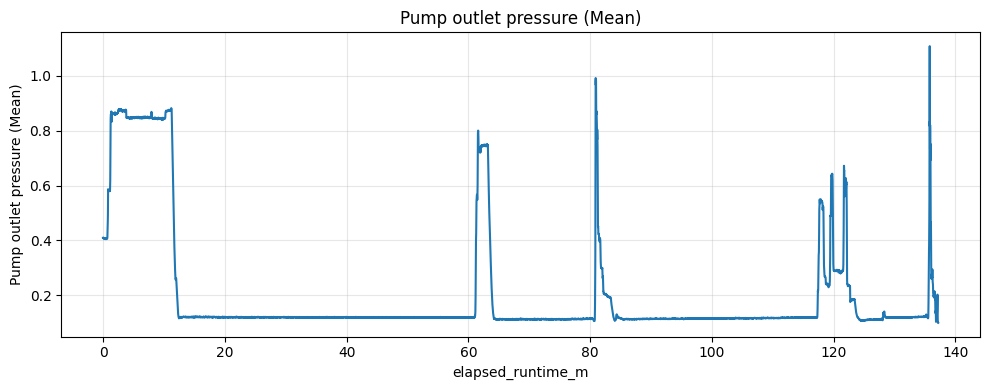

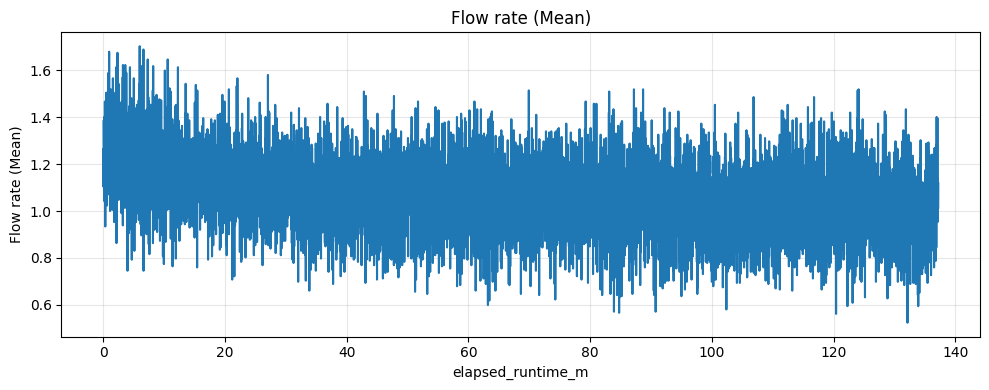

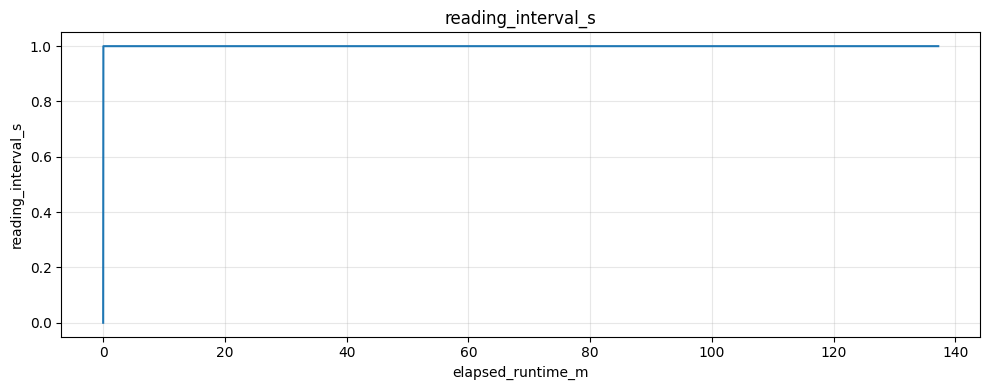

In [545]:
plot_all_timeseries(df)

### snipping


Time codes: 

13:36:15 - 14:24:46

14:27:56 – 14:44:16

15:28:07 - 15:31:34

15:32:12 - 15:38:52


In [546]:
start = find_index_at_timestamp(df, 133615)
end = find_index_at_timestamp(df, 142446)
dffirst = snip_df_at_timecode(df, start, end)

In [547]:
start = find_index_at_timestamp(df, 142756)
end = find_index_at_timestamp(df, 144416)
dfsnd = snip_df_at_timecode(df, start, end)

In [548]:
start = find_index_at_timestamp(df, 152807)
end = find_index_at_timestamp(df, 153134)
dfthrd = snip_df_at_timecode(df, start, end)

In [549]:
start = find_index_at_timestamp(df, 153212)
end = find_index_at_timestamp(df, 153852)
dffrth = snip_df_at_timecode(df, start, end)

In [550]:
dffirst.to_csv('../data/split/plug/0707-1.csv', index=False)
dfsnd.to_csv('../data/split/plug/0707-2.csv', index=False)
dfthrd.to_csv('../data/split/plug/0707-3.csv', index=False)
dffrth.to_csv('../data/split/plug/0707-4.csv', index=False)

### plot after snip

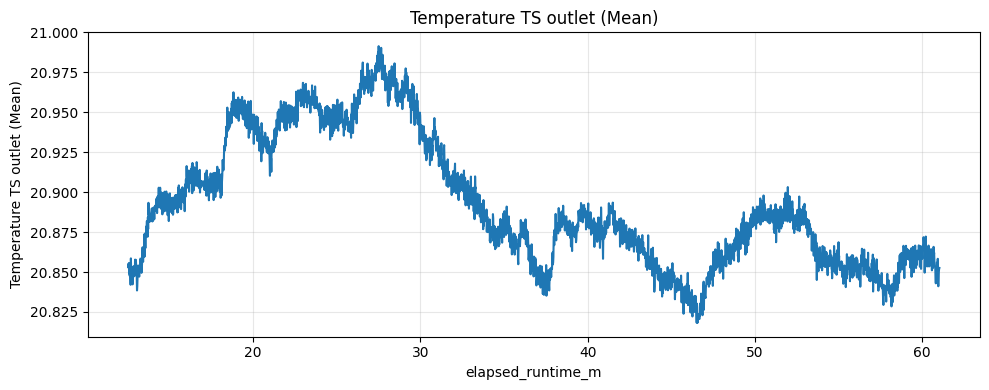

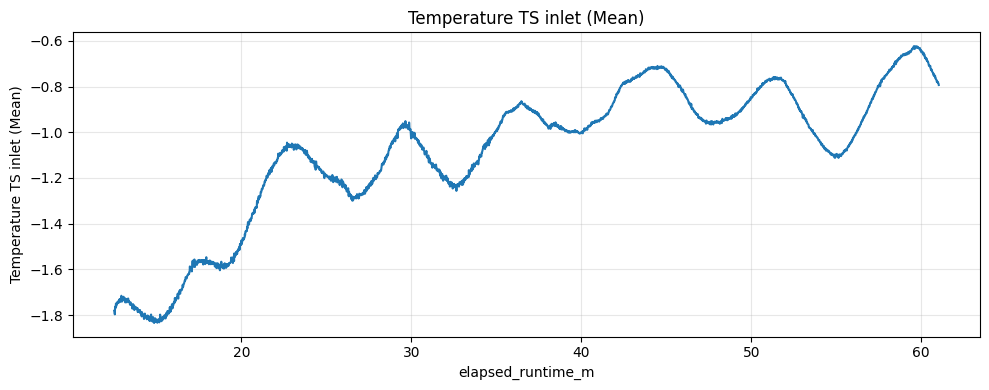

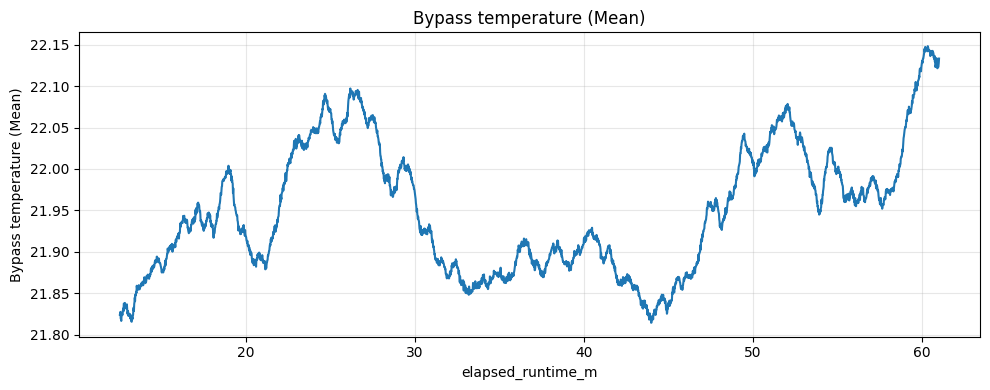

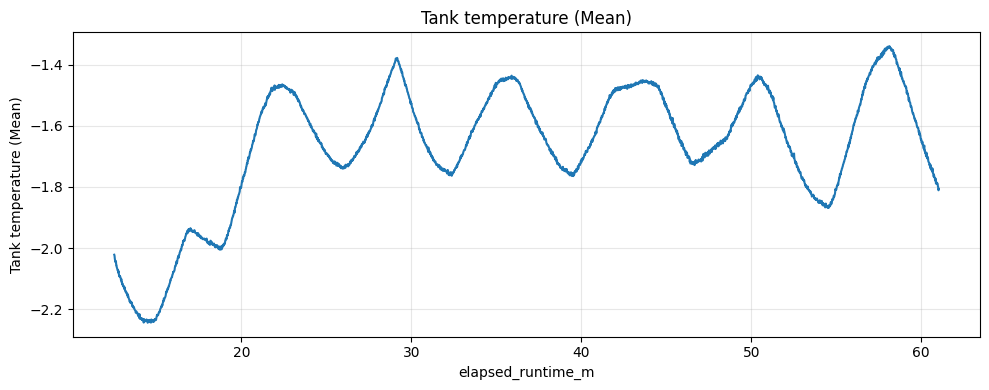

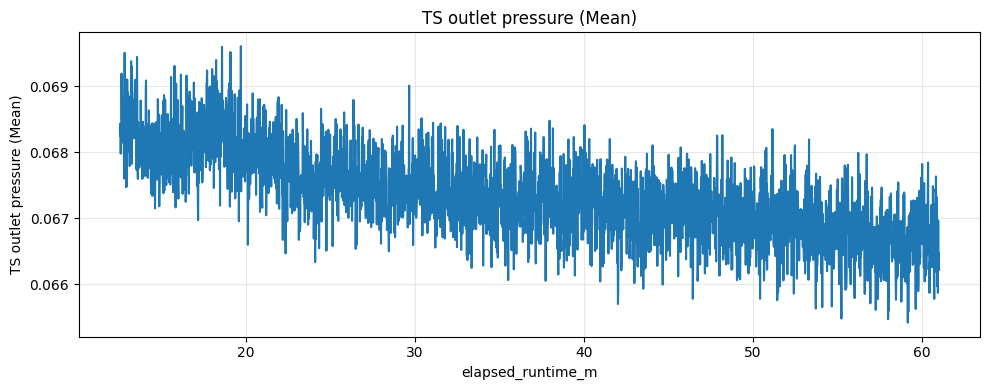

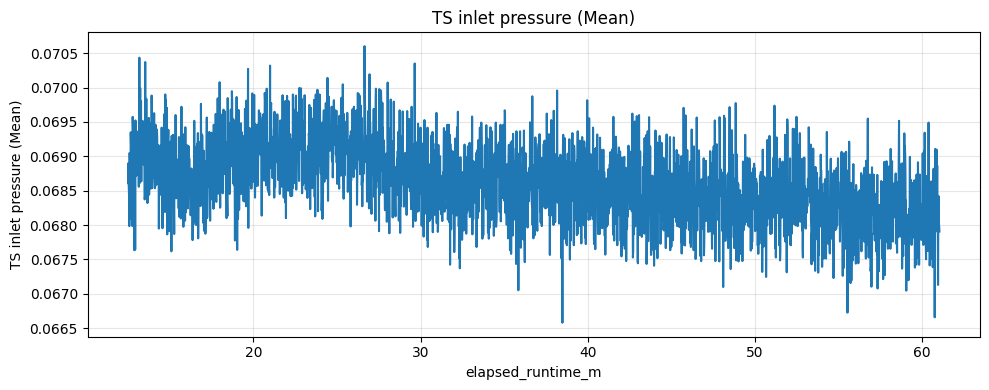

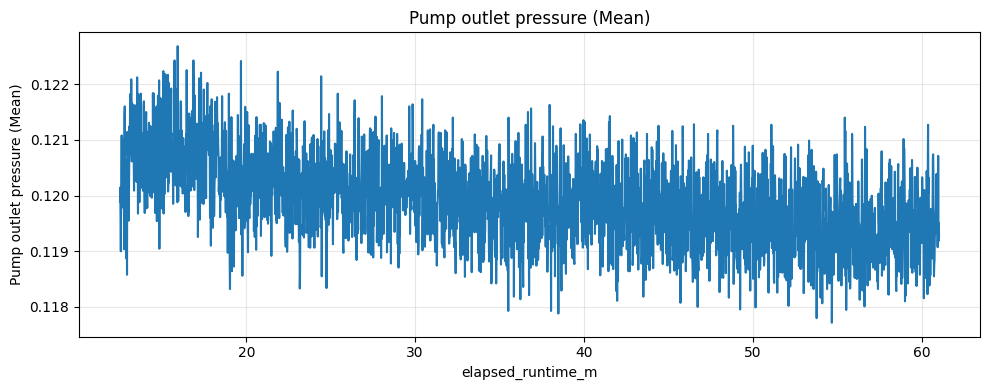

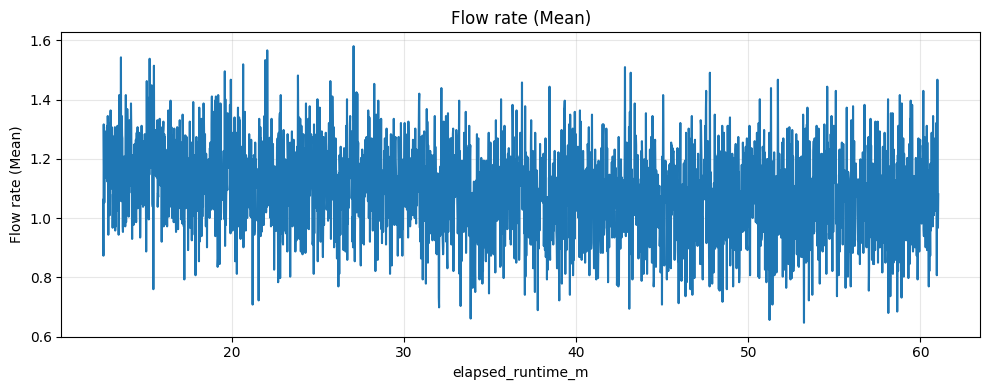

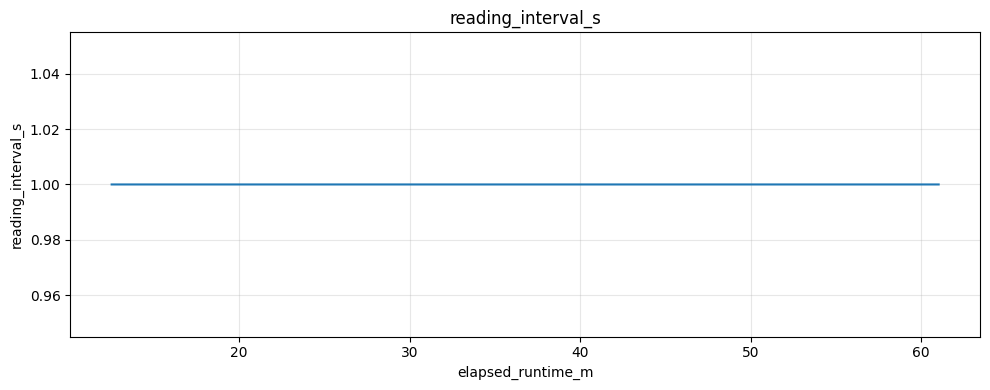

In [551]:
plot_all_timeseries(dffirst)

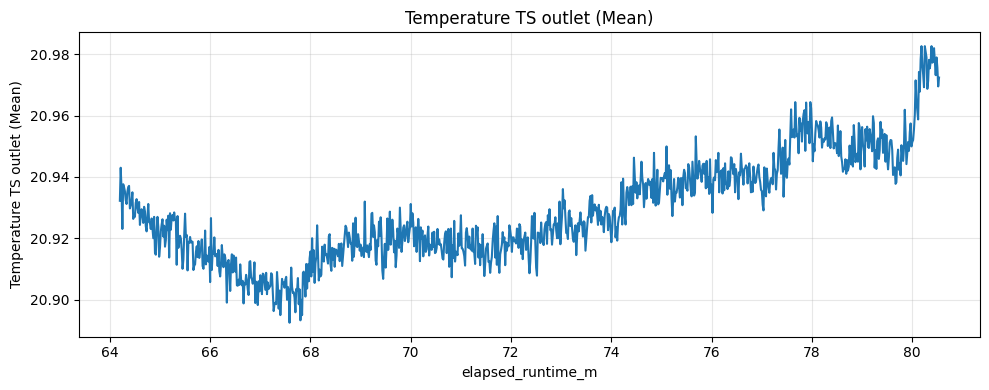

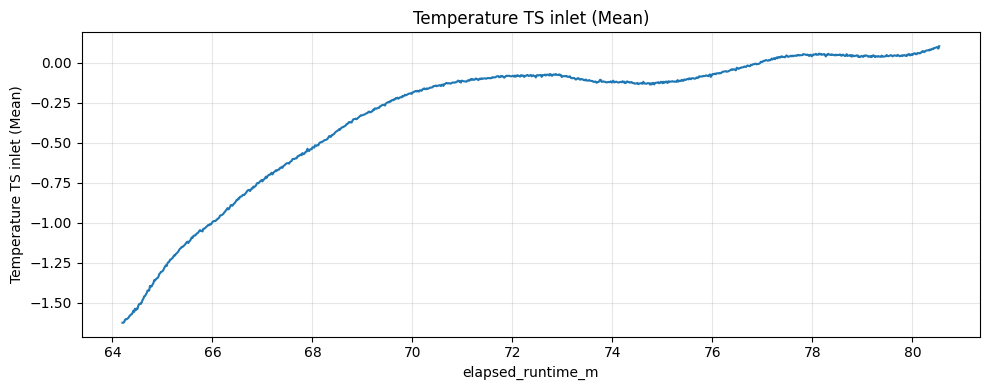

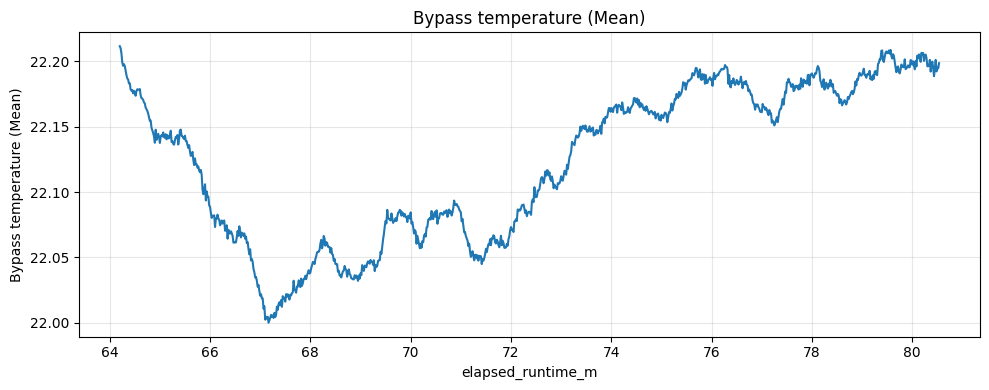

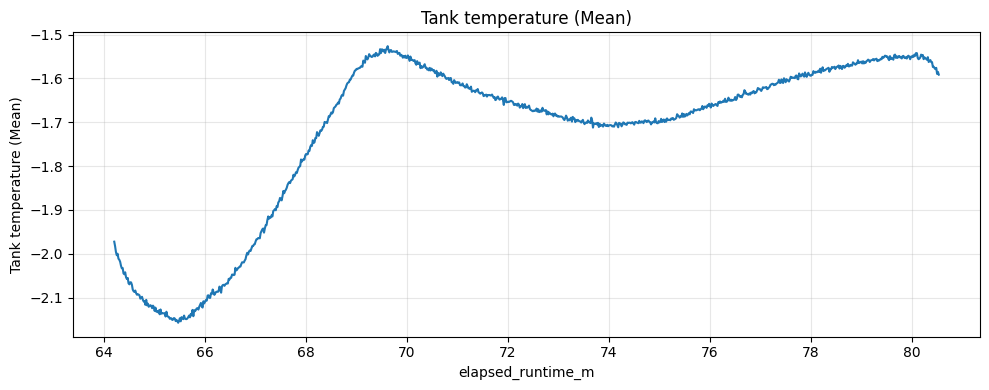

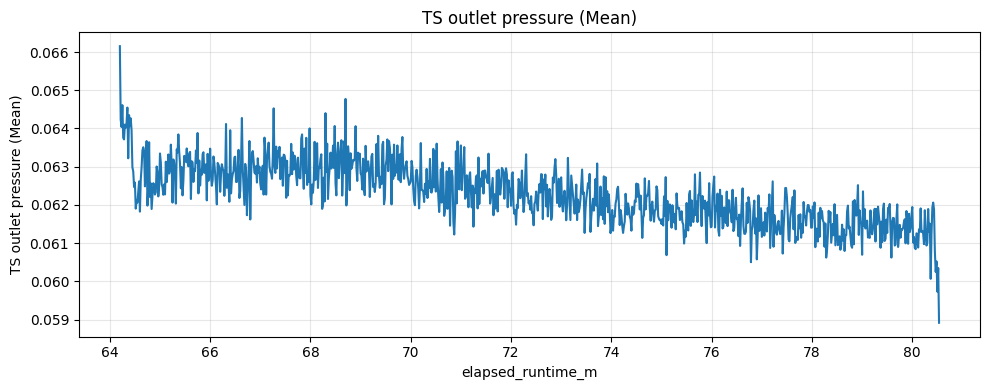

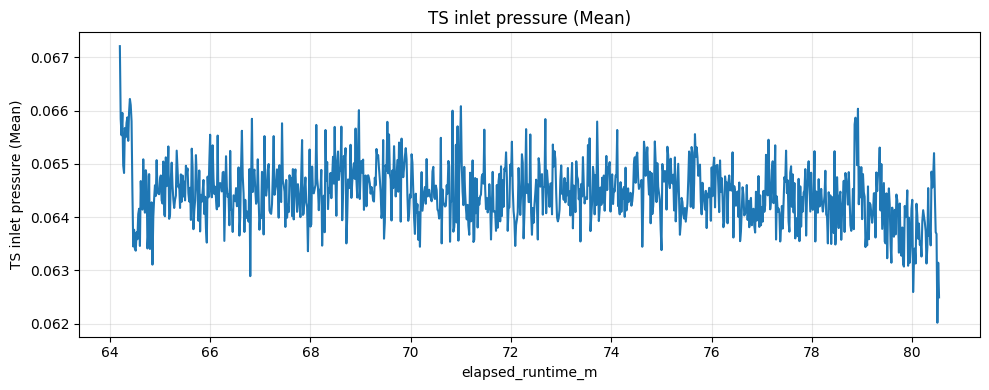

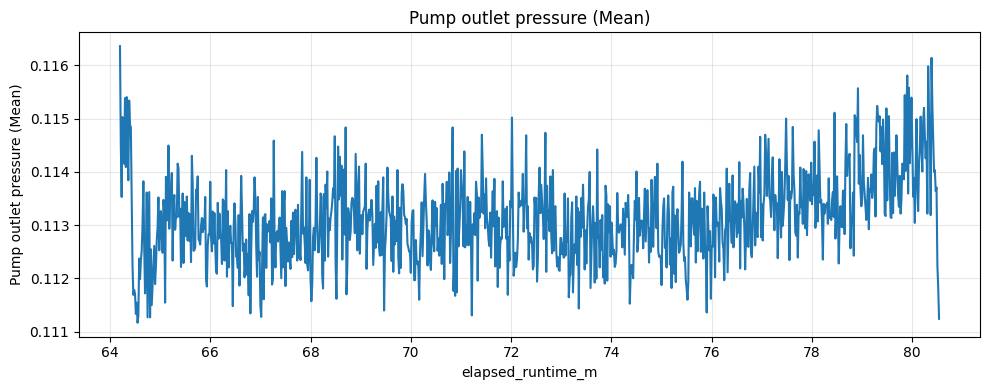

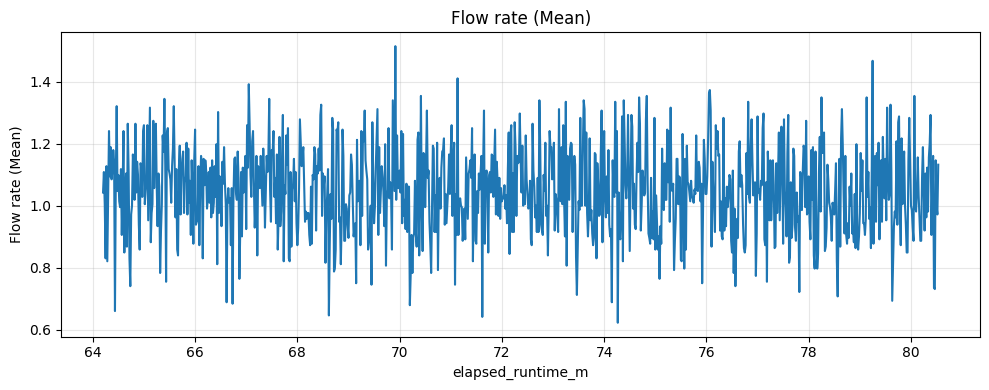

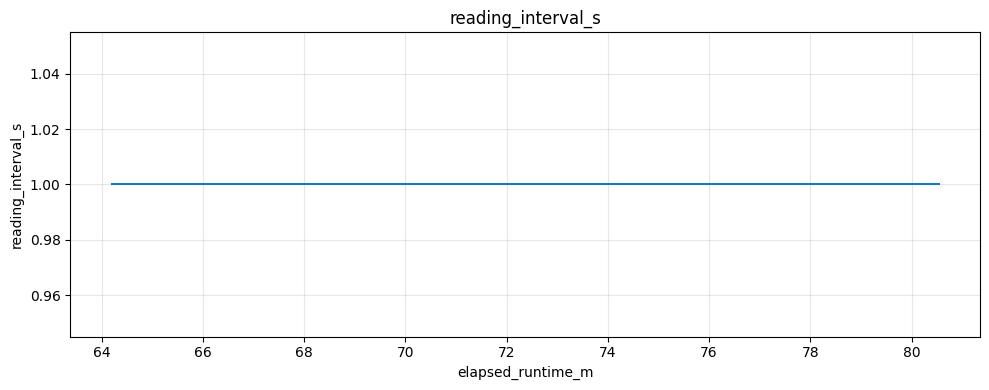

In [552]:
plot_all_timeseries(dfsnd)

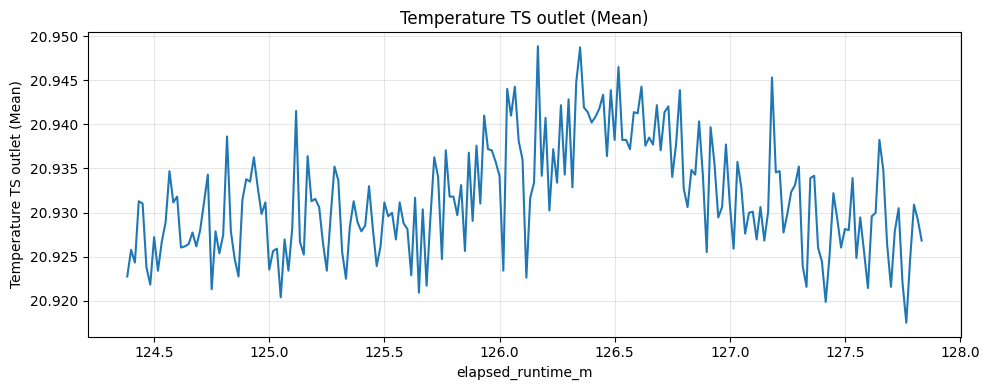

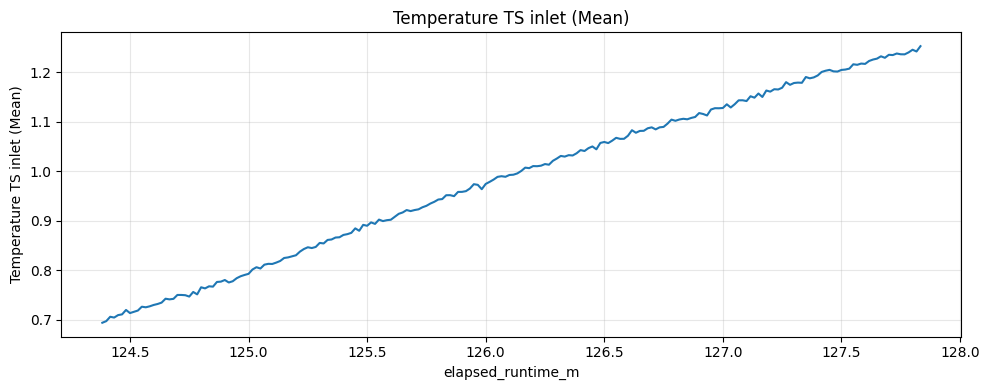

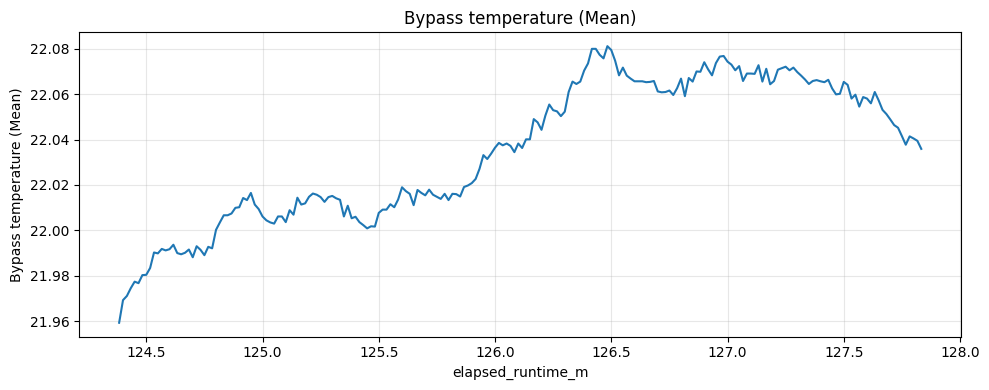

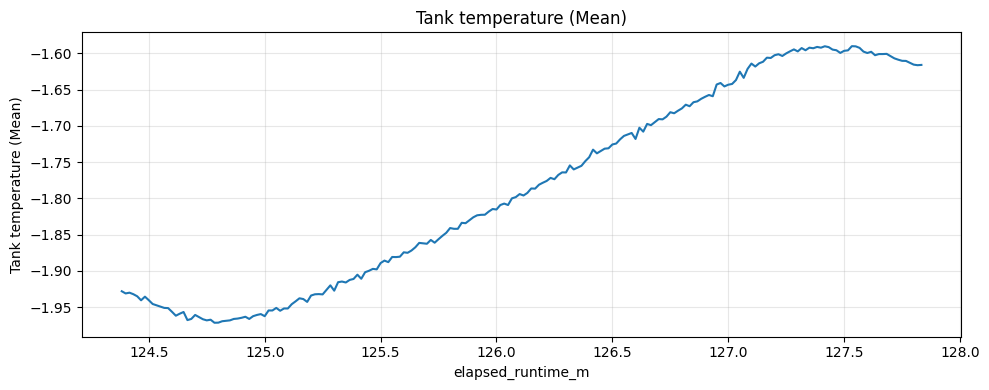

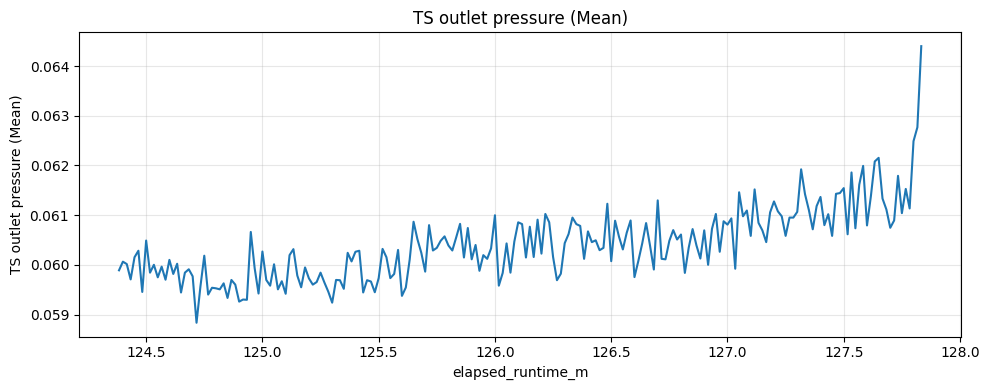

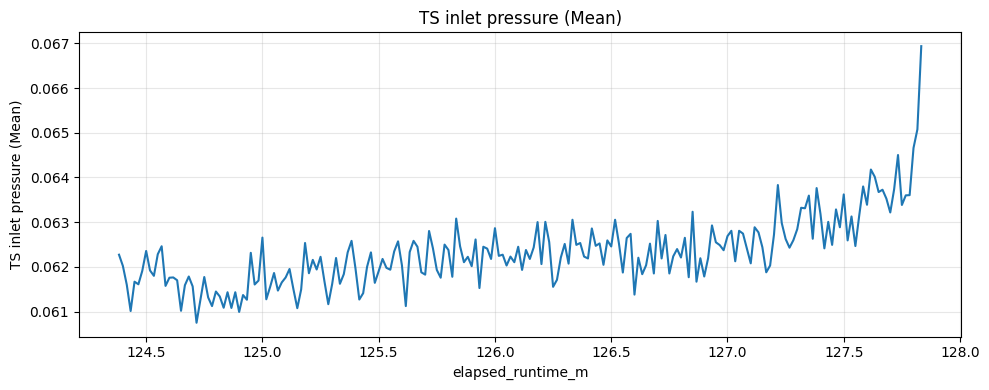

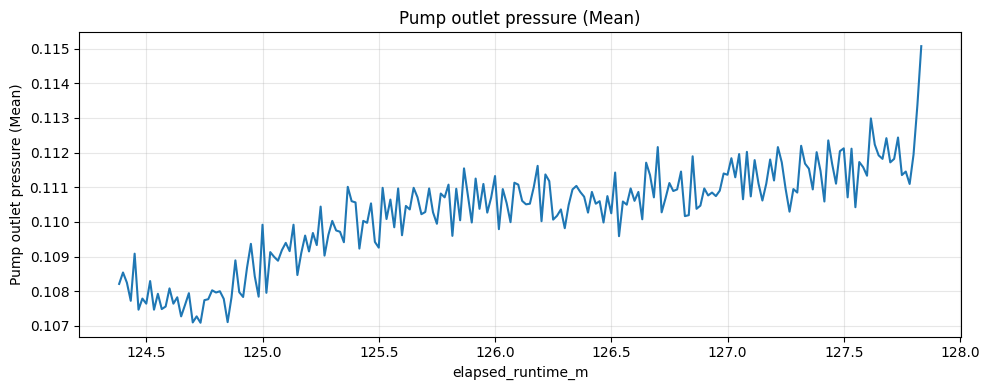

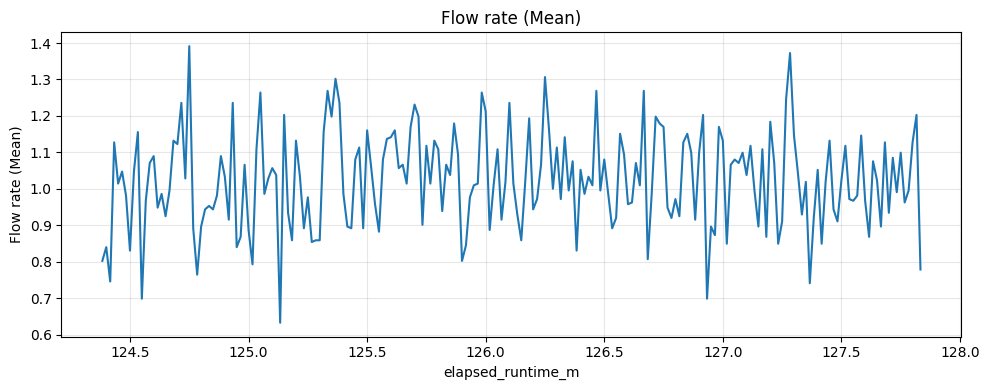

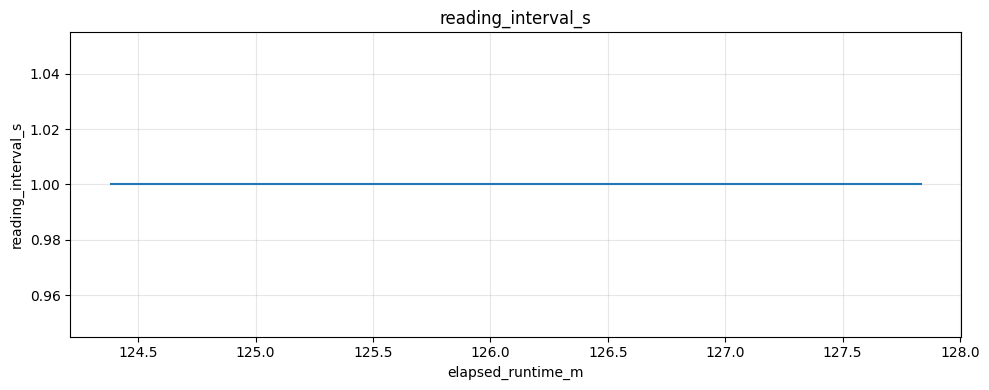

In [553]:
plot_all_timeseries(dfthrd)

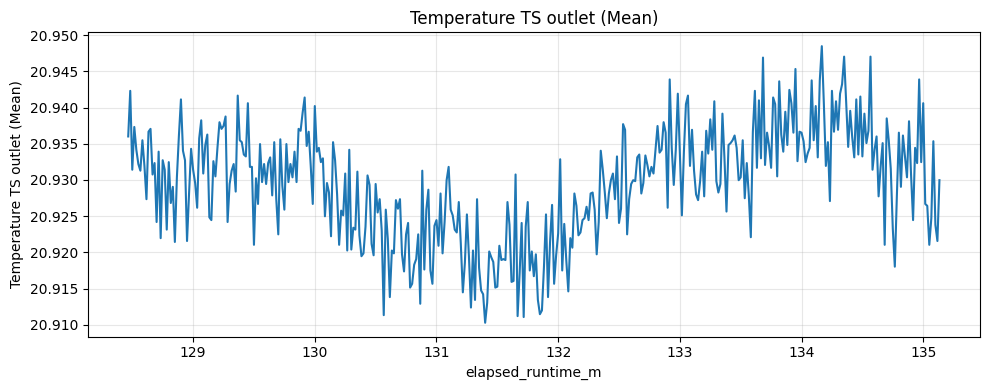

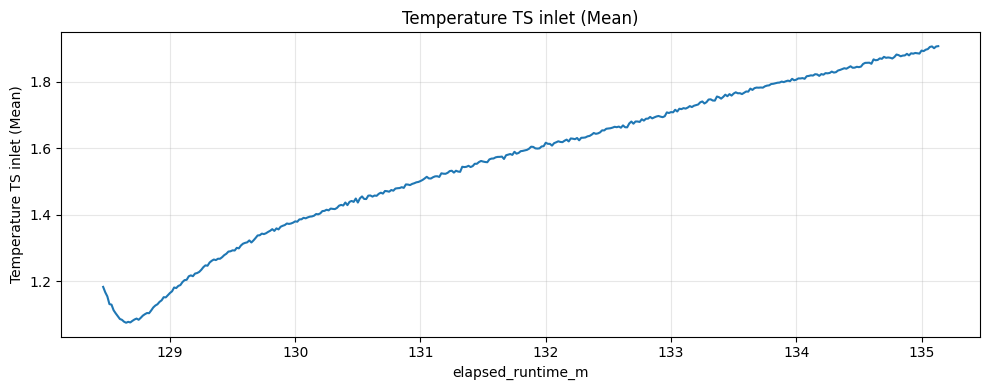

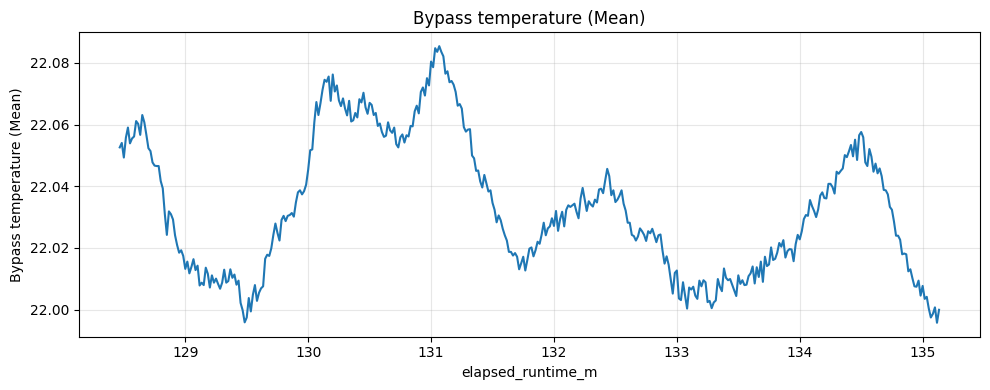

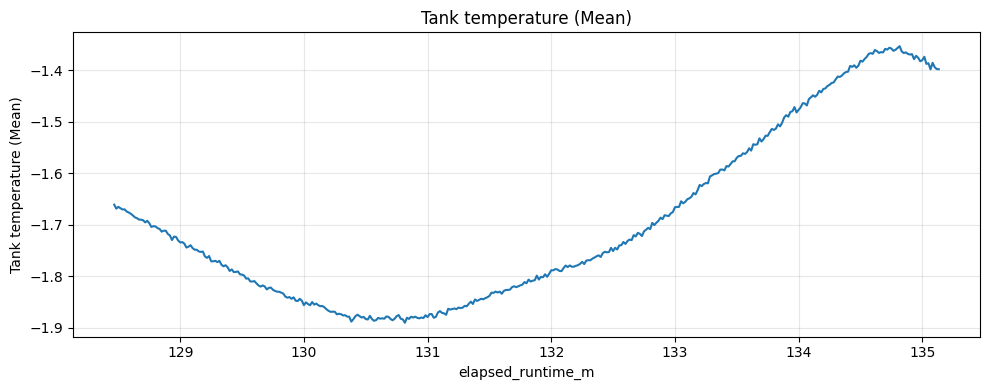

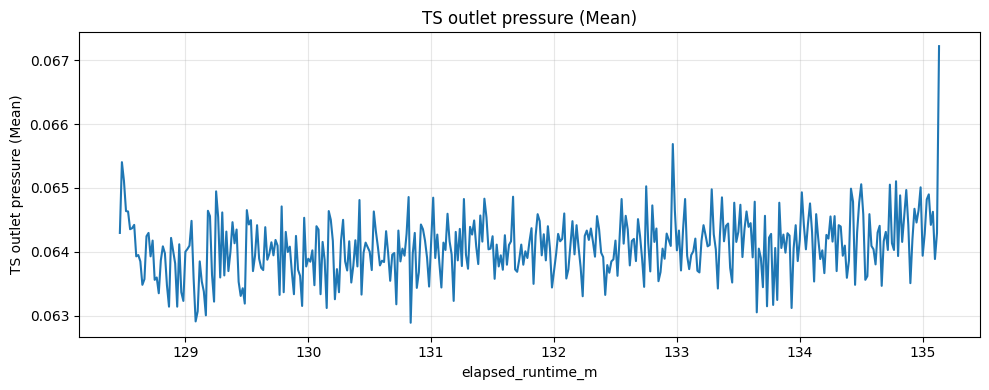

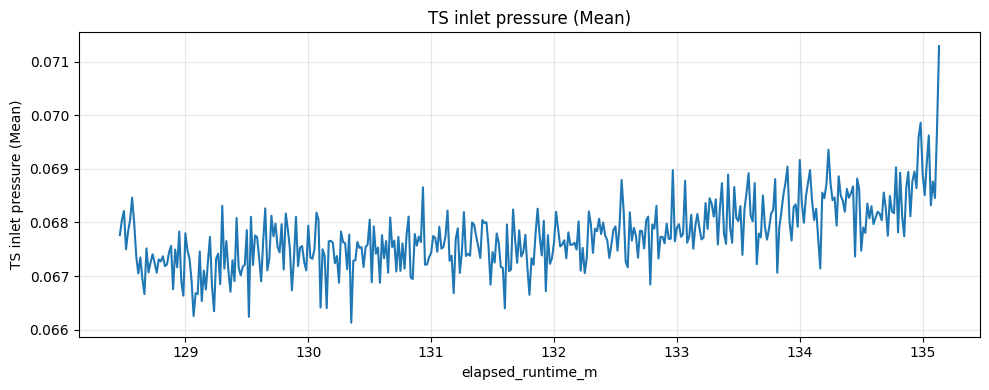

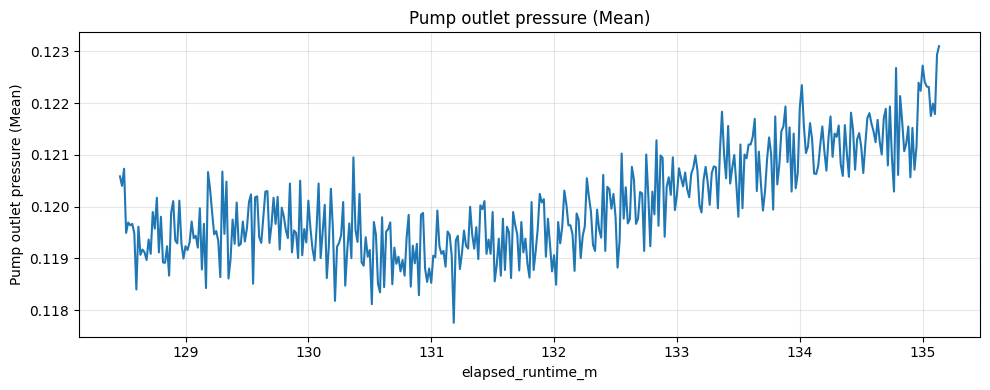

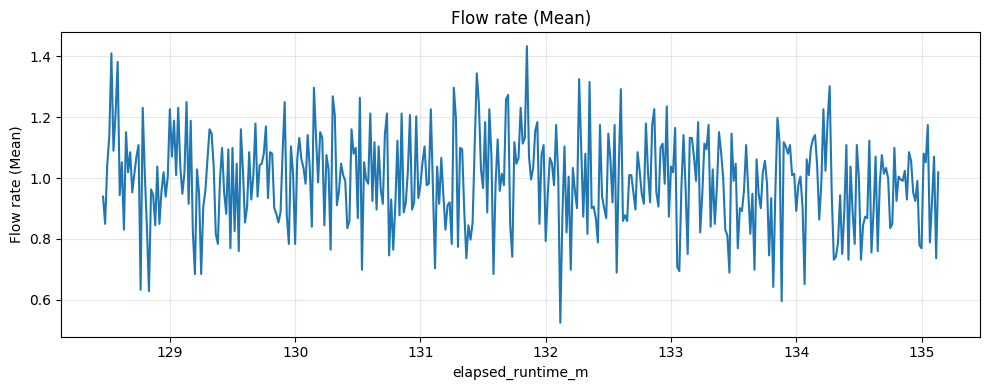

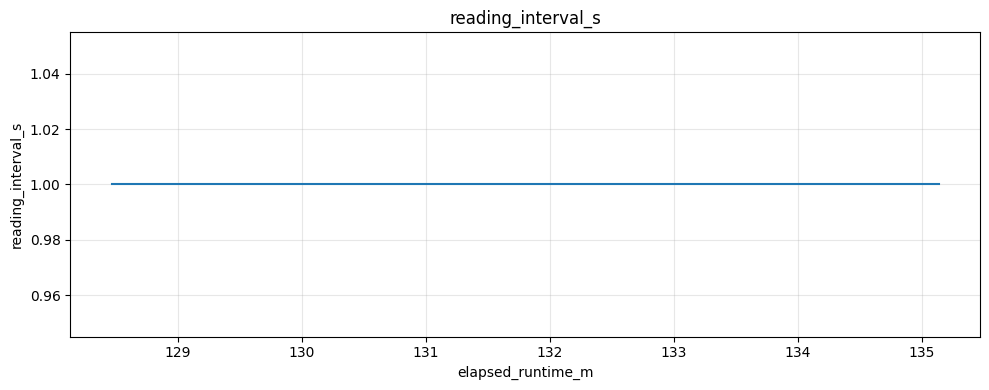

In [554]:
plot_all_timeseries(dffrth)